# From Combine speed to weekly NFL expectations

A receiver's game speed reflects the route and the time available to run it. A useful Combine comparison needs that football context—and, later in the season, a way to learn from the receiver's recorded NFL games.

This framework estimates a route's sustained peak speed and keeps two review views: a static expectation informed by Combine tracking, and an expectation updated using strictly earlier NFL weeks. In the original fits, Combine peaks reduce mean player MSE by **1.33% across four receiver partitions** beyond conventional tests and football context; earlier games reduce it a further **1.71%**. A stronger averaging challenger improves accuracy again, while showing that the small Combine increment depends on the fitting method. All results reuse previously analyzed data.

## Measure the same movement quantity

For each recorded forty-yard dash and WR GO drill, measure the largest half-second mean native speed using six 10 Hz samples and trapezoidal integration. Take the median across supported attempts within each drill. On NFL routes, measure the same half-second quantity between the unique snap and pass release. This reduces reliance on one instantaneous sample while preserving the opportunity to accelerate.

Development includes 55 rookie WRs and 10,626 supported routes from 2023–24; assessment includes 23 different rookie WRs and 3,690 routes in 2025. Eligible records are offensive, non-nullified regular-season dropbacks with a charted route, exact events and continuous valid tracking. Both targeted and untargeted routes count. Unsupported observations remain missing. Fourteen other receivers in the full 2025 WR cohort have no scored routes under these rules.

## A faster route can fall further below expectation

Elic Ayomanor supplies the largest eligible receiver–route group: 91 GO routes. Two examples were selected using that group's lower and upper release-duration quartiles, with outcome-independent identifier tie-breaks.

On the 2.2-second example, his observed peak was **7.49 yd/s**, above the static Combine prediction of **7.18**. On the 3.4-second example, he ran faster—**7.91 yd/s**—but below the corresponding **8.33** prediction. The faster recorded play therefore has the larger shortfall relative to its context.

In [1]:
from pathlib import Path
import os, sys, json, hashlib, tempfile, subprocess, shutil
import pandas as pd
from IPython.display import display, Image

# All embedded assets are code, configuration or aggregate validation results.
# The notebook reads row-level data only from the official competition input.
SOURCE_FILES = {'AVERAGING_REFERENCE.json': '{\n  "result": {\n    "status": "COMPLETE",\n    "completed_utc": "2026-10-30T21:50:04.041386+00:00",\n    "by_seed": {\n      "20261029": {\n        "all": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.8874786162828422,\n              "rmse": 0.9420608347038115,\n              "mae": 0.7435995832566319\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.8901837144440103,\n              "rmse": 0.9434954766420507,\n              "mae": 0.7445551481577821\n            },\n            "averaged_static_baseline": {\n              "mse": 0.9071793480559037,\n              "rmse": 0.9524596306699322,\n              "mae": 0.7530678855401123\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.9060902907044042,\n              "rmse": 0.9518877511053518,\n              "mae": 0.7522791618580005\n            },\n            "original_online_baseline": {\n              "mse": 0.9061466715603558,\n              "rmse": 0.9519173659306546,\n              "mae": 0.7517770785616936\n            },\n            "original_online_monotonic": {\n              "mse": 0.9064325392398581,\n              "rmse": 0.9520675077114322,\n              "mae": 0.749014412636609\n            },\n            "original_static_baseline": {\n              "mse": 0.9283575595626967,\n              "rmse": 0.9635131340893578,\n              "mae": 0.7621717714159613\n            },\n            "original_static_monotonic": {\n              "mse": 0.9248281982395735,\n              "rmse": 0.9616798834537268,\n              "mae": 0.7578997013934774\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.016248824795847844,\n              "relative_mse_gain": 0.01792612697848893,\n              "fixed_prediction_95_interval": [\n                0.005868410836092858,\n                0.026401652559641327\n              ],\n              "improved_players": 40,\n              "worsened_players": 15,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.018737907535169348,\n              "relative_mse_gain": 0.02026096043658409,\n              "fixed_prediction_95_interval": [\n                0.007635445321004319,\n                0.03005838163578199\n              ],\n              "improved_players": 37,\n              "worsened_players": 18,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.018668055277513616,\n              "relative_mse_gain": 0.020601582352410806,\n              "fixed_prediction_95_interval": [\n                -0.004471093167155509,\n                0.03768467135087535\n              ],\n              "improved_players": 42,\n              "worsened_players": 13,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.021178211506793006,\n              "relative_mse_gain": 0.02281255889893223,\n              "fixed_prediction_95_interval": [\n                -0.002439339120704027,\n                0.04096505356060095\n              ],\n              "improved_players": 43,\n              "worsened_players": 12,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": -0.002705098161168227,\n              "relative_mse_gain": -0.0030480713693118483,\n              "fixed_prediction_95_interval": [\n                -0.013324732302477132,\n                0.007225025376062476\n              ],\n              "improved_players": 29,\n              "worsened_players": 26,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.0010890573514996439,\n              "relative_mse_gain": 0.0012004873720213175,\n              "fixed_prediction_95_interval": [\n                -0.011400279196297172,\n                0.013120232447655767\n              ],\n              "improved_players": 31,\n              "worsened_players": 24,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": -0.0002858676795024535,\n              "relative_mse_gain": -0.00031547616790358944,\n              "fixed_prediction_95_interval": [\n                -0.020866259769337474,\n                0.014319353967712665\n              ],\n              "improved_players": 32,\n              "worsened_players": 23,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.0035293613231232985,\n              "relative_mse_gain": 0.0038017262710563866,\n              "fixed_prediction_95_interval": [\n                -0.018254594486860207,\n                0.020055961878207063\n              ],\n              "improved_players": 34,\n              "worsened_players": 21,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "20261029": {\n              "players": 55,\n              "routes": 10626\n            }\n          }\n        },\n        "history_0": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.9028793137183443,\n              "rmse": 0.9501996178268777,\n              "mae": 0.7581424158650021\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.9016982005195268,\n              "rmse": 0.9495779065034774,\n              "mae": 0.7569385668579899\n            },\n            "averaged_static_baseline": {\n              "mse": 0.9028793137183443,\n              "rmse": 0.9501996178268777,\n              "mae": 0.7581424158650021\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.9016982005195268,\n              "rmse": 0.9495779065034774,\n              "mae": 0.7569385668579899\n            },\n            "original_online_baseline": {\n              "mse": 0.9230325806842511,\n              "rmse": 0.9607458460405911,\n              "mae": 0.7658412713474824\n            },\n            "original_online_monotonic": {\n              "mse": 0.915046160903844,\n              "rmse": 0.9565804518721068,\n              "mae": 0.7581769642644747\n            },\n            "original_static_baseline": {\n              "mse": 0.9230325806842511,\n              "rmse": 0.9607458460405911,\n              "mae": 0.7658412713474824\n            },\n            "original_static_monotonic": {\n              "mse": 0.915046160903844,\n              "rmse": 0.9565804518721068,\n              "mae": 0.7581769642644747\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.013347960384317415,\n              "relative_mse_gain": 0.01458719893555191,\n              "fixed_prediction_95_interval": [\n                -0.004766039551490748,\n                0.03305680620616137\n              ],\n              "improved_players": 30,\n              "worsened_players": 25,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.013347960384317415,\n              "relative_mse_gain": 0.01458719893555191,\n              "fixed_prediction_95_interval": [\n                -0.004766039551490748,\n                0.03305680620616137\n              ],\n              "improved_players": 30,\n              "worsened_players": 25,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.020153266965906785,\n              "relative_mse_gain": 0.02183375472073479,\n              "fixed_prediction_95_interval": [\n                -0.007407557244657761,\n                0.04608187377632507\n              ],\n              "improved_players": 32,\n              "worsened_players": 23,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.020153266965906785,\n              "relative_mse_gain": 0.02183375472073479,\n              "fixed_prediction_95_interval": [\n                -0.007407557244657761,\n                0.04608187377632507\n              ],\n              "improved_players": 32,\n              "worsened_players": 23,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.0011811131988176183,\n              "relative_mse_gain": 0.0013081628750064261,\n              "fixed_prediction_95_interval": [\n                -0.013575239193046082,\n                0.01643338229059381\n              ],\n              "improved_players": 29,\n              "worsened_players": 26,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.0011811131988176183,\n              "relative_mse_gain": 0.0013081628750064261,\n              "fixed_prediction_95_interval": [\n                -0.013575239193046082,\n                0.01643338229059381\n              ],\n              "improved_players": 29,\n              "worsened_players": 26,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.00798641978040699,\n              "relative_mse_gain": 0.008652370401147268,\n              "fixed_prediction_95_interval": [\n                -0.016381255781922552,\n                0.02908219139053787\n              ],\n              "improved_players": 31,\n              "worsened_players": 24,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.00798641978040699,\n              "relative_mse_gain": 0.008652370401147268,\n              "fixed_prediction_95_interval": [\n                -0.016381255781922552,\n                0.02908219139053787\n              ],\n              "improved_players": 31,\n              "worsened_players": 24,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "20261029": {\n              "players": 55,\n              "routes": 1346\n            }\n          }\n        },\n        "history_1_3": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.8188611488120077,\n              "rmse": 0.9049094699537671,\n              "mae": 0.7154276801886738\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.8118849225417774,\n              "rmse": 0.9010465706842112,\n              "mae": 0.7137676092955046\n            },\n            "averaged_static_baseline": {\n              "mse": 0.8421469777477189,\n              "rmse": 0.9176856639109706,\n              "mae": 0.7281740462395113\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.8322771358218095,\n              "rmse": 0.9122922425526864,\n              "mae": 0.7245603349065437\n            },\n            "original_online_baseline": {\n              "mse": 0.834829067374956,\n              "rmse": 0.9136898091666318,\n              "mae": 0.7226496194234363\n            },\n            "original_online_monotonic": {\n              "mse": 0.8186083580183716,\n              "rmse": 0.9047697817778684,\n              "mae": 0.716546640004089\n            },\n            "original_static_baseline": {\n              "mse": 0.8620066578447071,\n              "rmse": 0.9284431365704133,\n              "mae": 0.7364349476871235\n            },\n            "original_static_monotonic": {\n              "mse": 0.8439285853896537,\n              "rmse": 0.9186558579738409,\n              "mae": 0.729297572564752\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.006723435476594295,\n              "relative_mse_gain": 0.008213250464324485,\n              "fixed_prediction_95_interval": [\n                -0.0035172626644211615,\n                0.01692786791964133\n              ],\n              "improved_players": 28,\n              "worsened_players": 15,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.011651449567844136,\n              "relative_mse_gain": 0.013806203237522163,\n              "fixed_prediction_95_interval": [\n                -0.0009915584672632145,\n                0.02508221961990911\n              ],\n              "improved_players": 29,\n              "worsened_players": 14,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.015967918562948394,\n              "relative_mse_gain": 0.01912717128209019,\n              "fixed_prediction_95_interval": [\n                0.006011622287295971,\n                0.025676595008644307\n              ],\n              "improved_players": 27,\n              "worsened_players": 16,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.019859680096988203,\n              "relative_mse_gain": 0.02303889409235396,\n              "fixed_prediction_95_interval": [\n                0.007972068890843948,\n                0.03185808750134881\n              ],\n              "improved_players": 28,\n              "worsened_players": 15,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.00697622627023032,\n              "relative_mse_gain": 0.008519425155719419,\n              "fixed_prediction_95_interval": [\n                0.000825851195061385,\n                0.01396204362492899\n              ],\n              "improved_players": 25,\n              "worsened_players": 18,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.009869841925909414,\n              "relative_mse_gain": 0.011719856731310522,\n              "fixed_prediction_95_interval": [\n                -0.000595934153790382,\n                0.021594978063919995\n              ],\n              "improved_players": 24,\n              "worsened_players": 19,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.016220709356584418,\n              "relative_mse_gain": 0.019429976734745186,\n              "fixed_prediction_95_interval": [\n                0.0062434145470177315,\n                0.02714900137102804\n              ],\n              "improved_players": 25,\n              "worsened_players": 18,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.01807807245505348,\n              "relative_mse_gain": 0.020972079844782703,\n              "fixed_prediction_95_interval": [\n                0.003988501706604047,\n                0.032762597165208886\n              ],\n              "improved_players": 29,\n              "worsened_players": 14,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "20261029": {\n              "players": 43,\n              "routes": 2690\n            }\n          }\n        },\n        "history_4_plus": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.8085717116575096,\n              "rmse": 0.8992061563721134,\n              "mae": 0.7039938375356488\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.8066287016379684,\n              "rmse": 0.8981251035562743,\n              "mae": 0.7030973760413337\n            },\n            "averaged_static_baseline": {\n              "mse": 0.8313077057206701,\n              "rmse": 0.9117607721988648,\n              "mae": 0.715050767143677\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.823204172569491,\n              "rmse": 0.9073059972079381,\n              "mae": 0.7117646119518629\n            },\n            "original_online_baseline": {\n              "mse": 0.8279275266174664,\n              "rmse": 0.9099052294703368,\n              "mae": 0.7095980491406447\n            },\n            "original_online_monotonic": {\n              "mse": 0.8214262482778762,\n              "rmse": 0.9063256855445929,\n              "mae": 0.706769829386044\n            },\n            "original_static_baseline": {\n              "mse": 0.8551850147144864,\n              "rmse": 0.9247621395334512,\n              "mae": 0.7233226674682245\n            },\n            "original_static_monotonic": {\n              "mse": 0.8414682635633062,\n              "rmse": 0.9173157927144316,\n              "mae": 0.7175831885011489\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.014797546639907804,\n              "relative_mse_gain": 0.018014455553290298,\n              "fixed_prediction_95_interval": [\n                0.004610792671817976,\n                0.02874771618207177\n              ],\n              "improved_players": 23,\n              "worsened_players": 11,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.018264090993815242,\n              "relative_mse_gain": 0.02170502654072013,\n              "fixed_prediction_95_interval": [\n                0.00800000220320831,\n                0.03144657083586436\n              ],\n              "improved_players": 27,\n              "worsened_players": 7,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.01935581495995675,\n              "relative_mse_gain": 0.023378634406607743,\n              "fixed_prediction_95_interval": [\n                0.008345420150678533,\n                0.03195307193668758\n              ],\n              "improved_players": 25,\n              "worsened_players": 9,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.023877308993816185,\n              "relative_mse_gain": 0.02792063539816341,\n              "fixed_prediction_95_interval": [\n                0.010871722108810444,\n                0.039000292617894304\n              ],\n              "improved_players": 25,\n              "worsened_players": 9,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.0019430100195412395,\n              "relative_mse_gain": 0.0024030150839165756,\n              "fixed_prediction_95_interval": [\n                -0.002644290678085832,\n                0.006971691252853926\n              ],\n              "improved_players": 17,\n              "worsened_players": 17,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.008103533151179163,\n              "relative_mse_gain": 0.00974793460401539,\n              "fixed_prediction_95_interval": [\n                -0.0015757813348845464,\n                0.0182456897771067\n              ],\n              "improved_players": 20,\n              "worsened_players": 14,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.006501278339590183,\n              "relative_mse_gain": 0.007852472747405121,\n              "fixed_prediction_95_interval": [\n                -0.001489483636942213,\n                0.014792313299379488\n              ],\n              "improved_players": 24,\n              "worsened_players": 10,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.013716751151180102,\n              "relative_mse_gain": 0.01603951298861288,\n              "fixed_prediction_95_interval": [\n                0.0017058132649021309,\n                0.02685820009363548\n              ],\n              "improved_players": 20,\n              "worsened_players": 14,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "20261029": {\n              "players": 34,\n              "routes": 6590\n            }\n          }\n        }\n      },\n      "17": {\n        "all": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.8933710471171733,\n              "rmse": 0.9451830759790261,\n              "mae": 0.7415965421974426\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.893276295825309,\n              "rmse": 0.9451329514017109,\n              "mae": 0.7424857544259325\n            },\n            "averaged_static_baseline": {\n              "mse": 0.9096029541345582,\n              "rmse": 0.9537310701317002,\n              "mae": 0.7503823035797057\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.9076483872323768,\n              "rmse": 0.9527058240781238,\n              "mae": 0.7491191135417697\n            },\n            "original_online_baseline": {\n              "mse": 0.9219426507004568,\n              "rmse": 0.9601784473213595,\n              "mae": 0.7568130771878873\n            },\n            "original_online_monotonic": {\n              "mse": 0.8993268032728797,\n              "rmse": 0.9483284258488088,\n              "mae": 0.744787387907469\n            },\n            "original_static_baseline": {\n              "mse": 0.9387858293009644,\n              "rmse": 0.9689096084263817,\n              "mae": 0.7663766176117764\n            },\n            "original_static_monotonic": {\n              "mse": 0.9133940702853204,\n              "rmse": 0.9557165219275643,\n              "mae": 0.7519642645513543\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.006050507447570927,\n              "relative_mse_gain": 0.006727818436581214,\n              "fixed_prediction_95_interval": [\n                -0.01616877578127075,\n                0.020958394526191894\n              ],\n              "improved_players": 42,\n              "worsened_players": 13,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.005745683052943628,\n              "relative_mse_gain": 0.006290475534999726,\n              "fixed_prediction_95_interval": [\n                -0.01645683783215052,\n                0.02106491338396371\n              ],\n              "improved_players": 41,\n              "worsened_players": 14,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.02857160358328343,\n              "relative_mse_gain": 0.030990651708732445,\n              "fixed_prediction_95_interval": [\n                0.02001922728685027,\n                0.038062994771650455\n              ],\n              "improved_players": 49,\n              "worsened_players": 6,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.02918287516640618,\n              "relative_mse_gain": 0.03108576445826439,\n              "fixed_prediction_95_interval": [\n                0.02014210297736771,\n                0.038829948360459665\n              ],\n              "improved_players": 44,\n              "worsened_players": 11,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 9.475129186440081e-05,\n              "relative_mse_gain": 0.00010606040140897175,\n              "fixed_prediction_95_interval": [\n                -0.007344051765947455,\n                0.007405638094783512\n              ],\n              "improved_players": 27,\n              "worsened_players": 28,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.0019545669021813566,\n              "relative_mse_gain": 0.0021488132742939797,\n              "fixed_prediction_95_interval": [\n                -0.007747140336587976,\n                0.01173248180707697\n              ],\n              "improved_players": 31,\n              "worsened_players": 24,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.022615847427576906,\n              "relative_mse_gain": 0.024530644515029485,\n              "fixed_prediction_95_interval": [\n                0.006276226924908002,\n                0.04610151866145224\n              ],\n              "improved_players": 36,\n              "worsened_players": 19,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.025391759015643913,\n              "relative_mse_gain": 0.027047445991543184,\n              "fixed_prediction_95_interval": [\n                0.006612446252517395,\n                0.04981443353132439\n              ],\n              "improved_players": 32,\n              "worsened_players": 23,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "17": {\n              "players": 55,\n              "routes": 10626\n            }\n          }\n        },\n        "history_0": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.9054625771127818,\n              "rmse": 0.9515579735952937,\n              "mae": 0.7562884967582707\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.907876034142736,\n              "rmse": 0.9528252904613395,\n              "mae": 0.7567974028840587\n            },\n            "averaged_static_baseline": {\n              "mse": 0.9054625771127818,\n              "rmse": 0.9515579735952937,\n              "mae": 0.7562884967582707\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.907876034142736,\n              "rmse": 0.9528252904613395,\n              "mae": 0.7567974028840587\n            },\n            "original_online_baseline": {\n              "mse": 0.9259184353783979,\n              "rmse": 0.9622465564388359,\n              "mae": 0.7692955637365937\n            },\n            "original_online_monotonic": {\n              "mse": 0.9057365532515077,\n              "rmse": 0.9517019245811724,\n              "mae": 0.754307596128698\n            },\n            "original_static_baseline": {\n              "mse": 0.9259184353783979,\n              "rmse": 0.9622465564388359,\n              "mae": 0.7692955637365937\n            },\n            "original_static_monotonic": {\n              "mse": 0.9057365532515077,\n              "rmse": 0.9517019245811724,\n              "mae": 0.754307596128698\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": -0.0021394808912283997,\n              "relative_mse_gain": -0.002362144801982285,\n              "fixed_prediction_95_interval": [\n                -0.025649913208887706,\n                0.016677689048987192\n              ],\n              "improved_players": 33,\n              "worsened_players": 22,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": -0.0021394808912283997,\n              "relative_mse_gain": -0.002362144801982285,\n              "fixed_prediction_95_interval": [\n                -0.025649913208887706,\n                0.016677689048987192\n              ],\n              "improved_players": 33,\n              "worsened_players": 22,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.020455858265616172,\n              "relative_mse_gain": 0.02209250565062614,\n              "fixed_prediction_95_interval": [\n                0.005897395432088116,\n                0.03558325903067567\n              ],\n              "improved_players": 32,\n              "worsened_players": 23,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.020455858265616172,\n              "relative_mse_gain": 0.02209250565062614,\n              "fixed_prediction_95_interval": [\n                0.005897395432088116,\n                0.03558325903067567\n              ],\n              "improved_players": 32,\n              "worsened_players": 23,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": -0.0024134570299542977,\n              "relative_mse_gain": -0.0026654409480400694,\n              "fixed_prediction_95_interval": [\n                -0.015521136331851522,\n                0.010775638925993597\n              ],\n              "improved_players": 26,\n              "worsened_players": 29,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": -0.0024134570299542977,\n              "relative_mse_gain": -0.0026654409480400694,\n              "fixed_prediction_95_interval": [\n                -0.015521136331851522,\n                0.010775638925993597\n              ],\n              "improved_players": 26,\n              "worsened_players": 29,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.02018188212689027,\n              "relative_mse_gain": 0.021796609027060227,\n              "fixed_prediction_95_interval": [\n                -0.0016142500210469223,\n                0.046290549302153\n              ],\n              "improved_players": 30,\n              "worsened_players": 25,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.02018188212689027,\n              "relative_mse_gain": 0.021796609027060227,\n              "fixed_prediction_95_interval": [\n                -0.0016142500210469223,\n                0.046290549302153\n              ],\n              "improved_players": 30,\n              "worsened_players": 25,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "17": {\n              "players": 55,\n              "routes": 1346\n            }\n          }\n        },\n        "history_1_3": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.8218872878330747,\n              "rmse": 0.906579995275141,\n              "mae": 0.7162532130407419\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.8186833502365402,\n              "rmse": 0.9048112235359043,\n              "mae": 0.7179796794265492\n            },\n            "averaged_static_baseline": {\n              "mse": 0.8365014814842303,\n              "rmse": 0.9146045492365705,\n              "mae": 0.7276589168824512\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.8301344510275743,\n              "rmse": 0.9111171445141257,\n              "mae": 0.7256952018624812\n            },\n            "original_online_baseline": {\n              "mse": 0.8442850577113109,\n              "rmse": 0.9188498559129837,\n              "mae": 0.7251961911289133\n            },\n            "original_online_monotonic": {\n              "mse": 0.8319124617871514,\n              "rmse": 0.9120923537598324,\n              "mae": 0.7247832947016721\n            },\n            "original_static_baseline": {\n              "mse": 0.8620170997526253,\n              "rmse": 0.9284487598961104,\n              "mae": 0.7380158603421412\n            },\n            "original_static_monotonic": {\n              "mse": 0.8445101863436667,\n              "rmse": 0.9189723534163945,\n              "mae": 0.7340826857782893\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.013229111550611319,\n              "relative_mse_gain": 0.015902047581054325,\n              "fixed_prediction_95_interval": [\n                0.0027854994696991896,\n                0.023332545987698964\n              ],\n              "improved_players": 30,\n              "worsened_players": 13,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.014375735316092486,\n              "relative_mse_gain": 0.017022571839343564,\n              "fixed_prediction_95_interval": [\n                0.003665653379643246,\n                0.024531215252822702\n              ],\n              "improved_players": 32,\n              "worsened_players": 11,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.022397769878236187,\n              "relative_mse_gain": 0.02652868207682378,\n              "fixed_prediction_95_interval": [\n                0.013288728592433156,\n                0.031796470167637474\n              ],\n              "improved_players": 33,\n              "worsened_players": 10,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.025515618268394987,\n              "relative_mse_gain": 0.029599898048098178,\n              "fixed_prediction_95_interval": [\n                0.016110823509450267,\n                0.03479943401838676\n              ],\n              "improved_players": 33,\n              "worsened_players": 10,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.003203937596534649,\n              "relative_mse_gain": 0.0038982688307321388,\n              "fixed_prediction_95_interval": [\n                -0.0046601015770828995,\n                0.0109615439795287\n              ],\n              "improved_players": 25,\n              "worsened_players": 18,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.006367030456656116,\n              "relative_mse_gain": 0.007611499318995703,\n              "fixed_prediction_95_interval": [\n                -0.004774777858250106,\n                0.018245043779429992\n              ],\n              "improved_players": 24,\n              "worsened_players": 19,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.012372595924159518,\n              "relative_mse_gain": 0.014654524335298753,\n              "fixed_prediction_95_interval": [\n                0.002554609844042447,\n                0.02304163666549088\n              ],\n              "improved_players": 26,\n              "worsened_players": 17,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.01750691340895862,\n              "relative_mse_gain": 0.020309241445422153,\n              "fixed_prediction_95_interval": [\n                0.0018401631090502566,\n                0.035280879691956035\n              ],\n              "improved_players": 26,\n              "worsened_players": 17,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "17": {\n              "players": 43,\n              "routes": 2690\n            }\n          }\n        },\n        "history_4_plus": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.7941129112058137,\n              "rmse": 0.891130131465553,\n              "mae": 0.6929721654869558\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.7957325991258696,\n              "rmse": 0.892038451596045,\n              "mae": 0.6958555616927093\n            },\n            "averaged_static_baseline": {\n              "mse": 0.8162078914390035,\n              "rmse": 0.9034422457683743,\n              "mae": 0.7048507918634936\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.8165321543874761,\n              "rmse": 0.9036216876478099,\n              "mae": 0.7050612757365654\n            },\n            "original_online_baseline": {\n              "mse": 0.8141126194091345,\n              "rmse": 0.9022818957560517,\n              "mae": 0.7027524107014913\n            },\n            "original_online_monotonic": {\n              "mse": 0.8082985978773367,\n              "rmse": 0.899054279716935,\n              "mae": 0.7014145235409446\n            },\n            "original_static_baseline": {\n              "mse": 0.8359247074584597,\n              "rmse": 0.9142891815276278,\n              "mae": 0.7160323215293114\n            },\n            "original_static_monotonic": {\n              "mse": 0.8280361324426859,\n              "rmse": 0.9099649072588931,\n              "mae": 0.7112441465624546\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.012565998751467015,\n              "relative_mse_gain": 0.01554623351378616,\n              "fixed_prediction_95_interval": [\n                0.006616828596322009,\n                0.018794469320143538\n              ],\n              "improved_players": 27,\n              "worsened_players": 7,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.01150397805520988,\n              "relative_mse_gain": 0.013893087033863404,\n              "fixed_prediction_95_interval": [\n                0.004169570317081295,\n                0.019142319595589558\n              ],\n              "improved_players": 22,\n              "worsened_players": 12,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.019999708203320806,\n              "relative_mse_gain": 0.024566267278642806,\n              "fixed_prediction_95_interval": [\n                0.012059996853082513,\n                0.027912983387797328\n              ],\n              "improved_players": 25,\n              "worsened_players": 9,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.01971681601945626,\n              "relative_mse_gain": 0.023586832454567764,\n              "fixed_prediction_95_interval": [\n                0.010204552998965681,\n                0.02913025543395879\n              ],\n              "improved_players": 25,\n              "worsened_players": 9,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": -0.0016196879200559109,\n              "relative_mse_gain": -0.002039619174049834,\n              "fixed_prediction_95_interval": [\n                -0.005485409863479325,\n                0.0023894024003400702\n              ],\n              "improved_players": 15,\n              "worsened_players": 19,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": -0.0003242629484725407,\n              "relative_mse_gain": -0.00039727984974618856,\n              "fixed_prediction_95_interval": [\n                -0.010543393323858837,\n                0.009834124294478558\n              ],\n              "improved_players": 15,\n              "worsened_players": 19,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.005814021531797879,\n              "relative_mse_gain": 0.007141544539645598,\n              "fixed_prediction_95_interval": [\n                -0.0021648430043464985,\n                0.013157799865601451\n              ],\n              "improved_players": 23,\n              "worsened_players": 11,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.00788857501577384,\n              "relative_mse_gain": 0.009436944434574993,\n              "fixed_prediction_95_interval": [\n                -0.007370171561436109,\n                0.022619879755597663\n              ],\n              "improved_players": 21,\n              "worsened_players": 13,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "17": {\n              "players": 34,\n              "routes": 6590\n            }\n          }\n        }\n      },\n      "43": {\n        "all": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.8779164810383882,\n              "rmse": 0.9369719745213237,\n              "mae": 0.7363843280328979\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.8725879917210013,\n              "rmse": 0.9341241843143776,\n              "mae": 0.7339447443306302\n            },\n            "averaged_static_baseline": {\n              "mse": 0.8928768222161335,\n              "rmse": 0.944921595803659,\n              "mae": 0.7457482756029383\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.8848019268998055,\n              "rmse": 0.9406391055552632,\n              "mae": 0.7416132432652298\n            },\n            "original_online_baseline": {\n              "mse": 0.8833373675525854,\n              "rmse": 0.9398602915075119,\n              "mae": 0.7371560611837448\n            },\n            "original_online_monotonic": {\n              "mse": 0.8775166341732746,\n              "rmse": 0.9367585783825385,\n              "mae": 0.732266727878575\n            },\n            "original_static_baseline": {\n              "mse": 0.8990179330720254,\n              "rmse": 0.948165562057611,\n              "mae": 0.7458170240265442\n            },\n            "original_static_monotonic": {\n              "mse": 0.8909412990484665,\n              "rmse": 0.9438968688625186,\n              "mae": 0.7398622722143349\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.004928642452273311,\n              "relative_mse_gain": 0.005616580085591973,\n              "fixed_prediction_95_interval": [\n                -0.0050278688449317465,\n                0.0146547183619173\n              ],\n              "improved_players": 37,\n              "worsened_players": 18,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.006139372148660934,\n              "relative_mse_gain": 0.006890882884447987,\n              "fixed_prediction_95_interval": [\n                -0.004115871952157227,\n                0.016185059450195462\n              ],\n              "improved_players": 35,\n              "worsened_players": 20,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.005420886514197186,\n              "relative_mse_gain": 0.006136824630454093,\n              "fixed_prediction_95_interval": [\n                -0.010654939626816611,\n                0.017754890013668152\n              ],\n              "improved_players": 41,\n              "worsened_players": 14,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.0061411108558918895,\n              "relative_mse_gain": 0.006830910296646875,\n              "fixed_prediction_95_interval": [\n                -0.01064258610537553,\n                0.01973507730269574\n              ],\n              "improved_players": 38,\n              "worsened_players": 17,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.005328489317386831,\n              "relative_mse_gain": 0.006069471791991379,\n              "fixed_prediction_95_interval": [\n                -0.00499240274798397,\n                0.01729606440240677\n              ],\n              "improved_players": 31,\n              "worsened_players": 24,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.008074895316327891,\n              "relative_mse_gain": 0.009043683423527425,\n              "fixed_prediction_95_interval": [\n                -0.003704930727068503,\n                0.021140205725936386\n              ],\n              "improved_players": 32,\n              "worsened_players": 23,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.005820733379310705,\n              "relative_mse_gain": 0.006589479391591792,\n              "fixed_prediction_95_interval": [\n                -0.001974089785009821,\n                0.014139569684276543\n              ],\n              "improved_players": 30,\n              "worsened_players": 25,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.008076634023558847,\n              "relative_mse_gain": 0.00898384084059398,\n              "fixed_prediction_95_interval": [\n                -0.003215274313937467,\n                0.02067631656423243\n              ],\n              "improved_players": 29,\n              "worsened_players": 26,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "43": {\n              "players": 55,\n              "routes": 10626\n            }\n          }\n        },\n        "history_0": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.8732638004945739,\n              "rmse": 0.9344858482045482,\n              "mae": 0.7449185308675235\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.8676127488901143,\n              "rmse": 0.931457325318833,\n              "mae": 0.7410793353666817\n            },\n            "averaged_static_baseline": {\n              "mse": 0.8732638004945739,\n              "rmse": 0.9344858482045482,\n              "mae": 0.7449185308675235\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.8676127488901143,\n              "rmse": 0.931457325318833,\n              "mae": 0.7410793353666817\n            },\n            "original_online_baseline": {\n              "mse": 0.8726607962549897,\n              "rmse": 0.9341631529101272,\n              "mae": 0.7416046553937397\n            },\n            "original_online_monotonic": {\n              "mse": 0.870492734988831,\n              "rmse": 0.9330020015995845,\n              "mae": 0.7386977108929641\n            },\n            "original_static_baseline": {\n              "mse": 0.8726607962549897,\n              "rmse": 0.9341631529101272,\n              "mae": 0.7416046553937397\n            },\n            "original_static_monotonic": {\n              "mse": 0.870492734988831,\n              "rmse": 0.9330020015995845,\n              "mae": 0.7386977108929641\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.0028799860987165156,\n              "relative_mse_gain": 0.0033084550656858358,\n              "fixed_prediction_95_interval": [\n                -0.010116592727786611,\n                0.015906639092058014\n              ],\n              "improved_players": 28,\n              "worsened_players": 27,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.0028799860987165156,\n              "relative_mse_gain": 0.0033084550656858358,\n              "fixed_prediction_95_interval": [\n                -0.010116592727786611,\n                0.015906639092058014\n              ],\n              "improved_players": 28,\n              "worsened_players": 27,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": -0.0006030042395842241,\n              "relative_mse_gain": -0.000690994991607286,\n              "fixed_prediction_95_interval": [\n                -0.020316846918544993,\n                0.0166450244291293\n              ],\n              "improved_players": 27,\n              "worsened_players": 28,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": -0.0006030042395842241,\n              "relative_mse_gain": -0.000690994991607286,\n              "fixed_prediction_95_interval": [\n                -0.020316846918544993,\n                0.0166450244291293\n              ],\n              "improved_players": 27,\n              "worsened_players": 28,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.005651051604459512,\n              "relative_mse_gain": 0.0064711849973158545,\n              "fixed_prediction_95_interval": [\n                -0.008696511519714385,\n                0.021150933287978235\n              ],\n              "improved_players": 28,\n              "worsened_players": 27,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.005651051604459512,\n              "relative_mse_gain": 0.0064711849973158545,\n              "fixed_prediction_95_interval": [\n                -0.008696511519714385,\n                0.021150933287978235\n              ],\n              "improved_players": 28,\n              "worsened_players": 27,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.0021680612661587727,\n              "relative_mse_gain": 0.002484426108589929,\n              "fixed_prediction_95_interval": [\n                -0.014137435843807649,\n                0.02012765671988423\n              ],\n              "improved_players": 28,\n              "worsened_players": 27,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.0021680612661587727,\n              "relative_mse_gain": 0.002484426108589929,\n              "fixed_prediction_95_interval": [\n                -0.014137435843807649,\n                0.02012765671988423\n              ],\n              "improved_players": 28,\n              "worsened_players": 27,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "43": {\n              "players": 55,\n              "routes": 1346\n            }\n          }\n        },\n        "history_1_3": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.8331461860959837,\n              "rmse": 0.9127684186561144,\n              "mae": 0.7214993528223449\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.8284018726244776,\n              "rmse": 0.9101658489662626,\n              "mae": 0.7192691155543428\n            },\n            "averaged_static_baseline": {\n              "mse": 0.8502575994765433,\n              "rmse": 0.9220941380773133,\n              "mae": 0.7347622582628806\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.8393529858085035,\n              "rmse": 0.916162095815202,\n              "mae": 0.7288174136997134\n            },\n            "original_online_baseline": {\n              "mse": 0.8534128505395036,\n              "rmse": 0.9238034696511502,\n              "mae": 0.7317612686022487\n            },\n            "original_online_monotonic": {\n              "mse": 0.8406651486824125,\n              "rmse": 0.9168779355412652,\n              "mae": 0.7269146788912447\n            },\n            "original_static_baseline": {\n              "mse": 0.8743524673923979,\n              "rmse": 0.9350681618964459,\n              "mae": 0.7452617268289314\n            },\n            "original_static_monotonic": {\n              "mse": 0.8536791059784877,\n              "rmse": 0.9239475666824865,\n              "mae": 0.735938153760977\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.01226327605793497,\n              "relative_mse_gain": 0.014587587075728537,\n              "fixed_prediction_95_interval": [\n                0.0038564295528903322,\n                0.020323971667013028\n              ],\n              "improved_players": 32,\n              "worsened_players": 11,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.014326120169984273,\n              "relative_mse_gain": 0.016781622122007615,\n              "fixed_prediction_95_interval": [\n                0.005072988378018863,\n                0.02345020566430357\n              ],\n              "improved_players": 29,\n              "worsened_players": 14,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.020266664443519895,\n              "relative_mse_gain": 0.023747784475834737,\n              "fixed_prediction_95_interval": [\n                0.012912536271882175,\n                0.027563748396800564\n              ],\n              "improved_players": 34,\n              "worsened_players": 9,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.024094867915854568,\n              "relative_mse_gain": 0.02755738539597568,\n              "fixed_prediction_95_interval": [\n                0.013661660292746037,\n                0.03483285055980176\n              ],\n              "improved_players": 28,\n              "worsened_players": 15,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.004744313471506054,\n              "relative_mse_gain": 0.005694455007634733,\n              "fixed_prediction_95_interval": [\n                -0.000600974957986037,\n                0.010080460150386628\n              ],\n              "improved_players": 29,\n              "worsened_players": 14,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.010904613668039992,\n              "relative_mse_gain": 0.012825070513634174,\n              "fixed_prediction_95_interval": [\n                0.0023108149280901494,\n                0.02029015643394792\n              ],\n              "improved_players": 29,\n              "worsened_players": 14,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.01274770185709098,\n              "relative_mse_gain": 0.014937321191065077,\n              "fixed_prediction_95_interval": [\n                0.0034601849794550733,\n                0.02324121857854864\n              ],\n              "improved_players": 27,\n              "worsened_players": 16,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.02067336141391029,\n              "relative_mse_gain": 0.023644196345170666,\n              "fixed_prediction_95_interval": [\n                0.006222700820432228,\n                0.0371636051954742\n              ],\n              "improved_players": 27,\n              "worsened_players": 16,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "43": {\n              "players": 43,\n              "routes": 2690\n            }\n          }\n        },\n        "history_4_plus": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.8066781871710309,\n              "rmse": 0.8981526524878891,\n              "mae": 0.7028630374617632\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.8040689149894242,\n              "rmse": 0.8966988987332505,\n              "mae": 0.701912413159761\n            },\n            "averaged_static_baseline": {\n              "mse": 0.8237234640610207,\n              "rmse": 0.9075921242832712,\n              "mae": 0.7147728107477973\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.8189844035456388,\n              "rmse": 0.9049775707417499,\n              "mae": 0.7124632397602796\n            },\n            "original_online_baseline": {\n              "mse": 0.819322110340252,\n              "rmse": 0.9051641344752078,\n              "mae": 0.7070464796163437\n            },\n            "original_online_monotonic": {\n              "mse": 0.8130572351593848,\n              "rmse": 0.9016968643393326,\n              "mae": 0.7026431281077036\n            },\n            "original_static_baseline": {\n              "mse": 0.8351297150622244,\n              "rmse": 0.9138543182927049,\n              "mae": 0.7171384403504437\n            },\n            "original_static_monotonic": {\n              "mse": 0.8310033795866205,\n              "rmse": 0.9115938676771693,\n              "mae": 0.7138480276707861\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.008988320169960515,\n              "relative_mse_gain": 0.011054966097434116,\n              "fixed_prediction_95_interval": [\n                0.002081071387895814,\n                0.015450720798545117\n              ],\n              "improved_players": 24,\n              "worsened_players": 10,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.012018976040981713,\n              "relative_mse_gain": 0.01446320958039967,\n              "fixed_prediction_95_interval": [\n                0.004137432198003748,\n                0.019600434431751194\n              ],\n              "improved_players": 25,\n              "worsened_players": 9,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.01264392316922121,\n              "relative_mse_gain": 0.015432176197430312,\n              "fixed_prediction_95_interval": [\n                0.004961135227562227,\n                0.019300717494224504\n              ],\n              "improved_players": 29,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.011406251001203845,\n              "relative_mse_gain": 0.01365805909606986,\n              "fixed_prediction_95_interval": [\n                0.0018812389563664465,\n                0.020234014623592457\n              ],\n              "improved_players": 29,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.0026092721816066487,\n              "relative_mse_gain": 0.0032345887407185265,\n              "fixed_prediction_95_interval": [\n                -0.0021439342818595237,\n                0.007793230342699624\n              ],\n              "improved_players": 16,\n              "worsened_players": 18,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.004739060515381831,\n              "relative_mse_gain": 0.005753217823877317,\n              "fixed_prediction_95_interval": [\n                -0.004300129480679962,\n                0.01408240711816519\n              ],\n              "improved_players": 20,\n              "worsened_players": 14,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.006264875180867344,\n              "relative_mse_gain": 0.007646412933083957,\n              "fixed_prediction_95_interval": [\n                -0.0012188027848513481,\n                0.014567002850263949\n              ],\n              "improved_players": 19,\n              "worsened_players": 15,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.004126335475603963,\n              "relative_mse_gain": 0.004940951568579398,\n              "fixed_prediction_95_interval": [\n                -0.009740555978854822,\n                0.0190685672481045\n              ],\n              "improved_players": 16,\n              "worsened_players": 18,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "43": {\n              "players": 34,\n              "routes": 6590\n            }\n          }\n        }\n      },\n      "101": {\n        "all": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.886903969653381,\n              "rmse": 0.941755790878602,\n              "mae": 0.7402290897338158\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.8804902173855016,\n              "rmse": 0.9383444023307762,\n              "mae": 0.738653282886615\n            },\n            "averaged_static_baseline": {\n              "mse": 0.9055493184905258,\n              "rmse": 0.9516035511128181,\n              "mae": 0.7500589259862741\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.8937820100203144,\n              "rmse": 0.945400449555803,\n              "mae": 0.7460341035488849\n            },\n            "original_online_baseline": {\n              "mse": 0.9024509311995459,\n              "rmse": 0.9499741739645062,\n              "mae": 0.7441887054147398\n            },\n            "original_online_monotonic": {\n              "mse": 0.8940794826642162,\n              "rmse": 0.9455577627327778,\n              "mae": 0.7409507440502049\n            },\n            "original_static_baseline": {\n              "mse": 0.9225767054779579,\n              "rmse": 0.9605085660617285,\n              "mae": 0.7545303808518375\n            },\n            "original_static_monotonic": {\n              "mse": 0.9103596819182213,\n              "rmse": 0.9541277073422725,\n              "mae": 0.749284178110462\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.013589265278714712,\n              "relative_mse_gain": 0.015199169136753747,\n              "fixed_prediction_95_interval": [\n                0.0012534431602289136,\n                0.025857046534210105\n              ],\n              "improved_players": 44,\n              "worsened_players": 11,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.016577671897906824,\n              "relative_mse_gain": 0.01821002426532771,\n              "fixed_prediction_95_interval": [\n                0.003925205603772623,\n                0.028997128305239404\n              ],\n              "improved_players": 43,\n              "worsened_players": 12,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.015546961546164834,\n              "relative_mse_gain": 0.01722748684573872,\n              "fixed_prediction_95_interval": [\n                0.004655686958955749,\n                0.027476947974601065\n              ],\n              "improved_players": 45,\n              "worsened_players": 10,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.017027386987432065,\n              "relative_mse_gain": 0.018456337436582808,\n              "fixed_prediction_95_interval": [\n                0.0056181311085304496,\n                0.029544749541393654\n              ],\n              "improved_players": 43,\n              "worsened_players": 12,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.006413752267879436,\n              "relative_mse_gain": 0.007231619755164759,\n              "fixed_prediction_95_interval": [\n                -0.0036078903470624707,\n                0.016249499183547834\n              ],\n              "improved_players": 31,\n              "worsened_players": 24,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.011767308470211481,\n              "relative_mse_gain": 0.01299466327226284,\n              "fixed_prediction_95_interval": [\n                -0.00038558232887536204,\n                0.02418762848997348\n              ],\n              "improved_players": 35,\n              "worsened_players": 20,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.008371448535329557,\n              "relative_mse_gain": 0.009276347606181925,\n              "fixed_prediction_95_interval": [\n                -0.002980092665753754,\n                0.01983960398558732\n              ],\n              "improved_players": 28,\n              "worsened_players": 27,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.012217023559736724,\n              "relative_mse_gain": 0.013242284882325822,\n              "fixed_prediction_95_interval": [\n                -0.0014011288426832127,\n                0.02614575638809701\n              ],\n              "improved_players": 34,\n              "worsened_players": 21,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "101": {\n              "players": 55,\n              "routes": 10626\n            }\n          }\n        },\n        "history_0": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.8862823707852995,\n              "rmse": 0.9414257117719377,\n              "mae": 0.7475194207311905\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.8764660295922881,\n              "rmse": 0.9361976445133197,\n              "mae": 0.7428040170049254\n            },\n            "averaged_static_baseline": {\n              "mse": 0.8862823707852995,\n              "rmse": 0.9414257117719377,\n              "mae": 0.7475194207311905\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.8764660295922881,\n              "rmse": 0.9361976445133197,\n              "mae": 0.7428040170049254\n            },\n            "original_online_baseline": {\n              "mse": 0.900769225458495,\n              "rmse": 0.949088628874298,\n              "mae": 0.7512599905026807\n            },\n            "original_online_monotonic": {\n              "mse": 0.8912092087084302,\n              "rmse": 0.9440387750026109,\n              "mae": 0.746501535601236\n            },\n            "original_static_baseline": {\n              "mse": 0.900769225458495,\n              "rmse": 0.949088628874298,\n              "mae": 0.7512599905026807\n            },\n            "original_static_monotonic": {\n              "mse": 0.8912092087084302,\n              "rmse": 0.9440387750026109,\n              "mae": 0.746501535601236\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.014743179116142065,\n              "relative_mse_gain": 0.016542893601277264,\n              "fixed_prediction_95_interval": [\n                -0.0028724020160630485,\n                0.03237797762839675\n              ],\n              "improved_players": 33,\n              "worsened_players": 22,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.014743179116142065,\n              "relative_mse_gain": 0.016542893601277264,\n              "fixed_prediction_95_interval": [\n                -0.0028724020160630485,\n                0.03237797762839675\n              ],\n              "improved_players": 33,\n              "worsened_players": 22,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.014486854673195508,\n              "relative_mse_gain": 0.01608275933918773,\n              "fixed_prediction_95_interval": [\n                -0.0018591515522010445,\n                0.03159095637538994\n              ],\n              "improved_players": 33,\n              "worsened_players": 22,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.014486854673195508,\n              "relative_mse_gain": 0.01608275933918773,\n              "fixed_prediction_95_interval": [\n                -0.0018591515522010445,\n                0.03159095637538994\n              ],\n              "improved_players": 33,\n              "worsened_players": 22,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.009816341193011271,\n              "relative_mse_gain": 0.011075861956177017,\n              "fixed_prediction_95_interval": [\n                -0.004632697826412295,\n                0.024451852226747648\n              ],\n              "improved_players": 29,\n              "worsened_players": 26,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.009816341193011271,\n              "relative_mse_gain": 0.011075861956177017,\n              "fixed_prediction_95_interval": [\n                -0.004632697826412295,\n                0.024451852226747648\n              ],\n              "improved_players": 29,\n              "worsened_players": 26,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.009560016750064715,\n              "relative_mse_gain": 0.010613169810723307,\n              "fixed_prediction_95_interval": [\n                -0.008330580715744145,\n                0.027166989817952687\n              ],\n              "improved_players": 29,\n              "worsened_players": 26,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.009560016750064715,\n              "relative_mse_gain": 0.010613169810723307,\n              "fixed_prediction_95_interval": [\n                -0.008330580715744145,\n                0.027166989817952687\n              ],\n              "improved_players": 29,\n              "worsened_players": 26,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "101": {\n              "players": 55,\n              "routes": 1346\n            }\n          }\n        },\n        "history_1_3": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.8229404200192908,\n              "rmse": 0.90716063628185,\n              "mae": 0.7179566736618183\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.8194710478050826,\n              "rmse": 0.9052464017078901,\n              "mae": 0.7171199579356592\n            },\n            "averaged_static_baseline": {\n              "mse": 0.8424254340322036,\n              "rmse": 0.9178373679646104,\n              "mae": 0.7312036215188479\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.828771410554939,\n              "rmse": 0.9103688321526275,\n              "mae": 0.7257705987891621\n            },\n            "original_online_baseline": {\n              "mse": 0.8407812420460476,\n              "rmse": 0.916941242417445,\n              "mae": 0.7255276428722405\n            },\n            "original_online_monotonic": {\n              "mse": 0.8349894257905488,\n              "rmse": 0.9137775581565509,\n              "mae": 0.725158777754276\n            },\n            "original_static_baseline": {\n              "mse": 0.8632318596340778,\n              "rmse": 0.929102717482883,\n              "mae": 0.7402997175269868\n            },\n            "original_static_monotonic": {\n              "mse": 0.8479646423350147,\n              "rmse": 0.920849956472288,\n              "mae": 0.734904071492042\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.015518377985466071,\n              "relative_mse_gain": 0.01858511917174715,\n              "fixed_prediction_95_interval": [\n                0.006605219587145078,\n                0.024913652989662492\n              ],\n              "improved_players": 30,\n              "worsened_players": 13,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.019193231780075825,\n              "relative_mse_gain": 0.022634471794984283,\n              "fixed_prediction_95_interval": [\n                0.009717881408575178,\n                0.028680564914726245\n              ],\n              "improved_players": 32,\n              "worsened_players": 11,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.017840822026756673,\n              "relative_mse_gain": 0.02121933879416826,\n              "fixed_prediction_95_interval": [\n                0.009438634479110081,\n                0.027158444925240742\n              ],\n              "improved_players": 31,\n              "worsened_players": 12,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.020806425601874224,\n              "relative_mse_gain": 0.02410293986449252,\n              "fixed_prediction_95_interval": [\n                0.011266966325928598,\n                0.030906678898402363\n              ],\n              "improved_players": 32,\n              "worsened_players": 11,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.003469372214208144,\n              "relative_mse_gain": 0.0042158242927559895,\n              "fixed_prediction_95_interval": [\n                -0.0029170881350914796,\n                0.009171500319553053\n              ],\n              "improved_players": 26,\n              "worsened_players": 17,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.013654023477264642,\n              "relative_mse_gain": 0.016207990554025328,\n              "fixed_prediction_95_interval": [\n                0.0011257890598876114,\n                0.027445659897363504\n              ],\n              "improved_players": 28,\n              "worsened_players": 15,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.005791816255498744,\n              "relative_mse_gain": 0.0068886125972605124,\n              "fixed_prediction_95_interval": [\n                -0.002157204753183605,\n                0.014255889637942618\n              ],\n              "improved_players": 22,\n              "worsened_players": 21,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.015267217299063043,\n              "relative_mse_gain": 0.017686114256180007,\n              "fixed_prediction_95_interval": [\n                0.0013037277158729178,\n                0.031239903666489575\n              ],\n              "improved_players": 25,\n              "worsened_players": 18,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "101": {\n              "players": 43,\n              "routes": 2690\n            }\n          }\n        },\n        "history_4_plus": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.8025988343721394,\n              "rmse": 0.8958788056272675,\n              "mae": 0.7007415605533415\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.7988295406113247,\n              "rmse": 0.8937726448103706,\n              "mae": 0.699332948487474\n            },\n            "averaged_static_baseline": {\n              "mse": 0.8269221895206195,\n              "rmse": 0.9093526211105456,\n              "mae": 0.7129304084421154\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.8193437167640898,\n              "rmse": 0.9051760694826669,\n              "mae": 0.7099969937421977\n            },\n            "original_online_baseline": {\n              "mse": 0.8149377726749938,\n              "rmse": 0.9027390390777358,\n              "mae": 0.7052585724544432\n            },\n            "original_online_monotonic": {\n              "mse": 0.8125369604431365,\n              "rmse": 0.9014083205979055,\n              "mae": 0.7042560659155289\n            },\n            "original_static_baseline": {\n              "mse": 0.8410287017344464,\n              "rmse": 0.917076170083187,\n              "mae": 0.7176305982975936\n            },\n            "original_static_monotonic": {\n              "mse": 0.8387422312986653,\n              "rmse": 0.9158287128599241,\n              "mae": 0.7166546229671996\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.013707419831811762,\n              "relative_mse_gain": 0.016869903154111406,\n              "fixed_prediction_95_interval": [\n                0.008127720367350568,\n                0.019474087251681635\n              ],\n              "improved_players": 31,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.01939851453457556,\n              "relative_mse_gain": 0.023128100399260804,\n              "fixed_prediction_95_interval": [\n                0.012998852411650481,\n                0.026300036411772535\n              ],\n              "improved_players": 28,\n              "worsened_players": 6,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.012338938302854452,\n              "relative_mse_gain": 0.01514095764926012,\n              "fixed_prediction_95_interval": [\n                0.004726160801258882,\n                0.020668143229097415\n              ],\n              "improved_players": 25,\n              "worsened_players": 9,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.014106512213826953,\n              "relative_mse_gain": 0.01677292604251818,\n              "fixed_prediction_95_interval": [\n                0.005615639314107689,\n                0.02244689222119859\n              ],\n              "improved_players": 26,\n              "worsened_players": 8,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.003769293760814768,\n              "relative_mse_gain": 0.004696360870949218,\n              "fixed_prediction_95_interval": [\n                0.00044965887842108665,\n                0.007294586665409573\n              ],\n              "improved_players": 22,\n              "worsened_players": 12,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.007578472756529701,\n              "relative_mse_gain": 0.009164674563785823,\n              "fixed_prediction_95_interval": [\n                -0.0016639302638841466,\n                0.017006833899867728\n              ],\n              "improved_players": 18,\n              "worsened_players": 16,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.0024008122318574586,\n              "relative_mse_gain": 0.002946006814700598,\n              "fixed_prediction_95_interval": [\n                -0.006321696580746956,\n                0.01180536014278627\n              ],\n              "improved_players": 15,\n              "worsened_players": 19,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.0022864704357810923,\n              "relative_mse_gain": 0.002718659221814575,\n              "fixed_prediction_95_interval": [\n                -0.01023480351647489,\n                0.014537319259751396\n              ],\n              "improved_players": 17,\n              "worsened_players": 17,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "101": {\n              "players": 34,\n              "routes": 6590\n            }\n          }\n        }\n      },\n      "2024": {\n        "all": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.8792913735089903,\n              "rmse": 0.9377053767090121,\n              "mae": 0.7450874197237765\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.8837396712048763,\n              "rmse": 0.9400742902584223,\n              "mae": 0.7488071758115696\n            },\n            "averaged_static_baseline": {\n              "mse": 0.8958603752033821,\n              "rmse": 0.9464990096156373,\n              "mae": 0.7476420225607521\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.8955063180697517,\n              "rmse": 0.9463119560006371,\n              "mae": 0.7499811959528517\n            },\n            "original_online_baseline": {\n              "mse": 0.8897095542892058,\n              "rmse": 0.9432441647257649,\n              "mae": 0.7490881987717832\n            },\n            "original_online_monotonic": {\n              "mse": 0.8853315473788578,\n              "rmse": 0.9409205850542637,\n              "mae": 0.7465801870365966\n            },\n            "original_static_baseline": {\n              "mse": 0.9076794370785258,\n              "rmse": 0.952722119549308,\n              "mae": 0.752522802298322\n            },\n            "original_static_monotonic": {\n              "mse": 0.8966715438199065,\n              "rmse": 0.946927422678162,\n              "mae": 0.7483065917274727\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.0015918761739814736,\n              "relative_mse_gain": 0.0017980565345202433,\n              "fixed_prediction_95_interval": [\n                -0.028402771171230894,\n                0.027629415027531846\n              ],\n              "improved_players": 20,\n              "worsened_players": 7,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.001165225750154852,\n              "relative_mse_gain": 0.0012995012032955555,\n              "fixed_prediction_95_interval": [\n                -0.028801078671693642,\n                0.027209907472823314\n              ],\n              "improved_players": 20,\n              "worsened_players": 7,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.010418180780215522,\n              "relative_mse_gain": 0.011709642467016853,\n              "fixed_prediction_95_interval": [\n                -0.012014160170417468,\n                0.03070722053495456\n              ],\n              "improved_players": 19,\n              "worsened_players": 8,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.011819061875143812,\n              "relative_mse_gain": 0.013021185004680582,\n              "fixed_prediction_95_interval": [\n                -0.01082647163458896,\n                0.032277588290008784\n              ],\n              "improved_players": 19,\n              "worsened_players": 8,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": -0.004448297695886004,\n              "relative_mse_gain": -0.005058957508174078,\n              "fixed_prediction_95_interval": [\n                -0.01906252790708197,\n                0.010309552374472716\n              ],\n              "improved_players": 14,\n              "worsened_players": 13,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.000354057133630356,\n              "relative_mse_gain": 0.0003952146377162584,\n              "fixed_prediction_95_interval": [\n                -0.01610127133590991,\n                0.016575041911052257\n              ],\n              "improved_players": 16,\n              "worsened_players": 11,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.004378006910348044,\n              "relative_mse_gain": 0.0049207147312761625,\n              "fixed_prediction_95_interval": [\n                -0.00898625529405949,\n                0.01981671144167923\n              ],\n              "improved_players": 14,\n              "worsened_players": 13,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.011007893258619316,\n              "relative_mse_gain": 0.012127511992614408,\n              "fixed_prediction_95_interval": [\n                -0.004003299361608183,\n                0.02760591798321024\n              ],\n              "improved_players": 15,\n              "worsened_players": 12,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "2024": {\n              "players": 27,\n              "routes": 4503\n            }\n          }\n        },\n        "history_0": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.8188303656528265,\n              "rmse": 0.9048924608221833,\n              "mae": 0.7201959417221936\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.8199841786946314,\n              "rmse": 0.9055297779171215,\n              "mae": 0.7229250599163771\n            },\n            "averaged_static_baseline": {\n              "mse": 0.8188303656528265,\n              "rmse": 0.9048924608221833,\n              "mae": 0.7201959417221936\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.8199841786946314,\n              "rmse": 0.9055297779171215,\n              "mae": 0.7229250599163771\n            },\n            "original_online_baseline": {\n              "mse": 0.8258916602123826,\n              "rmse": 0.9087858164674351,\n              "mae": 0.7207075817607911\n            },\n            "original_online_monotonic": {\n              "mse": 0.8195089460567134,\n              "rmse": 0.9052673340271996,\n              "mae": 0.7201078492927354\n            },\n            "original_static_baseline": {\n              "mse": 0.8258916602123826,\n              "rmse": 0.9087858164674351,\n              "mae": 0.7207075817607911\n            },\n            "original_static_monotonic": {\n              "mse": 0.8195089460567134,\n              "rmse": 0.9052673340271996,\n              "mae": 0.7201078492927354\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": -0.0004752326379178444,\n              "relative_mse_gain": -0.000579899267975723,\n              "fixed_prediction_95_interval": [\n                -0.0338432768517108,\n                0.030270631643296044\n              ],\n              "improved_players": 15,\n              "worsened_players": 12,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": -0.0004752326379178444,\n              "relative_mse_gain": -0.000579899267975723,\n              "fixed_prediction_95_interval": [\n                -0.0338432768517108,\n                0.030270631643296044\n              ],\n              "improved_players": 15,\n              "worsened_players": 12,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.007061294559556031,\n              "relative_mse_gain": 0.008549904182033004,\n              "fixed_prediction_95_interval": [\n                -0.0200888609665352,\n                0.032649605131338785\n              ],\n              "improved_players": 14,\n              "worsened_players": 13,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.007061294559556031,\n              "relative_mse_gain": 0.008549904182033004,\n              "fixed_prediction_95_interval": [\n                -0.0200888609665352,\n                0.032649605131338785\n              ],\n              "improved_players": 14,\n              "worsened_players": 13,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": -0.0011538130418047505,\n              "relative_mse_gain": -0.0014090989907107967,\n              "fixed_prediction_95_interval": [\n                -0.01816090858471217,\n                0.015798779644295786\n              ],\n              "improved_players": 16,\n              "worsened_players": 11,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": -0.0011538130418047505,\n              "relative_mse_gain": -0.0014090989907107967,\n              "fixed_prediction_95_interval": [\n                -0.01816090858471217,\n                0.015798779644295786\n              ],\n              "improved_players": 16,\n              "worsened_players": 11,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.0063827141556691246,\n              "relative_mse_gain": 0.007728270502244537,\n              "fixed_prediction_95_interval": [\n                -0.01474159119546559,\n                0.02826381006484982\n              ],\n              "improved_players": 14,\n              "worsened_players": 13,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.0063827141556691246,\n              "relative_mse_gain": 0.007728270502244537,\n              "fixed_prediction_95_interval": [\n                -0.01474159119546559,\n                0.02826381006484982\n              ],\n              "improved_players": 14,\n              "worsened_players": 13,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "2024": {\n              "players": 27,\n              "routes": 576\n            }\n          }\n        },\n        "history_1_3": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.8492111231071413,\n              "rmse": 0.9215265178534697,\n              "mae": 0.7258502674661904\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.8447380546099769,\n              "rmse": 0.9190963249899201,\n              "mae": 0.7252767594600804\n            },\n            "averaged_static_baseline": {\n              "mse": 0.8576937124589179,\n              "rmse": 0.9261175478625366,\n              "mae": 0.7254031801023004\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.8474220806488182,\n              "rmse": 0.9205553110209175,\n              "mae": 0.7230359594426442\n            },\n            "original_online_baseline": {\n              "mse": 0.8766955637489701,\n              "rmse": 0.936320225002627,\n              "mae": 0.737397643989222\n            },\n            "original_online_monotonic": {\n              "mse": 0.8737963163099882,\n              "rmse": 0.9347707292753599,\n              "mae": 0.7375682871871577\n            },\n            "original_static_baseline": {\n              "mse": 0.8856442031679883,\n              "rmse": 0.9410867139472262,\n              "mae": 0.7378000979808939\n            },\n            "original_static_monotonic": {\n              "mse": 0.8756485989248488,\n              "rmse": 0.9357609731789678,\n              "mae": 0.735333106523969\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.029058261700011374,\n              "relative_mse_gain": 0.0332551890613632,\n              "fixed_prediction_95_interval": [\n                0.015107109602354734,\n                0.04380099122260223\n              ],\n              "improved_players": 16,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.028226518276030656,\n              "relative_mse_gain": 0.032234983657471884,\n              "fixed_prediction_95_interval": [\n                0.01158414436940933,\n                0.04431021336436816\n              ],\n              "improved_players": 17,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.0274844406418288,\n              "relative_mse_gain": 0.03135003960131661,\n              "fixed_prediction_95_interval": [\n                0.011276877555031106,\n                0.04612768568185732\n              ],\n              "improved_players": 15,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.027950490709070342,\n              "relative_mse_gain": 0.03155950279930722,\n              "fixed_prediction_95_interval": [\n                0.010025504052366942,\n                0.047430691044633405\n              ],\n              "improved_players": 15,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.004473068497164328,\n              "relative_mse_gain": 0.0052673220774570335,\n              "fixed_prediction_95_interval": [\n                -0.0005186882594634107,\n                0.010492299801957731\n              ],\n              "improved_players": 13,\n              "worsened_players": 6,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.010271631810099725,\n              "relative_mse_gain": 0.011975873975631737,\n              "fixed_prediction_95_interval": [\n                0.00024199085399121767,\n                0.023602184638852133\n              ],\n              "improved_players": 14,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.002899247438981757,\n              "relative_mse_gain": 0.003307017348854656,\n              "fixed_prediction_95_interval": [\n                -0.0074448479338694975,\n                0.013540652419532057\n              ],\n              "improved_players": 11,\n              "worsened_players": 8,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.009995604243139411,\n              "relative_mse_gain": 0.011286252659233465,\n              "fixed_prediction_95_interval": [\n                -0.0038722761072457297,\n                0.02781282351823601\n              ],\n              "improved_players": 9,\n              "worsened_players": 10,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "2024": {\n              "players": 19,\n              "routes": 1118\n            }\n          }\n        },\n        "history_4_plus": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.871796259582075,\n              "rmse": 0.933700305013378,\n              "mae": 0.7264256112601267\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.8751978950937778,\n              "rmse": 0.9355201200903045,\n              "mae": 0.7291347411538129\n            },\n            "averaged_static_baseline": {\n              "mse": 0.9092490699301139,\n              "rmse": 0.95354552588228,\n              "mae": 0.7322677849760214\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.9023296811216703,\n              "rmse": 0.9499103542554267,\n              "mae": 0.7321261385028482\n            },\n            "original_online_baseline": {\n              "mse": 0.9033689500201734,\n              "rmse": 0.9504572320836816,\n              "mae": 0.7412639738956431\n            },\n            "original_online_monotonic": {\n              "mse": 0.9003579521664061,\n              "rmse": 0.948871936652363,\n              "mae": 0.7408454497695447\n            },\n            "original_static_baseline": {\n              "mse": 0.9436131975616535,\n              "rmse": 0.9713975486697779,\n              "mae": 0.7485355705885219\n            },\n            "original_static_monotonic": {\n              "mse": 0.9254415601393403,\n              "rmse": 0.9619987318803181,\n              "mae": 0.7446855304285964\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.025160057072628368,\n              "relative_mse_gain": 0.027944504751792575,\n              "fixed_prediction_95_interval": [\n                0.014823632477680926,\n                0.036860447658432764\n              ],\n              "improved_players": 12,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.02311187901766994,\n              "relative_mse_gain": 0.02497389355864899,\n              "fixed_prediction_95_interval": [\n                0.01252695436778259,\n                0.0344346901207903\n              ],\n              "improved_players": 12,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.03157269043809834,\n              "relative_mse_gain": 0.03494993981959783,\n              "fixed_prediction_95_interval": [\n                0.020731004775870806,\n                0.04284754737863819\n              ],\n              "improved_players": 13,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.034364127631539676,\n              "relative_mse_gain": 0.0364175996269853,\n              "fixed_prediction_95_interval": [\n                0.022265219011695862,\n                0.04632478712805828\n              ],\n              "improved_players": 13,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": -0.003401635511702742,\n              "relative_mse_gain": -0.003901869816846233,\n              "fixed_prediction_95_interval": [\n                -0.007783756939604979,\n                0.0004420085560210103\n              ],\n              "improved_players": 5,\n              "worsened_players": 9,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.006919388808443497,\n              "relative_mse_gain": 0.007610003724254929,\n              "fixed_prediction_95_interval": [\n                -0.005423031041313436,\n                0.020974837051231033\n              ],\n              "improved_players": 8,\n              "worsened_players": 6,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.003010997853767231,\n              "relative_mse_gain": 0.003333076539436065,\n              "fixed_prediction_95_interval": [\n                -0.006875956406366881,\n                0.013126381925646307\n              ],\n              "improved_players": 6,\n              "worsened_players": 8,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.018171637422313234,\n              "relative_mse_gain": 0.019257506644957602,\n              "fixed_prediction_95_interval": [\n                0.0023519645821110705,\n                0.03619406515249052\n              ],\n              "improved_players": 9,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "2024": {\n              "players": 14,\n              "routes": 2809\n            }\n          }\n        }\n      },\n      "2025": {\n        "all": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.7197534190827182,\n              "rmse": 0.8483828257825109,\n              "mae": 0.6593801343442881\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.7060032847951068,\n              "rmse": 0.8402400161829398,\n              "mae": 0.6522645886896759\n            },\n            "averaged_static_baseline": {\n              "mse": 0.7345193383605906,\n              "rmse": 0.8570410365674391,\n              "mae": 0.6662595775110416\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.7211270940984243,\n              "rmse": 0.8491920242786224,\n              "mae": 0.6587507290090779\n            },\n            "original_online_baseline": {\n              "mse": 0.7345792116439785,\n              "rmse": 0.8570759660870083,\n              "mae": 0.6708231168333684\n            },\n            "original_online_monotonic": {\n              "mse": 0.7236505286963645,\n              "rmse": 0.8506765123690465,\n              "mae": 0.6629011127105346\n            },\n            "original_static_baseline": {\n              "mse": 0.7515997087195245,\n              "rmse": 0.8669485040759483,\n              "mae": 0.67942790078383\n            },\n            "original_static_monotonic": {\n              "mse": 0.7411963799176755,\n              "rmse": 0.8609276275725362,\n              "mae": 0.6713124594197987\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.017647243901257662,\n              "relative_mse_gain": 0.024386417478404476,\n              "fixed_prediction_95_interval": [\n                -0.0009717797594943511,\n                0.039564023992364285\n              ],\n              "improved_players": 14,\n              "worsened_players": 9,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.020069285819251242,\n              "relative_mse_gain": 0.027076880517792508,\n              "fixed_prediction_95_interval": [\n                0.0009147597169866683,\n                0.04261786976962617\n              ],\n              "improved_players": 14,\n              "worsened_players": 9,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.014825792561260303,\n              "relative_mse_gain": 0.020182700961657186,\n              "fixed_prediction_95_interval": [\n                -0.005309662952271382,\n                0.04104306759574717\n              ],\n              "improved_players": 14,\n              "worsened_players": 9,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.017080370358933842,\n              "relative_mse_gain": 0.022725355213392914,\n              "fixed_prediction_95_interval": [\n                -0.004640255498951961,\n                0.04536001628155578\n              ],\n              "improved_players": 14,\n              "worsened_players": 9,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.013750134287611434,\n              "relative_mse_gain": 0.01910395132979728,\n              "fixed_prediction_95_interval": [\n                -0.0009582158537372071,\n                0.03405756246984395\n              ],\n              "improved_players": 14,\n              "worsened_players": 9,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.013392244262166309,\n              "relative_mse_gain": 0.018232663951444912,\n              "fixed_prediction_95_interval": [\n                -0.0019086299080211184,\n                0.03395942456100317\n              ],\n              "improved_players": 15,\n              "worsened_players": 8,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.010928682947614073,\n              "relative_mse_gain": 0.014877473762367744,\n              "fixed_prediction_95_interval": [\n                -0.006729974756839108,\n                0.03179885659912789\n              ],\n              "improved_players": 11,\n              "worsened_players": 12,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.010403328801848908,\n              "relative_mse_gain": 0.013841581737136,\n              "fixed_prediction_95_interval": [\n                -0.00852640845111886,\n                0.032361159542105576\n              ],\n              "improved_players": 11,\n              "worsened_players": 12,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "2025": {\n              "players": 23,\n              "routes": 3690\n            }\n          }\n        },\n        "history_0": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.7873573170358386,\n              "rmse": 0.8873315710803028,\n              "mae": 0.6978931637873502\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.7802372146415261,\n              "rmse": 0.8833103727691225,\n              "mae": 0.6917001874521987\n            },\n            "averaged_static_baseline": {\n              "mse": 0.7873573170358386,\n              "rmse": 0.8873315710803028,\n              "mae": 0.6978931637873502\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.7802372146415261,\n              "rmse": 0.8833103727691225,\n              "mae": 0.6917001874521987\n            },\n            "original_online_baseline": {\n              "mse": 0.8038477378825213,\n              "rmse": 0.8965755617250123,\n              "mae": 0.7086578653120185\n            },\n            "original_online_monotonic": {\n              "mse": 0.7965499661449266,\n              "rmse": 0.8924964796260693,\n              "mae": 0.7018587991503294\n            },\n            "original_static_baseline": {\n              "mse": 0.8038477378825213,\n              "rmse": 0.8965755617250123,\n              "mae": 0.7086578653120185\n            },\n            "original_static_monotonic": {\n              "mse": 0.7965499661449266,\n              "rmse": 0.8924964796260693,\n              "mae": 0.7018587991503294\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.016312751503400585,\n              "relative_mse_gain": 0.020479257041902375,\n              "fixed_prediction_95_interval": [\n                -0.006682065957349184,\n                0.043298884672470964\n              ],\n              "improved_players": 12,\n              "worsened_players": 11,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.016312751503400585,\n              "relative_mse_gain": 0.020479257041902375,\n              "fixed_prediction_95_interval": [\n                -0.006682065957349184,\n                0.043298884672470964\n              ],\n              "improved_players": 12,\n              "worsened_players": 11,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.016490420846682615,\n              "relative_mse_gain": 0.020514358714401975,\n              "fixed_prediction_95_interval": [\n                -0.0070021683483255616,\n                0.046605358302367186\n              ],\n              "improved_players": 13,\n              "worsened_players": 10,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.016490420846682615,\n              "relative_mse_gain": 0.020514358714401975,\n              "fixed_prediction_95_interval": [\n                -0.0070021683483255616,\n                0.046605358302367186\n              ],\n              "improved_players": 13,\n              "worsened_players": 10,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.007120102394312526,\n              "relative_mse_gain": 0.009043038326128157,\n              "fixed_prediction_95_interval": [\n                -0.00974286304192842,\n                0.028637477803722364\n              ],\n              "improved_players": 10,\n              "worsened_players": 13,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.007120102394312526,\n              "relative_mse_gain": 0.009043038326128157,\n              "fixed_prediction_95_interval": [\n                -0.00974286304192842,\n                0.028637477803722364\n              ],\n              "improved_players": 10,\n              "worsened_players": 13,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.007297771737594555,\n              "relative_mse_gain": 0.009078549821908052,\n              "fixed_prediction_95_interval": [\n                -0.013257924619070298,\n                0.03036705419909363\n              ],\n              "improved_players": 10,\n              "worsened_players": 13,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.007297771737594555,\n              "relative_mse_gain": 0.009078549821908052,\n              "fixed_prediction_95_interval": [\n                -0.013257924619070298,\n                0.03036705419909363\n              ],\n              "improved_players": 10,\n              "worsened_players": 13,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "2025": {\n              "players": 23,\n              "routes": 562\n            }\n          }\n        },\n        "history_1_3": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.6847770077119135,\n              "rmse": 0.8275125423290656,\n              "mae": 0.6318623765009503\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.6860116598935985,\n              "rmse": 0.8282582084673827,\n              "mae": 0.6305917538757396\n            },\n            "averaged_static_baseline": {\n              "mse": 0.703026030081299,\n              "rmse": 0.8384664752280195,\n              "mae": 0.6405561728124964\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.7051833282818052,\n              "rmse": 0.8397519444942091,\n              "mae": 0.6397215155723364\n            },\n            "original_online_baseline": {\n              "mse": 0.7041823854367841,\n              "rmse": 0.8391557575544507,\n              "mae": 0.64479056323935\n            },\n            "original_online_monotonic": {\n              "mse": 0.7067813335680265,\n              "rmse": 0.8407028806707079,\n              "mae": 0.644005783819782\n            },\n            "original_static_baseline": {\n              "mse": 0.7272307609406339,\n              "rmse": 0.8527782601243032,\n              "mae": 0.656760835446472\n            },\n            "original_static_monotonic": {\n              "mse": 0.7281894883545219,\n              "rmse": 0.8533401949718072,\n              "mae": 0.6552002762642398\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.020769673674428033,\n              "relative_mse_gain": 0.029386279303072436,\n              "fixed_prediction_95_interval": [\n                0.005843074492500271,\n                0.036874462338505526\n              ],\n              "improved_players": 12,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.023006160072716768,\n              "relative_mse_gain": 0.03159364484195373,\n              "fixed_prediction_95_interval": [\n                0.008331788827263814,\n                0.038586848496759564\n              ],\n              "improved_players": 12,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.01940537772487065,\n              "relative_mse_gain": 0.0275573177151173,\n              "fixed_prediction_95_interval": [\n                0.0009408735001884006,\n                0.042502397725946155\n              ],\n              "improved_players": 10,\n              "worsened_players": 7,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.024204730859334847,\n              "relative_mse_gain": 0.03328342550860655,\n              "fixed_prediction_95_interval": [\n                0.0001504189320577007,\n                0.05589361825017945\n              ],\n              "improved_players": 11,\n              "worsened_players": 6,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": -0.0012346521816849606,\n              "relative_mse_gain": -0.0018029988854479475,\n              "fixed_prediction_95_interval": [\n                -0.008404606258641976,\n                0.005573477120933331\n              ],\n              "improved_players": 8,\n              "worsened_players": 9,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": -0.0021572982005061184,\n              "relative_mse_gain": -0.003068589366821375,\n              "fixed_prediction_95_interval": [\n                -0.011155295938713835,\n                0.006018164207605913\n              ],\n              "improved_players": 8,\n              "worsened_players": 9,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": -0.0025989481312423436,\n              "relative_mse_gain": -0.003690731527784937,\n              "fixed_prediction_95_interval": [\n                -0.016095480644329457,\n                0.012711884531035743\n              ],\n              "improved_players": 9,\n              "worsened_players": 8,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": -0.0009587274138880405,\n              "relative_mse_gain": -0.0013183262664081732,\n              "fixed_prediction_95_interval": [\n                -0.0163198216412659,\n                0.01741148905983655\n              ],\n              "improved_players": 7,\n              "worsened_players": 10,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "2025": {\n              "players": 17,\n              "routes": 960\n            }\n          }\n        },\n        "history_4_plus": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.6899552386755007,\n              "rmse": 0.8306354427036573,\n              "mae": 0.6489247339051049\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.6839671250928834,\n              "rmse": 0.8270230499163148,\n              "mae": 0.6455419549960996\n            },\n            "averaged_static_baseline": {\n              "mse": 0.7156128663088317,\n              "rmse": 0.8459390440858204,\n              "mae": 0.6574074201570311\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.7111797517415234,\n              "rmse": 0.843314740616766,\n              "mae": 0.6532899660078519\n            },\n            "original_online_baseline": {\n              "mse": 0.6915210120121638,\n              "rmse": 0.8315774239432933,\n              "mae": 0.6507210342624495\n            },\n            "original_online_monotonic": {\n              "mse": 0.6899648418262952,\n              "rmse": 0.8306412232885478,\n              "mae": 0.6497541216846349\n            },\n            "original_static_baseline": {\n              "mse": 0.718788117176542,\n              "rmse": 0.8478137278769093,\n              "mae": 0.660559666003408\n            },\n            "original_static_monotonic": {\n              "mse": 0.722549499488697,\n              "rmse": 0.8500291168475919,\n              "mae": 0.6614360581425633\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.0059977167334117915,\n              "relative_mse_gain": 0.008692786023032997,\n              "fixed_prediction_95_interval": [\n                -0.007018267964537782,\n                0.019607191478920746\n              ],\n              "improved_players": 8,\n              "worsened_players": 7,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.011369747747173697,\n              "relative_mse_gain": 0.015735597014764187,\n              "fixed_prediction_95_interval": [\n                -0.0030037237648640226,\n                0.026463597048573227\n              ],\n              "improved_players": 9,\n              "worsened_players": 6,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.0015657733366629826,\n              "relative_mse_gain": 0.0022642454957470487,\n              "fixed_prediction_95_interval": [\n                -0.009374839306047508,\n                0.011762623510919919\n              ],\n              "improved_players": 8,\n              "worsened_players": 7,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.003175250867710222,\n              "relative_mse_gain": 0.0044175060658805335,\n              "fixed_prediction_95_interval": [\n                -0.010326463353721366,\n                0.016452577643792377\n              ],\n              "improved_players": 10,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.005988113582617349,\n              "relative_mse_gain": 0.008678988500924587,\n              "fixed_prediction_95_interval": [\n                0.001404701781680203,\n                0.010638670268734428\n              ],\n              "improved_players": 10,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.004433114567308438,\n              "relative_mse_gain": 0.006194850282911587,\n              "fixed_prediction_95_interval": [\n                -0.0035451243123972042,\n                0.012138086193546697\n              ],\n              "improved_players": 11,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.0015561701858685403,\n              "relative_mse_gain": 0.0022503584979152703,\n              "fixed_prediction_95_interval": [\n                -0.01570355198712186,\n                0.01845443294575652\n              ],\n              "improved_players": 7,\n              "worsened_players": 8,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": -0.0037613823121550372,\n              "relative_mse_gain": -0.005232950047825014,\n              "fixed_prediction_95_interval": [\n                -0.02582934389834431,\n                0.014528041999529125\n              ],\n              "improved_players": 7,\n              "worsened_players": 8,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "2025": {\n              "players": 15,\n              "routes": 2168\n            }\n          }\n        }\n      }\n    },\n    "development": {\n      "all": {\n        "metrics": {\n          "averaged_online_baseline": {\n            "mse": 0.8864175285229462,\n            "rmse": 0.9414974925739028,\n            "mae": 0.740452385805197\n          },\n          "averaged_online_monotonic": {\n            "mse": 0.8841345548439555,\n            "rmse": 0.9402842946917467,\n            "mae": 0.73990973245024\n          },\n          "averaged_static_baseline": {\n            "mse": 0.9038021107242803,\n            "rmse": 0.950685074419642,\n            "mae": 0.7498143476772576\n          },\n          "averaged_static_monotonic": {\n            "mse": 0.8980806537142252,\n            "rmse": 0.9476711738331103,\n            "mae": 0.7472614055534712\n          },\n          "original_online_baseline": {\n            "mse": 0.9034694052532359,\n            "rmse": 0.950510076355446,\n            "mae": 0.7474837305870163\n          },\n          "original_online_monotonic": {\n            "mse": 0.8943388648375573,\n            "rmse": 0.9456949110773291,\n            "mae": 0.7417548181182145\n          },\n          "original_static_baseline": {\n            "mse": 0.9221845068534111,\n            "rmse": 0.9603043823983161,\n            "mae": 0.7572239484765299\n          },\n          "original_static_monotonic": {\n            "mse": 0.9098808123728954,\n            "rmse": 0.9538767280801516,\n            "mae": 0.7497526040674072\n          }\n        },\n        "comparisons": {\n          "averaged_online_monotonic_over_original_online_monotonic": {\n            "mse_gain": 0.01020430999360169,\n            "relative_mse_gain": 0.011409892150281476,\n            "fixed_prediction_95_interval": [\n              0.0010250764884461732,\n              0.018087134878645612\n            ],\n            "improved_players": 46,\n            "worsened_players": 9,\n            "unchanged_players": 0\n          },\n          "averaged_static_monotonic_over_original_static_monotonic": {\n            "mse_gain": 0.01180015865867018,\n            "relative_mse_gain": 0.012968905925047835,\n            "fixed_prediction_95_interval": [\n              0.002430277196976106,\n              0.01996040502387005\n            ],\n            "improved_players": 45,\n            "worsened_players": 10,\n            "unchanged_players": 0\n          },\n          "averaged_online_baseline_over_original_online_baseline": {\n            "mse_gain": 0.01705187673028978,\n            "relative_mse_gain": 0.01887377329120543,\n            "fixed_prediction_95_interval": [\n              0.0083256091520199,\n              0.024452570844570153\n            ],\n            "improved_players": 50,\n            "worsened_players": 5,\n            "unchanged_players": 0\n          },\n          "averaged_static_baseline_over_original_static_baseline": {\n            "mse_gain": 0.018382396129130795,\n            "relative_mse_gain": 0.01993353389968937,\n            "fixed_prediction_95_interval": [\n              0.009291004171927436,\n              0.026468803630169416\n            ],\n            "improved_players": 49,\n            "worsened_players": 6,\n            "unchanged_players": 0\n          },\n          "averaged_online_monotonic_over_averaged_online_baseline": {\n            "mse_gain": 0.0022829736789905927,\n            "relative_mse_gain": 0.002575506017795873,\n            "fixed_prediction_95_interval": [\n              -0.005070101815112993,\n              0.009457198580240701\n            ],\n            "improved_players": 32,\n            "worsened_players": 23,\n            "unchanged_players": 0\n          },\n          "averaged_static_monotonic_over_averaged_static_baseline": {\n            "mse_gain": 0.005721457010055086,\n            "relative_mse_gain": 0.00633043112221776,\n            "fixed_prediction_95_interval": [\n              -0.0034736000733211737,\n              0.01516513349419343\n            ],\n            "improved_players": 36,\n            "worsened_players": 19,\n            "unchanged_players": 0\n          },\n          "original_online_monotonic_over_original_online_baseline": {\n            "mse_gain": 0.009130540415678684,\n            "relative_mse_gain": 0.010106087004816128,\n            "fixed_prediction_95_interval": [\n              0.0006332073663945897,\n              0.01831882920727374\n            ],\n            "improved_players": 37,\n            "worsened_players": 18,\n            "unchanged_players": 0\n          },\n          "original_static_monotonic_over_original_static_baseline": {\n            "mse_gain": 0.0123036944805157,\n            "relative_mse_gain": 0.013341901093629493,\n            "fixed_prediction_95_interval": [\n              0.0013292919430561475,\n              0.0239877982046094\n            ],\n            "improved_players": 36,\n            "worsened_players": 19,\n            "unchanged_players": 0\n          }\n        },\n        "counts_by_seed": {\n          "17": {\n            "players": 55,\n            "routes": 10626\n          },\n          "43": {\n            "players": 55,\n            "routes": 10626\n          },\n          "101": {\n            "players": 55,\n            "routes": 10626\n          },\n          "20261029": {\n            "players": 55,\n            "routes": 10626\n          }\n        }\n      },\n      "history_0": {\n        "metrics": {\n          "averaged_online_baseline": {\n            "mse": 0.8919720155277499,\n            "rmse": 0.9444427010294218,\n            "mae": 0.7517172160554967\n          },\n          "averaged_online_monotonic": {\n            "mse": 0.8884132532861663,\n            "rmse": 0.9425567639596919,\n            "mae": 0.749404830528414\n          },\n          "averaged_static_baseline": {\n            "mse": 0.8919720155277499,\n            "rmse": 0.9444427010294218,\n            "mae": 0.7517172160554967\n          },\n          "averaged_static_monotonic": {\n            "mse": 0.8884132532861663,\n            "rmse": 0.9425567639596919,\n            "mae": 0.749404830528414\n          },\n          "original_online_baseline": {\n            "mse": 0.9055952594440334,\n            "rmse": 0.9516276895109943,\n            "mae": 0.757000370245124\n          },\n          "original_online_monotonic": {\n            "mse": 0.8956211644631532,\n            "rmse": 0.9463726350984337,\n            "mae": 0.7494209517218432\n          },\n          "original_static_baseline": {\n            "mse": 0.9055952594440334,\n            "rmse": 0.9516276895109943,\n            "mae": 0.757000370245124\n          },\n          "original_static_monotonic": {\n            "mse": 0.8956211644631532,\n            "rmse": 0.9463726350984337,\n            "mae": 0.7494209517218432\n          }\n        },\n        "comparisons": {\n          "averaged_online_monotonic_over_original_online_monotonic": {\n            "mse_gain": 0.007207911176986896,\n            "relative_mse_gain": 0.008047946456588495,\n            "fixed_prediction_95_interval": [\n              -0.004762927619576766,\n              0.018522165736814238\n            ],\n            "improved_players": 34,\n            "worsened_players": 21,\n            "unchanged_players": 0\n          },\n          "averaged_static_monotonic_over_original_static_monotonic": {\n            "mse_gain": 0.007207911176986896,\n            "relative_mse_gain": 0.008047946456588495,\n            "fixed_prediction_95_interval": [\n              -0.004762927619576766,\n              0.018522165736814238\n            ],\n            "improved_players": 34,\n            "worsened_players": 21,\n            "unchanged_players": 0\n          },\n          "averaged_online_baseline_over_original_online_baseline": {\n            "mse_gain": 0.013623243916283584,\n            "relative_mse_gain": 0.015043413461160584,\n            "fixed_prediction_95_interval": [\n              0.0014059765489435666,\n              0.02543255094915751\n            ],\n            "improved_players": 39,\n            "worsened_players": 16,\n            "unchanged_players": 0\n          },\n          "averaged_static_baseline_over_original_static_baseline": {\n            "mse_gain": 0.013623243916283584,\n            "relative_mse_gain": 0.015043413461160584,\n            "fixed_prediction_95_interval": [\n              0.0014059765489435666,\n              0.02543255094915751\n            ],\n            "improved_players": 39,\n            "worsened_players": 16,\n            "unchanged_players": 0\n          },\n          "averaged_online_monotonic_over_averaged_online_baseline": {\n            "mse_gain": 0.0035587622415835123,\n            "relative_mse_gain": 0.003989768938522037,\n            "fixed_prediction_95_interval": [\n              -0.008155737333151104,\n              0.015755369715664404\n            ],\n            "improved_players": 28,\n            "worsened_players": 27,\n            "unchanged_players": 0\n          },\n          "averaged_static_monotonic_over_averaged_static_baseline": {\n            "mse_gain": 0.0035587622415835123,\n            "relative_mse_gain": 0.003989768938522037,\n            "fixed_prediction_95_interval": [\n              -0.008155737333151104,\n              0.015755369715664404\n            ],\n            "improved_players": 28,\n            "worsened_players": 27,\n            "unchanged_players": 0\n          },\n          "original_online_monotonic_over_original_online_baseline": {\n            "mse_gain": 0.009974094980880201,\n            "relative_mse_gain": 0.011013855115588321,\n            "fixed_prediction_95_interval": [\n              -0.004302719122807419,\n              0.025259947114910065\n            ],\n            "improved_players": 29,\n            "worsened_players": 26,\n            "unchanged_players": 0\n          },\n          "original_static_monotonic_over_original_static_baseline": {\n            "mse_gain": 0.009974094980880201,\n            "relative_mse_gain": 0.011013855115588321,\n            "fixed_prediction_95_interval": [\n              -0.004302719122807419,\n              0.025259947114910065\n            ],\n            "improved_players": 29,\n            "worsened_players": 26,\n            "unchanged_players": 0\n          }\n        },\n        "counts_by_seed": {\n          "17": {\n            "players": 55,\n            "routes": 1346\n          },\n          "43": {\n            "players": 55,\n            "routes": 1346\n          },\n          "101": {\n            "players": 55,\n            "routes": 1346\n          },\n          "20261029": {\n            "players": 55,\n            "routes": 1346\n          }\n        }\n      },\n      "history_1_3": {\n        "metrics": {\n          "averaged_online_baseline": {\n            "mse": 0.8242087606900893,\n            "rmse": 0.9078594388395647,\n            "mae": 0.7177842299283946\n          },\n          "averaged_online_monotonic": {\n            "mse": 0.8196102983019694,\n            "rmse": 0.9053233114760546,\n            "mae": 0.7170340905530139\n          },\n          "averaged_static_baseline": {\n            "mse": 0.842832873185174,\n            "rmse": 0.9180592972053461,\n            "mae": 0.7304497107259227\n          },\n          "averaged_static_monotonic": {\n            "mse": 0.8326339958032065,\n            "rmse": 0.9124878058380871,\n            "mae": 0.7262108873144751\n          },\n          "original_online_baseline": {\n            "mse": 0.8433270544179545,\n            "rmse": 0.9183284022711888,\n            "mae": 0.7262836805067097\n          },\n          "original_online_monotonic": {\n            "mse": 0.831543848569621,\n            "rmse": 0.9118902612538534,\n            "mae": 0.7233508478378204\n          },\n          "original_static_baseline": {\n            "mse": 0.865402021155952,\n            "rmse": 0.9302698646930104,\n            "mae": 0.7400030630962957\n          },\n          "original_static_monotonic": {\n            "mse": 0.8475206300117056,\n            "rmse": 0.9206088365922335,\n            "mae": 0.733555620899015\n          }\n        },\n        "comparisons": {\n          "averaged_online_monotonic_over_original_online_monotonic": {\n            "mse_gain": 0.011933550267651659,\n            "relative_mse_gain": 0.014351077562751667,\n            "fixed_prediction_95_interval": [\n              0.006341026529729476,\n              0.017125758828807326\n            ],\n            "improved_players": 34,\n            "worsened_players": 9,\n            "unchanged_players": 0\n          },\n          "averaged_static_monotonic_over_original_static_monotonic": {\n            "mse_gain": 0.014886634208499176,\n            "relative_mse_gain": 0.017564922529724813,\n            "fixed_prediction_95_interval": [\n              0.00844712510161703,\n              0.02086467007025801\n            ],\n            "improved_players": 37,\n            "worsened_players": 6,\n            "unchanged_players": 0\n          },\n          "averaged_online_baseline_over_original_online_baseline": {\n            "mse_gain": 0.019118293727865273,\n            "relative_mse_gain": 0.02267008229809524,\n            "fixed_prediction_95_interval": [\n              0.013773367324261914,\n              0.02445427599144127\n            ],\n            "improved_players": 38,\n            "worsened_players": 5,\n            "unchanged_players": 0\n          },\n          "averaged_static_baseline_over_original_static_baseline": {\n            "mse_gain": 0.02256914797077799,\n            "relative_mse_gain": 0.026079379778465826,\n            "fixed_prediction_95_interval": [\n              0.015944118167678444,\n              0.02907280253698512\n            ],\n            "improved_players": 37,\n            "worsened_players": 6,\n            "unchanged_players": 0\n          },\n          "averaged_online_monotonic_over_averaged_online_baseline": {\n            "mse_gain": 0.0045984623881197995,\n            "relative_mse_gain": 0.0055792447343918335,\n            "fixed_prediction_95_interval": [\n              0.0007686292619715952,\n              0.00843195869175404\n            ],\n            "improved_players": 26,\n            "worsened_players": 17,\n            "unchanged_players": 0\n          },\n          "averaged_static_monotonic_over_averaged_static_baseline": {\n            "mse_gain": 0.010198877381967548,\n            "relative_mse_gain": 0.012100711429805386,\n            "fixed_prediction_95_interval": [\n              0.00130058353092824,\n              0.02006120379411319\n            ],\n            "improved_players": 26,\n            "worsened_players": 17,\n            "unchanged_players": 0\n          },\n          "original_online_monotonic_over_original_online_baseline": {\n            "mse_gain": 0.011783205848333414,\n            "relative_mse_gain": 0.013972284876436128,\n            "fixed_prediction_95_interval": [\n              0.005736454691976971,\n              0.018452803653248563\n            ],\n            "improved_players": 28,\n            "worsened_players": 15,\n            "unchanged_players": 0\n          },\n          "original_static_monotonic_over_original_static_baseline": {\n            "mse_gain": 0.01788139114424636,\n            "relative_mse_gain": 0.02066252528548694,\n            "fixed_prediction_95_interval": [\n              0.006093440644138719,\n              0.0313267653260182\n            ],\n            "improved_players": 29,\n            "worsened_players": 14,\n            "unchanged_players": 0\n          }\n        },\n        "counts_by_seed": {\n          "17": {\n            "players": 43,\n            "routes": 2690\n          },\n          "43": {\n            "players": 43,\n            "routes": 2690\n          },\n          "101": {\n            "players": 43,\n            "routes": 2690\n          },\n          "20261029": {\n            "players": 43,\n            "routes": 2690\n          }\n        }\n      },\n      "history_4_plus": {\n        "metrics": {\n          "averaged_online_baseline": {\n            "mse": 0.8029904111016234,\n            "rmse": 0.8960973223381618,\n            "mae": 0.7001426502594272\n          },\n          "averaged_online_monotonic": {\n            "mse": 0.8013149390911467,\n            "rmse": 0.895161962491228,\n            "mae": 0.7000495748453195\n          },\n          "averaged_static_baseline": {\n            "mse": 0.8245403126853283,\n            "rmse": 0.908042021431458,\n            "mae": 0.7119011945492709\n          },\n          "averaged_static_monotonic": {\n            "mse": 0.8195161118166739,\n            "rmse": 0.9052712918328262,\n            "mae": 0.7098215302977264\n          },\n          "original_online_baseline": {\n            "mse": 0.8190750072604617,\n            "rmse": 0.9050276278989839,\n            "mae": 0.7061638779782308\n          },\n          "original_online_monotonic": {\n            "mse": 0.8138297604394334,\n            "rmse": 0.9021251356876347,\n            "mae": 0.7037708867375553\n          },\n          "original_static_baseline": {\n            "mse": 0.8418170347424043,\n            "rmse": 0.9175058772249932,\n            "mae": 0.7185310069113934\n          },\n          "original_static_monotonic": {\n            "mse": 0.8348125017228195,\n            "rmse": 0.9136807438721797,\n            "mae": 0.7148324964253973\n          }\n        },\n        "comparisons": {\n          "averaged_online_monotonic_over_original_online_monotonic": {\n            "mse_gain": 0.01251482134828678,\n            "relative_mse_gain": 0.015377689483276342,\n            "fixed_prediction_95_interval": [\n              0.008051862895212614,\n              0.01760314520816569\n            ],\n            "improved_players": 29,\n            "worsened_players": 5,\n            "unchanged_players": 0\n          },\n          "averaged_static_monotonic_over_original_static_monotonic": {\n            "mse_gain": 0.015296389906145617,\n            "relative_mse_gain": 0.018323144268417337,\n            "fixed_prediction_95_interval": [\n              0.010505439221257459,\n              0.020306716062209965\n            ],\n            "improved_players": 30,\n            "worsened_players": 4,\n            "unchanged_players": 0\n          },\n          "averaged_online_baseline_over_original_online_baseline": {\n            "mse_gain": 0.016084596158838303,\n            "relative_mse_gain": 0.019637513068108407,\n            "fixed_prediction_95_interval": [\n              0.01058175257279736,\n              0.022175144567587055\n            ],\n            "improved_players": 30,\n            "worsened_players": 4,\n            "unchanged_players": 0\n          },\n          "averaged_static_baseline_over_original_static_baseline": {\n            "mse_gain": 0.017276722057075807,\n            "relative_mse_gain": 0.020523131920658362,\n            "fixed_prediction_95_interval": [\n              0.011038973472186448,\n              0.02390527756884968\n            ],\n            "improved_players": 29,\n            "worsened_players": 5,\n            "unchanged_players": 0\n          },\n          "averaged_online_monotonic_over_averaged_online_baseline": {\n            "mse_gain": 0.001675472010476701,\n            "relative_mse_gain": 0.002086540495767713,\n            "fixed_prediction_95_interval": [\n              -0.000975639909954469,\n              0.00441313090009467\n            ],\n            "improved_players": 18,\n            "worsened_players": 16,\n            "unchanged_players": 0\n          },\n          "averaged_static_monotonic_over_averaged_static_baseline": {\n            "mse_gain": 0.005024200868654545,\n            "relative_mse_gain": 0.006093335633635593,\n            "fixed_prediction_95_interval": [\n              -0.0030621011182185957,\n              0.01350463250209826\n            ],\n            "improved_players": 19,\n            "worsened_players": 15,\n            "unchanged_players": 0\n          },\n          "original_online_monotonic_over_original_online_baseline": {\n            "mse_gain": 0.005245246821028225,\n            "relative_mse_gain": 0.006403866281516588,\n            "fixed_prediction_95_interval": [\n              0.0014023782662042738,\n              0.009506618276213297\n            ],\n            "improved_players": 23,\n            "worsened_players": 11,\n            "unchanged_players": 0\n          },\n          "original_static_monotonic_over_original_static_baseline": {\n            "mse_gain": 0.007004533019584735,\n            "relative_mse_gain": 0.008320730907670595,\n            "fixed_prediction_95_interval": [\n              -0.0036674560119963236,\n              0.018130108057379243\n            ],\n            "improved_players": 20,\n            "worsened_players": 14,\n            "unchanged_players": 0\n          }\n        },\n        "counts_by_seed": {\n          "17": {\n            "players": 34,\n            "routes": 6590\n          },\n          "43": {\n            "players": 34,\n            "routes": 6590\n          },\n          "101": {\n            "players": 34,\n            "routes": 6590\n          },\n          "20261029": {\n            "players": 34,\n            "routes": 6590\n          }\n        }\n      }\n    },\n    "promotion_gates": {\n      "upgrade_positive_20261029": true,\n      "upgrade_positive_17": true,\n      "upgrade_positive_43": true,\n      "upgrade_positive_101": true,\n      "upgrade_positive_2024": true,\n      "upgrade_positive_2025": true,\n      "combine_increment_development": true,\n      "combine_increment_2024": false,\n      "combine_increment_2025": true\n    },\n    "all_promotion_gates_pass": false,\n    "current_model_changed": false,\n    "scope": "Adaptive fixed-recipe receiver-weight averaging; no new holdout."\n  },\n  "recipes": [\n    {\n      "name": "chronological_2024",\n      "members": {\n        "baseline": [\n          11,\n          12,\n          13\n        ],\n        "monotonic": [\n          13,\n          12,\n          11\n        ]\n      },\n      "strengths": {\n        "baseline": 2.0,\n        "monotonic": 2.0\n      },\n      "training_receivers": 28,\n      "held_receivers": 27,\n      "training_rows": 6123,\n      "assessment_rows": 4503,\n      "seed": 2024,\n      "verification_summary": {\n        "all": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.8792913735089903,\n              "rmse": 0.9377053767090121,\n              "mae": 0.7450874197237765\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.8837396712048763,\n              "rmse": 0.9400742902584223,\n              "mae": 0.7488071758115696\n            },\n            "averaged_static_baseline": {\n              "mse": 0.8958603752033821,\n              "rmse": 0.9464990096156373,\n              "mae": 0.7476420225607521\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.8955063180697517,\n              "rmse": 0.9463119560006371,\n              "mae": 0.7499811959528517\n            },\n            "original_online_baseline": {\n              "mse": 0.8897095542892058,\n              "rmse": 0.9432441647257649,\n              "mae": 0.7490881987717832\n            },\n            "original_online_monotonic": {\n              "mse": 0.8853315473788578,\n              "rmse": 0.9409205850542637,\n              "mae": 0.7465801870365966\n            },\n            "original_static_baseline": {\n              "mse": 0.9076794370785258,\n              "rmse": 0.952722119549308,\n              "mae": 0.752522802298322\n            },\n            "original_static_monotonic": {\n              "mse": 0.8966715438199065,\n              "rmse": 0.946927422678162,\n              "mae": 0.7483065917274727\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.0015918761739814736,\n              "relative_mse_gain": 0.0017980565345202433,\n              "fixed_prediction_95_interval": [\n                -0.028402771171230894,\n                0.027629415027531846\n              ],\n              "improved_players": 20,\n              "worsened_players": 7,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.001165225750154852,\n              "relative_mse_gain": 0.0012995012032955555,\n              "fixed_prediction_95_interval": [\n                -0.028801078671693642,\n                0.027209907472823314\n              ],\n              "improved_players": 20,\n              "worsened_players": 7,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.010418180780215522,\n              "relative_mse_gain": 0.011709642467016853,\n              "fixed_prediction_95_interval": [\n                -0.012014160170417468,\n                0.03070722053495456\n              ],\n              "improved_players": 19,\n              "worsened_players": 8,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.011819061875143812,\n              "relative_mse_gain": 0.013021185004680582,\n              "fixed_prediction_95_interval": [\n                -0.01082647163458896,\n                0.032277588290008784\n              ],\n              "improved_players": 19,\n              "worsened_players": 8,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": -0.004448297695886004,\n              "relative_mse_gain": -0.005058957508174078,\n              "fixed_prediction_95_interval": [\n                -0.01906252790708197,\n                0.010309552374472716\n              ],\n              "improved_players": 14,\n              "worsened_players": 13,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.000354057133630356,\n              "relative_mse_gain": 0.0003952146377162584,\n              "fixed_prediction_95_interval": [\n                -0.01610127133590991,\n                0.016575041911052257\n              ],\n              "improved_players": 16,\n              "worsened_players": 11,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.004378006910348044,\n              "relative_mse_gain": 0.0049207147312761625,\n              "fixed_prediction_95_interval": [\n                -0.00898625529405949,\n                0.01981671144167923\n              ],\n              "improved_players": 14,\n              "worsened_players": 13,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.011007893258619316,\n              "relative_mse_gain": 0.012127511992614408,\n              "fixed_prediction_95_interval": [\n                -0.004003299361608183,\n                0.02760591798321024\n              ],\n              "improved_players": 15,\n              "worsened_players": 12,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "2024": {\n              "players": 27,\n              "routes": 4503\n            }\n          }\n        },\n        "history_0": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.8188303656528265,\n              "rmse": 0.9048924608221833,\n              "mae": 0.7201959417221936\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.8199841786946314,\n              "rmse": 0.9055297779171215,\n              "mae": 0.7229250599163771\n            },\n            "averaged_static_baseline": {\n              "mse": 0.8188303656528265,\n              "rmse": 0.9048924608221833,\n              "mae": 0.7201959417221936\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.8199841786946314,\n              "rmse": 0.9055297779171215,\n              "mae": 0.7229250599163771\n            },\n            "original_online_baseline": {\n              "mse": 0.8258916602123826,\n              "rmse": 0.9087858164674351,\n              "mae": 0.7207075817607911\n            },\n            "original_online_monotonic": {\n              "mse": 0.8195089460567134,\n              "rmse": 0.9052673340271996,\n              "mae": 0.7201078492927354\n            },\n            "original_static_baseline": {\n              "mse": 0.8258916602123826,\n              "rmse": 0.9087858164674351,\n              "mae": 0.7207075817607911\n            },\n            "original_static_monotonic": {\n              "mse": 0.8195089460567134,\n              "rmse": 0.9052673340271996,\n              "mae": 0.7201078492927354\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": -0.0004752326379178444,\n              "relative_mse_gain": -0.000579899267975723,\n              "fixed_prediction_95_interval": [\n                -0.0338432768517108,\n                0.030270631643296044\n              ],\n              "improved_players": 15,\n              "worsened_players": 12,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": -0.0004752326379178444,\n              "relative_mse_gain": -0.000579899267975723,\n              "fixed_prediction_95_interval": [\n                -0.0338432768517108,\n                0.030270631643296044\n              ],\n              "improved_players": 15,\n              "worsened_players": 12,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.007061294559556031,\n              "relative_mse_gain": 0.008549904182033004,\n              "fixed_prediction_95_interval": [\n                -0.0200888609665352,\n                0.032649605131338785\n              ],\n              "improved_players": 14,\n              "worsened_players": 13,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.007061294559556031,\n              "relative_mse_gain": 0.008549904182033004,\n              "fixed_prediction_95_interval": [\n                -0.0200888609665352,\n                0.032649605131338785\n              ],\n              "improved_players": 14,\n              "worsened_players": 13,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": -0.0011538130418047505,\n              "relative_mse_gain": -0.0014090989907107967,\n              "fixed_prediction_95_interval": [\n                -0.01816090858471217,\n                0.015798779644295786\n              ],\n              "improved_players": 16,\n              "worsened_players": 11,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": -0.0011538130418047505,\n              "relative_mse_gain": -0.0014090989907107967,\n              "fixed_prediction_95_interval": [\n                -0.01816090858471217,\n                0.015798779644295786\n              ],\n              "improved_players": 16,\n              "worsened_players": 11,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.0063827141556691246,\n              "relative_mse_gain": 0.007728270502244537,\n              "fixed_prediction_95_interval": [\n                -0.01474159119546559,\n                0.02826381006484982\n              ],\n              "improved_players": 14,\n              "worsened_players": 13,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.0063827141556691246,\n              "relative_mse_gain": 0.007728270502244537,\n              "fixed_prediction_95_interval": [\n                -0.01474159119546559,\n                0.02826381006484982\n              ],\n              "improved_players": 14,\n              "worsened_players": 13,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "2024": {\n              "players": 27,\n              "routes": 576\n            }\n          }\n        },\n        "history_1_3": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.8492111231071413,\n              "rmse": 0.9215265178534697,\n              "mae": 0.7258502674661904\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.8447380546099769,\n              "rmse": 0.9190963249899201,\n              "mae": 0.7252767594600804\n            },\n            "averaged_static_baseline": {\n              "mse": 0.8576937124589179,\n              "rmse": 0.9261175478625366,\n              "mae": 0.7254031801023004\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.8474220806488182,\n              "rmse": 0.9205553110209175,\n              "mae": 0.7230359594426442\n            },\n            "original_online_baseline": {\n              "mse": 0.8766955637489701,\n              "rmse": 0.936320225002627,\n              "mae": 0.737397643989222\n            },\n            "original_online_monotonic": {\n              "mse": 0.8737963163099882,\n              "rmse": 0.9347707292753599,\n              "mae": 0.7375682871871577\n            },\n            "original_static_baseline": {\n              "mse": 0.8856442031679883,\n              "rmse": 0.9410867139472262,\n              "mae": 0.7378000979808939\n            },\n            "original_static_monotonic": {\n              "mse": 0.8756485989248488,\n              "rmse": 0.9357609731789678,\n              "mae": 0.735333106523969\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.029058261700011374,\n              "relative_mse_gain": 0.0332551890613632,\n              "fixed_prediction_95_interval": [\n                0.015107109602354734,\n                0.04380099122260223\n              ],\n              "improved_players": 16,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.028226518276030656,\n              "relative_mse_gain": 0.032234983657471884,\n              "fixed_prediction_95_interval": [\n                0.01158414436940933,\n                0.04431021336436816\n              ],\n              "improved_players": 17,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.0274844406418288,\n              "relative_mse_gain": 0.03135003960131661,\n              "fixed_prediction_95_interval": [\n                0.011276877555031106,\n                0.04612768568185732\n              ],\n              "improved_players": 15,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.027950490709070342,\n              "relative_mse_gain": 0.03155950279930722,\n              "fixed_prediction_95_interval": [\n                0.010025504052366942,\n                0.047430691044633405\n              ],\n              "improved_players": 15,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.004473068497164328,\n              "relative_mse_gain": 0.0052673220774570335,\n              "fixed_prediction_95_interval": [\n                -0.0005186882594634107,\n                0.010492299801957731\n              ],\n              "improved_players": 13,\n              "worsened_players": 6,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.010271631810099725,\n              "relative_mse_gain": 0.011975873975631737,\n              "fixed_prediction_95_interval": [\n                0.00024199085399121767,\n                0.023602184638852133\n              ],\n              "improved_players": 14,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.002899247438981757,\n              "relative_mse_gain": 0.003307017348854656,\n              "fixed_prediction_95_interval": [\n                -0.0074448479338694975,\n                0.013540652419532057\n              ],\n              "improved_players": 11,\n              "worsened_players": 8,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.009995604243139411,\n              "relative_mse_gain": 0.011286252659233465,\n              "fixed_prediction_95_interval": [\n                -0.0038722761072457297,\n                0.02781282351823601\n              ],\n              "improved_players": 9,\n              "worsened_players": 10,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "2024": {\n              "players": 19,\n              "routes": 1118\n            }\n          }\n        },\n        "history_4_plus": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.871796259582075,\n              "rmse": 0.933700305013378,\n              "mae": 0.7264256112601267\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.8751978950937778,\n              "rmse": 0.9355201200903045,\n              "mae": 0.7291347411538129\n            },\n            "averaged_static_baseline": {\n              "mse": 0.9092490699301139,\n              "rmse": 0.95354552588228,\n              "mae": 0.7322677849760214\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.9023296811216703,\n              "rmse": 0.9499103542554267,\n              "mae": 0.7321261385028482\n            },\n            "original_online_baseline": {\n              "mse": 0.9033689500201734,\n              "rmse": 0.9504572320836816,\n              "mae": 0.7412639738956431\n            },\n            "original_online_monotonic": {\n              "mse": 0.9003579521664061,\n              "rmse": 0.948871936652363,\n              "mae": 0.7408454497695447\n            },\n            "original_static_baseline": {\n              "mse": 0.9436131975616535,\n              "rmse": 0.9713975486697779,\n              "mae": 0.7485355705885219\n            },\n            "original_static_monotonic": {\n              "mse": 0.9254415601393403,\n              "rmse": 0.9619987318803181,\n              "mae": 0.7446855304285964\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.025160057072628368,\n              "relative_mse_gain": 0.027944504751792575,\n              "fixed_prediction_95_interval": [\n                0.014823632477680926,\n                0.036860447658432764\n              ],\n              "improved_players": 12,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.02311187901766994,\n              "relative_mse_gain": 0.02497389355864899,\n              "fixed_prediction_95_interval": [\n                0.01252695436778259,\n                0.0344346901207903\n              ],\n              "improved_players": 12,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.03157269043809834,\n              "relative_mse_gain": 0.03494993981959783,\n              "fixed_prediction_95_interval": [\n                0.020731004775870806,\n                0.04284754737863819\n              ],\n              "improved_players": 13,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.034364127631539676,\n              "relative_mse_gain": 0.0364175996269853,\n              "fixed_prediction_95_interval": [\n                0.022265219011695862,\n                0.04632478712805828\n              ],\n              "improved_players": 13,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": -0.003401635511702742,\n              "relative_mse_gain": -0.003901869816846233,\n              "fixed_prediction_95_interval": [\n                -0.007783756939604979,\n                0.0004420085560210103\n              ],\n              "improved_players": 5,\n              "worsened_players": 9,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.006919388808443497,\n              "relative_mse_gain": 0.007610003724254929,\n              "fixed_prediction_95_interval": [\n                -0.005423031041313436,\n                0.020974837051231033\n              ],\n              "improved_players": 8,\n              "worsened_players": 6,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.003010997853767231,\n              "relative_mse_gain": 0.003333076539436065,\n              "fixed_prediction_95_interval": [\n                -0.006875956406366881,\n                0.013126381925646307\n              ],\n              "improved_players": 6,\n              "worsened_players": 8,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.018171637422313234,\n              "relative_mse_gain": 0.019257506644957602,\n              "fixed_prediction_95_interval": [\n                0.0023519645821110705,\n                0.03619406515249052\n              ],\n              "improved_players": 9,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "2024": {\n              "players": 14,\n              "routes": 2809\n            }\n          }\n        }\n      }\n    },\n    {\n      "name": "seed_20261029_fold_00",\n      "members": {\n        "baseline": [\n          7,\n          8,\n          15\n        ],\n        "monotonic": [\n          8,\n          9,\n          15\n        ]\n      },\n      "strengths": {\n        "baseline": 1.0,\n        "monotonic": 1.0\n      },\n      "training_receivers": 44,\n      "held_receivers": 11,\n      "training_rows": 8295,\n      "assessment_rows": 2331,\n      "seed": 20261029,\n      "fold": 0,\n      "verification_summary": {\n        "all": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.8431773363715568,\n              "rmse": 0.9182468820374817,\n              "mae": 0.7258852200543976\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.8465745238962739,\n              "rmse": 0.9200948450547225,\n              "mae": 0.7276856163613605\n            },\n            "averaged_static_baseline": {\n              "mse": 0.8658418503847011,\n              "rmse": 0.9305062333937915,\n              "mae": 0.7281018534602276\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.8733650719884913,\n              "rmse": 0.9345400323092058,\n              "mae": 0.7316729518596466\n            },\n            "original_online_baseline": {\n              "mse": 0.8816946030083556,\n              "rmse": 0.9389859439887029,\n              "mae": 0.7393448984718549\n            },\n            "original_online_monotonic": {\n              "mse": 0.8799618910257704,\n              "rmse": 0.9380628395932601,\n              "mae": 0.7393518945949743\n            },\n            "original_static_baseline": {\n              "mse": 0.9097034299170139,\n              "rmse": 0.9537837437894472,\n              "mae": 0.7448520499109353\n            },\n            "original_static_monotonic": {\n              "mse": 0.9134311727236508,\n              "rmse": 0.9557359325272075,\n              "mae": 0.7464642994459577\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.033387367129496574,\n              "relative_mse_gain": 0.03794183301571954,\n              "fixed_prediction_95_interval": [\n                0.011776391752863822,\n                0.05778713760563468\n              ],\n              "improved_players": 9,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.040066100735159524,\n              "relative_mse_gain": 0.04386329471950385,\n              "fixed_prediction_95_interval": [\n                0.016204538569303185,\n                0.06922355255189455\n              ],\n              "improved_players": 9,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.038517266636798574,\n              "relative_mse_gain": 0.04368549666219694,\n              "fixed_prediction_95_interval": [\n                0.018313826512192297,\n                0.06293704377319498\n              ],\n              "improved_players": 10,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.04386157953231274,\n              "relative_mse_gain": 0.048215251355393854,\n              "fixed_prediction_95_interval": [\n                0.021023119341720502,\n                0.07394289441903551\n              ],\n              "improved_players": 11,\n              "worsened_players": 0,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": -0.0033971875247170106,\n              "relative_mse_gain": -0.004029030879003604,\n              "fixed_prediction_95_interval": [\n                -0.023521311195627236,\n                0.011406866139447391\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": -0.007523221603790325,\n              "relative_mse_gain": -0.008688909643773505,\n              "fixed_prediction_95_interval": [\n                -0.029431712533216945,\n                0.010457072354802002\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.001732711982584986,\n              "relative_mse_gain": 0.0019652065201181293,\n              "fixed_prediction_95_interval": [\n                -0.022150660838949704,\n                0.0206845324855437\n              ],\n              "improved_players": 5,\n              "worsened_players": 6,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": -0.003727742806637104,\n              "relative_mse_gain": -0.004097756130233741,\n              "fixed_prediction_95_interval": [\n                -0.03126520730343283,\n                0.020341710930143413\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "20261029": {\n              "players": 11,\n              "routes": 2331\n            }\n          }\n        },\n        "history_0": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.901377976416154,\n              "rmse": 0.9494092776122182,\n              "mae": 0.7443734119201312\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.9195148814577547,\n              "rmse": 0.9589133857954819,\n              "mae": 0.7533041242949245\n            },\n            "averaged_static_baseline": {\n              "mse": 0.901377976416154,\n              "rmse": 0.9494092776122182,\n              "mae": 0.7443734119201312\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.9195148814577547,\n              "rmse": 0.9589133857954819,\n              "mae": 0.7533041242949245\n            },\n            "original_online_baseline": {\n              "mse": 0.9305683184420022,\n              "rmse": 0.9646596904826086,\n              "mae": 0.7500555164234423\n            },\n            "original_online_monotonic": {\n              "mse": 0.9278095235681136,\n              "rmse": 0.9632286974380039,\n              "mae": 0.7481802260654493\n            },\n            "original_static_baseline": {\n              "mse": 0.9305683184420022,\n              "rmse": 0.9646596904826086,\n              "mae": 0.7500555164234423\n            },\n            "original_static_monotonic": {\n              "mse": 0.9278095235681136,\n              "rmse": 0.9632286974380039,\n              "mae": 0.7481802260654493\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.008294642110358826,\n              "relative_mse_gain": 0.008940026912485004,\n              "fixed_prediction_95_interval": [\n                -0.02812268969490313,\n                0.045838675323724744\n              ],\n              "improved_players": 5,\n              "worsened_players": 6,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.008294642110358826,\n              "relative_mse_gain": 0.008940026912485004,\n              "fixed_prediction_95_interval": [\n                -0.02812268969490313,\n                0.045838675323724744\n              ],\n              "improved_players": 5,\n              "worsened_players": 6,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.02919034202584815,\n              "relative_mse_gain": 0.03136829553226128,\n              "fixed_prediction_95_interval": [\n                -0.009211021721586603,\n                0.07389926768197069\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.02919034202584815,\n              "relative_mse_gain": 0.03136829553226128,\n              "fixed_prediction_95_interval": [\n                -0.009211021721586603,\n                0.07389926768197069\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": -0.018136905041600794,\n              "relative_mse_gain": -0.020121309279945432,\n              "fixed_prediction_95_interval": [\n                -0.0432223972567063,\n                0.005642084870028064\n              ],\n              "improved_players": 5,\n              "worsened_players": 6,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": -0.018136905041600794,\n              "relative_mse_gain": -0.020121309279945432,\n              "fixed_prediction_95_interval": [\n                -0.0432223972567063,\n                0.005642084870028064\n              ],\n              "improved_players": 5,\n              "worsened_players": 6,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.002758794873888531,\n              "relative_mse_gain": 0.0029646344273867235,\n              "fixed_prediction_95_interval": [\n                -0.03138006733600657,\n                0.03708974075970073\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.002758794873888531,\n              "relative_mse_gain": 0.0029646344273867235,\n              "fixed_prediction_95_interval": [\n                -0.03138006733600657,\n                0.03708974075970073\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "20261029": {\n              "players": 11,\n              "routes": 318\n            }\n          }\n        },\n        "history_1_3": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.7817253632731446,\n              "rmse": 0.8841523416658152,\n              "mae": 0.6904827703178936\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.7739079907786728,\n              "rmse": 0.8797204048893448,\n              "mae": 0.6878506162970955\n            },\n            "averaged_static_baseline": {\n              "mse": 0.8170857303272951,\n              "rmse": 0.9039279453182621,\n              "mae": 0.695878694819376\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.8227367593974844,\n              "rmse": 0.907048377649993,\n              "mae": 0.6993099184002021\n            },\n            "original_online_baseline": {\n              "mse": 0.8183231969298254,\n              "rmse": 0.9046121804009857,\n              "mae": 0.7073934741549448\n            },\n            "original_online_monotonic": {\n              "mse": 0.8061824920574066,\n              "rmse": 0.8978766574855405,\n              "mae": 0.703749497382502\n            },\n            "original_static_baseline": {\n              "mse": 0.8596663863315359,\n              "rmse": 0.927181959666783,\n              "mae": 0.7142582968725057\n            },\n            "original_static_monotonic": {\n              "mse": 0.8680666266689703,\n              "rmse": 0.9317009319888921,\n              "mae": 0.7191461506305361\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.03227450127873383,\n              "relative_mse_gain": 0.040033741239366476,\n              "fixed_prediction_95_interval": [\n                0.016594861826571654,\n                0.0483354320272282\n              ],\n              "improved_players": 9,\n              "worsened_players": 0,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.045329867271485864,\n              "relative_mse_gain": 0.052219341095314356,\n              "fixed_prediction_95_interval": [\n                0.020055594542217742,\n                0.07876081959004272\n              ],\n              "improved_players": 9,\n              "worsened_players": 0,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.03659783365668084,\n              "relative_mse_gain": 0.04472295762113078,\n              "fixed_prediction_95_interval": [\n                0.01964553568253417,\n                0.05360713748052621\n              ],\n              "improved_players": 9,\n              "worsened_players": 0,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.042580656004240866,\n              "relative_mse_gain": 0.04953160514504444,\n              "fixed_prediction_95_interval": [\n                0.021051143795199657,\n                0.07141267513977509\n              ],\n              "improved_players": 8,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.00781737249447186,\n              "relative_mse_gain": 0.010000152050510318,\n              "fixed_prediction_95_interval": [\n                -0.002768180858455742,\n                0.019562074135925683\n              ],\n              "improved_players": 5,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": -0.00565102907018918,\n              "relative_mse_gain": -0.00691607852204882,\n              "fixed_prediction_95_interval": [\n                -0.023514256139090663,\n                0.011520724452415846\n              ],\n              "improved_players": 5,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.012140704872418868,\n              "relative_mse_gain": 0.014836075670307541,\n              "fixed_prediction_95_interval": [\n                -0.008028604216593935,\n                0.03235960420347288\n              ],\n              "improved_players": 5,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": -0.008400240337434176,\n              "relative_mse_gain": -0.009771511915547398,\n              "fixed_prediction_95_interval": [\n                -0.03880550048851653,\n                0.021316665631864136\n              ],\n              "improved_players": 5,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "20261029": {\n              "players": 9,\n              "routes": 579\n            }\n          }\n        },\n        "history_4_plus": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.8711123360180891,\n              "rmse": 0.9333339895332694,\n              "mae": 0.7546676272639006\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.8675085422290827,\n              "rmse": 0.9314013862074088,\n              "mae": 0.7529046446356114\n            },\n            "averaged_static_baseline": {\n              "mse": 0.8696748362794173,\n              "rmse": 0.9325635829686989,\n              "mae": 0.7445455407123875\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.868991172567944,\n              "rmse": 0.9321969601795235,\n              "mae": 0.7439821920818027\n            },\n            "original_online_baseline": {\n              "mse": 0.8959330743407118,\n              "rmse": 0.9465374130697168,\n              "mae": 0.7595780949850603\n            },\n            "original_online_monotonic": {\n              "mse": 0.897889862504047,\n              "rmse": 0.9475705052944857,\n              "mae": 0.7630470910677014\n            },\n            "original_static_baseline": {\n              "mse": 0.9041883401867967,\n              "rmse": 0.9508881849023032,\n              "mae": 0.7587346416166242\n            },\n            "original_static_monotonic": {\n              "mse": 0.9061707522609479,\n              "rmse": 0.9519300143713023,\n              "mae": 0.7600854282337483\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.030381320274964402,\n              "relative_mse_gain": 0.03383635515188531,\n              "fixed_prediction_95_interval": [\n                -0.004821650833521088,\n                0.08197152367819409\n              ],\n              "improved_players": 4,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.03717957969300388,\n              "relative_mse_gain": 0.041029330951411425,\n              "fixed_prediction_95_interval": [\n                0.008495523441586633,\n                0.0795443882922005\n              ],\n              "improved_players": 6,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.02482073832262266,\n              "relative_mse_gain": 0.027703786179439173,\n              "fixed_prediction_95_interval": [\n                -0.009937732700761214,\n                0.06836869609269412\n              ],\n              "improved_players": 6,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.03451350390737941,\n              "relative_mse_gain": 0.03817070224578349,\n              "fixed_prediction_95_interval": [\n                -0.0003288033707980753,\n                0.07970682272753211\n              ],\n              "improved_players": 6,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.003603793789006493,\n              "relative_mse_gain": 0.004137002358937617,\n              "fixed_prediction_95_interval": [\n                -0.009008691158352122,\n                0.01615622919116017\n              ],\n              "improved_players": 4,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.0006836637114733118,\n              "relative_mse_gain": 0.0007861141692889662,\n              "fixed_prediction_95_interval": [\n                -0.017191989199376034,\n                0.017057492837441526\n              ],\n              "improved_players": 4,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": -0.001956788163335249,\n              "relative_mse_gain": -0.0021840784980230654,\n              "fixed_prediction_95_interval": [\n                -0.025563166550492792,\n                0.018424455608420365\n              ],\n              "improved_players": 6,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": -0.0019824120741511603,\n              "relative_mse_gain": -0.0021924769276958525,\n              "fixed_prediction_95_interval": [\n                -0.02582510640163127,\n                0.023542526886695253\n              ],\n              "improved_players": 3,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "20261029": {\n              "players": 8,\n              "routes": 1434\n            }\n          }\n        }\n      }\n    },\n    {\n      "name": "seed_20261029_fold_01",\n      "members": {\n        "baseline": [\n          11,\n          8,\n          7\n        ],\n        "monotonic": [\n          11,\n          14,\n          10\n        ]\n      },\n      "strengths": {\n        "baseline": 2.0,\n        "monotonic": 2.0\n      },\n      "training_receivers": 44,\n      "held_receivers": 11,\n      "training_rows": 8167,\n      "assessment_rows": 2459,\n      "seed": 20261029,\n      "fold": 1,\n      "verification_summary": {\n        "all": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 1.0293544322476846,\n              "rmse": 1.014571058254514,\n              "mae": 0.8043691117592139\n            },\n            "averaged_online_monotonic": {\n              "mse": 1.0249112133365577,\n              "rmse": 1.0123789870085993,\n              "mae": 0.8018000780535165\n            },\n            "averaged_static_baseline": {\n              "mse": 1.0435847048305913,\n              "rmse": 1.0215599369741313,\n              "mae": 0.8163903010417375\n            },\n            "averaged_static_monotonic": {\n              "mse": 1.0345527615588532,\n              "rmse": 1.0171296680162532,\n              "mae": 0.8112600691344457\n            },\n            "original_online_baseline": {\n              "mse": 1.009402183271017,\n              "rmse": 1.004690093148637,\n              "mae": 0.7997688237606634\n            },\n            "original_online_monotonic": {\n              "mse": 1.0277392251536526,\n              "rmse": 1.0137747408343003,\n              "mae": 0.8020598905112363\n            },\n            "original_static_baseline": {\n              "mse": 1.0270698825540507,\n              "rmse": 1.013444563138039,\n              "mae": 0.8125065666946555\n            },\n            "original_static_monotonic": {\n              "mse": 1.0395482316623175,\n              "rmse": 1.0195823810081839,\n              "mae": 0.8136309237288277\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.0028280118170950015,\n              "relative_mse_gain": 0.002751682282703765,\n              "fixed_prediction_95_interval": [\n                -0.011398557993142594,\n                0.01753295009214466\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.004995470103464118,\n              "relative_mse_gain": 0.004805424078761576,\n              "fixed_prediction_95_interval": [\n                -0.010466248336157075,\n                0.021283586218020744\n              ],\n              "improved_players": 5,\n              "worsened_players": 6,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": -0.019952248976667867,\n              "relative_mse_gain": -0.01976640164578566,\n              "fixed_prediction_95_interval": [\n                -0.10850897219280084,\n                0.03493494062532596\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": -0.016514822276540442,\n              "relative_mse_gain": -0.016079550726842903,\n              "fixed_prediction_95_interval": [\n                -0.1064412199343343,\n                0.04005328883345552\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.004443218911127231,\n              "relative_mse_gain": 0.004316510204774731,\n              "fixed_prediction_95_interval": [\n                -0.005359694778450508,\n                0.013654686390997796\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.009031943271737862,\n              "relative_mse_gain": 0.00865472944355202,\n              "fixed_prediction_95_interval": [\n                -0.002982144601473047,\n                0.020341851484298356\n              ],\n              "improved_players": 9,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": -0.01833704188263564,\n              "relative_mse_gain": -0.01816623956886398,\n              "fixed_prediction_95_interval": [\n                -0.10469502536143085,\n                0.03385196785382111\n              ],\n              "improved_players": 8,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": -0.012478349108266699,\n              "relative_mse_gain": -0.0121494645303359,\n              "fixed_prediction_95_interval": [\n                -0.10138535577779066,\n                0.04301755057723394\n              ],\n              "improved_players": 9,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "20261029": {\n              "players": 11,\n              "routes": 2459\n            }\n          }\n        },\n        "history_0": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 1.0712072594639455,\n              "rmse": 1.0349914296572438,\n              "mae": 0.8512626563190426\n            },\n            "averaged_online_monotonic": {\n              "mse": 1.0665071716590153,\n              "rmse": 1.0327183409134435,\n              "mae": 0.847046325818043\n            },\n            "averaged_static_baseline": {\n              "mse": 1.0712072594639455,\n              "rmse": 1.0349914296572438,\n              "mae": 0.8512626563190426\n            },\n            "averaged_static_monotonic": {\n              "mse": 1.0665071716590153,\n              "rmse": 1.0327183409134435,\n              "mae": 0.847046325818043\n            },\n            "original_online_baseline": {\n              "mse": 1.0399811709879119,\n              "rmse": 1.0197946709940742,\n              "mae": 0.840293379991098\n            },\n            "original_online_monotonic": {\n              "mse": 1.0621676669526066,\n              "rmse": 1.0306151885900996,\n              "mae": 0.843666474827917\n            },\n            "original_static_baseline": {\n              "mse": 1.0399811709879119,\n              "rmse": 1.0197946709940742,\n              "mae": 0.840293379991098\n            },\n            "original_static_monotonic": {\n              "mse": 1.0621676669526066,\n              "rmse": 1.0306151885900996,\n              "mae": 0.843666474827917\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": -0.0043395047064089505,\n              "relative_mse_gain": -0.004085517608400875,\n              "fixed_prediction_95_interval": [\n                -0.04661182565045944,\n                0.038869332484779466\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": -0.0043395047064089505,\n              "relative_mse_gain": -0.004085517608400875,\n              "fixed_prediction_95_interval": [\n                -0.04661182565045944,\n                0.038869332484779466\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": -0.031226088476033434,\n              "relative_mse_gain": -0.030025628681691188,\n              "fixed_prediction_95_interval": [\n                -0.12944988864074125,\n                0.04598962749688404\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": -0.031226088476033434,\n              "relative_mse_gain": -0.030025628681691188,\n              "fixed_prediction_95_interval": [\n                -0.12944988864074125,\n                0.04598962749688404\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.004700087804929961,\n              "relative_mse_gain": 0.004387654922430215,\n              "fixed_prediction_95_interval": [\n                -0.012420836386678652,\n                0.021673996870022503\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.004700087804929961,\n              "relative_mse_gain": 0.004387654922430215,\n              "fixed_prediction_95_interval": [\n                -0.012420836386678652,\n                0.021673996870022503\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": -0.022186495964694523,\n              "relative_mse_gain": -0.0213335554369882,\n              "fixed_prediction_95_interval": [\n                -0.11529318415220632,\n                0.04308173933224176\n              ],\n              "improved_players": 5,\n              "worsened_players": 6,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": -0.022186495964694523,\n              "relative_mse_gain": -0.0213335554369882,\n              "fixed_prediction_95_interval": [\n                -0.11529318415220632,\n                0.04308173933224176\n              ],\n              "improved_players": 5,\n              "worsened_players": 6,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "20261029": {\n              "players": 11,\n              "routes": 259\n            }\n          }\n        },\n        "history_1_3": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.7554472158750799,\n              "rmse": 0.8691646655698101,\n              "mae": 0.6968433858987997\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.7477330432930562,\n              "rmse": 0.8647155852030517,\n              "mae": 0.6915780490396684\n            },\n            "averaged_static_baseline": {\n              "mse": 0.7716365661099838,\n              "rmse": 0.8784284638546179,\n              "mae": 0.7071555230974579\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.7591177418961271,\n              "rmse": 0.8712736320445644,\n              "mae": 0.6991223822897193\n            },\n            "original_online_baseline": {\n              "mse": 0.7715599479417421,\n              "rmse": 0.8783848518398653,\n              "mae": 0.703248285656802\n            },\n            "original_online_monotonic": {\n              "mse": 0.7475640526242525,\n              "rmse": 0.8646178650850632,\n              "mae": 0.6914139398907024\n            },\n            "original_static_baseline": {\n              "mse": 0.7923550988586795,\n              "rmse": 0.8901433024287042,\n              "mae": 0.7171003970208838\n            },\n            "original_static_monotonic": {\n              "mse": 0.763195287598575,\n              "rmse": 0.8736104896340102,\n              "mae": 0.7026286055304855\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": -0.00016899066880379232,\n              "relative_mse_gain": -0.00022605510285114252,\n              "fixed_prediction_95_interval": [\n                -0.009687163861466829,\n                0.009417492187972113\n              ],\n              "improved_players": 5,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.004077545702447926,\n              "relative_mse_gain": 0.0053427291398484515,\n              "fixed_prediction_95_interval": [\n                -0.005648861316117457,\n                0.01340729526627855\n              ],\n              "improved_players": 7,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.01611273206666227,\n              "relative_mse_gain": 0.02088331841180394,\n              "fixed_prediction_95_interval": [\n                -0.001040564782129927,\n                0.03453562294253217\n              ],\n              "improved_players": 6,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.020718532748695718,\n              "relative_mse_gain": 0.02614803991106893,\n              "fixed_prediction_95_interval": [\n                0.00025003510174144336,\n                0.04061957193299392\n              ],\n              "improved_players": 6,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.0077141725820235926,\n              "relative_mse_gain": 0.010211398519865883,\n              "fixed_prediction_95_interval": [\n                -0.004252607843057221,\n                0.024299695654714175\n              ],\n              "improved_players": 6,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.012518824213856661,\n              "relative_mse_gain": 0.016223731175632642,\n              "fixed_prediction_95_interval": [\n                0.0006176629402922936,\n                0.027820967654912793\n              ],\n              "improved_players": 8,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.023995895317489656,\n              "relative_mse_gain": 0.03110049372249362,\n              "fixed_prediction_95_interval": [\n                0.00048379383068792323,\n                0.054352768611343534\n              ],\n              "improved_players": 6,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.029159811260104453,\n              "relative_mse_gain": 0.03680144332018144,\n              "fixed_prediction_95_interval": [\n                0.004746497279104625,\n                0.057211402250768956\n              ],\n              "improved_players": 8,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "20261029": {\n              "players": 10,\n              "routes": 688\n            }\n          }\n        },\n        "history_4_plus": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.8229315274277321,\n              "rmse": 0.9071557349362523,\n              "mae": 0.706591034818756\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.8130229597067615,\n              "rmse": 0.9016778580550603,\n              "mae": 0.7029437082009092\n            },\n            "averaged_static_baseline": {\n              "mse": 0.8369200692877931,\n              "rmse": 0.914833356020534,\n              "mae": 0.7226060967335098\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.8214854454588877,\n              "rmse": 0.9063583427424761,\n              "mae": 0.7158225328796295\n            },\n            "original_online_baseline": {\n              "mse": 0.8372605787058287,\n              "rmse": 0.9150194417092069,\n              "mae": 0.7085341475223329\n            },\n            "original_online_monotonic": {\n              "mse": 0.8141426746004655,\n              "rmse": 0.902298550702851,\n              "mae": 0.7002867543099281\n            },\n            "original_static_baseline": {\n              "mse": 0.8564477903592518,\n              "rmse": 0.9254446446758724,\n              "mae": 0.7241862283984306\n            },\n            "original_static_monotonic": {\n              "mse": 0.8257183137546268,\n              "rmse": 0.9086904389034952,\n              "mae": 0.7153861438727943\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.001119714893704041,\n              "relative_mse_gain": 0.0013753300602422453,\n              "fixed_prediction_95_interval": [\n                -0.011492806080711527,\n                0.013423277290836493\n              ],\n              "improved_players": 4,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.0042328682957390685,\n              "relative_mse_gain": 0.005126286077502359,\n              "fixed_prediction_95_interval": [\n                -0.010534863543514485,\n                0.02008586407785015\n              ],\n              "improved_players": 4,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.014329051278096536,\n              "relative_mse_gain": 0.017114207503051503,\n              "fixed_prediction_95_interval": [\n                -0.010564947762094299,\n                0.041589203086147726\n              ],\n              "improved_players": 3,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.019527721071458774,\n              "relative_mse_gain": 0.022800830700103195,\n              "fixed_prediction_95_interval": [\n                -0.009719926238555776,\n                0.05073836030746876\n              ],\n              "improved_players": 4,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.009908567720970596,\n              "relative_mse_gain": 0.012040573718134457,\n              "fixed_prediction_95_interval": [\n                -0.0014116973657333878,\n                0.02239561770071507\n              ],\n              "improved_players": 4,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.01543462382890537,\n              "relative_mse_gain": 0.018442171953218917,\n              "fixed_prediction_95_interval": [\n                0.00023433064428030664,\n                0.030791988271195798\n              ],\n              "improved_players": 6,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.02311790410536309,\n              "relative_mse_gain": 0.027611361018688975,\n              "fixed_prediction_95_interval": [\n                0.0036796386394493752,\n                0.04589942683235009\n              ],\n              "improved_players": 5,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.030729476604625074,\n              "relative_mse_gain": 0.03588015165727156,\n              "fixed_prediction_95_interval": [\n                0.004747831399441016,\n                0.06218524783550704\n              ],\n              "improved_players": 6,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "20261029": {\n              "players": 7,\n              "routes": 1512\n            }\n          }\n        }\n      }\n    },\n    {\n      "name": "seed_20261029_fold_02",\n      "members": {\n        "baseline": [\n          12,\n          14,\n          3\n        ],\n        "monotonic": [\n          14,\n          3,\n          12\n        ]\n      },\n      "strengths": {\n        "baseline": 1.0,\n        "monotonic": 2.0\n      },\n      "training_receivers": 44,\n      "held_receivers": 11,\n      "training_rows": 8360,\n      "assessment_rows": 2266,\n      "seed": 20261029,\n      "fold": 2,\n      "verification_summary": {\n        "all": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.7636974011393385,\n              "rmse": 0.8738978207658711,\n              "mae": 0.6815960986974012\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.7664395489726771,\n              "rmse": 0.8754653328217383,\n              "mae": 0.6829892614094227\n            },\n            "averaged_static_baseline": {\n              "mse": 0.7910323695130291,\n              "rmse": 0.8894000053480038,\n              "mae": 0.6987482160257712\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.7866354700844003,\n              "rmse": 0.8869247262786173,\n              "mae": 0.695766658812055\n            },\n            "original_online_baseline": {\n              "mse": 0.788853802857992,\n              "rmse": 0.8881744214161946,\n              "mae": 0.6900269828951372\n            },\n            "original_online_monotonic": {\n              "mse": 0.7884478899844107,\n              "rmse": 0.8879458823511772,\n              "mae": 0.6893009053811819\n            },\n            "original_static_baseline": {\n              "mse": 0.8197975369528535,\n              "rmse": 0.9054267153960355,\n              "mae": 0.7056766601199839\n            },\n            "original_static_monotonic": {\n              "mse": 0.8133794911630496,\n              "rmse": 0.9018755408386734,\n              "mae": 0.7019028783895358\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.022008341011733604,\n              "relative_mse_gain": 0.027913501058603577,\n              "fixed_prediction_95_interval": [\n                0.010193391273342003,\n                0.03667742772672134\n              ],\n              "improved_players": 10,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.02674402107864928,\n              "relative_mse_gain": 0.032880127135254004,\n              "fixed_prediction_95_interval": [\n                0.00950373882412515,\n                0.047789881354912495\n              ],\n              "improved_players": 10,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.025156401718653562,\n              "relative_mse_gain": 0.03188981485227393,\n              "fixed_prediction_95_interval": [\n                0.00969138897306555,\n                0.04244392181599317\n              ],\n              "improved_players": 9,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.0287651674398244,\n              "relative_mse_gain": 0.03508813596432979,\n              "fixed_prediction_95_interval": [\n                0.006131430083037205,\n                0.05315570084237342\n              ],\n              "improved_players": 9,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": -0.002742147833338583,\n              "relative_mse_gain": -0.003590620878436473,\n              "fixed_prediction_95_interval": [\n                -0.008635331263579722,\n                0.002759061206072223\n              ],\n              "improved_players": 5,\n              "worsened_players": 6,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.004396899428628753,\n              "relative_mse_gain": 0.005558431738179751,\n              "fixed_prediction_95_interval": [\n                -0.013871494935568158,\n                0.026434378889082587\n              ],\n              "improved_players": 5,\n              "worsened_players": 6,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.0004059128735813721,\n              "relative_mse_gain": 0.0005145603305844033,\n              "fixed_prediction_95_interval": [\n                -0.006558595476305598,\n                0.006212963879610368\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.006418045789803872,\n              "relative_mse_gain": 0.007828818092890872,\n              "fixed_prediction_95_interval": [\n                -0.01036641335090004,\n                0.02681566366799373\n              ],\n              "improved_players": 5,\n              "worsened_players": 6,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "20261029": {\n              "players": 11,\n              "routes": 2266\n            }\n          }\n        },\n        "history_0": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.7544690850194918,\n              "rmse": 0.8686017988811051,\n              "mae": 0.6834158613345169\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.7503834589590906,\n              "rmse": 0.8662467656269146,\n              "mae": 0.6787079861756244\n            },\n            "averaged_static_baseline": {\n              "mse": 0.7544690850194918,\n              "rmse": 0.8686017988811051,\n              "mae": 0.6834158613345169\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.7503834589590906,\n              "rmse": 0.8662467656269146,\n              "mae": 0.6787079861756244\n            },\n            "original_online_baseline": {\n              "mse": 0.8008200087121057,\n              "rmse": 0.8948854723997399,\n              "mae": 0.6978985485664537\n            },\n            "original_online_monotonic": {\n              "mse": 0.7946328887007262,\n              "rmse": 0.8914218354408457,\n              "mae": 0.6881805904370921\n            },\n            "original_static_baseline": {\n              "mse": 0.8008200087121057,\n              "rmse": 0.8948854723997399,\n              "mae": 0.6978985485664537\n            },\n            "original_static_monotonic": {\n              "mse": 0.7946328887007262,\n              "rmse": 0.8914218354408457,\n              "mae": 0.6881805904370921\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.04424942974163556,\n              "relative_mse_gain": 0.05568537417823985,\n              "fixed_prediction_95_interval": [\n                -0.006387488152852889,\n                0.11226915006767706\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.04424942974163556,\n              "relative_mse_gain": 0.05568537417823985,\n              "fixed_prediction_95_interval": [\n                -0.006387488152852889,\n                0.11226915006767706\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.046350923692613726,\n              "relative_mse_gain": 0.05787932767458718,\n              "fixed_prediction_95_interval": [\n                -0.004630591634358768,\n                0.10579667556903295\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.046350923692613726,\n              "relative_mse_gain": 0.05787932767458718,\n              "fixed_prediction_95_interval": [\n                -0.004630591634358768,\n                0.10579667556903295\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.004085626060401157,\n              "relative_mse_gain": 0.005415233230259666,\n              "fixed_prediction_95_interval": [\n                -0.020265635081155652,\n                0.031114484139252663\n              ],\n              "improved_players": 5,\n              "worsened_players": 6,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.004085626060401157,\n              "relative_mse_gain": 0.005415233230259666,\n              "fixed_prediction_95_interval": [\n                -0.020265635081155652,\n                0.031114484139252663\n              ],\n              "improved_players": 5,\n              "worsened_players": 6,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.006187120011379327,\n              "relative_mse_gain": 0.007725980799767445,\n              "fixed_prediction_95_interval": [\n                -0.013895965174826656,\n                0.02523714779043247\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.006187120011379327,\n              "relative_mse_gain": 0.007725980799767445,\n              "fixed_prediction_95_interval": [\n                -0.013895965174826656,\n                0.02523714779043247\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "20261029": {\n              "players": 11,\n              "routes": 302\n            }\n          }\n        },\n        "history_1_3": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.8555596700553317,\n              "rmse": 0.924964685842293,\n              "mae": 0.742311912539552\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.8403545366434864,\n              "rmse": 0.9167085341827501,\n              "mae": 0.73912236972484\n            },\n            "averaged_static_baseline": {\n              "mse": 0.8633159078987319,\n              "rmse": 0.9291479472606782,\n              "mae": 0.7562165623968755\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.841575547638249,\n              "rmse": 0.9173742680270954,\n              "mae": 0.7460324753224871\n            },\n            "original_online_baseline": {\n              "mse": 0.8671248828743162,\n              "rmse": 0.9311954053120731,\n              "mae": 0.7449213290126626\n            },\n            "original_online_monotonic": {\n              "mse": 0.8517142256001966,\n              "rmse": 0.9228836468375613,\n              "mae": 0.7440159077914896\n            },\n            "original_static_baseline": {\n              "mse": 0.8772666352510219,\n              "rmse": 0.9366251305890857,\n              "mae": 0.7553459422783627\n            },\n            "original_static_monotonic": {\n              "mse": 0.856756873533519,\n              "rmse": 0.9256116213258772,\n              "mae": 0.7491006853130955\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.011359688956710209,\n              "relative_mse_gain": 0.013337441849941066,\n              "fixed_prediction_95_interval": [\n                -0.012710287132442204,\n                0.03351662168039674\n              ],\n              "improved_players": 7,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.015181325895270055,\n              "relative_mse_gain": 0.017719526232287782,\n              "fixed_prediction_95_interval": [\n                -0.015802052392120982,\n                0.04644284025999454\n              ],\n              "improved_players": 7,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.011565212818984495,\n              "relative_mse_gain": 0.013337424686336434,\n              "fixed_prediction_95_interval": [\n                -0.013846874607715323,\n                0.03723868901067318\n              ],\n              "improved_players": 5,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.013950727352289971,\n              "relative_mse_gain": 0.015902493941648763,\n              "fixed_prediction_95_interval": [\n                -0.01917588277870054,\n                0.04821724161935982\n              ],\n              "improved_players": 6,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.015205133411845324,\n              "relative_mse_gain": 0.01777214838897439,\n              "fixed_prediction_95_interval": [\n                -0.0005268031433784218,\n                0.036028627782410505\n              ],\n              "improved_players": 6,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.02174036026048292,\n              "relative_mse_gain": 0.025182392750526143,\n              "fixed_prediction_95_interval": [\n                -0.005727306838890062,\n                0.05640348626002078\n              ],\n              "improved_players": 4,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.01541065727411961,\n              "relative_mse_gain": 0.01777213130251422,\n              "fixed_prediction_95_interval": [\n                -0.0027884512744717088,\n                0.036442030438709506\n              ],\n              "improved_players": 5,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.020509761717502836,\n              "relative_mse_gain": 0.023379165345361795,\n              "fixed_prediction_95_interval": [\n                -0.008772239798601434,\n                0.05729473847068515\n              ],\n              "improved_players": 6,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "20261029": {\n              "players": 9,\n              "routes": 571\n            }\n          }\n        },\n        "history_4_plus": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.7326469341320165,\n              "rmse": 0.8559479739633808,\n              "mae": 0.6563923170659962\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.7340823031059536,\n              "rmse": 0.8567860311104246,\n              "mae": 0.6580773613137199\n            },\n            "averaged_static_baseline": {\n              "mse": 0.7789242821124671,\n              "rmse": 0.8825668711845392,\n              "mae": 0.6846824486780099\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.7693037555569018,\n              "rmse": 0.8770996269278091,\n              "mae": 0.6804520673027226\n            },\n            "original_online_baseline": {\n              "mse": 0.7587913609472956,\n              "rmse": 0.8710863108482968,\n              "mae": 0.6654940277660317\n            },\n            "original_online_monotonic": {\n              "mse": 0.7516192728917139,\n              "rmse": 0.866959787355627,\n              "mae": 0.662640997298513\n            },\n            "original_static_baseline": {\n              "mse": 0.8120631509933608,\n              "rmse": 0.9011454660560418,\n              "mae": 0.6921327869426006\n            },\n            "original_static_monotonic": {\n              "mse": 0.795612893235923,\n              "rmse": 0.8919713522506891,\n              "mae": 0.6865738913659774\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.01753696978576029,\n              "relative_mse_gain": 0.02333225133822087,\n              "fixed_prediction_95_interval": [\n                0.006330450737617843,\n                0.030444831706338743\n              ],\n              "improved_players": 6,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.026309137679021127,\n              "relative_mse_gain": 0.033067761850887556,\n              "fixed_prediction_95_interval": [\n                0.00975920941317103,\n                0.04919414715108333\n              ],\n              "improved_players": 8,\n              "worsened_players": 0,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.026144426815279134,\n              "relative_mse_gain": 0.03445535645350486,\n              "fixed_prediction_95_interval": [\n                0.015075213594946102,\n                0.03833206200024547\n              ],\n              "improved_players": 8,\n              "worsened_players": 0,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.03313886888089374,\n              "relative_mse_gain": 0.04080824113291735,\n              "fixed_prediction_95_interval": [\n                0.010464513723385416,\n                0.05873391579456765\n              ],\n              "improved_players": 7,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": -0.001435368973937097,\n              "relative_mse_gain": -0.0019591550951313422,\n              "fixed_prediction_95_interval": [\n                -0.008176423973858551,\n                0.004333907047466527\n              ],\n              "improved_players": 5,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.009620526555565272,\n              "relative_mse_gain": 0.012351042041562886,\n              "fixed_prediction_95_interval": [\n                -0.013524387234178281,\n                0.035807746667858235\n              ],\n              "improved_players": 4,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.007172088055581748,\n              "relative_mse_gain": 0.009451989604399184,\n              "fixed_prediction_95_interval": [\n                -0.0014363126327069159,\n                0.014922717060429322\n              ],\n              "improved_players": 6,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.016450257757437886,\n              "relative_mse_gain": 0.02025736266608701,\n              "fixed_prediction_95_interval": [\n                -0.0016184645694350417,\n                0.03873746592474253\n              ],\n              "improved_players": 4,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "20261029": {\n              "players": 8,\n              "routes": 1393\n            }\n          }\n        }\n      }\n    },\n    {\n      "name": "seed_20261029_fold_03",\n      "members": {\n        "baseline": [\n          12,\n          13,\n          11\n        ],\n        "monotonic": [\n          12,\n          13,\n          4\n        ]\n      },\n      "strengths": {\n        "baseline": 2.0,\n        "monotonic": 2.0\n      },\n      "training_receivers": 44,\n      "held_receivers": 11,\n      "training_rows": 8542,\n      "assessment_rows": 2084,\n      "seed": 20261029,\n      "fold": 3,\n      "verification_summary": {\n        "all": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 1.029770289020768,\n              "rmse": 1.0147759797220113,\n              "mae": 0.8130954364217132\n            },\n            "averaged_online_monotonic": {\n              "mse": 1.0371885798852871,\n              "rmse": 1.0184245577779865,\n              "mae": 0.8143835880554288\n            },\n            "averaged_static_baseline": {\n              "mse": 1.0531319637165195,\n              "rmse": 1.0262221804836025,\n              "mae": 0.8304600460023557\n            },\n            "averaged_static_monotonic": {\n              "mse": 1.0561063388567125,\n              "rmse": 1.027670345420511,\n              "mae": 0.8291366177165138\n            },\n            "original_online_baseline": {\n              "mse": 1.0622309190405432,\n              "rmse": 1.0306458747021419,\n              "mae": 0.8290894765846246\n            },\n            "original_online_monotonic": {\n              "mse": 1.0432261707233992,\n              "rmse": 1.021384438261813,\n              "mae": 0.8182020770245368\n            },\n            "original_static_baseline": {\n              "mse": 1.0881266503446747,\n              "rmse": 1.0431330933033784,\n              "mae": 0.8475653153362331\n            },\n            "original_static_monotonic": {\n              "mse": 1.0613011594650599,\n              "rmse": 1.0301947191987832,\n              "mae": 0.8332046118070582\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.006037590838112092,\n              "relative_mse_gain": 0.005787422715752496,\n              "fixed_prediction_95_interval": [\n                -0.025609456858939963,\n                0.034445344389240955\n              ],\n              "improved_players": 8,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.005194820608347225,\n              "relative_mse_gain": 0.004894765790103944,\n              "fixed_prediction_95_interval": [\n                -0.02659831701071305,\n                0.03381046040255483\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.03246063001977529,\n              "relative_mse_gain": 0.030558920323177235,\n              "fixed_prediction_95_interval": [\n                -0.018164125782766296,\n                0.08638093808326662\n              ],\n              "improved_players": 10,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.03499468662815531,\n              "relative_mse_gain": 0.032160490340963896,\n              "fixed_prediction_95_interval": [\n                -0.01577608308408028,\n                0.08825029698395298\n              ],\n              "improved_players": 10,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": -0.007418290864519031,\n              "relative_mse_gain": -0.0072038307412940145,\n              "fixed_prediction_95_interval": [\n                -0.05077964233664255,\n                0.03202924359804005\n              ],\n              "improved_players": 4,\n              "worsened_players": 7,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": -0.002974375140193063,\n              "relative_mse_gain": -0.0028243138017541936,\n              "fixed_prediction_95_interval": [\n                -0.04819017835997366,\n                0.041770926174244556\n              ],\n              "improved_players": 4,\n              "worsened_players": 7,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.01900474831714417,\n              "relative_mse_gain": 0.017891352978418432,\n              "fixed_prediction_95_interval": [\n                0.0027073881859480515,\n                0.0398861463703789\n              ],\n              "improved_players": 9,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.026825490879615024,\n              "relative_mse_gain": 0.024652912297587593,\n              "fixed_prediction_95_interval": [\n                0.0026140380790784664,\n                0.05595018482681189\n              ],\n              "improved_players": 8,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "20261029": {\n              "players": 11,\n              "routes": 2084\n            }\n          }\n        },\n        "history_0": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 1.004420011629143,\n              "rmse": 1.0022075691338312,\n              "mae": 0.8215804855116563\n            },\n            "averaged_online_monotonic": {\n              "mse": 1.0033195112671938,\n              "rmse": 1.0016583805206214,\n              "mae": 0.8178595231557942\n            },\n            "averaged_static_baseline": {\n              "mse": 1.004420011629143,\n              "rmse": 1.0022075691338312,\n              "mae": 0.8215804855116563\n            },\n            "averaged_static_monotonic": {\n              "mse": 1.0033195112671938,\n              "rmse": 1.0016583805206214,\n              "mae": 0.8178595231557942\n            },\n            "original_online_baseline": {\n              "mse": 1.0443822880426423,\n              "rmse": 1.0219502375569185,\n              "mae": 0.8413673315954305\n            },\n            "original_online_monotonic": {\n              "mse": 1.0105543483712598,\n              "rmse": 1.0052633229016463,\n              "mae": 0.8241780520139943\n            },\n            "original_static_baseline": {\n              "mse": 1.0443822880426423,\n              "rmse": 1.0219502375569185,\n              "mae": 0.8413673315954305\n            },\n            "original_static_monotonic": {\n              "mse": 1.0105543483712598,\n              "rmse": 1.0052633229016463,\n              "mae": 0.8241780520139943\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.0072348371040660275,\n              "relative_mse_gain": 0.007159275615137996,\n              "fixed_prediction_95_interval": [\n                -0.026550411739571376,\n                0.03781491699003365\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.0072348371040660275,\n              "relative_mse_gain": 0.007159275615137996,\n              "fixed_prediction_95_interval": [\n                -0.026550411739571376,\n                0.03781491699003365\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.039962276413499295,\n              "relative_mse_gain": 0.038264031160845986,\n              "fixed_prediction_95_interval": [\n                -0.012578581169208248,\n                0.09419767751283957\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.039962276413499295,\n              "relative_mse_gain": 0.038264031160845986,\n              "fixed_prediction_95_interval": [\n                -0.012578581169208248,\n                0.09419767751283957\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.0011005003619491264,\n              "relative_mse_gain": 0.001095657542868091,\n              "fixed_prediction_95_interval": [\n                -0.04945206369497655,\n                0.05515181637398977\n              ],\n              "improved_players": 4,\n              "worsened_players": 7,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.0011005003619491264,\n              "relative_mse_gain": 0.001095657542868091,\n              "fixed_prediction_95_interval": [\n                -0.04945206369497655,\n                0.05515181637398977\n              ],\n              "improved_players": 4,\n              "worsened_players": 7,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.033827939671382395,\n              "relative_mse_gain": 0.03239038047531614,\n              "fixed_prediction_95_interval": [\n                0.0007044622246891574,\n                0.077690931997302\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.033827939671382395,\n              "relative_mse_gain": 0.03239038047531614,\n              "fixed_prediction_95_interval": [\n                0.0007044622246891574,\n                0.077690931997302\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "20261029": {\n              "players": 11,\n              "routes": 240\n            }\n          }\n        },\n        "history_1_3": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.8892122929564974,\n              "rmse": 0.9429805368916675,\n              "mae": 0.7319233209179612\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.8911046327085709,\n              "rmse": 0.9439833858223199,\n              "mae": 0.7358188166511548\n            },\n            "averaged_static_baseline": {\n              "mse": 0.9386139271260368,\n              "rmse": 0.9688208952773659,\n              "mae": 0.7719379006208895\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.9308384544549818,\n              "rmse": 0.9647996965458591,\n              "mae": 0.7699592736850388\n            },\n            "original_online_baseline": {\n              "mse": 0.900357109082594,\n              "rmse": 0.9488714923964119,\n              "mae": 0.742060906698923\n            },\n            "original_online_monotonic": {\n              "mse": 0.8754422443505256,\n              "rmse": 0.9356507063806053,\n              "mae": 0.7320572485859475\n            },\n            "original_static_baseline": {\n              "mse": 0.955020050482978,\n              "rmse": 0.9772512729502981,\n              "mae": 0.7824473787777017\n            },\n            "original_static_monotonic": {\n              "mse": 0.9156311350627815,\n              "rmse": 0.9568861661988752,\n              "mae": 0.7680229042932093\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": -0.015662388358045218,\n              "relative_mse_gain": -0.017890829988064894,\n              "fixed_prediction_95_interval": [\n                -0.040703527904574634,\n                0.007914224510424658\n              ],\n              "improved_players": 4,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": -0.015207319392200283,\n              "relative_mse_gain": -0.016608565185103247,\n              "fixed_prediction_95_interval": [\n                -0.04159213317573844,\n                0.008834846445640879\n              ],\n              "improved_players": 3,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.01114481612609669,\n              "relative_mse_gain": 0.012378217502444715,\n              "fixed_prediction_95_interval": [\n                -0.013880568464830725,\n                0.03741691720604315\n              ],\n              "improved_players": 4,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.01640612335694129,\n              "relative_mse_gain": 0.017178826087100786,\n              "fixed_prediction_95_interval": [\n                -0.006909503338705339,\n                0.0389965557157573\n              ],\n              "improved_players": 6,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": -0.0018923397520734936,\n              "relative_mse_gain": -0.002128107952468525,\n              "fixed_prediction_95_interval": [\n                -0.01547426115221337,\n                0.010334247065707649\n              ],\n              "improved_players": 4,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.0077754726710549255,\n              "relative_mse_gain": 0.008283994565116694,\n              "fixed_prediction_95_interval": [\n                -0.021623475786396854,\n                0.04600568308440742\n              ],\n              "improved_players": 3,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.024914864732068415,\n              "relative_mse_gain": 0.027672203041141152,\n              "fixed_prediction_95_interval": [\n                0.006321202397699982,\n                0.04586582037483462\n              ],\n              "improved_players": 6,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.0393889154201965,\n              "relative_mse_gain": 0.041244071682344806,\n              "fixed_prediction_95_interval": [\n                0.004854356288829517,\n                0.07509688148719315\n              ],\n              "improved_players": 6,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "20261029": {\n              "players": 8,\n              "routes": 449\n            }\n          }\n        },\n        "history_4_plus": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.7535587857286284,\n              "rmse": 0.8680776380765884,\n              "mae": 0.6834546601985402\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.7549411678484289,\n              "rmse": 0.8688735050906023,\n              "mae": 0.6820681094567265\n            },\n            "averaged_static_baseline": {\n              "mse": 0.7925487678971836,\n              "rmse": 0.8902520810968002,\n              "mae": 0.7099890688528513\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.7870216965751938,\n              "rmse": 0.887142433082306,\n              "mae": 0.7056382899952233\n            },\n            "original_online_baseline": {\n              "mse": 0.7729255165284807,\n              "rmse": 0.8791618261324139,\n              "mae": 0.6940358473563747\n            },\n            "original_online_monotonic": {\n              "mse": 0.7674675119658367,\n              "rmse": 0.876052231300073,\n              "mae": 0.6864346493653791\n            },\n            "original_static_baseline": {\n              "mse": 0.8161937922690529,\n              "rmse": 0.903434442706859,\n              "mae": 0.7247051749492655\n            },\n            "original_static_monotonic": {\n              "mse": 0.796414388155443,\n              "rmse": 0.8924205220384855,\n              "mae": 0.7093321464511745\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.012526344117407847,\n              "relative_mse_gain": 0.016321660424846035,\n              "fixed_prediction_95_interval": [\n                0.004544937171787315,\n                0.01897786027519467\n              ],\n              "improved_players": 5,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.00939269158024919,\n              "relative_mse_gain": 0.011793724121438072,\n              "fixed_prediction_95_interval": [\n                -0.0009995567067172344,\n                0.019059771763543534\n              ],\n              "improved_players": 5,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.01936673079985224,\n              "relative_mse_gain": 0.025056399854459475,\n              "fixed_prediction_95_interval": [\n                0.008252227743724102,\n                0.030400052777499853\n              ],\n              "improved_players": 5,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.023645024371869217,\n              "relative_mse_gain": 0.028969865485174863,\n              "fixed_prediction_95_interval": [\n                0.00819065769340721,\n                0.0378356656482284\n              ],\n              "improved_players": 5,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": -0.0013823821198003146,\n              "relative_mse_gain": -0.0018344715050514161,\n              "fixed_prediction_95_interval": [\n                -0.00644517555202249,\n                0.005398516618825937\n              ],\n              "improved_players": 1,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.005527071321989836,\n              "relative_mse_gain": 0.006973793343537008,\n              "fixed_prediction_95_interval": [\n                -0.01837079448763057,\n                0.03802268646538128\n              ],\n              "improved_players": 3,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.005458004562644077,\n              "relative_mse_gain": 0.007061488391738146,\n              "fixed_prediction_95_interval": [\n                -0.008241258175043434,\n                0.017943266256431934\n              ],\n              "improved_players": 5,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.01977940411360986,\n              "relative_mse_gain": 0.02423371054884195,\n              "fixed_prediction_95_interval": [\n                -0.011458151846238255,\n                0.056995862110087635\n              ],\n              "improved_players": 4,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "20261029": {\n              "players": 6,\n              "routes": 1395\n            }\n          }\n        }\n      }\n    },\n    {\n      "name": "seed_20261029_fold_04",\n      "members": {\n        "baseline": [\n          14,\n          5,\n          6\n        ],\n        "monotonic": [\n          6,\n          14,\n          8\n        ]\n      },\n      "strengths": {\n        "baseline": 2.0,\n        "monotonic": 2.0\n      },\n      "training_receivers": 44,\n      "held_receivers": 11,\n      "training_rows": 9140,\n      "assessment_rows": 1486,\n      "seed": 20261029,\n      "fold": 4,\n      "verification_summary": {\n        "all": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.7713936226348626,\n              "rmse": 0.8782901699523128,\n              "mae": 0.6930520493504333\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.7758047061292562,\n              "rmse": 0.8807977668734499,\n              "mae": 0.6959171969091824\n            },\n            "averaged_static_baseline": {\n              "mse": 0.7823058518346777,\n              "rmse": 0.8844805548086841,\n              "mae": 0.6916390111704696\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.7797918110335629,\n              "rmse": 0.8830582149742806,\n              "mae": 0.6935595117673419\n            },\n            "original_online_baseline": {\n              "mse": 0.788551849623871,\n              "rmse": 0.8880044198222614,\n              "mae": 0.7006552110961883\n            },\n            "original_online_monotonic": {\n              "mse": 0.7927875193120584,\n              "rmse": 0.8903861630281876,\n              "mae": 0.6961572956711156\n            },\n            "original_static_baseline": {\n              "mse": 0.7970902980448908,\n              "rmse": 0.8927991364494541,\n              "mae": 0.7002582650179984\n            },\n            "original_static_monotonic": {\n              "mse": 0.7964809361837893,\n              "rmse": 0.8924578063885089,\n              "mae": 0.6942957935960077\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.016982813182801947,\n              "relative_mse_gain": 0.021421645483948572,\n              "fixed_prediction_95_interval": [\n                -0.0032304758424630538,\n                0.04080633042723048\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.0166891251502266,\n              "relative_mse_gain": 0.020953577658983112,\n              "fixed_prediction_95_interval": [\n                -0.00426686143168744,\n                0.04164826653035536\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.01715822698900853,\n              "relative_mse_gain": 0.021759161426344736,\n              "fixed_prediction_95_interval": [\n                -0.008836256451498787,\n                0.04534003849775593\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.014784446210213005,\n              "relative_mse_gain": 0.0185480192726927,\n              "fixed_prediction_95_interval": [\n                -0.012181683646461796,\n                0.04491314616694002\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": -0.004411083494393741,\n              "relative_mse_gain": -0.005718330259623779,\n              "fixed_prediction_95_interval": [\n                -0.030505298010696975,\n                0.01279219682603206\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.002514040801114993,\n              "relative_mse_gain": 0.003213629036800657,\n              "fixed_prediction_95_interval": [\n                -0.026337554969693016,\n                0.022663243162813596\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": -0.004235669688187157,\n              "relative_mse_gain": -0.005371453621226703,\n              "fixed_prediction_95_interval": [\n                -0.03337026338546804,\n                0.0230146519982261\n              ],\n              "improved_players": 4,\n              "worsened_players": 7,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.0006093618611013974,\n              "relative_mse_gain": 0.0007644828479233091,\n              "fixed_prediction_95_interval": [\n                -0.030190965865976676,\n                0.028904545682891015\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "20261029": {\n              "players": 11,\n              "routes": 1486\n            }\n          }\n        },\n        "history_0": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.7829222360629872,\n              "rmse": 0.8848289303944504,\n              "mae": 0.6900796642396633\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.7687659792545787,\n              "rmse": 0.8767930082149257,\n              "mae": 0.6877748748455633\n            },\n            "averaged_static_baseline": {\n              "mse": 0.7829222360629872,\n              "rmse": 0.8848289303944504,\n              "mae": 0.6900796642396633\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.7687659792545787,\n              "rmse": 0.8767930082149257,\n              "mae": 0.6877748748455633\n            },\n            "original_online_baseline": {\n              "mse": 0.7994111172365934,\n              "rmse": 0.894097934924689,\n              "mae": 0.6995915801609871\n            },\n            "original_online_monotonic": {\n              "mse": 0.7800663769265143,\n              "rmse": 0.8832136643680929,\n              "mae": 0.6866794779779208\n            },\n            "original_static_baseline": {\n              "mse": 0.7994111172365934,\n              "rmse": 0.894097934924689,\n              "mae": 0.6995915801609871\n            },\n            "original_static_monotonic": {\n              "mse": 0.7800663769265143,\n              "rmse": 0.8832136643680929,\n              "mae": 0.6866794779779208\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.01130039767193561,\n              "relative_mse_gain": 0.014486456545479537,\n              "fixed_prediction_95_interval": [\n                -0.009954840738990967,\n                0.03646853343917255\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.01130039767193561,\n              "relative_mse_gain": 0.014486456545479537,\n              "fixed_prediction_95_interval": [\n                -0.009954840738990967,\n                0.03646853343917255\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.016488881173606196,\n              "relative_mse_gain": 0.020626284546310797,\n              "fixed_prediction_95_interval": [\n                -0.014979222745672151,\n                0.05150200301961456\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.016488881173606196,\n              "relative_mse_gain": 0.020626284546310797,\n              "fixed_prediction_95_interval": [\n                -0.014979222745672151,\n                0.05150200301961456\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.014156256808408641,\n              "relative_mse_gain": 0.018081306362679104,\n              "fixed_prediction_95_interval": [\n                -0.01974309295432491,\n                0.045372076751642856\n              ],\n              "improved_players": 8,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.014156256808408641,\n              "relative_mse_gain": 0.018081306362679104,\n              "fixed_prediction_95_interval": [\n                -0.01974309295432491,\n                0.045372076751642856\n              ],\n              "improved_players": 8,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.019344740310079225,\n              "relative_mse_gain": 0.024198738162349027,\n              "fixed_prediction_95_interval": [\n                -0.027606865430359073,\n                0.06852897577578115\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.019344740310079225,\n              "relative_mse_gain": 0.024198738162349027,\n              "fixed_prediction_95_interval": [\n                -0.027606865430359073,\n                0.06852897577578115\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "20261029": {\n              "players": 11,\n              "routes": 227\n            }\n          }\n        },\n        "history_1_3": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.829613370936752,\n              "rmse": 0.9108311429330642,\n              "mae": 0.7206310965806111\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.825217346842552,\n              "rmse": 0.9084147438491693,\n              "mae": 0.7209884717004794\n            },\n            "averaged_static_baseline": {\n              "mse": 0.8376326030013626,\n              "rmse": 0.915222706777625,\n              "mae": 0.7136526053444329\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.8244601460592974,\n              "rmse": 0.9079978777834766,\n              "mae": 0.7138735492999538\n            },\n            "original_online_baseline": {\n              "mse": 0.8300229752582373,\n              "rmse": 0.9110559671382639,\n              "mae": 0.7191614709342702\n            },\n            "original_online_monotonic": {\n              "mse": 0.8285586364035459,\n              "rmse": 0.9102519631418248,\n              "mae": 0.7158599265736135\n            },\n            "original_static_baseline": {\n              "mse": 0.8385968143755378,\n              "rmse": 0.9157493185231086,\n              "mae": 0.7156687996797204\n            },\n            "original_static_monotonic": {\n              "mse": 0.8297879590635285,\n              "rmse": 0.9109269778986285,\n              "mae": 0.7107292581630179\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.0033412895609939985,\n              "relative_mse_gain": 0.004032653108894321,\n              "fixed_prediction_95_interval": [\n                -0.019937342460572202,\n                0.03488498062994182\n              ],\n              "improved_players": 3,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.005327813004231082,\n              "relative_mse_gain": 0.00642069211301147,\n              "fixed_prediction_95_interval": [\n                -0.018626798861787308,\n                0.041884188380531255\n              ],\n              "improved_players": 3,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.0004096043214852431,\n              "relative_mse_gain": 0.0004934855223228088,\n              "fixed_prediction_95_interval": [\n                -0.01325976724609287,\n                0.014273092508693923\n              ],\n              "improved_players": 3,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.0009642113741753817,\n              "relative_mse_gain": 0.001149791362960737,\n              "fixed_prediction_95_interval": [\n                -0.016442407791446234,\n                0.02219342236749953\n              ],\n              "improved_players": 2,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.004396024094200162,\n              "relative_mse_gain": 0.005298882887141057,\n              "fixed_prediction_95_interval": [\n                -0.003617427536662706,\n                0.012893202920668676\n              ],\n              "improved_players": 4,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.01317245694206502,\n              "relative_mse_gain": 0.015725816897367823,\n              "fixed_prediction_95_interval": [\n                -3.643865619808372e-05,\n                0.02897448276585858\n              ],\n              "improved_players": 4,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.0014643388546914065,\n              "relative_mse_gain": 0.001764214845059946,\n              "fixed_prediction_95_interval": [\n                -0.01861968685099846,\n                0.021568044185010442\n              ],\n              "improved_players": 3,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.00880885531200932,\n              "relative_mse_gain": 0.010504279483304317,\n              "fixed_prediction_95_interval": [\n                -0.006810148039569776,\n                0.025800150437523435\n              ],\n              "improved_players": 4,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "20261029": {\n              "players": 7,\n              "routes": 403\n            }\n          }\n        },\n        "history_4_plus": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.8758981257577174,\n              "rmse": 0.9358942919783823,\n              "mae": 0.7200891433300703\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.8783682735945465,\n              "rmse": 0.9372130353311068,\n              "mae": 0.7208880247327942\n            },\n            "averaged_static_baseline": {\n              "mse": 0.8923871909940113,\n              "rmse": 0.9446624746405519,\n              "mae": 0.7119450155020322\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.8820108289401102,\n              "rmse": 0.9391543158289324,\n              "mae": 0.7119870522316776\n            },\n            "original_online_baseline": {\n              "mse": 0.8826726545156227,\n              "rmse": 0.939506601634934,\n              "mae": 0.7203605143957212\n            },\n            "original_online_monotonic": {\n              "mse": 0.885723112856685,\n              "rmse": 0.9411286377837437,\n              "mae": 0.7208108631668017\n            },\n            "original_static_baseline": {\n              "mse": 0.890796256944439,\n              "rmse": 0.9438200341931925,\n              "mae": 0.7136993233922448\n            },\n            "original_static_monotonic": {\n              "mse": 0.88742745439248,\n              "rmse": 0.9420336800733189,\n              "mae": 0.7121715932849298\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.007354839262138491,\n              "relative_mse_gain": 0.008303768023414497,\n              "fixed_prediction_95_interval": [\n                -0.0024922685605362816,\n                0.016321239869907012\n              ],\n              "improved_players": 4,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.005416625452369916,\n              "relative_mse_gain": 0.0061037388752842444,\n              "fixed_prediction_95_interval": [\n                -0.0033524689262494967,\n                0.013047657543222391\n              ],\n              "improved_players": 4,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.006774528757905185,\n              "relative_mse_gain": 0.007675018279140855,\n              "fixed_prediction_95_interval": [\n                -0.006661432252351163,\n                0.0202906566549516\n              ],\n              "improved_players": 3,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": -0.0015909340495723345,\n              "relative_mse_gain": -0.0017859684941082601,\n              "fixed_prediction_95_interval": [\n                -0.014456661521118108,\n                0.010526868292990498\n              ],\n              "improved_players": 3,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": -0.002470147836829062,\n              "relative_mse_gain": -0.002820131433312749,\n              "fixed_prediction_95_interval": [\n                -0.010261381562994675,\n                0.00378590169489994\n              ],\n              "improved_players": 3,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.010376362053901245,\n              "relative_mse_gain": 0.011627645666163398,\n              "fixed_prediction_95_interval": [\n                -0.006569496524096108,\n                0.027322220631898597\n              ],\n              "improved_players": 3,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": -0.0030504583410623674,\n              "relative_mse_gain": -0.0034559338906180836,\n              "fixed_prediction_95_interval": [\n                -0.014085868970233274,\n                0.008384226416107943\n              ],\n              "improved_players": 2,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.003368802551958994,\n              "relative_mse_gain": 0.003781787951730374,\n              "fixed_prediction_95_interval": [\n                -0.012485308191066103,\n                0.020617629993648467\n              ],\n              "improved_players": 3,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "20261029": {\n              "players": 5,\n              "routes": 856\n            }\n          }\n        }\n      }\n    },\n    {\n      "name": "seed_17_fold_00",\n      "members": {\n        "baseline": [\n          12,\n          10,\n          13\n        ],\n        "monotonic": [\n          10,\n          14,\n          11\n        ]\n      },\n      "strengths": {\n        "baseline": 2.0,\n        "monotonic": 2.0\n      },\n      "training_receivers": 44,\n      "held_receivers": 11,\n      "training_rows": 8587,\n      "assessment_rows": 2039,\n      "seed": 17,\n      "fold": 0,\n      "verification_summary": {\n        "all": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.8085193548627838,\n              "rmse": 0.8991770431137485,\n              "mae": 0.69632244739833\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.81042236933185,\n              "rmse": 0.9002346190476402,\n              "mae": 0.6974262227656314\n            },\n            "averaged_static_baseline": {\n              "mse": 0.828374354134027,\n              "rmse": 0.9101507315461692,\n              "mae": 0.7003735270122846\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.825329001697099,\n              "rmse": 0.9084761976502737,\n              "mae": 0.69886257893272\n            },\n            "original_online_baseline": {\n              "mse": 0.8187148130772336,\n              "rmse": 0.9048286097804565,\n              "mae": 0.7023956100282791\n            },\n            "original_online_monotonic": {\n              "mse": 0.8085980298962853,\n              "rmse": 0.8992207904048289,\n              "mae": 0.6958645183740829\n            },\n            "original_static_baseline": {\n              "mse": 0.8385720008803667,\n              "rmse": 0.9157357702308929,\n              "mae": 0.7078535752633414\n            },\n            "original_static_monotonic": {\n              "mse": 0.8227723171208073,\n              "rmse": 0.9070679782247896,\n              "mae": 0.6988922115271406\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": -0.0018243394355647036,\n              "relative_mse_gain": -0.0022561759590221885,\n              "fixed_prediction_95_interval": [\n                -0.017043042104091407,\n                0.011952781903369918\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": -0.002556684576291566,\n              "relative_mse_gain": -0.0031074022826124924,\n              "fixed_prediction_95_interval": [\n                -0.018538553248413126,\n                0.012549533969979852\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.010195458214449843,\n              "relative_mse_gain": 0.012453003233359175,\n              "fixed_prediction_95_interval": [\n                -0.0036549192222623205,\n                0.02117004066947804\n              ],\n              "improved_players": 9,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.010197646746339646,\n              "relative_mse_gain": 0.012160728876749696,\n              "fixed_prediction_95_interval": [\n                -0.004926881137947991,\n                0.023183523202157604\n              ],\n              "improved_players": 8,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": -0.001903014469066216,\n              "relative_mse_gain": -0.002353703046959441,\n              "fixed_prediction_95_interval": [\n                -0.018266791602376268,\n                0.013428192700545698\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.003045352436928071,\n              "relative_mse_gain": 0.0036762997571450013,\n              "fixed_prediction_95_interval": [\n                -0.017838922378872822,\n                0.02457742833166433\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.01011678318094833,\n              "relative_mse_gain": 0.012356907459538003,\n              "fixed_prediction_95_interval": [\n                -0.009568400241861669,\n                0.03281056965338081\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.015799683759559282,\n              "relative_mse_gain": 0.018841177314496714,\n              "fixed_prediction_95_interval": [\n                -0.009692975379822766,\n                0.04427237659029095\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "17": {\n              "players": 11,\n              "routes": 2039\n            }\n          }\n        },\n        "history_0": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.8107944602985783,\n              "rmse": 0.9004412586607625,\n              "mae": 0.711310322332005\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.8215121988230567,\n              "rmse": 0.9063731013346858,\n              "mae": 0.7150693016846038\n            },\n            "averaged_static_baseline": {\n              "mse": 0.8107944602985783,\n              "rmse": 0.9004412586607625,\n              "mae": 0.711310322332005\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.8215121988230567,\n              "rmse": 0.9063731013346858,\n              "mae": 0.7150693016846038\n            },\n            "original_online_baseline": {\n              "mse": 0.8187536003606325,\n              "rmse": 0.904850043024054,\n              "mae": 0.7169427227167557\n            },\n            "original_online_monotonic": {\n              "mse": 0.8156583818173864,\n              "rmse": 0.9031380746139465,\n              "mae": 0.7126381645821934\n            },\n            "original_static_baseline": {\n              "mse": 0.8187536003606325,\n              "rmse": 0.904850043024054,\n              "mae": 0.7169427227167557\n            },\n            "original_static_monotonic": {\n              "mse": 0.8156583818173864,\n              "rmse": 0.9031380746139465,\n              "mae": 0.7126381645821934\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": -0.005853817005670417,\n              "relative_mse_gain": -0.007176799915458968,\n              "fixed_prediction_95_interval": [\n                -0.023408872311760212,\n                0.01027493862725024\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": -0.005853817005670417,\n              "relative_mse_gain": -0.007176799915458968,\n              "fixed_prediction_95_interval": [\n                -0.023408872311760212,\n                0.01027493862725024\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.007959140062054176,\n              "relative_mse_gain": 0.009721044351497754,\n              "fixed_prediction_95_interval": [\n                -0.013443593218900748,\n                0.029075385929325022\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.007959140062054176,\n              "relative_mse_gain": 0.009721044351497754,\n              "fixed_prediction_95_interval": [\n                -0.013443593218900748,\n                0.029075385929325022\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": -0.010717738524478488,\n              "relative_mse_gain": -0.013218810745859854,\n              "fixed_prediction_95_interval": [\n                -0.031006658398276748,\n                0.00989746835713985\n              ],\n              "improved_players": 5,\n              "worsened_players": 6,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": -0.010717738524478488,\n              "relative_mse_gain": -0.013218810745859854,\n              "fixed_prediction_95_interval": [\n                -0.031006658398276748,\n                0.00989746835713985\n              ],\n              "improved_players": 5,\n              "worsened_players": 6,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.003095218543246105,\n              "relative_mse_gain": 0.0037804029709094028,\n              "fixed_prediction_95_interval": [\n                -0.024057271655327242,\n                0.03312394141684282\n              ],\n              "improved_players": 4,\n              "worsened_players": 7,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.003095218543246105,\n              "relative_mse_gain": 0.0037804029709094028,\n              "fixed_prediction_95_interval": [\n                -0.024057271655327242,\n                0.03312394141684282\n              ],\n              "improved_players": 4,\n              "worsened_players": 7,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "17": {\n              "players": 11,\n              "routes": 321\n            }\n          }\n        },\n        "history_1_3": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.7956341705245515,\n              "rmse": 0.8919832792852966,\n              "mae": 0.7058520958102574\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.7951538418555825,\n              "rmse": 0.8917139910619225,\n              "mae": 0.7107833234552077\n            },\n            "averaged_static_baseline": {\n              "mse": 0.8164643699360815,\n              "rmse": 0.9035841797730201,\n              "mae": 0.7093205369195191\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.80814609411733,\n              "rmse": 0.8989694622829687,\n              "mae": 0.7109367456645471\n            },\n            "original_online_baseline": {\n              "mse": 0.8241707128939859,\n              "rmse": 0.9078384839243079,\n              "mae": 0.7190237853443296\n            },\n            "original_online_monotonic": {\n              "mse": 0.8079524983050536,\n              "rmse": 0.8988617793103973,\n              "mae": 0.7196480101981684\n            },\n            "original_static_baseline": {\n              "mse": 0.8452603510785073,\n              "rmse": 0.9193804169539981,\n              "mae": 0.7243378523936559\n            },\n            "original_static_monotonic": {\n              "mse": 0.8183144697215345,\n              "rmse": 0.9046073566589731,\n              "mae": 0.7220823284801485\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.012798656449471132,\n              "relative_mse_gain": 0.015840852619826696,\n              "fixed_prediction_95_interval": [\n                -0.014403774364687597,\n                0.034576376626572786\n              ],\n              "improved_players": 6,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.010168375604204694,\n              "relative_mse_gain": 0.012426000004209757,\n              "fixed_prediction_95_interval": [\n                -0.019680295452327173,\n                0.035659014710119494\n              ],\n              "improved_players": 6,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.028536542369434523,\n              "relative_mse_gain": 0.03462455280560935,\n              "fixed_prediction_95_interval": [\n                0.00044546176342533106,\n                0.05786693207605059\n              ],\n              "improved_players": 5,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.028795981142425806,\n              "relative_mse_gain": 0.034067587703225,\n              "fixed_prediction_95_interval": [\n                0.0024461188603182027,\n                0.051967247359904316\n              ],\n              "improved_players": 6,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.00048032866896903503,\n              "relative_mse_gain": 0.0006037054299117903,\n              "fixed_prediction_95_interval": [\n                -0.029131805932322823,\n                0.028837657506186713\n              ],\n              "improved_players": 4,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.008318275818751608,\n              "relative_mse_gain": 0.010188167573562114,\n              "fixed_prediction_95_interval": [\n                -0.027895466739946133,\n                0.04970504620155347\n              ],\n              "improved_players": 4,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.016218214588932425,\n              "relative_mse_gain": 0.01967822240611284,\n              "fixed_prediction_95_interval": [\n                -0.007656371559597766,\n                0.04834101442942108\n              ],\n              "improved_players": 5,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.02694588135697272,\n              "relative_mse_gain": 0.03187879488561271,\n              "fixed_prediction_95_interval": [\n                -0.01190873650243382,\n                0.07038331796668246\n              ],\n              "improved_players": 5,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "17": {\n              "players": 8,\n              "routes": 466\n            }\n          }\n        },\n        "history_4_plus": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.7844917896652107,\n              "rmse": 0.8857154112158209,\n              "mae": 0.6767561678510722\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.7815764686395417,\n              "rmse": 0.8840681357449446,\n              "mae": 0.6779261310179847\n            },\n            "averaged_static_baseline": {\n              "mse": 0.8086467051734391,\n              "rmse": 0.8992478552509531,\n              "mae": 0.6799002240598783\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.7983273429587602,\n              "rmse": 0.8934916580241588,\n              "mae": 0.6745625835895672\n            },\n            "original_online_baseline": {\n              "mse": 0.803103878132716,\n              "rmse": 0.8961606318806444,\n              "mae": 0.6862958170290475\n            },\n            "original_online_monotonic": {\n              "mse": 0.7884906142924439,\n              "rmse": 0.8879699399711929,\n              "mae": 0.680671129592089\n            },\n            "original_static_baseline": {\n              "mse": 0.8260137255685155,\n              "rmse": 0.9088529724705287,\n              "mae": 0.6931067801892744\n            },\n            "original_static_monotonic": {\n              "mse": 0.8058724041076705,\n              "rmse": 0.8977039623994485,\n              "mae": 0.6806105053345494\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.006914145652902289,\n              "relative_mse_gain": 0.008768836974815144,\n              "fixed_prediction_95_interval": [\n                -0.0033341053400799217,\n                0.016544384532010643\n              ],\n              "improved_players": 4,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.007545061148910255,\n              "relative_mse_gain": 0.009362600221141435,\n              "fixed_prediction_95_interval": [\n                -0.008892989414579148,\n                0.022789485002001692\n              ],\n              "improved_players": 4,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.018612088467505228,\n              "relative_mse_gain": 0.023175194360634765,\n              "fixed_prediction_95_interval": [\n                0.007565894737128376,\n                0.028183902724476944\n              ],\n              "improved_players": 5,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.01736702039507639,\n              "relative_mse_gain": 0.021025099047988934,\n              "fixed_prediction_95_interval": [\n                -0.00010947452319550373,\n                0.03228732652107798\n              ],\n              "improved_players": 5,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.0029153210256690674,\n              "relative_mse_gain": 0.00371619061419777,\n              "fixed_prediction_95_interval": [\n                -0.008616498327166822,\n                0.013039739823366406\n              ],\n              "improved_players": 4,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.010319362214678754,\n              "relative_mse_gain": 0.012761274050409258,\n              "fixed_prediction_95_interval": [\n                -0.014149945169862824,\n                0.0311828328501292\n              ],\n              "improved_players": 4,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.014613263840272006,\n              "relative_mse_gain": 0.018195982161422347,\n              "fixed_prediction_95_interval": [\n                0.0020293768533949375,\n                0.02642687547076994\n              ],\n              "improved_players": 5,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.02014132146084489,\n              "relative_mse_gain": 0.024383761234696606,\n              "fixed_prediction_95_interval": [\n                -0.005285425246141839,\n                0.04732179461392272\n              ],\n              "improved_players": 5,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "17": {\n              "players": 6,\n              "routes": 1252\n            }\n          }\n        }\n      }\n    },\n    {\n      "name": "seed_17_fold_01",\n      "members": {\n        "baseline": [\n          12,\n          11,\n          13\n        ],\n        "monotonic": [\n          11,\n          12,\n          8\n        ]\n      },\n      "strengths": {\n        "baseline": 1.0,\n        "monotonic": 2.0\n      },\n      "training_receivers": 44,\n      "held_receivers": 11,\n      "training_rows": 8265,\n      "assessment_rows": 2361,\n      "seed": 17,\n      "fold": 1,\n      "verification_summary": {\n        "all": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 1.0085649199397757,\n              "rmse": 1.0042733292982422,\n              "mae": 0.7648181733783754\n            },\n            "averaged_online_monotonic": {\n              "mse": 1.0140192256964076,\n              "rmse": 1.0069852162253463,\n              "mae": 0.7710075301211464\n            },\n            "averaged_static_baseline": {\n              "mse": 1.020929363640724,\n              "rmse": 1.0104104926418391,\n              "mae": 0.7845087485301303\n            },\n            "averaged_static_monotonic": {\n              "mse": 1.0326152592979039,\n              "rmse": 1.0161767854551214,\n              "mae": 0.7896432259033226\n            },\n            "original_online_baseline": {\n              "mse": 1.0366562797925227,\n              "rmse": 1.0181631891757443,\n              "mae": 0.7740678962627143\n            },\n            "original_online_monotonic": {\n              "mse": 1.0345768781595692,\n              "rmse": 1.0171415231714656,\n              "mae": 0.7779648812789336\n            },\n            "original_static_baseline": {\n              "mse": 1.0503882766226014,\n              "rmse": 1.0248845186764222,\n              "mae": 0.7951172841256338\n            },\n            "original_static_monotonic": {\n              "mse": 1.0539822790410431,\n              "rmse": 1.0266363908614593,\n              "mae": 0.796863732722808\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.020557652463161404,\n              "relative_mse_gain": 0.019870589510691414,\n              "fixed_prediction_95_interval": [\n                0.012813630597238336,\n                0.029509945168366164\n              ],\n              "improved_players": 10,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.02136701974313919,\n              "relative_mse_gain": 0.020272655592065356,\n              "fixed_prediction_95_interval": [\n                0.012020811574049254,\n                0.03149315219074823\n              ],\n              "improved_players": 10,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.028091359852747123,\n              "relative_mse_gain": 0.027098046286247696,\n              "fixed_prediction_95_interval": [\n                0.01140805742469768,\n                0.04848054830083359\n              ],\n              "improved_players": 9,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.029458912981877337,\n              "relative_mse_gain": 0.028045736645689694,\n              "fixed_prediction_95_interval": [\n                0.012218026556496325,\n                0.05005953848998279\n              ],\n              "improved_players": 8,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": -0.0054543057566320725,\n              "relative_mse_gain": -0.005407986782802008,\n              "fixed_prediction_95_interval": [\n                -0.01354273837309799,\n                0.0015623928926126651\n              ],\n              "improved_players": 5,\n              "worsened_players": 6,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": -0.011685895657179873,\n              "relative_mse_gain": -0.01144633122854547,\n              "fixed_prediction_95_interval": [\n                -0.023173124846422043,\n                -0.0007036101034099085\n              ],\n              "improved_players": 4,\n              "worsened_players": 7,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.002079401632953645,\n              "relative_mse_gain": 0.0020058737630662096,\n              "fixed_prediction_95_interval": [\n                -0.009478845740946219,\n                0.015647041300500705\n              ],\n              "improved_players": 5,\n              "worsened_players": 6,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": -0.003594002418441726,\n              "relative_mse_gain": -0.0034215941841980696,\n              "fixed_prediction_95_interval": [\n                -0.01868980502366537,\n                0.013452943121613282\n              ],\n              "improved_players": 4,\n              "worsened_players": 7,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "17": {\n              "players": 11,\n              "routes": 2361\n            }\n          }\n        },\n        "history_0": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 1.0211807426032484,\n              "rmse": 1.0105348794590163,\n              "mae": 0.7964263791609608\n            },\n            "averaged_online_monotonic": {\n              "mse": 1.028222779025008,\n              "rmse": 1.0140132045614634,\n              "mae": 0.7976869103289588\n            },\n            "averaged_static_baseline": {\n              "mse": 1.0211807426032484,\n              "rmse": 1.0105348794590163,\n              "mae": 0.7964263791609608\n            },\n            "averaged_static_monotonic": {\n              "mse": 1.028222779025008,\n              "rmse": 1.0140132045614634,\n              "mae": 0.7976869103289588\n            },\n            "original_online_baseline": {\n              "mse": 1.0364060161054711,\n              "rmse": 1.0180402821624845,\n              "mae": 0.7989479181612871\n            },\n            "original_online_monotonic": {\n              "mse": 1.0425302394610994,\n              "rmse": 1.0210437010535345,\n              "mae": 0.7988571368716396\n            },\n            "original_static_baseline": {\n              "mse": 1.0364060161054711,\n              "rmse": 1.0180402821624845,\n              "mae": 0.7989479181612871\n            },\n            "original_static_monotonic": {\n              "mse": 1.0425302394610994,\n              "rmse": 1.0210437010535345,\n              "mae": 0.7988571368716396\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.014307460436091284,\n              "relative_mse_gain": 0.01372378459111847,\n              "fixed_prediction_95_interval": [\n                -0.00010572757930364685,\n                0.027804352265280788\n              ],\n              "improved_players": 9,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.014307460436091284,\n              "relative_mse_gain": 0.01372378459111847,\n              "fixed_prediction_95_interval": [\n                -0.00010572757930364685,\n                0.027804352265280788\n              ],\n              "improved_players": 9,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.01522527350222248,\n              "relative_mse_gain": 0.014690452646574623,\n              "fixed_prediction_95_interval": [\n                -0.016398552348583582,\n                0.04856631318544635\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.01522527350222248,\n              "relative_mse_gain": 0.014690452646574623,\n              "fixed_prediction_95_interval": [\n                -0.016398552348583582,\n                0.04856631318544635\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": -0.0070420364217595,\n              "relative_mse_gain": -0.006895974559613772,\n              "fixed_prediction_95_interval": [\n                -0.02853294899881097,\n                0.017084373979670615\n              ],\n              "improved_players": 4,\n              "worsened_players": 7,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": -0.0070420364217595,\n              "relative_mse_gain": -0.006895974559613772,\n              "fixed_prediction_95_interval": [\n                -0.02853294899881097,\n                0.017084373979670615\n              ],\n              "improved_players": 4,\n              "worsened_players": 7,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": -0.0061242233556283035,\n              "relative_mse_gain": -0.005909096686491122,\n              "fixed_prediction_95_interval": [\n                -0.04020675295367833,\n                0.027386815246970602\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": -0.0061242233556283035,\n              "relative_mse_gain": -0.005909096686491122,\n              "fixed_prediction_95_interval": [\n                -0.04020675295367833,\n                0.027386815246970602\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "17": {\n              "players": 11,\n              "routes": 303\n            }\n          }\n        },\n        "history_1_3": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.7560367999734031,\n              "rmse": 0.8695037665090377,\n              "mae": 0.6606529446613779\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.7534081062679531,\n              "rmse": 0.8679908445761125,\n              "mae": 0.6677255029948734\n            },\n            "averaged_static_baseline": {\n              "mse": 0.7649139784092988,\n              "rmse": 0.8745936075739971,\n              "mae": 0.6934050370766544\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.7708149785994303,\n              "rmse": 0.8779606930833693,\n              "mae": 0.6940100286203909\n            },\n            "original_online_baseline": {\n              "mse": 0.7752450299191322,\n              "rmse": 0.8804799997269286,\n              "mae": 0.6725851628569108\n            },\n            "original_online_monotonic": {\n              "mse": 0.7809064773329952,\n              "rmse": 0.8836891293509247,\n              "mae": 0.6789143908242506\n            },\n            "original_static_baseline": {\n              "mse": 0.7853772754846964,\n              "rmse": 0.8862151406316056,\n              "mae": 0.7038294175594603\n            },\n            "original_static_monotonic": {\n              "mse": 0.7971072769878695,\n              "rmse": 0.892808645224647,\n              "mae": 0.7037310317208219\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.027498371065042205,\n              "relative_mse_gain": 0.03521339861202907,\n              "fixed_prediction_95_interval": [\n                0.01500424639524321,\n                0.04087203975227572\n              ],\n              "improved_players": 9,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.026292298388439283,\n              "relative_mse_gain": 0.032984642277753794,\n              "fixed_prediction_95_interval": [\n                0.015030349906569509,\n                0.0362366452974501\n              ],\n              "improved_players": 9,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.019208229945729148,\n              "relative_mse_gain": 0.02477697915423309,\n              "fixed_prediction_95_interval": [\n                0.007146254775361232,\n                0.03199289552664612\n              ],\n              "improved_players": 9,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.02046329707539758,\n              "relative_mse_gain": 0.026055372002925136,\n              "fixed_prediction_95_interval": [\n                0.009629465634598565,\n                0.032308527891086854\n              ],\n              "improved_players": 9,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.0026286937054500136,\n              "relative_mse_gain": 0.003476938828298423,\n              "fixed_prediction_95_interval": [\n                -0.008777420463934132,\n                0.013826940466830646\n              ],\n              "improved_players": 6,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": -0.005901000190131467,\n              "relative_mse_gain": -0.007714593217923772,\n              "fixed_prediction_95_interval": [\n                -0.020413115077478415,\n                0.007811000207841176\n              ],\n              "improved_players": 5,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": -0.005661447413863041,\n              "relative_mse_gain": -0.0073027845331089716,\n              "fixed_prediction_95_interval": [\n                -0.020535812758113534,\n                0.008390368984915207\n              ],\n              "improved_players": 4,\n              "worsened_players": 6,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": -0.01173000150317317,\n              "relative_mse_gain": -0.01493549898796599,\n              "fixed_prediction_95_interval": [\n                -0.0285382749220126,\n                0.005834495883310834\n              ],\n              "improved_players": 3,\n              "worsened_players": 7,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "17": {\n              "players": 10,\n              "routes": 647\n            }\n          }\n        },\n        "history_4_plus": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.7190500463026048,\n              "rmse": 0.8479681870816881,\n              "mae": 0.6530509957757321\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.723730843660231,\n              "rmse": 0.8507237175841702,\n              "mae": 0.6583364187240166\n            },\n            "averaged_static_baseline": {\n              "mse": 0.7269256248383872,\n              "rmse": 0.8525993342938917,\n              "mae": 0.6720835175370728\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.7428032701446294,\n              "rmse": 0.8618603542016708,\n              "mae": 0.6802176919757523\n            },\n            "original_online_baseline": {\n              "mse": 0.7362861848144918,\n              "rmse": 0.8580712003176029,\n              "mae": 0.6587608159726294\n            },\n            "original_online_monotonic": {\n              "mse": 0.7421233589170276,\n              "rmse": 0.8614658199354328,\n              "mae": 0.6654169839939708\n            },\n            "original_static_baseline": {\n              "mse": 0.7454115047183153,\n              "rmse": 0.863372170456238,\n              "mae": 0.6809823664788023\n            },\n            "original_static_monotonic": {\n              "mse": 0.762571661681714,\n              "rmse": 0.8732534922241731,\n              "mae": 0.688777888605637\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.018392515256796516,\n              "relative_mse_gain": 0.0247836360839477,\n              "fixed_prediction_95_interval": [\n                0.005375164574717994,\n                0.03311736659095269\n              ],\n              "improved_players": 8,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.019768391537084457,\n              "relative_mse_gain": 0.02592332305332307,\n              "fixed_prediction_95_interval": [\n                0.003943000355745897,\n                0.0375658359735717\n              ],\n              "improved_players": 5,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.017236138511886934,\n              "relative_mse_gain": 0.02340956392687118,\n              "fixed_prediction_95_interval": [\n                -0.003234995348157923,\n                0.038701883499230774\n              ],\n              "improved_players": 6,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.018485879879928186,\n              "relative_mse_gain": 0.02479956341284784,\n              "fixed_prediction_95_interval": [\n                -0.00533007903631212,\n                0.04339632412213156\n              ],\n              "improved_players": 6,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": -0.004680797357626154,\n              "relative_mse_gain": -0.006509696205006972,\n              "fixed_prediction_95_interval": [\n                -0.01302335025346347,\n                0.003338802642524089\n              ],\n              "improved_players": 5,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": -0.015877645306242277,\n              "relative_mse_gain": -0.021842186825883673,\n              "fixed_prediction_95_interval": [\n                -0.030192886905060147,\n                -0.004060377351613549\n              ],\n              "improved_players": 2,\n              "worsened_players": 8,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": -0.005837174102535736,\n              "relative_mse_gain": -0.007927860420206606,\n              "fixed_prediction_95_interval": [\n                -0.024651179791461787,\n                0.012012614125358485\n              ],\n              "improved_players": 5,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": -0.017160156963398548,\n              "relative_mse_gain": -0.023021051935445007,\n              "fixed_prediction_95_interval": [\n                -0.044158726860885775,\n                0.0073458001227874\n              ],\n              "improved_players": 3,\n              "worsened_players": 7,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "17": {\n              "players": 10,\n              "routes": 1411\n            }\n          }\n        }\n      }\n    },\n    {\n      "name": "seed_17_fold_02",\n      "members": {\n        "baseline": [\n          13,\n          12,\n          11\n        ],\n        "monotonic": [\n          10,\n          11,\n          12\n        ]\n      },\n      "strengths": {\n        "baseline": 2.0,\n        "monotonic": 2.0\n      },\n      "training_receivers": 44,\n      "held_receivers": 11,\n      "training_rows": 8590,\n      "assessment_rows": 2036,\n      "seed": 17,\n      "fold": 2,\n      "verification_summary": {\n        "all": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.9284154538277971,\n              "rmse": 0.9635431769400877,\n              "mae": 0.7609841674419056\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.918972632035986,\n              "rmse": 0.9586306024929446,\n              "mae": 0.7579594496222485\n            },\n            "averaged_static_baseline": {\n              "mse": 0.9360390970031055,\n              "rmse": 0.967491135361511,\n              "mae": 0.766641806555706\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.9240327595287404,\n              "rmse": 0.9612662271861736,\n              "mae": 0.7618456466186085\n            },\n            "original_online_baseline": {\n              "mse": 0.9568777552964657,\n              "rmse": 0.9782012856751241,\n              "mae": 0.779661508663895\n            },\n            "original_online_monotonic": {\n              "mse": 0.9381355210230802,\n              "rmse": 0.9685739625981488,\n              "mae": 0.7707423009962338\n            },\n            "original_static_baseline": {\n              "mse": 0.9617787969498426,\n              "rmse": 0.9807032155294703,\n              "mae": 0.785164705293873\n            },\n            "original_static_monotonic": {\n              "mse": 0.9417042232275038,\n              "rmse": 0.9704144595107308,\n              "mae": 0.775259890703629\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.019162888987094204,\n              "relative_mse_gain": 0.020426567971966552,\n              "fixed_prediction_95_interval": [\n                0.007546522690460666,\n                0.029838493163154345\n              ],\n              "improved_players": 9,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.01767146369876339,\n              "relative_mse_gain": 0.018765407718145263,\n              "fixed_prediction_95_interval": [\n                0.004621327378882295,\n                0.03036092669399763\n              ],\n              "improved_players": 8,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.02846230146866863,\n              "relative_mse_gain": 0.029744971404262886,\n              "fixed_prediction_95_interval": [\n                0.01584294436404183,\n                0.04327496076752082\n              ],\n              "improved_players": 10,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.025739699946737082,\n              "relative_mse_gain": 0.026762598664440536,\n              "fixed_prediction_95_interval": [\n                0.01291104033428962,\n                0.041028676292315595\n              ],\n              "improved_players": 9,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.009442821791811107,\n              "relative_mse_gain": 0.010170901133623919,\n              "fixed_prediction_95_interval": [\n                -0.002536610046593963,\n                0.027517816173955382\n              ],\n              "improved_players": 5,\n              "worsened_players": 6,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.012006337474365131,\n              "relative_mse_gain": 0.01282674784932119,\n              "fixed_prediction_95_interval": [\n                -0.0006304683720658561,\n                0.029687163575296254\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.018742234273385536,\n              "relative_mse_gain": 0.01958686380746588,\n              "fixed_prediction_95_interval": [\n                -0.0002431767573665703,\n                0.046169410838981004\n              ],\n              "improved_players": 9,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.020074573722338826,\n              "relative_mse_gain": 0.02087233965440156,\n              "fixed_prediction_95_interval": [\n                -4.533871322049626e-05,\n                0.047960100094106735\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "17": {\n              "players": 11,\n              "routes": 2036\n            }\n          }\n        },\n        "history_0": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.8881841795290714,\n              "rmse": 0.9424352389045474,\n              "mae": 0.7550238386781255\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.8925666380784706,\n              "rmse": 0.9447574493373792,\n              "mae": 0.7581489235244082\n            },\n            "averaged_static_baseline": {\n              "mse": 0.8881841795290714,\n              "rmse": 0.9424352389045474,\n              "mae": 0.7550238386781255\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.8925666380784706,\n              "rmse": 0.9447574493373792,\n              "mae": 0.7581489235244082\n            },\n            "original_online_baseline": {\n              "mse": 0.9053632627782059,\n              "rmse": 0.9515057870439916,\n              "mae": 0.7714950943754233\n            },\n            "original_online_monotonic": {\n              "mse": 0.9004535048186664,\n              "rmse": 0.948922285974287,\n              "mae": 0.7684473301162636\n            },\n            "original_static_baseline": {\n              "mse": 0.9053632627782059,\n              "rmse": 0.9515057870439916,\n              "mae": 0.7714950943754233\n            },\n            "original_static_monotonic": {\n              "mse": 0.9004535048186664,\n              "rmse": 0.948922285974287,\n              "mae": 0.7684473301162636\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.007886866740195776,\n              "relative_mse_gain": 0.008758771772212754,\n              "fixed_prediction_95_interval": [\n                -0.02329471653758072,\n                0.046033342495873965\n              ],\n              "improved_players": 5,\n              "worsened_players": 6,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.007886866740195776,\n              "relative_mse_gain": 0.008758771772212754,\n              "fixed_prediction_95_interval": [\n                -0.02329471653758072,\n                0.046033342495873965\n              ],\n              "improved_players": 5,\n              "worsened_players": 6,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.01717908324913453,\n              "relative_mse_gain": 0.018974796035371083,\n              "fixed_prediction_95_interval": [\n                -0.016763439982455254,\n                0.05949498344642545\n              ],\n              "improved_players": 4,\n              "worsened_players": 7,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.01717908324913453,\n              "relative_mse_gain": 0.018974796035371083,\n              "fixed_prediction_95_interval": [\n                -0.016763439982455254,\n                0.05949498344642545\n              ],\n              "improved_players": 4,\n              "worsened_players": 7,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": -0.004382458549399277,\n              "relative_mse_gain": -0.004934177674413118,\n              "fixed_prediction_95_interval": [\n                -0.03417140052004913,\n                0.024576069795805736\n              ],\n              "improved_players": 5,\n              "worsened_players": 6,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": -0.004382458549399277,\n              "relative_mse_gain": -0.004934177674413118,\n              "fixed_prediction_95_interval": [\n                -0.03417140052004913,\n                0.024576069795805736\n              ],\n              "improved_players": 5,\n              "worsened_players": 6,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.004909757959539477,\n              "relative_mse_gain": 0.005422970161693274,\n              "fixed_prediction_95_interval": [\n                -0.027319682386443528,\n                0.04122672330600348\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.004909757959539477,\n              "relative_mse_gain": 0.005422970161693274,\n              "fixed_prediction_95_interval": [\n                -0.027319682386443528,\n                0.04122672330600348\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "17": {\n              "players": 11,\n              "routes": 216\n            }\n          }\n        },\n        "history_1_3": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.822225429900822,\n              "rmse": 0.906766469329795,\n              "mae": 0.7310420991119386\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.8221827965635287,\n              "rmse": 0.906742960581183,\n              "mae": 0.7304258093950052\n            },\n            "averaged_static_baseline": {\n              "mse": 0.8259074435020144,\n              "rmse": 0.9087945001495191,\n              "mae": 0.7384933496495021\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.8246945975940466,\n              "rmse": 0.9081269721762737,\n              "mae": 0.736887376346909\n            },\n            "original_online_baseline": {\n              "mse": 0.8522868410881411,\n              "rmse": 0.9231938263919127,\n              "mae": 0.7423573398670151\n            },\n            "original_online_monotonic": {\n              "mse": 0.8487279081385116,\n              "rmse": 0.9212642987430435,\n              "mae": 0.7407117222237734\n            },\n            "original_static_baseline": {\n              "mse": 0.8539807863266333,\n              "rmse": 0.9241108084675956,\n              "mae": 0.7500099954023478\n            },\n            "original_static_monotonic": {\n              "mse": 0.8520585577222446,\n              "rmse": 0.9230701802800503,\n              "mae": 0.7487134689668709\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.026545111574983016,\n              "relative_mse_gain": 0.03127635054820287,\n              "fixed_prediction_95_interval": [\n                0.009062886745768536,\n                0.042673632025997624\n              ],\n              "improved_players": 7,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.02736396012819804,\n              "relative_mse_gain": 0.032115116831111255,\n              "fixed_prediction_95_interval": [\n                0.008642879012869465,\n                0.04504180179733211\n              ],\n              "improved_players": 7,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.030061411187319097,\n              "relative_mse_gain": 0.03527147169013986,\n              "fixed_prediction_95_interval": [\n                0.017224765758818213,\n                0.041886723343848374\n              ],\n              "improved_players": 9,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.02807334282461884,\n              "relative_mse_gain": 0.03287350637638498,\n              "fixed_prediction_95_interval": [\n                0.01436315128703079,\n                0.04118926400618262\n              ],\n              "improved_players": 8,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 4.263333729337404e-05,\n              "relative_mse_gain": 5.185115388430218e-05,\n              "fixed_prediction_95_interval": [\n                -0.00705030790789316,\n                0.007634530938435734\n              ],\n              "improved_players": 5,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.001212845907967841,\n              "relative_mse_gain": 0.0014685010015470128,\n              "fixed_prediction_95_interval": [\n                -0.00660673248154744,\n                0.009567616863022974\n              ],\n              "improved_players": 6,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.0035589329496294566,\n              "relative_mse_gain": 0.004175745509675658,\n              "fixed_prediction_95_interval": [\n                -0.004822939121027763,\n                0.013390201412801903\n              ],\n              "improved_players": 5,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.0019222286043886426,\n              "relative_mse_gain": 0.002250903808570492,\n              "fixed_prediction_95_interval": [\n                -0.006958710277794611,\n                0.011698202619303188\n              ],\n              "improved_players": 6,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "17": {\n              "players": 10,\n              "routes": 675\n            }\n          }\n        },\n        "history_4_plus": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.8470370325391773,\n              "rmse": 0.9203461482177112,\n              "mae": 0.7209510646762025\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.8486479981471381,\n              "rmse": 0.9212209279793518,\n              "mae": 0.7234905737093763\n            },\n            "averaged_static_baseline": {\n              "mse": 0.8575647838207912,\n              "rmse": 0.9260479381872145,\n              "mae": 0.7259209634370969\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.8541188688217006,\n              "rmse": 0.9241855164531094,\n              "mae": 0.7252470566619921\n            },\n            "original_online_baseline": {\n              "mse": 0.8712730860302208,\n              "rmse": 0.9334201015781805,\n              "mae": 0.7378413160452094\n            },\n            "original_online_monotonic": {\n              "mse": 0.8602981196725311,\n              "rmse": 0.9275225709774028,\n              "mae": 0.7318208960714933\n            },\n            "original_static_baseline": {\n              "mse": 0.878632630993691,\n              "rmse": 0.9373540585038778,\n              "mae": 0.7426752051928185\n            },\n            "original_static_monotonic": {\n              "mse": 0.8633801084690775,\n              "rmse": 0.9291824947065445,\n              "mae": 0.73386222171121\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.011650121525393005,\n              "relative_mse_gain": 0.01354195860596275,\n              "fixed_prediction_95_interval": [\n                -0.0032090848348709866,\n                0.02347339952147595\n              ],\n              "improved_players": 6,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.009261239647376907,\n              "relative_mse_gain": 0.010726723440268607,\n              "fixed_prediction_95_interval": [\n                -0.005745572217654593,\n                0.02450902703186724\n              ],\n              "improved_players": 5,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.02423605349104347,\n              "relative_mse_gain": 0.027816827903487912,\n              "fixed_prediction_95_interval": [\n                0.008725840654162422,\n                0.03906471939771461\n              ],\n              "improved_players": 5,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.021067847172899938,\n              "relative_mse_gain": 0.0239779931108104,\n              "fixed_prediction_95_interval": [\n                0.007362509429645193,\n                0.03432309910288905\n              ],\n              "improved_players": 5,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": -0.0016109656079607967,\n              "relative_mse_gain": -0.0019018833251381912,\n              "fixed_prediction_95_interval": [\n                -0.007025453919480602,\n                0.005604653654933868\n              ],\n              "improved_players": 2,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.0034459149990904952,\n              "relative_mse_gain": 0.004018256187873734,\n              "fixed_prediction_95_interval": [\n                -0.0039519010058519655,\n                0.014048694875659169\n              ],\n              "improved_players": 3,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.01097496635768967,\n              "relative_mse_gain": 0.012596471225451116,\n              "fixed_prediction_95_interval": [\n                -0.00403885908749876,\n                0.027135972727415525\n              ],\n              "improved_players": 5,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.015252522524613525,\n              "relative_mse_gain": 0.017359385466214315,\n              "fixed_prediction_95_interval": [\n                -0.001433469434317769,\n                0.03429831170809242\n              ],\n              "improved_players": 5,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "17": {\n              "players": 7,\n              "routes": 1145\n            }\n          }\n        }\n      }\n    },\n    {\n      "name": "seed_17_fold_03",\n      "members": {\n        "baseline": [\n          11\n        ],\n        "monotonic": [\n          11,\n          10,\n          5\n        ]\n      },\n      "strengths": {\n        "baseline": 1.0,\n        "monotonic": 1.0\n      },\n      "training_receivers": 44,\n      "held_receivers": 11,\n      "training_rows": 8217,\n      "assessment_rows": 2409,\n      "seed": 17,\n      "fold": 3,\n      "verification_summary": {\n        "all": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.7409825108897053,\n              "rmse": 0.8608034101289942,\n              "mae": 0.6801119704567063\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.7509071394248085,\n              "rmse": 0.8665489827036948,\n              "mae": 0.6848812923480696\n            },\n            "averaged_static_baseline": {\n              "mse": 0.7596949351483189,\n              "rmse": 0.871604804454587,\n              "mae": 0.6835187653873871\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.7685390062540677,\n              "rmse": 0.8766635650316874,\n              "mae": 0.6858792969912474\n            },\n            "original_online_baseline": {\n              "mse": 0.7917134536093318,\n              "rmse": 0.8897828126061617,\n              "mae": 0.7148567149690586\n            },\n            "original_online_monotonic": {\n              "mse": 0.762100072141726,\n              "rmse": 0.8729834317681671,\n              "mae": 0.685725408358287\n            },\n            "original_static_baseline": {\n              "mse": 0.8149879947581314,\n              "rmse": 0.9027668551503935,\n              "mae": 0.7200350878439534\n            },\n            "original_static_monotonic": {\n              "mse": 0.7808982395023815,\n              "rmse": 0.8836844682930562,\n              "mae": 0.6871229681120131\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.01119293271691747,\n              "relative_mse_gain": 0.014686959266992362,\n              "fixed_prediction_95_interval": [\n                -0.005286804064305804,\n                0.02803070173807964\n              ],\n              "improved_players": 9,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.012359233248313645,\n              "relative_mse_gain": 0.015826944694086423,\n              "fixed_prediction_95_interval": [\n                -0.005027725715071812,\n                0.029867722838573436\n              ],\n              "improved_players": 9,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.050730942719626394,\n              "relative_mse_gain": 0.06407740387428025,\n              "fixed_prediction_95_interval": [\n                0.025491739680324723,\n                0.07920910219452822\n              ],\n              "improved_players": 11,\n              "worsened_players": 0,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.05529305960981268,\n              "relative_mse_gain": 0.06784524430476097,\n              "fixed_prediction_95_interval": [\n                0.029615412353520373,\n                0.08295592423280579\n              ],\n              "improved_players": 10,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": -0.009924628535103121,\n              "relative_mse_gain": -0.013393876898911578,\n              "fixed_prediction_95_interval": [\n                -0.03443520690276903,\n                0.008754335758496474\n              ],\n              "improved_players": 4,\n              "worsened_players": 7,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": -0.008844071105748981,\n              "relative_mse_gain": -0.011641608620205307,\n              "fixed_prediction_95_interval": [\n                -0.039205458974659914,\n                0.018238313284302806\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.029613381467605795,\n              "relative_mse_gain": 0.03740416603078014,\n              "fixed_prediction_95_interval": [\n                0.004138302360967955,\n                0.059791847432278444\n              ],\n              "improved_players": 8,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.034089755255750046,\n              "relative_mse_gain": 0.0418285367085279,\n              "fixed_prediction_95_interval": [\n                -0.004478351055265825,\n                0.07386859063229377\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "17": {\n              "players": 11,\n              "routes": 2409\n            }\n          }\n        },\n        "history_0": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.8426985033602392,\n              "rmse": 0.9179861128362669,\n              "mae": 0.705640937813945\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.8575409453921484,\n              "rmse": 0.9260350670423602,\n              "mae": 0.7117580890655327\n            },\n            "averaged_static_baseline": {\n              "mse": 0.8426985033602392,\n              "rmse": 0.9179861128362669,\n              "mae": 0.705640937813945\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.8575409453921484,\n              "rmse": 0.9260350670423602,\n              "mae": 0.7117580890655327\n            },\n            "original_online_baseline": {\n              "mse": 0.8829739810707412,\n              "rmse": 0.9396669522073985,\n              "mae": 0.74281721004985\n            },\n            "original_online_monotonic": {\n              "mse": 0.853556732746021,\n              "rmse": 0.923881341269549,\n              "mae": 0.7092594618933425\n            },\n            "original_static_baseline": {\n              "mse": 0.8829739810707412,\n              "rmse": 0.9396669522073985,\n              "mae": 0.74281721004985\n            },\n            "original_static_monotonic": {\n              "mse": 0.853556732746021,\n              "rmse": 0.923881341269549,\n              "mae": 0.7092594618933425\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": -0.003984212646127399,\n              "relative_mse_gain": -0.004667777188412052,\n              "fixed_prediction_95_interval": [\n                -0.03198074231059488,\n                0.022887074754234207\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": -0.003984212646127399,\n              "relative_mse_gain": -0.004667777188412052,\n              "fixed_prediction_95_interval": [\n                -0.03198074231059488,\n                0.022887074754234207\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.040275477710501974,\n              "relative_mse_gain": 0.0456134366062087,\n              "fixed_prediction_95_interval": [\n                0.00038864013366136745,\n                0.07920793825085594\n              ],\n              "improved_players": 9,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.040275477710501974,\n              "relative_mse_gain": 0.0456134366062087,\n              "fixed_prediction_95_interval": [\n                0.00038864013366136745,\n                0.07920793825085594\n              ],\n              "improved_players": 9,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": -0.014842442031909202,\n              "relative_mse_gain": -0.017612992040125067,\n              "fixed_prediction_95_interval": [\n                -0.050386828458938375,\n                0.021969654453132873\n              ],\n              "improved_players": 4,\n              "worsened_players": 7,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": -0.014842442031909202,\n              "relative_mse_gain": -0.017612992040125067,\n              "fixed_prediction_95_interval": [\n                -0.050386828458938375,\n                0.021969654453132873\n              ],\n              "improved_players": 4,\n              "worsened_players": 7,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.029417248324720167,\n              "relative_mse_gain": 0.033316098724729404,\n              "fixed_prediction_95_interval": [\n                -0.010357022760709338,\n                0.07262879712293162\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.029417248324720167,\n              "relative_mse_gain": 0.033316098724729404,\n              "fixed_prediction_95_interval": [\n                -0.010357022760709338,\n                0.07262879712293162\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "17": {\n              "players": 11,\n              "routes": 264\n            }\n          }\n        },\n        "history_1_3": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.9087531113240287,\n              "rmse": 0.9532854301435791,\n              "mae": 0.7480858444929231\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.9084307257978325,\n              "rmse": 0.9531163233298612,\n              "mae": 0.7502074999671108\n            },\n            "averaged_static_baseline": {\n              "mse": 0.9020577980007435,\n              "rmse": 0.9497672335897588,\n              "mae": 0.7316551411322256\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.8951064054724603,\n              "rmse": 0.9461006317894838,\n              "mae": 0.7314206200893552\n            },\n            "original_online_baseline": {\n              "mse": 0.9175055753330463,\n              "rmse": 0.95786511332914,\n              "mae": 0.7454438570077225\n            },\n            "original_online_monotonic": {\n              "mse": 0.8904689841204024,\n              "rmse": 0.9436466415562567,\n              "mae": 0.7433336423847299\n            },\n            "original_static_baseline": {\n              "mse": 0.9298586653561408,\n              "rmse": 0.9642917947157597,\n              "mae": 0.7403604040246184\n            },\n            "original_static_monotonic": {\n              "mse": 0.8901857901742029,\n              "rmse": 0.9434965766626834,\n              "mae": 0.732883709145354\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": -0.017961741677429983,\n              "relative_mse_gain": -0.020171103090325417,\n              "fixed_prediction_95_interval": [\n                -0.04260583332792984,\n                0.004248251225591407\n              ],\n              "improved_players": 2,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": -0.004920615298257523,\n              "relative_mse_gain": -0.0055276273251841,\n              "fixed_prediction_95_interval": [\n                -0.0312952901648162,\n                0.015174246470080715\n              ],\n              "improved_players": 5,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.00875246400901762,\n              "relative_mse_gain": 0.009539412341816619,\n              "fixed_prediction_95_interval": [\n                -0.012839234543563711,\n                0.034284310898914865\n              ],\n              "improved_players": 4,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.02780086735539733,\n              "relative_mse_gain": 0.02989794943164771,\n              "fixed_prediction_95_interval": [\n                -0.0020461389292755045,\n                0.05972418503254372\n              ],\n              "improved_players": 4,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.00032238552619623384,\n              "relative_mse_gain": 0.0003547558981410549,\n              "fixed_prediction_95_interval": [\n                -0.01748357975827806,\n                0.017036957580244944\n              ],\n              "improved_players": 5,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.006951392528283045,\n              "relative_mse_gain": 0.007706149809568317,\n              "fixed_prediction_95_interval": [\n                -0.024102590726038726,\n                0.04105523079367855\n              ],\n              "improved_players": 4,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.02703659121264384,\n              "relative_mse_gain": 0.02946749528233635,\n              "fixed_prediction_95_interval": [\n                -0.0008845048757149453,\n                0.06246258410650623\n              ],\n              "improved_players": 6,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.0396728751819379,\n              "relative_mse_gain": 0.04266548956312944,\n              "fixed_prediction_95_interval": [\n                -0.012134548037036286,\n                0.10902697109131558\n              ],\n              "improved_players": 5,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "17": {\n              "players": 7,\n              "routes": 421\n            }\n          }\n        },\n        "history_4_plus": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.884907504510467,\n              "rmse": 0.9406952240287324,\n              "mae": 0.7434595694030218\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.8875184813866787,\n              "rmse": 0.9420819929213585,\n              "mae": 0.7448177672290767\n            },\n            "averaged_static_baseline": {\n              "mse": 0.9288779427386721,\n              "rmse": 0.9637831409288461,\n              "mae": 0.7551945206996695\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.9301837273443491,\n              "rmse": 0.9644603295855921,\n              "mae": 0.7515578234260912\n            },\n            "original_online_baseline": {\n              "mse": 0.91501455977448,\n              "rmse": 0.9565639339712113,\n              "mae": 0.7570077783426735\n            },\n            "original_online_monotonic": {\n              "mse": 0.8990344334098098,\n              "rmse": 0.948174263207882,\n              "mae": 0.750486100490959\n            },\n            "original_static_baseline": {\n              "mse": 0.9636204619148733,\n              "rmse": 0.9816417176928013,\n              "mae": 0.7689341682464413\n            },\n            "original_static_monotonic": {\n              "mse": 0.9397428308720533,\n              "rmse": 0.9694033375597865,\n              "mae": 0.7552643479151122\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.011515952023131179,\n              "relative_mse_gain": 0.012809244668698717,\n              "fixed_prediction_95_interval": [\n                0.002930286386636579,\n                0.01961708368361091\n              ],\n              "improved_players": 5,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.009559103527704301,\n              "relative_mse_gain": 0.0101720419817768,\n              "fixed_prediction_95_interval": [\n                -0.0029243627083301305,\n                0.02075525242789104\n              ],\n              "improved_players": 5,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.0301070552640131,\n              "relative_mse_gain": 0.03290336196555546,\n              "fixed_prediction_95_interval": [\n                0.022122484457216412,\n                0.04000328658809917\n              ],\n              "improved_players": 6,\n              "worsened_players": 0,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.03474251917620117,\n              "relative_mse_gain": 0.03605415259360728,\n              "fixed_prediction_95_interval": [\n                0.021536339977091572,\n                0.05146509716062042\n              ],\n              "improved_players": 6,\n              "worsened_players": 0,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": -0.0026109768762117014,\n              "relative_mse_gain": -0.002950564734622858,\n              "fixed_prediction_95_interval": [\n                -0.01094424059783459,\n                0.008028783994852942\n              ],\n              "improved_players": 2,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": -0.001305784605676948,\n              "relative_mse_gain": -0.001405765543131552,\n              "fixed_prediction_95_interval": [\n                -0.03959774541794157,\n                0.03371468844505937\n              ],\n              "improved_players": 3,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.015980126364670222,\n              "relative_mse_gain": 0.01746434107956575,\n              "fixed_prediction_95_interval": [\n                0.006397297880838482,\n                0.0270630258847106\n              ],\n              "improved_players": 5,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.023877631042819925,\n              "relative_mse_gain": 0.024779082622810977,\n              "fixed_prediction_95_interval": [\n                -0.027581447806303228,\n                0.07777535487644471\n              ],\n              "improved_players": 3,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "17": {\n              "players": 6,\n              "routes": 1724\n            }\n          }\n        }\n      }\n    },\n    {\n      "name": "seed_17_fold_04",\n      "members": {\n        "baseline": [\n          12,\n          13,\n          9\n        ],\n        "monotonic": [\n          12,\n          13,\n          11\n        ]\n      },\n      "strengths": {\n        "baseline": 4.0,\n        "monotonic": 4.0\n      },\n      "training_receivers": 44,\n      "held_receivers": 11,\n      "training_rows": 8845,\n      "assessment_rows": 1781,\n      "seed": 17,\n      "fold": 4,\n      "verification_summary": {\n        "all": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.9803729960658045,\n              "rmse": 0.990137867201232,\n              "mae": 0.8057459523118958\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.9720601126374923,\n              "rmse": 0.9859310891930999,\n              "mae": 0.8011542772725669\n            },\n            "averaged_static_baseline": {\n              "mse": 1.0029770207466155,\n              "rmse": 1.0014874041876989,\n              "mae": 0.8168686704130202\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.9877259093840731,\n              "rmse": 0.9938440065644473,\n              "mae": 0.8093648192629501\n            },\n            "original_online_baseline": {\n              "mse": 1.0057509517267298,\n              "rmse": 1.002871353527824,\n              "mae": 0.8130836560154893\n            },\n            "original_online_monotonic": {\n              "mse": 0.9532235151437386,\n              "rmse": 0.9763316624711802,\n              "mae": 0.7936398305298077\n            },\n            "original_static_baseline": {\n              "mse": 1.0282020772938798,\n              "rmse": 1.0140029966888064,\n              "mae": 0.8237124355320806\n            },\n            "original_static_monotonic": {\n              "mse": 0.9676132925348665,\n              "rmse": 0.9836733667914703,\n              "mae": 0.801682519691181\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": -0.01883659749375374,\n              "relative_mse_gain": -0.0197609450401707,\n              "fixed_prediction_95_interval": [\n                -0.12280895273440404,\n                0.04576037574933697\n              ],\n              "improved_players": 8,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": -0.02011261684920651,\n              "relative_mse_gain": -0.020785800489074805,\n              "fixed_prediction_95_interval": [\n                -0.12454335257082552,\n                0.04562637474216591\n              ],\n              "improved_players": 8,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.025377955660925176,\n              "relative_mse_gain": 0.025232842800053903,\n              "fixed_prediction_95_interval": [\n                0.011582291180344774,\n                0.041407767132944376\n              ],\n              "improved_players": 10,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.025225056547264188,\n              "relative_mse_gain": 0.02453317018543076,\n              "fixed_prediction_95_interval": [\n                0.010345655835636968,\n                0.04305552464099349\n              ],\n              "improved_players": 9,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.008312883428312308,\n              "relative_mse_gain": 0.008479306816560185,\n              "fixed_prediction_95_interval": [\n                -0.007824400289238273,\n                0.023616237391918943\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.015251111362542435,\n              "relative_mse_gain": 0.015205843251712304,\n              "fixed_prediction_95_interval": [\n                -0.005740909654527889,\n                0.037926477105273596\n              ],\n              "improved_players": 8,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.05252743658299122,\n              "relative_mse_gain": 0.05222708116040971,\n              "fixed_prediction_95_interval": [\n                -0.00732803965923736,\n                0.15215519796500296\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.06058878475901313,\n              "relative_mse_gain": 0.05892692311853373,\n              "fixed_prediction_95_interval": [\n                -0.0039003315888574016,\n                0.16116640795240145\n              ],\n              "improved_players": 8,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "17": {\n              "players": 11,\n              "routes": 1781\n            }\n          }\n        },\n        "history_0": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.9644549997727713,\n              "rmse": 0.9820666982302023,\n              "mae": 0.813041005806317\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.9395376093949963,\n              "rmse": 0.9692974824041359,\n              "mae": 0.8013237898167904\n            },\n            "averaged_static_baseline": {\n              "mse": 0.9644549997727713,\n              "rmse": 0.9820666982302023,\n              "mae": 0.813041005806317\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.9395376093949963,\n              "rmse": 0.9692974824041359,\n              "mae": 0.8013237898167904\n            },\n            "original_online_baseline": {\n              "mse": 0.986095316576939,\n              "rmse": 0.9930233212653865,\n              "mae": 0.8162748733796522\n            },\n            "original_online_monotonic": {\n              "mse": 0.9164839074143653,\n              "rmse": 0.9573316600919272,\n              "mae": 0.7823358871800511\n            },\n            "original_static_baseline": {\n              "mse": 0.986095316576939,\n              "rmse": 0.9930233212653865,\n              "mae": 0.8162748733796522\n            },\n            "original_static_monotonic": {\n              "mse": 0.9164839074143653,\n              "rmse": 0.9573316600919272,\n              "mae": 0.7823358871800511\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": -0.02305370198063124,\n              "relative_mse_gain": -0.0251545082179038,\n              "fixed_prediction_95_interval": [\n                -0.13020454410351429,\n                0.049481947023188005\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": -0.02305370198063124,\n              "relative_mse_gain": -0.0251545082179038,\n              "fixed_prediction_95_interval": [\n                -0.13020454410351429,\n                0.049481947023188005\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.0216403168041677,\n              "relative_mse_gain": 0.021945461498882636,\n              "fixed_prediction_95_interval": [\n                -0.0021215051197034664,\n                0.04717384689234696\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.0216403168041677,\n              "relative_mse_gain": 0.021945461498882636,\n              "fixed_prediction_95_interval": [\n                -0.0021215051197034664,\n                0.04717384689234696\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.024917390377774976,\n              "relative_mse_gain": 0.02583572108978189,\n              "fixed_prediction_95_interval": [\n                -0.0010573251557162483,\n                0.055450008625282154\n              ],\n              "improved_players": 8,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.024917390377774976,\n              "relative_mse_gain": 0.02583572108978189,\n              "fixed_prediction_95_interval": [\n                -0.0010573251557162483,\n                0.055450008625282154\n              ],\n              "improved_players": 8,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.06961140916257391,\n              "relative_mse_gain": 0.07059298223240527,\n              "fixed_prediction_95_interval": [\n                -0.004578711482354013,\n                0.1736559607702715\n              ],\n              "improved_players": 8,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.06961140916257391,\n              "relative_mse_gain": 0.07059298223240527,\n              "fixed_prediction_95_interval": [\n                -0.004578711482354013,\n                0.1736559607702715\n              ],\n              "improved_players": 8,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "17": {\n              "players": 11,\n              "routes": 242\n            }\n          }\n        },\n        "history_1_3": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.8540232418269189,\n              "rmse": 0.924133779182927,\n              "mae": 0.7498150056357767\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.840903652053365,\n              "rmse": 0.9170079890891709,\n              "mae": 0.744236750503924\n            },\n            "averaged_static_baseline": {\n              "mse": 0.9019037424018647,\n              "rmse": 0.9496861283612943,\n              "mae": 0.7717749094252636\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.8762215051256328,\n              "rmse": 0.9360670409354411,\n              "mae": 0.7610601655589785\n            },\n            "original_online_baseline": {\n              "mse": 0.8766292551288031,\n              "rmse": 0.9362848151758113,\n              "mae": 0.7579642386869145\n            },\n            "original_online_monotonic": {\n              "mse": 0.8473736408561495,\n              "rmse": 0.9205290005513946,\n              "mae": 0.7511126204266506\n            },\n            "original_static_baseline": {\n              "mse": 0.9252576506410688,\n              "rmse": 0.9619031399476087,\n              "mae": 0.7773827772215515\n            },\n            "original_static_monotonic": {\n              "mse": 0.8805579220856039,\n              "rmse": 0.9383804783165536,\n              "mae": 0.766783236216356\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.006469988802784418,\n              "relative_mse_gain": 0.007635343478760353,\n              "fixed_prediction_95_interval": [\n                -0.02039268359211673,\n                0.0321631387503192\n              ],\n              "improved_players": 6,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.004336416959971098,\n              "relative_mse_gain": 0.004924624321930218,\n              "fixed_prediction_95_interval": [\n                -0.024986518996535513,\n                0.03408579172642044\n              ],\n              "improved_players": 5,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.022606013301884262,\n              "relative_mse_gain": 0.025787427432549876,\n              "fixed_prediction_95_interval": [\n                -0.0016244447951731106,\n                0.046964517132431986\n              ],\n              "improved_players": 6,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.02335390823920408,\n              "relative_mse_gain": 0.025240437864008175,\n              "fixed_prediction_95_interval": [\n                -0.0032063961091564064,\n                0.04916063387924133\n              ],\n              "improved_players": 6,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.013119589773553764,\n              "relative_mse_gain": 0.015362099215811099,\n              "fixed_prediction_95_interval": [\n                -0.003885053333634071,\n                0.0312398948247873\n              ],\n              "improved_players": 5,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.02568223727623188,\n              "relative_mse_gain": 0.028475585662653288,\n              "fixed_prediction_95_interval": [\n                -0.000961998824162355,\n                0.057455646200642696\n              ],\n              "improved_players": 5,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.029255614272653607,\n              "relative_mse_gain": 0.033372847302883,\n              "fixed_prediction_95_interval": [\n                0.005746432117917156,\n                0.054413773077995775\n              ],\n              "improved_players": 6,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.04469972855546486,\n              "relative_mse_gain": 0.04831057438378863,\n              "fixed_prediction_95_interval": [\n                0.010091548683073388,\n                0.08964398353563162\n              ],\n              "improved_players": 7,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "17": {\n              "players": 8,\n              "routes": 481\n            }\n          }\n        },\n        "history_4_plus": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.7727367050286618,\n              "rmse": 0.8790544380347908,\n              "mae": 0.6925183585082386\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.7724988492979934,\n              "rmse": 0.8789191369506033,\n              "mae": 0.6949655009727902\n            },\n            "averaged_static_baseline": {\n              "mse": 0.8107421372648084,\n              "rmse": 0.9004122040847783,\n              "mae": 0.710415307074218\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.796832408831466,\n              "rmse": 0.8926546974230662,\n              "mae": 0.707290923311561\n            },\n            "original_online_baseline": {\n              "mse": 0.7818689964221865,\n              "rmse": 0.8842335644060264,\n              "mae": 0.6962526039155235\n            },\n            "original_online_monotonic": {\n              "mse": 0.7827363229475857,\n              "rmse": 0.884723868191418,\n              "mae": 0.6968468614907334\n            },\n            "original_static_baseline": {\n              "mse": 0.8158182929096617,\n              "rmse": 0.9032266010861625,\n              "mae": 0.7128606280489087\n            },\n            "original_static_monotonic": {\n              "mse": 0.8020319434144592,\n              "rmse": 0.8955623615441077,\n              "mae": 0.7084474851181295\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.010237473649592311,\n              "relative_mse_gain": 0.013079083401982154,\n              "fixed_prediction_95_interval": [\n                -0.00620121111770775,\n                0.02273291300378768\n              ],\n              "improved_players": 4,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.005199534582993137,\n              "relative_mse_gain": 0.006482951989240431,\n              "fixed_prediction_95_interval": [\n                -0.009693794539920387,\n                0.019825058322620027\n              ],\n              "improved_players": 3,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.00913229139352476,\n              "relative_mse_gain": 0.011680078677264226,\n              "fixed_prediction_95_interval": [\n                -0.00204007163771851,\n                0.020298132393193467\n              ],\n              "improved_players": 3,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.00507615564485322,\n              "relative_mse_gain": 0.006222164529737163,\n              "fixed_prediction_95_interval": [\n                -0.012521565036609372,\n                0.019272563988323464\n              ],\n              "improved_players": 3,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.00023785573066839038,\n              "relative_mse_gain": 0.0003078095412325056,\n              "fixed_prediction_95_interval": [\n                -0.006288731718232454,\n                0.006764117742953446\n              ],\n              "improved_players": 2,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.013909728433342417,\n              "relative_mse_gain": 0.0171567848690701,\n              "fixed_prediction_95_interval": [\n                -0.006989451830417015,\n                0.04222337612848999\n              ],\n              "improved_players": 3,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": -0.0008673265253991592,\n              "relative_mse_gain": -0.0011092990377774591,\n              "fixed_prediction_95_interval": [\n                -0.00559293057819954,\n                0.003316469178969483\n              ],\n              "improved_players": 3,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.013786349495202499,\n              "relative_mse_gain": 0.016898799175037754,\n              "fixed_prediction_95_interval": [\n                0.0037295619477028196,\n                0.0319771004696229\n              ],\n              "improved_players": 5,\n              "worsened_players": 0,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "17": {\n              "players": 5,\n              "routes": 1058\n            }\n          }\n        }\n      }\n    },\n    {\n      "name": "seed_43_fold_00",\n      "members": {\n        "baseline": [\n          14,\n          15,\n          7\n        ],\n        "monotonic": [\n          14,\n          15,\n          7\n        ]\n      },\n      "strengths": {\n        "baseline": 2.0,\n        "monotonic": 2.0\n      },\n      "training_receivers": 44,\n      "held_receivers": 11,\n      "training_rows": 8723,\n      "assessment_rows": 1903,\n      "seed": 43,\n      "fold": 0,\n      "verification_summary": {\n        "all": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.9148104212766501,\n              "rmse": 0.9564572239659493,\n              "mae": 0.7641288578278167\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.9200161629303797,\n              "rmse": 0.9591747301354324,\n              "mae": 0.7680057433678524\n            },\n            "averaged_static_baseline": {\n              "mse": 0.9300912890054215,\n              "rmse": 0.9644124060822846,\n              "mae": 0.7763844842061096\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.931422875340174,\n              "rmse": 0.9651025206371466,\n              "mae": 0.778807137850459\n            },\n            "original_online_baseline": {\n              "mse": 0.9172398647677025,\n              "rmse": 0.9577264039211316,\n              "mae": 0.7676889726574451\n            },\n            "original_online_monotonic": {\n              "mse": 0.9130411818810967,\n              "rmse": 0.9555318842828305,\n              "mae": 0.7685371100040519\n            },\n            "original_static_baseline": {\n              "mse": 0.9306503619194608,\n              "rmse": 0.9647022141155585,\n              "mae": 0.7780529351340651\n            },\n            "original_static_monotonic": {\n              "mse": 0.9239123469527768,\n              "rmse": 0.9612035928734228,\n              "mae": 0.7787267239742298\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": -0.006974981049282917,\n              "relative_mse_gain": -0.007639284172169194,\n              "fixed_prediction_95_interval": [\n                -0.033930630546353445,\n                0.014482592335081878\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": -0.007510528387397338,\n              "relative_mse_gain": -0.008129048618268133,\n              "fixed_prediction_95_interval": [\n                -0.03458754985774524,\n                0.014661702735059163\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.0024294434910523814,\n              "relative_mse_gain": 0.002648645773445156,\n              "fixed_prediction_95_interval": [\n                -0.011773661079619755,\n                0.01522993370115293\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.0005590729140394188,\n              "relative_mse_gain": 0.0006007335696795241,\n              "fixed_prediction_95_interval": [\n                -0.013777663305713754,\n                0.014294900416352566\n              ],\n              "improved_players": 5,\n              "worsened_players": 6,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": -0.005205741653729627,\n              "relative_mse_gain": -0.00569051415752876,\n              "fixed_prediction_95_interval": [\n                -0.03721342309672201,\n                0.016968752736326233\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": -0.0013315863347525497,\n              "relative_mse_gain": -0.0014316727298633886,\n              "fixed_prediction_95_interval": [\n                -0.034824880625672995,\n                0.02234862021270628\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.004198682886605672,\n              "relative_mse_gain": 0.004577518976095766,\n              "fixed_prediction_95_interval": [\n                -0.014324396989978363,\n                0.025168756765664206\n              ],\n              "improved_players": 5,\n              "worsened_players": 6,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.006738014966684206,\n              "relative_mse_gain": 0.007240114271042769,\n              "fixed_prediction_95_interval": [\n                -0.015769048417574615,\n                0.030257989165854336\n              ],\n              "improved_players": 5,\n              "worsened_players": 6,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "43": {\n              "players": 11,\n              "routes": 1903\n            }\n          }\n        },\n        "history_0": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.9221051753285064,\n              "rmse": 0.9602630761038906,\n              "mae": 0.7776695922925783\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.9213855119989849,\n              "rmse": 0.95988828099888,\n              "mae": 0.7787887042432321\n            },\n            "averaged_static_baseline": {\n              "mse": 0.9221051753285064,\n              "rmse": 0.9602630761038906,\n              "mae": 0.7776695922925783\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.9213855119989849,\n              "rmse": 0.95988828099888,\n              "mae": 0.7787887042432321\n            },\n            "original_online_baseline": {\n              "mse": 0.9073237703649806,\n              "rmse": 0.952535443101715,\n              "mae": 0.7707758167329427\n            },\n            "original_online_monotonic": {\n              "mse": 0.897781347483414,\n              "rmse": 0.9475132439620113,\n              "mae": 0.7648114554779412\n            },\n            "original_static_baseline": {\n              "mse": 0.9073237703649806,\n              "rmse": 0.952535443101715,\n              "mae": 0.7707758167329427\n            },\n            "original_static_monotonic": {\n              "mse": 0.897781347483414,\n              "rmse": 0.9475132439620113,\n              "mae": 0.7648114554779412\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": -0.02360416451557086,\n              "relative_mse_gain": -0.026291662866171246,\n              "fixed_prediction_95_interval": [\n                -0.05076190352132176,\n                0.0029928394448595157\n              ],\n              "improved_players": 4,\n              "worsened_players": 7,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": -0.02360416451557086,\n              "relative_mse_gain": -0.026291662866171246,\n              "fixed_prediction_95_interval": [\n                -0.05076190352132176,\n                0.0029928394448595157\n              ],\n              "improved_players": 4,\n              "worsened_players": 7,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": -0.014781404963525879,\n              "relative_mse_gain": -0.016291213176945537,\n              "fixed_prediction_95_interval": [\n                -0.044862604377803615,\n                0.01257050393290359\n              ],\n              "improved_players": 2,\n              "worsened_players": 9,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": -0.014781404963525879,\n              "relative_mse_gain": -0.016291213176945537,\n              "fixed_prediction_95_interval": [\n                -0.044862604377803615,\n                0.01257050393290359\n              ],\n              "improved_players": 2,\n              "worsened_players": 9,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.0007196633295215481,\n              "relative_mse_gain": 0.0007804568814670875,\n              "fixed_prediction_95_interval": [\n                -0.03292996552751023,\n                0.02446125245697308\n              ],\n              "improved_players": 8,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.0007196633295215481,\n              "relative_mse_gain": 0.0007804568814670875,\n              "fixed_prediction_95_interval": [\n                -0.03292996552751023,\n                0.02446125245697308\n              ],\n              "improved_players": 8,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.009542422881566532,\n              "relative_mse_gain": 0.010517108879146846,\n              "fixed_prediction_95_interval": [\n                -0.018920475491891558,\n                0.03673015785369711\n              ],\n              "improved_players": 8,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.009542422881566532,\n              "relative_mse_gain": 0.010517108879146846,\n              "fixed_prediction_95_interval": [\n                -0.018920475491891558,\n                0.03673015785369711\n              ],\n              "improved_players": 8,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "43": {\n              "players": 11,\n              "routes": 265\n            }\n          }\n        },\n        "history_1_3": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.8043402935031951,\n              "rmse": 0.8968502068367912,\n              "mae": 0.704866098067205\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.8029639665428594,\n              "rmse": 0.8960825668111502,\n              "mae": 0.7049066598268298\n            },\n            "averaged_static_baseline": {\n              "mse": 0.8292593828559,\n              "rmse": 0.9106368007366603,\n              "mae": 0.7276221063436356\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.8200420656315752,\n              "rmse": 0.9055617403753182,\n              "mae": 0.7244549448284244\n            },\n            "original_online_baseline": {\n              "mse": 0.8146750241423568,\n              "rmse": 0.9025934988367448,\n              "mae": 0.7069357982050006\n            },\n            "original_online_monotonic": {\n              "mse": 0.8115780152746176,\n              "rmse": 0.9008762485905695,\n              "mae": 0.7085136392882541\n            },\n            "original_static_baseline": {\n              "mse": 0.8360492560494388,\n              "rmse": 0.9143572912431107,\n              "mae": 0.7260026238038251\n            },\n            "original_static_monotonic": {\n              "mse": 0.8272478156295098,\n              "rmse": 0.9095316463045746,\n              "mae": 0.725963106245555\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.008614048731758167,\n              "relative_mse_gain": 0.010613950316093012,\n              "fixed_prediction_95_interval": [\n                -0.0008239153353386628,\n                0.016842302125047223\n              ],\n              "improved_players": 6,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.007205749997934455,\n              "relative_mse_gain": 0.008710509549609512,\n              "fixed_prediction_95_interval": [\n                -0.004499208431695295,\n                0.018572869467752152\n              ],\n              "improved_players": 4,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.01033473063916164,\n              "relative_mse_gain": 0.012685709433698981,\n              "fixed_prediction_95_interval": [\n                -0.0024390674932050363,\n                0.02353217832322374\n              ],\n              "improved_players": 6,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.006789873193538867,\n              "relative_mse_gain": 0.008121379385734847,\n              "fixed_prediction_95_interval": [\n                -0.008954346116618508,\n                0.024582624562347194\n              ],\n              "improved_players": 3,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.0013763269603357386,\n              "relative_mse_gain": 0.001711125218334311,\n              "fixed_prediction_95_interval": [\n                -0.0044910258110617,\n                0.007454489565878598\n              ],\n              "improved_players": 5,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.009217317224324742,\n              "relative_mse_gain": 0.011115119605377357,\n              "fixed_prediction_95_interval": [\n                -0.00439026798394733,\n                0.025351931283097914\n              ],\n              "improved_players": 5,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.003097008867739212,\n              "relative_mse_gain": 0.003801526714286553,\n              "fixed_prediction_95_interval": [\n                -0.011359172245869562,\n                0.019868088965358785\n              ],\n              "improved_players": 3,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.008801440419929155,\n              "relative_mse_gain": 0.010527418517801649,\n              "fixed_prediction_95_interval": [\n                -0.017397347157432103,\n                0.03998827793418607\n              ],\n              "improved_players": 4,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "43": {\n              "players": 8,\n              "routes": 505\n            }\n          }\n        },\n        "history_4_plus": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.7454139610083107,\n              "rmse": 0.8633735929528483,\n              "mae": 0.6645928728448177\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.745971977500298,\n              "rmse": 0.8636966930006725,\n              "mae": 0.6668752847794271\n            },\n            "averaged_static_baseline": {\n              "mse": 0.7641173500469836,\n              "rmse": 0.8741380612048554,\n              "mae": 0.6811435322911539\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.7600353090323644,\n              "rmse": 0.8718000395918576,\n              "mae": 0.6816159094805498\n            },\n            "original_online_baseline": {\n              "mse": 0.762249675968183,\n              "rmse": 0.873069112939052,\n              "mae": 0.6694045972371154\n            },\n            "original_online_monotonic": {\n              "mse": 0.7689861524794471,\n              "rmse": 0.8769185552144778,\n              "mae": 0.6731800953447434\n            },\n            "original_static_baseline": {\n              "mse": 0.7780713993726208,\n              "rmse": 0.8820835557772408,\n              "mae": 0.6823778185910085\n            },\n            "original_static_monotonic": {\n              "mse": 0.7832583971748045,\n              "rmse": 0.8850188682592053,\n              "mae": 0.6875660391553975\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.02301417497914913,\n              "relative_mse_gain": 0.029927944612454172,\n              "fixed_prediction_95_interval": [\n                0.017519179555463876,\n                0.02874697654163331\n              ],\n              "improved_players": 6,\n              "worsened_players": 0,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.023223088142440135,\n              "relative_mse_gain": 0.029649331850389725,\n              "fixed_prediction_95_interval": [\n                0.01799666145336526,\n                0.028380470852227002\n              ],\n              "improved_players": 6,\n              "worsened_players": 0,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.01683571495987246,\n              "relative_mse_gain": 0.022086877161985437,\n              "fixed_prediction_95_interval": [\n                0.012552717876783415,\n                0.02203552512052755\n              ],\n              "improved_players": 6,\n              "worsened_players": 0,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.013954049325637282,\n              "relative_mse_gain": 0.0179341501781055,\n              "fixed_prediction_95_interval": [\n                0.008196985372936524,\n                0.019858537801465476\n              ],\n              "improved_players": 6,\n              "worsened_players": 0,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": -0.0005580164919873528,\n              "relative_mse_gain": -0.0007485994644271647,\n              "fixed_prediction_95_interval": [\n                -0.0024654789855208894,\n                0.0006579659655611969\n              ],\n              "improved_players": 3,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.004082041014619194,\n              "relative_mse_gain": 0.005342165067143417,\n              "fixed_prediction_95_interval": [\n                -0.004757815045990488,\n                0.017132694015130474\n              ],\n              "improved_players": 3,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": -0.006736476511264022,\n              "relative_mse_gain": -0.008837624630942065,\n              "fixed_prediction_95_interval": [\n                -0.010505653578420232,\n                -0.0029956622451672112\n              ],\n              "improved_players": 1,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": -0.005186997802183661,\n              "relative_mse_gain": -0.006666480487993868,\n              "fixed_prediction_95_interval": [\n                -0.020694986807783738,\n                0.01294756202061472\n              ],\n              "improved_players": 2,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "43": {\n              "players": 6,\n              "routes": 1133\n            }\n          }\n        }\n      }\n    },\n    {\n      "name": "seed_43_fold_01",\n      "members": {\n        "baseline": [\n          6,\n          5,\n          15\n        ],\n        "monotonic": [\n          11,\n          15,\n          5\n        ]\n      },\n      "strengths": {\n        "baseline": 2.0,\n        "monotonic": 2.0\n      },\n      "training_receivers": 44,\n      "held_receivers": 11,\n      "training_rows": 8269,\n      "assessment_rows": 2357,\n      "seed": 43,\n      "fold": 1,\n      "verification_summary": {\n        "all": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.7605386245011458,\n              "rmse": 0.8720886563309638,\n              "mae": 0.6739835855760437\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.7546598531365322,\n              "rmse": 0.8687116052733106,\n              "mae": 0.6708289878592381\n            },\n            "averaged_static_baseline": {\n              "mse": 0.7676610169464874,\n              "rmse": 0.8761626658026963,\n              "mae": 0.677751308151369\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.7669921601588245,\n              "rmse": 0.8757808859291373,\n              "mae": 0.6748153326185214\n            },\n            "original_online_baseline": {\n              "mse": 0.7690888017370923,\n              "rmse": 0.8769770816487124,\n              "mae": 0.6646157831314867\n            },\n            "original_online_monotonic": {\n              "mse": 0.7645671577821528,\n              "rmse": 0.8743953097896584,\n              "mae": 0.6556789952142579\n            },\n            "original_static_baseline": {\n              "mse": 0.7761132079727521,\n              "rmse": 0.8809728758439457,\n              "mae": 0.6672816860330403\n            },\n            "original_static_monotonic": {\n              "mse": 0.7789535106313722,\n              "rmse": 0.8825834298418321,\n              "mae": 0.6599999850970044\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.009907304645620741,\n              "relative_mse_gain": 0.012958056783866745,\n              "fixed_prediction_95_interval": [\n                -0.0140854559452639,\n                0.03230775651477253\n              ],\n              "improved_players": 8,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.011961350472547773,\n              "relative_mse_gain": 0.015355666685233412,\n              "fixed_prediction_95_interval": [\n                -0.013003007872631036,\n                0.034868151948938844\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.008550177235946366,\n              "relative_mse_gain": 0.01111728218722548,\n              "fixed_prediction_95_interval": [\n                -0.008017898276897393,\n                0.02295164080579859\n              ],\n              "improved_players": 8,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.008452191026264745,\n              "relative_mse_gain": 0.010890409980706688,\n              "fixed_prediction_95_interval": [\n                -0.009344593422824,\n                0.02440840050441242\n              ],\n              "improved_players": 8,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.005878771364613697,\n              "relative_mse_gain": 0.0077297472807113694,\n              "fixed_prediction_95_interval": [\n                -0.0025319013794472037,\n                0.014502654881210443\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.0006688567876628697,\n              "relative_mse_gain": 0.0008712918500451806,\n              "fixed_prediction_95_interval": [\n                -0.013070888387596789,\n                0.013952040891620675\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.004521643954939322,\n              "relative_mse_gain": 0.005879222197393293,\n              "fixed_prediction_95_interval": [\n                -0.011582994692008892,\n                0.021755742052478582\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": -0.0028403026586201574,\n              "relative_mse_gain": -0.003659649944676467,\n              "fixed_prediction_95_interval": [\n                -0.02155236099531493,\n                0.01706659157379691\n              ],\n              "improved_players": 5,\n              "worsened_players": 6,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "43": {\n              "players": 11,\n              "routes": 2357\n            }\n          }\n        },\n        "history_0": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.685081558526397,\n              "rmse": 0.8276965377035215,\n              "mae": 0.6342564917231217\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.6947915707631446,\n              "rmse": 0.8335415831037732,\n              "mae": 0.6354359399894555\n            },\n            "averaged_static_baseline": {\n              "mse": 0.685081558526397,\n              "rmse": 0.8276965377035215,\n              "mae": 0.6342564917231217\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.6947915707631446,\n              "rmse": 0.8335415831037732,\n              "mae": 0.6354359399894555\n            },\n            "original_online_baseline": {\n              "mse": 0.6893003739586627,\n              "rmse": 0.8302411540984118,\n              "mae": 0.6219434033819298\n            },\n            "original_online_monotonic": {\n              "mse": 0.7224965458592245,\n              "rmse": 0.8499979681500566,\n              "mae": 0.6317281176088542\n            },\n            "original_static_baseline": {\n              "mse": 0.6893003739586627,\n              "rmse": 0.8302411540984118,\n              "mae": 0.6219434033819298\n            },\n            "original_static_monotonic": {\n              "mse": 0.7224965458592245,\n              "rmse": 0.8499979681500566,\n              "mae": 0.6317281176088542\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.02770497509607989,\n              "relative_mse_gain": 0.03834616961819786,\n              "fixed_prediction_95_interval": [\n                -0.00010225201482492918,\n                0.05147739140555444\n              ],\n              "improved_players": 9,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.02770497509607989,\n              "relative_mse_gain": 0.03834616961819786,\n              "fixed_prediction_95_interval": [\n                -0.00010225201482492918,\n                0.05147739140555444\n              ],\n              "improved_players": 9,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.004218815432265826,\n              "relative_mse_gain": 0.0061204310800487514,\n              "fixed_prediction_95_interval": [\n                -0.015574377980011822,\n                0.022120266002236582\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.004218815432265826,\n              "relative_mse_gain": 0.0061204310800487514,\n              "fixed_prediction_95_interval": [\n                -0.015574377980011822,\n                0.022120266002236582\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": -0.009710012236747697,\n              "relative_mse_gain": -0.014173512796978259,\n              "fixed_prediction_95_interval": [\n                -0.024039699590000706,\n                0.004858410883791924\n              ],\n              "improved_players": 3,\n              "worsened_players": 8,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": -0.009710012236747697,\n              "relative_mse_gain": -0.014173512796978259,\n              "fixed_prediction_95_interval": [\n                -0.024039699590000706,\n                0.004858410883791924\n              ],\n              "improved_players": 3,\n              "worsened_players": 8,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": -0.03319617190056177,\n              "relative_mse_gain": -0.04815922514290198,\n              "fixed_prediction_95_interval": [\n                -0.056181290107441786,\n                -0.008844748926540842\n              ],\n              "improved_players": 3,\n              "worsened_players": 8,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": -0.03319617190056177,\n              "relative_mse_gain": -0.04815922514290198,\n              "fixed_prediction_95_interval": [\n                -0.056181290107441786,\n                -0.008844748926540842\n              ],\n              "improved_players": 3,\n              "worsened_players": 8,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "43": {\n              "players": 11,\n              "routes": 278\n            }\n          }\n        },\n        "history_1_3": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.801081641856072,\n              "rmse": 0.8950316429356405,\n              "mae": 0.7112068310361831\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.7886380021481443,\n              "rmse": 0.8880529275601451,\n              "mae": 0.7056161787439097\n            },\n            "averaged_static_baseline": {\n              "mse": 0.8048054428401953,\n              "rmse": 0.8971094932282209,\n              "mae": 0.714924084484659\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.7945835867205404,\n              "rmse": 0.8913941814486678,\n              "mae": 0.7066184104956528\n            },\n            "original_online_baseline": {\n              "mse": 0.8166993895922134,\n              "rmse": 0.9037142189830883,\n              "mae": 0.7157586133515873\n            },\n            "original_online_monotonic": {\n              "mse": 0.7948742877356261,\n              "rmse": 0.8915572262819847,\n              "mae": 0.7041677732012247\n            },\n            "original_static_baseline": {\n              "mse": 0.819771287700232,\n              "rmse": 0.905412219765247,\n              "mae": 0.7180737723731452\n            },\n            "original_static_monotonic": {\n              "mse": 0.8051916411779848,\n              "rmse": 0.8973247133440518,\n              "mae": 0.7053608265917701\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.006236285587481863,\n              "relative_mse_gain": 0.007845625004737908,\n              "fixed_prediction_95_interval": [\n                -0.013917055659046954,\n                0.02865856937968099\n              ],\n              "improved_players": 4,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.010608054457444449,\n              "relative_mse_gain": 0.013174571015075373,\n              "fixed_prediction_95_interval": [\n                -0.010789836948992798,\n                0.034661564424530514\n              ],\n              "improved_players": 4,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.015617747736141344,\n              "relative_mse_gain": 0.019123006500518444,\n              "fixed_prediction_95_interval": [\n                0.0019529346184400387,\n                0.027538938444545913\n              ],\n              "improved_players": 6,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.014965844860036742,\n              "relative_mse_gain": 0.018256122267982317,\n              "fixed_prediction_95_interval": [\n                -0.001226397738493687,\n                0.02921168505484624\n              ],\n              "improved_players": 6,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.012443639707927792,\n              "relative_mse_gain": 0.015533547466019081,\n              "fixed_prediction_95_interval": [\n                0.002358462330250957,\n                0.023890225072198693\n              ],\n              "improved_players": 7,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.01022185611965487,\n              "relative_mse_gain": 0.012701027572057008,\n              "fixed_prediction_95_interval": [\n                -0.0014140088442997495,\n                0.022940255088483637\n              ],\n              "improved_players": 5,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.021825101856587273,\n              "relative_mse_gain": 0.02672354373557788,\n              "fixed_prediction_95_interval": [\n                0.0022300545941000074,\n                0.04322696220085924\n              ],\n              "improved_players": 6,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.014579646522247164,\n              "relative_mse_gain": 0.01778501728591712,\n              "fixed_prediction_95_interval": [\n                -0.006290289432253284,\n                0.036870642718781016\n              ],\n              "improved_players": 6,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "43": {\n              "players": 8,\n              "routes": 667\n            }\n          }\n        },\n        "history_4_plus": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.8703954110182693,\n              "rmse": 0.9329498437849,\n              "mae": 0.7275881103633975\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.8600524719634411,\n              "rmse": 0.9273901401047141,\n              "mae": 0.7233862715137614\n            },\n            "averaged_static_baseline": {\n              "mse": 0.8852210652568274,\n              "rmse": 0.9408618736333338,\n              "mae": 0.7361970313235545\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.8883883009542548,\n              "rmse": 0.9425435273525858,\n              "mae": 0.7343041555254558\n            },\n            "original_online_baseline": {\n              "mse": 0.8819263483751594,\n              "rmse": 0.93910933781704,\n              "mae": 0.7353297164982462\n            },\n            "original_online_monotonic": {\n              "mse": 0.8678919854183796,\n              "rmse": 0.9316072055423249,\n              "mae": 0.7274715522361458\n            },\n            "original_static_baseline": {\n              "mse": 0.8965803346977754,\n              "rmse": 0.9468792608869282,\n              "mae": 0.7411753819074258\n            },\n            "original_static_monotonic": {\n              "mse": 0.901133193437992,\n              "rmse": 0.9492803555525586,\n              "mae": 0.7396396614697854\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.007839513454938607,\n              "relative_mse_gain": 0.009032821579933658,\n              "fixed_prediction_95_interval": [\n                -0.008620629047303763,\n                0.021838064032844124\n              ],\n              "improved_players": 5,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.012744892483737206,\n              "relative_mse_gain": 0.014143183911706828,\n              "fixed_prediction_95_interval": [\n                -0.006029349934407809,\n                0.030243386675372703\n              ],\n              "improved_players": 4,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.011530937356890055,\n              "relative_mse_gain": 0.013074716928612447,\n              "fixed_prediction_95_interval": [\n                0.009039070580593334,\n                0.014196843374304102\n              ],\n              "improved_players": 6,\n              "worsened_players": 0,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.011359269440948042,\n              "relative_mse_gain": 0.012669550068569251,\n              "fixed_prediction_95_interval": [\n                0.0029613393396675236,\n                0.022283288016239872\n              ],\n              "improved_players": 6,\n              "worsened_players": 0,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.010342939054828248,\n              "relative_mse_gain": 0.011883034910223295,\n              "fixed_prediction_95_interval": [\n                0.0001894130483798643,\n                0.02141912374225563\n              ],\n              "improved_players": 4,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": -0.0031672356974274027,\n              "relative_mse_gain": -0.003577903669190813,\n              "fixed_prediction_95_interval": [\n                -0.02842563268181005,\n                0.019933706932651285\n              ],\n              "improved_players": 4,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.014034362956779697,\n              "relative_mse_gain": 0.015913304985882643,\n              "fixed_prediction_95_interval": [\n                -0.006792091801660405,\n                0.039130300246573026\n              ],\n              "improved_players": 4,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": -0.004552858740216566,\n              "relative_mse_gain": -0.005078026545999662,\n              "fixed_prediction_95_interval": [\n                -0.036276852182609155,\n                0.0313354484002637\n              ],\n              "improved_players": 2,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "43": {\n              "players": 6,\n              "routes": 1412\n            }\n          }\n        }\n      }\n    },\n    {\n      "name": "seed_43_fold_02",\n      "members": {\n        "baseline": [\n          11\n        ],\n        "monotonic": [\n          11,\n          12,\n          13\n        ]\n      },\n      "strengths": {\n        "baseline": 1.0,\n        "monotonic": 1.0\n      },\n      "training_receivers": 44,\n      "held_receivers": 11,\n      "training_rows": 8964,\n      "assessment_rows": 1662,\n      "seed": 43,\n      "fold": 2,\n      "verification_summary": {\n        "all": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.8023904102623853,\n              "rmse": 0.8957624742432478,\n              "mae": 0.7059128267660605\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.8027158030611218,\n              "rmse": 0.8959440847849389,\n              "mae": 0.7051518898259534\n            },\n            "averaged_static_baseline": {\n              "mse": 0.8082050066655347,\n              "rmse": 0.8990022283985367,\n              "mae": 0.7148321402642992\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.8064339521383735,\n              "rmse": 0.8980166769823228,\n              "mae": 0.7119195601656375\n            },\n            "original_online_baseline": {\n              "mse": 0.8156542532101357,\n              "rmse": 0.9031357889100264,\n              "mae": 0.7143972166215224\n            },\n            "original_online_monotonic": {\n              "mse": 0.8099659517986614,\n              "rmse": 0.8999810841338063,\n              "mae": 0.7072155511566106\n            },\n            "original_static_baseline": {\n              "mse": 0.8228728621759587,\n              "rmse": 0.907123399640842,\n              "mae": 0.7214991448872513\n            },\n            "original_static_monotonic": {\n              "mse": 0.8134136158851285,\n              "rmse": 0.9018944593937411,\n              "mae": 0.7129880802204176\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.0072501487375396575,\n              "relative_mse_gain": 0.008951177171632364,\n              "fixed_prediction_95_interval": [\n                -0.018927385557143614,\n                0.033980838254290165\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.006979663746755031,\n              "relative_mse_gain": 0.00858070680211076,\n              "fixed_prediction_95_interval": [\n                -0.01934028553442516,\n                0.03390139209279143\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.013263842947750322,\n              "relative_mse_gain": 0.016261599685833034,\n              "fixed_prediction_95_interval": [\n                -0.01902038116476168,\n                0.04148956407493377\n              ],\n              "improved_players": 9,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.014667855510423973,\n              "relative_mse_gain": 0.0178251783290521,\n              "fixed_prediction_95_interval": [\n                -0.019312943583040903,\n                0.04563718137062558\n              ],\n              "improved_players": 9,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": -0.00032539279873633475,\n              "relative_mse_gain": -0.00040552927175429454,\n              "fixed_prediction_95_interval": [\n                -0.019231859863811887,\n                0.01760651781597656\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.0017710545271611977,\n              "relative_mse_gain": 0.00219134317723192,\n              "fixed_prediction_95_interval": [\n                -0.01851253790589628,\n                0.02201240172433615\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.005688301411474331,\n              "relative_mse_gain": 0.006973912523703671,\n              "fixed_prediction_95_interval": [\n                -0.01926476319488555,\n                0.032371665052922396\n              ],\n              "improved_players": 5,\n              "worsened_players": 6,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.00945924629083014,\n              "relative_mse_gain": 0.011495392211400243,\n              "fixed_prediction_95_interval": [\n                -0.0188299793344489,\n                0.04014810240862636\n              ],\n              "improved_players": 5,\n              "worsened_players": 6,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "43": {\n              "players": 11,\n              "routes": 1662\n            }\n          }\n        },\n        "history_0": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.7881546072071192,\n              "rmse": 0.8877807202271961,\n              "mae": 0.7276678211202273\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.7887005417818597,\n              "rmse": 0.8880881385210928,\n              "mae": 0.726950323401415\n            },\n            "averaged_static_baseline": {\n              "mse": 0.7881546072071192,\n              "rmse": 0.8877807202271961,\n              "mae": 0.7276678211202273\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.7887005417818597,\n              "rmse": 0.8880881385210928,\n              "mae": 0.726950323401415\n            },\n            "original_online_baseline": {\n              "mse": 0.8126196833283873,\n              "rmse": 0.9014542047871247,\n              "mae": 0.7340224984335086\n            },\n            "original_online_monotonic": {\n              "mse": 0.7965271420548923,\n              "rmse": 0.8924836928789749,\n              "mae": 0.7268663196043956\n            },\n            "original_static_baseline": {\n              "mse": 0.8126196833283873,\n              "rmse": 0.9014542047871247,\n              "mae": 0.7340224984335086\n            },\n            "original_static_monotonic": {\n              "mse": 0.7965271420548923,\n              "rmse": 0.8924836928789749,\n              "mae": 0.7268663196043956\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.007826600273032624,\n              "relative_mse_gain": 0.009825905307936459,\n              "fixed_prediction_95_interval": [\n                -0.022224360723289364,\n                0.03923032866536881\n              ],\n              "improved_players": 4,\n              "worsened_players": 7,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.007826600273032624,\n              "relative_mse_gain": 0.009825905307936459,\n              "fixed_prediction_95_interval": [\n                -0.022224360723289364,\n                0.03923032866536881\n              ],\n              "improved_players": 4,\n              "worsened_players": 7,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.02446507612126806,\n              "relative_mse_gain": 0.030106428164602423,\n              "fixed_prediction_95_interval": [\n                -0.015677395651018982,\n                0.06277517651814701\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.02446507612126806,\n              "relative_mse_gain": 0.030106428164602423,\n              "fixed_prediction_95_interval": [\n                -0.015677395651018982,\n                0.06277517651814701\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": -0.0005459345747405284,\n              "relative_mse_gain": -0.0006926744698925071,\n              "fixed_prediction_95_interval": [\n                -0.026354582167644455,\n                0.026805755160214818\n              ],\n              "improved_players": 5,\n              "worsened_players": 6,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": -0.0005459345747405284,\n              "relative_mse_gain": -0.0006926744698925071,\n              "fixed_prediction_95_interval": [\n                -0.026354582167644455,\n                0.026805755160214818\n              ],\n              "improved_players": 5,\n              "worsened_players": 6,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.01609254127349491,\n              "relative_mse_gain": 0.019803287569385347,\n              "fixed_prediction_95_interval": [\n                -0.020233872544409528,\n                0.05363887889290576\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.01609254127349491,\n              "relative_mse_gain": 0.019803287569385347,\n              "fixed_prediction_95_interval": [\n                -0.020233872544409528,\n                0.05363887889290576\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "43": {\n              "players": 11,\n              "routes": 310\n            }\n          }\n        },\n        "history_1_3": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.7735167543397109,\n              "rmse": 0.8794980126979883,\n              "mae": 0.6769684753168939\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.7633882775853881,\n              "rmse": 0.8737209380490936,\n              "mae": 0.6717023358546376\n            },\n            "averaged_static_baseline": {\n              "mse": 0.7940615843882786,\n              "rmse": 0.8911013322783659,\n              "mae": 0.7134345562281822\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.7802160897212808,\n              "rmse": 0.8832984148753358,\n              "mae": 0.7024450875032386\n            },\n            "original_online_baseline": {\n              "mse": 0.8029154536329652,\n              "rmse": 0.8960554969604089,\n              "mae": 0.6952490122643109\n            },\n            "original_online_monotonic": {\n              "mse": 0.7808684896291042,\n              "rmse": 0.8836676352730727,\n              "mae": 0.6841387094702436\n            },\n            "original_static_baseline": {\n              "mse": 0.8299901097038974,\n              "rmse": 0.9110379298930958,\n              "mae": 0.7281360798509672\n            },\n            "original_static_monotonic": {\n              "mse": 0.7970192922247844,\n              "rmse": 0.8927593697210825,\n              "mae": 0.7116914162122742\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.01748021204371621,\n              "relative_mse_gain": 0.022385603050801724,\n              "fixed_prediction_95_interval": [\n                0.0013864578975310332,\n                0.03298263067453016\n              ],\n              "improved_players": 5,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.016803202503503645,\n              "relative_mse_gain": 0.021082554296269925,\n              "fixed_prediction_95_interval": [\n                -0.004063455240073881,\n                0.03536825888212642\n              ],\n              "improved_players": 5,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.02939869929325421,\n              "relative_mse_gain": 0.03661493767523519,\n              "fixed_prediction_95_interval": [\n                0.012699825411090462,\n                0.04773621625981644\n              ],\n              "improved_players": 6,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.03592852531561895,\n              "relative_mse_gain": 0.043287895717741276,\n              "fixed_prediction_95_interval": [\n                0.010813815033548438,\n                0.06301567160462582\n              ],\n              "improved_players": 5,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.010128476754322966,\n              "relative_mse_gain": 0.013094062536458997,\n              "fixed_prediction_95_interval": [\n                -0.00723267795771657,\n                0.02990080494248951\n              ],\n              "improved_players": 5,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.013845494666997788,\n              "relative_mse_gain": 0.017436298316413263,\n              "fixed_prediction_95_interval": [\n                -0.007718744005313963,\n                0.03618784225366291\n              ],\n              "improved_players": 5,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.02204696400386097,\n              "relative_mse_gain": 0.02745863702598411,\n              "fixed_prediction_95_interval": [\n                -0.013074444461565788,\n                0.06880460174011868\n              ],\n              "improved_players": 5,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.03297081747911309,\n              "relative_mse_gain": 0.03972434983698248,\n              "fixed_prediction_95_interval": [\n                -0.012988020517874262,\n                0.08595333576195159\n              ],\n              "improved_players": 3,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "43": {\n              "players": 7,\n              "routes": 405\n            }\n          }\n        },\n        "history_4_plus": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.7836646775338691,\n              "rmse": 0.8852483705344332,\n              "mae": 0.7029550431561384\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.7722760200814472,\n              "rmse": 0.8787923646012449,\n              "mae": 0.6952204602623036\n            },\n            "averaged_static_baseline": {\n              "mse": 0.7656431993995194,\n              "rmse": 0.8750103995950673,\n              "mae": 0.7044440510878334\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.7577355293107472,\n              "rmse": 0.8704800568139095,\n              "mae": 0.6974663499416175\n            },\n            "original_online_baseline": {\n              "mse": 0.8065360376937626,\n              "rmse": 0.8980735146377287,\n              "mae": 0.7142188135916665\n            },\n            "original_online_monotonic": {\n              "mse": 0.7922682817270619,\n              "rmse": 0.8900945352753615,\n              "mae": 0.6960114964542521\n            },\n            "original_static_baseline": {\n              "mse": 0.7858667954532988,\n              "rmse": 0.8864912833487416,\n              "mae": 0.7132680997487286\n            },\n            "original_static_monotonic": {\n              "mse": 0.7868202610952163,\n              "rmse": 0.8870288952989166,\n              "mae": 0.7005245474985697\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.01999226164561454,\n              "relative_mse_gain": 0.025234206779089403,\n              "fixed_prediction_95_interval": [\n                0.001429935877555999,\n                0.03933705317744849\n              ],\n              "improved_players": 3,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.02908473178446913,\n              "relative_mse_gain": 0.036964899383735456,\n              "fixed_prediction_95_interval": [\n                0.005459228142938333,\n                0.05444706339337095\n              ],\n              "improved_players": 5,\n              "worsened_players": 0,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.022871360159893505,\n              "relative_mse_gain": 0.02835751794215256,\n              "fixed_prediction_95_interval": [\n                0.00560466326666027,\n                0.0405871808698058\n              ],\n              "improved_players": 5,\n              "worsened_players": 0,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.02022359605377937,\n              "relative_mse_gain": 0.025734127171150065,\n              "fixed_prediction_95_interval": [\n                0.002857981897707318,\n                0.03758921020985142\n              ],\n              "improved_players": 4,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.01138865745242188,\n              "relative_mse_gain": 0.01453256447420992,\n              "fixed_prediction_95_interval": [\n                -0.006665482645442022,\n                0.033540242800112606\n              ],\n              "improved_players": 3,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.007907670088772268,\n              "relative_mse_gain": 0.010328139915529996,\n              "fixed_prediction_95_interval": [\n                -0.002950197645014674,\n                0.018465147570103556\n              ],\n              "improved_players": 4,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.014267755966700846,\n              "relative_mse_gain": 0.017690165472950926,\n              "fixed_prediction_95_interval": [\n                -0.011783298549278776,\n                0.04509227318761533\n              ],\n              "improved_players": 3,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": -0.0009534656419174948,\n              "relative_mse_gain": -0.0012132662270932602,\n              "fixed_prediction_95_interval": [\n                -0.014972330725119432,\n                0.013065399441284441\n              ],\n              "improved_players": 2,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "43": {\n              "players": 5,\n              "routes": 947\n            }\n          }\n        }\n      }\n    },\n    {\n      "name": "seed_43_fold_03",\n      "members": {\n        "baseline": [\n          11,\n          10,\n          12\n        ],\n        "monotonic": [\n          11,\n          10,\n          12\n        ]\n      },\n      "strengths": {\n        "baseline": 2.0,\n        "monotonic": 2.0\n      },\n      "training_receivers": 44,\n      "held_receivers": 11,\n      "training_rows": 8231,\n      "assessment_rows": 2395,\n      "seed": 43,\n      "fold": 3,\n      "verification_summary": {\n        "all": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.8413277077891537,\n              "rmse": 0.9172391769812025,\n              "mae": 0.7260069682393013\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.8363500206785258,\n              "rmse": 0.9145217442349448,\n              "mae": 0.7219619758128462\n            },\n            "averaged_static_baseline": {\n              "mse": 0.8751246687004541,\n              "rmse": 0.9354809825434476,\n              "mae": 0.7434421756032628\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.8626036039126156,\n              "rmse": 0.9287645578469366,\n              "mae": 0.7358068062022336\n            },\n            "original_online_baseline": {\n              "mse": 0.8530777643565535,\n              "rmse": 0.9236220895780662,\n              "mae": 0.7304818288111224\n            },\n            "original_online_monotonic": {\n              "mse": 0.8444264784429545,\n              "rmse": 0.9189268079901437,\n              "mae": 0.724806484821444\n            },\n            "original_static_baseline": {\n              "mse": 0.8855489477363697,\n              "rmse": 0.94103610331186,\n              "mae": 0.747393156974537\n            },\n            "original_static_monotonic": {\n              "mse": 0.8712791733822314,\n              "rmse": 0.9334233623507777,\n              "mae": 0.7383236229670874\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.008076457764428628,\n              "relative_mse_gain": 0.009564429788275802,\n              "fixed_prediction_95_interval": [\n                -0.005628184732981041,\n                0.022734625684149478\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.008675569469615774,\n              "relative_mse_gain": 0.009957278602147637,\n              "fixed_prediction_95_interval": [\n                -0.004950507777643998,\n                0.02458686896584728\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.01175005656739958,\n              "relative_mse_gain": 0.013773722699550415,\n              "fixed_prediction_95_interval": [\n                -0.004708065792286934,\n                0.02866835989305973\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.010424279035915494,\n              "relative_mse_gain": 0.011771544715356411,\n              "fixed_prediction_95_interval": [\n                -0.014394784278217223,\n                0.03628784862843377\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.00497768711062796,\n              "relative_mse_gain": 0.005916466395369716,\n              "fixed_prediction_95_interval": [\n                -0.002423403610060641,\n                0.013112267506895295\n              ],\n              "improved_players": 5,\n              "worsened_players": 6,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.012521064787838614,\n              "relative_mse_gain": 0.014307749782019276,\n              "fixed_prediction_95_interval": [\n                -0.00955301779992866,\n                0.03778587709692765\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.008651285913598912,\n              "relative_mse_gain": 0.010141262936473643,\n              "fixed_prediction_95_interval": [\n                -0.002512526013085522,\n                0.023534223199647677\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.014269774354138332,\n              "relative_mse_gain": 0.016114043600429506,\n              "fixed_prediction_95_interval": [\n                -0.02062591279169817,\n                0.05692245967508194\n              ],\n              "improved_players": 5,\n              "worsened_players": 6,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "43": {\n              "players": 11,\n              "routes": 2395\n            }\n          }\n        },\n        "history_0": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.8015180641079861,\n              "rmse": 0.8952754124335071,\n              "mae": 0.7249624379945449\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.7978738475898554,\n              "rmse": 0.8932378449158183,\n              "mae": 0.7148301077381746\n            },\n            "averaged_static_baseline": {\n              "mse": 0.8015180641079861,\n              "rmse": 0.8952754124335071,\n              "mae": 0.7249624379945449\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.7978738475898554,\n              "rmse": 0.8932378449158183,\n              "mae": 0.7148301077381746\n            },\n            "original_online_baseline": {\n              "mse": 0.8097187633612596,\n              "rmse": 0.8998437438584876,\n              "mae": 0.7244077462397376\n            },\n            "original_online_monotonic": {\n              "mse": 0.8036880518098339,\n              "rmse": 0.896486503975288,\n              "mae": 0.716076640962239\n            },\n            "original_static_baseline": {\n              "mse": 0.8097187633612596,\n              "rmse": 0.8998437438584876,\n              "mae": 0.7244077462397376\n            },\n            "original_static_monotonic": {\n              "mse": 0.8036880518098339,\n              "rmse": 0.896486503975288,\n              "mae": 0.716076640962239\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.0058142042199785,\n              "relative_mse_gain": 0.007234404203080324,\n              "fixed_prediction_95_interval": [\n                -0.020267789822406783,\n                0.029193213456721524\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.0058142042199785,\n              "relative_mse_gain": 0.007234404203080324,\n              "fixed_prediction_95_interval": [\n                -0.020267789822406783,\n                0.029193213456721524\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.008200699253273592,\n              "relative_mse_gain": 0.010127836508606153,\n              "fixed_prediction_95_interval": [\n                -0.030188763830548967,\n                0.04270222292159122\n              ],\n              "improved_players": 5,\n              "worsened_players": 6,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.008200699253273592,\n              "relative_mse_gain": 0.010127836508606153,\n              "fixed_prediction_95_interval": [\n                -0.030188763830548967,\n                0.04270222292159122\n              ],\n              "improved_players": 5,\n              "worsened_players": 6,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.0036442165181306526,\n              "relative_mse_gain": 0.004546643028172199,\n              "fixed_prediction_95_interval": [\n                -0.03083621733838459,\n                0.04196409357677822\n              ],\n              "improved_players": 5,\n              "worsened_players": 6,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.0036442165181306526,\n              "relative_mse_gain": 0.004546643028172199,\n              "fixed_prediction_95_interval": [\n                -0.03083621733838459,\n                0.04196409357677822\n              ],\n              "improved_players": 5,\n              "worsened_players": 6,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.006030711551425746,\n              "relative_mse_gain": 0.0074479088596037845,\n              "fixed_prediction_95_interval": [\n                -0.04042438539213057,\n                0.06764176192806669\n              ],\n              "improved_players": 3,\n              "worsened_players": 8,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.006030711551425746,\n              "relative_mse_gain": 0.0074479088596037845,\n              "fixed_prediction_95_interval": [\n                -0.04042438539213057,\n                0.06764176192806669\n              ],\n              "improved_players": 3,\n              "worsened_players": 8,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "43": {\n              "players": 11,\n              "routes": 277\n            }\n          }\n        },\n        "history_1_3": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.8917317250565624,\n              "rmse": 0.9443154796235008,\n              "mae": 0.7467421851997055\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.8859016161324729,\n              "rmse": 0.9412234676911073,\n              "mae": 0.7424613964545619\n            },\n            "averaged_static_baseline": {\n              "mse": 0.9341859957837002,\n              "rmse": 0.9665329770802961,\n              "mae": 0.7665600512379522\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.9158948996080841,\n              "rmse": 0.9570239806860036,\n              "mae": 0.7577816599458791\n            },\n            "original_online_baseline": {\n              "mse": 0.9126554347401319,\n              "rmse": 0.9553300135241914,\n              "mae": 0.7630838042621881\n            },\n            "original_online_monotonic": {\n              "mse": 0.8930170832808738,\n              "rmse": 0.9449958112504382,\n              "mae": 0.7528916354039923\n            },\n            "original_static_baseline": {\n              "mse": 0.9619026751903611,\n              "rmse": 0.9807663713598469,\n              "mae": 0.787487050175092\n            },\n            "original_static_monotonic": {\n              "mse": 0.9277196326849679,\n              "rmse": 0.9631820350717553,\n              "mae": 0.7704912523297033\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.007115467148400978,\n              "relative_mse_gain": 0.007967895890926651,\n              "fixed_prediction_95_interval": [\n                -0.018868202989978662,\n                0.030344026874658103\n              ],\n              "improved_players": 7,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.011824733076883786,\n              "relative_mse_gain": 0.012746020090855608,\n              "fixed_prediction_95_interval": [\n                -0.012936787438891727,\n                0.03742032857194264\n              ],\n              "improved_players": 7,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.020923709683569536,\n              "relative_mse_gain": 0.022926187569931384,\n              "fixed_prediction_95_interval": [\n                0.001463595884444094,\n                0.041485212197871955\n              ],\n              "improved_players": 7,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.02771667940666085,\n              "relative_mse_gain": 0.028814432188969327,\n              "fixed_prediction_95_interval": [\n                -0.0001980621671727925,\n                0.05946938897896826\n              ],\n              "improved_players": 6,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.005830108924089472,\n              "relative_mse_gain": 0.006537962887571001,\n              "fixed_prediction_95_interval": [\n                -0.0020503421927132847,\n                0.014860546329295062\n              ],\n              "improved_players": 7,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.018291096175615973,\n              "relative_mse_gain": 0.019579715664942446,\n              "fixed_prediction_95_interval": [\n                -0.006571022886859278,\n                0.048050966630705336\n              ],\n              "improved_players": 7,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.01963835145925803,\n              "relative_mse_gain": 0.021517815718535466,\n              "fixed_prediction_95_interval": [\n                0.005351337972629429,\n                0.033261367070620204\n              ],\n              "improved_players": 8,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.03418304250539304,\n              "relative_mse_gain": 0.035536903459207236,\n              "fixed_prediction_95_interval": [\n                -0.0019462829551924964,\n                0.07987629450923792\n              ],\n              "improved_players": 8,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "43": {\n              "players": 10,\n              "routes": 569\n            }\n          }\n        },\n        "history_4_plus": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.8132861831143166,\n              "rmse": 0.9018238093520909,\n              "mae": 0.7097095673505014\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.8122276426796489,\n              "rmse": 0.9012367295442685,\n              "mae": 0.7093975358854308\n            },\n            "averaged_static_baseline": {\n              "mse": 0.8572241249181333,\n              "rmse": 0.9258639883471725,\n              "mae": 0.7318231743215846\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.8464837119007942,\n              "rmse": 0.9200454944733951,\n              "mae": 0.7264871548253651\n            },\n            "original_online_baseline": {\n              "mse": 0.8149369363237781,\n              "rmse": 0.9027385758478353,\n              "mae": 0.7086729079461696\n            },\n            "original_online_monotonic": {\n              "mse": 0.8095685425608227,\n              "rmse": 0.8997602694945042,\n              "mae": 0.7059706414084169\n            },\n            "original_static_baseline": {\n              "mse": 0.8528936014190455,\n              "rmse": 0.9235223881525805,\n              "mae": 0.727860512866515\n            },\n            "original_static_monotonic": {\n              "mse": 0.8426534528620901,\n              "rmse": 0.9179615748287562,\n              "mae": 0.7216895298174401\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": -0.002659100118826246,\n              "relative_mse_gain": -0.0032845892336861252,\n              "fixed_prediction_95_interval": [\n                -0.01727051024464369,\n                0.010235546203238608\n              ],\n              "improved_players": 5,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": -0.0038302590387040304,\n              "relative_mse_gain": -0.004545473617528623,\n              "fixed_prediction_95_interval": [\n                -0.018221598472292082,\n                0.008892779171412412\n              ],\n              "improved_players": 5,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.0016507532094614838,\n              "relative_mse_gain": 0.002025620800681971,\n              "fixed_prediction_95_interval": [\n                -0.021923939717454804,\n                0.022204178562315928\n              ],\n              "improved_players": 5,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": -0.004330523499087851,\n              "relative_mse_gain": -0.00507744868982804,\n              "fixed_prediction_95_interval": [\n                -0.032521406513602774,\n                0.024409531435579047\n              ],\n              "improved_players": 5,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.0010585404346676627,\n              "relative_mse_gain": 0.0013015595944519728,\n              "fixed_prediction_95_interval": [\n                -0.0023922939876458884,\n                0.004758664346678142\n              ],\n              "improved_players": 4,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.010740413017339115,\n              "relative_mse_gain": 0.012529293921079097,\n              "fixed_prediction_95_interval": [\n                -0.013554243468216263,\n                0.03612352122240888\n              ],\n              "improved_players": 6,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.005368393762955392,\n              "relative_mse_gain": 0.00658749594437637,\n              "fixed_prediction_95_interval": [\n                -0.0070235592095713615,\n                0.018151823948381496\n              ],\n              "improved_players": 5,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.010240148556955295,\n              "relative_mse_gain": 0.012006361098169483,\n              "fixed_prediction_95_interval": [\n                -0.03143343780109239,\n                0.05683006172349598\n              ],\n              "improved_players": 4,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "43": {\n              "players": 9,\n              "routes": 1549\n            }\n          }\n        }\n      }\n    },\n    {\n      "name": "seed_43_fold_04",\n      "members": {\n        "baseline": [\n          11,\n          10,\n          12\n        ],\n        "monotonic": [\n          11,\n          10,\n          14\n        ]\n      },\n      "strengths": {\n        "baseline": 1.0,\n        "monotonic": 1.0\n      },\n      "training_receivers": 44,\n      "held_receivers": 11,\n      "training_rows": 8317,\n      "assessment_rows": 2309,\n      "seed": 43,\n      "fold": 4,\n      "verification_summary": {\n        "all": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 1.0705152413626058,\n              "rmse": 1.034657064617357,\n              "mae": 0.8118894017552674\n            },\n            "averaged_online_monotonic": {\n              "mse": 1.0491981187984472,\n              "rmse": 1.0243037239014838,\n              "mae": 0.8037751247872613\n            },\n            "averaged_static_baseline": {\n              "mse": 1.0833021297627698,\n              "rmse": 1.040818009914687,\n              "mae": 0.8163312697896509\n            },\n            "averaged_static_monotonic": {\n              "mse": 1.0565570429490405,\n              "rmse": 1.027889606401894,\n              "mae": 0.8067173794892977\n            },\n            "original_online_baseline": {\n              "mse": 1.061626153691443,\n              "rmse": 1.030352441493416,\n              "mae": 0.8085965046971471\n            },\n            "original_online_monotonic": {\n              "mse": 1.0555824009615078,\n              "rmse": 1.02741539844481,\n              "mae": 0.8050954981965109\n            },\n            "original_static_baseline": {\n              "mse": 1.0799042855555856,\n              "rmse": 1.0391844328874378,\n              "mae": 0.8148581971038275\n            },\n            "original_static_monotonic": {\n              "mse": 1.0671478483908239,\n              "rmse": 1.03302848382357,\n              "mae": 0.8092729488129353\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.006384282163060448,\n              "relative_mse_gain": 0.0060481134937880165,\n              "fixed_prediction_95_interval": [\n                -0.01520918765709879,\n                0.0229346437065028\n              ],\n              "improved_players": 9,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.01059080544178343,\n              "relative_mse_gain": 0.00992440312535282,\n              "fixed_prediction_95_interval": [\n                -0.011981177084550902,\n                0.027955703470779032\n              ],\n              "improved_players": 9,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": -0.00888908767116272,\n              "relative_mse_gain": -0.00837308655241202,\n              "fixed_prediction_95_interval": [\n                -0.07193357446958987,\n                0.02631509074709137\n              ],\n              "improved_players": 10,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": -0.0033978442071841823,\n              "relative_mse_gain": -0.0031464308945084616,\n              "fixed_prediction_95_interval": [\n                -0.06874246123667505,\n                0.03482929592108036\n              ],\n              "improved_players": 10,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.02131712256415846,\n              "relative_mse_gain": 0.019912955687604178,\n              "fixed_prediction_95_interval": [\n                -0.006010745942733161,\n                0.06755076371097674\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.026745086813729325,\n              "relative_mse_gain": 0.024688483553139674,\n              "fixed_prediction_95_interval": [\n                -0.0019210737540926966,\n                0.07299960613094872\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.006043752729935292,\n              "relative_mse_gain": 0.005692919968974202,\n              "fixed_prediction_95_interval": [\n                -0.003718396125629196,\n                0.01570881148876069\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.012756437164761714,\n              "relative_mse_gain": 0.01181256277559712,\n              "fixed_prediction_95_interval": [\n                1.605868383802446e-06,\n                0.02797482282496699\n              ],\n              "improved_players": 9,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "43": {\n              "players": 11,\n              "routes": 2309\n            }\n          }\n        },\n        "history_0": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 1.169459597302861,\n              "rmse": 1.0814155525526998,\n              "mae": 0.8600363112071453\n            },\n            "averaged_online_monotonic": {\n              "mse": 1.1353122723167273,\n              "rmse": 1.0655103342139518,\n              "mae": 0.8493916014611315\n            },\n            "averaged_static_baseline": {\n              "mse": 1.169459597302861,\n              "rmse": 1.0814155525526998,\n              "mae": 0.8600363112071453\n            },\n            "averaged_static_monotonic": {\n              "mse": 1.1353122723167273,\n              "rmse": 1.0655103342139518,\n              "mae": 0.8493916014611315\n            },\n            "original_online_baseline": {\n              "mse": 1.1443413902616582,\n              "rmse": 1.0697389355640272,\n              "mae": 0.8568738121805795\n            },\n            "original_online_monotonic": {\n              "mse": 1.1319705877367896,\n              "rmse": 1.0639410640335252,\n              "mae": 0.8540060208113907\n            },\n            "original_static_baseline": {\n              "mse": 1.1443413902616582,\n              "rmse": 1.0697389355640272,\n              "mae": 0.8568738121805795\n            },\n            "original_static_monotonic": {\n              "mse": 1.1319705877367896,\n              "rmse": 1.0639410640335252,\n              "mae": 0.8540060208113907\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": -0.003341684579937579,\n              "relative_mse_gain": -0.002952094883153096,\n              "fixed_prediction_95_interval": [\n                -0.03015272647783542,\n                0.024576788690863386\n              ],\n              "improved_players": 4,\n              "worsened_players": 7,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": -0.003341684579937579,\n              "relative_mse_gain": -0.002952094883153096,\n              "fixed_prediction_95_interval": [\n                -0.03015272647783542,\n                0.024576788690863386\n              ],\n              "improved_players": 4,\n              "worsened_players": 7,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": -0.025118207041202722,\n              "relative_mse_gain": -0.021949924432480193,\n              "fixed_prediction_95_interval": [\n                -0.09267891797954253,\n                0.025237493390292\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": -0.025118207041202722,\n              "relative_mse_gain": -0.021949924432480193,\n              "fixed_prediction_95_interval": [\n                -0.09267891797954253,\n                0.025237493390292\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.034147324986133584,\n              "relative_mse_gain": 0.029199234471107834,\n              "fixed_prediction_95_interval": [\n                -0.0039816542865125535,\n                0.08567230964350758\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.034147324986133584,\n              "relative_mse_gain": 0.029199234471107834,\n              "fixed_prediction_95_interval": [\n                -0.0039816542865125535,\n                0.08567230964350758\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.01237080252486844,\n              "relative_mse_gain": 0.0108104125483391,\n              "fixed_prediction_95_interval": [\n                -0.021852874991951324,\n                0.051958472437127576\n              ],\n              "improved_players": 8,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.01237080252486844,\n              "relative_mse_gain": 0.0108104125483391,\n              "fixed_prediction_95_interval": [\n                -0.021852874991951324,\n                0.051958472437127576\n              ],\n              "improved_players": 8,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "43": {\n              "players": 11,\n              "routes": 216\n            }\n          }\n        },\n        "history_1_3": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.864997598830956,\n              "rmse": 0.9300524710095426,\n              "mae": 0.7489687559318414\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.8685730668902064,\n              "rmse": 0.9319726749697153,\n              "mae": 0.7517858944742741\n            },\n            "averaged_static_baseline": {\n              "mse": 0.8588267123367654,\n              "rmse": 0.9267290393296012,\n              "mae": 0.7394765172700706\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.8554711546818915,\n              "rmse": 0.9249168366301327,\n              "mae": 0.73956297345136\n            },\n            "original_online_baseline": {\n              "mse": 0.8898794740490018,\n              "rmse": 0.9433342324165925,\n              "mae": 0.7586598128971933\n            },\n            "original_online_monotonic": {\n              "mse": 0.8900732709049326,\n              "rmse": 0.9434369459083806,\n              "mae": 0.7637992572076064\n            },\n            "original_static_baseline": {\n              "mse": 0.8921634228044854,\n              "rmse": 0.9445440290449595,\n              "mae": 0.7521820023520601\n            },\n            "original_static_monotonic": {\n              "mse": 0.8792354530191844,\n              "rmse": 0.9376755585058109,\n              "mae": 0.750799671224046\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.02150020401472602,\n              "relative_mse_gain": 0.02415554395074338,\n              "fixed_prediction_95_interval": [\n                0.01233922484502097,\n                0.030741184839197255\n              ],\n              "improved_players": 10,\n              "worsened_players": 0,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.023764298337292912,\n              "relative_mse_gain": 0.027028366810834675,\n              "fixed_prediction_95_interval": [\n                0.0077045115166355805,\n                0.038608063402705735\n              ],\n              "improved_players": 9,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.02488187521804568,\n              "relative_mse_gain": 0.027960949705730084,\n              "fixed_prediction_95_interval": [\n                0.013161434422714464,\n                0.03524435466311173\n              ],\n              "improved_players": 9,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.03333671046772004,\n              "relative_mse_gain": 0.03736614796751836,\n              "fixed_prediction_95_interval": [\n                0.016798332721750877,\n                0.048846489224582894\n              ],\n              "improved_players": 8,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": -0.0035754680592503417,\n              "relative_mse_gain": -0.004133500560097029,\n              "fixed_prediction_95_interval": [\n                -0.015287929258567397,\n                0.006609602880966872\n              ],\n              "improved_players": 5,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.003355557654873853,\n              "relative_mse_gain": 0.003907141693047459,\n              "fixed_prediction_95_interval": [\n                -0.008990283233490846,\n                0.014671101574267162\n              ],\n              "improved_players": 7,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": -0.00019379685593068352,\n              "relative_mse_gain": -0.00021777876845377375,\n              "fixed_prediction_95_interval": [\n                -0.014393653560530028,\n                0.014398754187727198\n              ],\n              "improved_players": 5,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.012927969785300985,\n              "relative_mse_gain": 0.014490584857942676,\n              "fixed_prediction_95_interval": [\n                -0.0039902728038726755,\n                0.03183499419697731\n              ],\n              "improved_players": 6,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "43": {\n              "players": 10,\n              "routes": 544\n            }\n          }\n        },\n        "history_4_plus": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.8117878869946719,\n              "rmse": 0.9009927230531176,\n              "mae": 0.705262006564431\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.8163459410417391,\n              "rmse": 0.9035186445457222,\n              "mae": 0.7078465731740438\n            },\n            "averaged_static_baseline": {\n              "mse": 0.8209167706238798,\n              "rmse": 0.9060445743029863,\n              "mae": 0.7112004199254288\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.81848712587139,\n              "rmse": 0.9047027831677042,\n              "mae": 0.7128142023346372\n            },\n            "original_online_baseline": {\n              "mse": 0.8280978737657125,\n              "rmse": 0.9099988317386526,\n              "mae": 0.707753023133707\n            },\n            "original_online_monotonic": {\n              "mse": 0.8219023595436759,\n              "rmse": 0.9065883076367551,\n              "mae": 0.7065204019036966\n            },\n            "original_static_baseline": {\n              "mse": 0.8426404397069189,\n              "rmse": 0.917954486729554,\n              "mae": 0.7155378317977753\n            },\n            "original_static_monotonic": {\n              "mse": 0.8287228726291781,\n              "rmse": 0.9103421733772297,\n              "mae": 0.7137212789007278\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.005556418501936826,\n              "relative_mse_gain": 0.006760436245762546,\n              "fixed_prediction_95_interval": [\n                -0.0037357994533948,\n                0.015243892932607776\n              ],\n              "improved_players": 5,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.0102357467577881,\n              "relative_mse_gain": 0.012351229941698745,\n              "fixed_prediction_95_interval": [\n                0.0004590996804020994,\n                0.02100659210274672\n              ],\n              "improved_players": 5,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.016309986771040647,\n              "relative_mse_gain": 0.019695723522235618,\n              "fixed_prediction_95_interval": [\n                0.007984151401447648,\n                0.023460129813173844\n              ],\n              "improved_players": 7,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.021723669083039077,\n              "relative_mse_gain": 0.025780472974445478,\n              "fixed_prediction_95_interval": [\n                0.012286641489056033,\n                0.03183440484645343\n              ],\n              "improved_players": 8,\n              "worsened_players": 0,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": -0.00455805404706721,\n              "relative_mse_gain": -0.005614833776273293,\n              "fixed_prediction_95_interval": [\n                -0.014193598047399024,\n                0.007032226850843297\n              ],\n              "improved_players": 2,\n              "worsened_players": 6,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.0024296447524897666,\n              "relative_mse_gain": 0.002959672453327134,\n              "fixed_prediction_95_interval": [\n                -0.010949378983923931,\n                0.01940350556990711\n              ],\n              "improved_players": 3,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.0061955142220366105,\n              "relative_mse_gain": 0.007481620733866852,\n              "fixed_prediction_95_interval": [\n                -0.006672642768669176,\n                0.01892871282488212\n              ],\n              "improved_players": 6,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.013917567077740743,\n              "relative_mse_gain": 0.016516614230598105,\n              "fixed_prediction_95_interval": [\n                -0.0013312955564043355,\n                0.03381724723267922\n              ],\n              "improved_players": 6,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "43": {\n              "players": 8,\n              "routes": 1549\n            }\n          }\n        }\n      }\n    },\n    {\n      "name": "seed_101_fold_00",\n      "members": {\n        "baseline": [\n          11,\n          10,\n          14\n        ],\n        "monotonic": [\n          11,\n          12,\n          7\n        ]\n      },\n      "strengths": {\n        "baseline": 1.0,\n        "monotonic": 1.0\n      },\n      "training_receivers": 44,\n      "held_receivers": 11,\n      "training_rows": 8564,\n      "assessment_rows": 2062,\n      "seed": 101,\n      "fold": 0,\n      "verification_summary": {\n        "all": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 1.0232226683308367,\n              "rmse": 1.0115446941835229,\n              "mae": 0.811921556613597\n            },\n            "averaged_online_monotonic": {\n              "mse": 1.0017529417816138,\n              "rmse": 1.0008760871264804,\n              "mae": 0.7999167937412093\n            },\n            "averaged_static_baseline": {\n              "mse": 1.03200841034289,\n              "rmse": 1.0158781473891885,\n              "mae": 0.8253587315076296\n            },\n            "averaged_static_monotonic": {\n              "mse": 1.0039040637306789,\n              "rmse": 1.0019501303611267,\n              "mae": 0.8096752728876851\n            },\n            "original_online_baseline": {\n              "mse": 1.0248225486309277,\n              "rmse": 1.012335195787901,\n              "mae": 0.8110407283460326\n            },\n            "original_online_monotonic": {\n              "mse": 1.0102318977586229,\n              "rmse": 1.0051029289374411,\n              "mae": 0.803723334065985\n            },\n            "original_static_baseline": {\n              "mse": 1.0325885755253537,\n              "rmse": 1.0161636558770215,\n              "mae": 0.8247598386582463\n            },\n            "original_static_monotonic": {\n              "mse": 1.01329223085471,\n              "rmse": 1.0066241755763221,\n              "mae": 0.8129062321801115\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.008478955977009095,\n              "relative_mse_gain": 0.008393078852312177,\n              "fixed_prediction_95_interval": [\n                -0.0179086354145897,\n                0.033543190155186475\n              ],\n              "improved_players": 9,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.009388167124031415,\n              "relative_mse_gain": 0.009265014413573972,\n              "fixed_prediction_95_interval": [\n                -0.017721563060103356,\n                0.03454155668351115\n              ],\n              "improved_players": 9,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.0015998803000910812,\n              "relative_mse_gain": 0.0015611290971577273,\n              "fixed_prediction_95_interval": [\n                -0.027931014761947138,\n                0.020810920166105452\n              ],\n              "improved_players": 9,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.0005801651824637019,\n              "relative_mse_gain": 0.0005618551243107927,\n              "fixed_prediction_95_interval": [\n                -0.029595697539875798,\n                0.021584856744873784\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.021469726549222908,\n              "relative_mse_gain": 0.020982457888903162,\n              "fixed_prediction_95_interval": [\n                0.003817998063287174,\n                0.04779368183703385\n              ],\n              "improved_players": 8,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.028104346612211163,\n              "relative_mse_gain": 0.027232672069865547,\n              "fixed_prediction_95_interval": [\n                0.010658113687003997,\n                0.053255276693808785\n              ],\n              "improved_players": 9,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.014590650872304893,\n              "relative_mse_gain": 0.014237246137681799,\n              "fixed_prediction_95_interval": [\n                -0.005832357449077997,\n                0.038709307835869344\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.01929634467064345,\n              "relative_mse_gain": 0.01868735053632177,\n              "fixed_prediction_95_interval": [\n                -0.003719583153887839,\n                0.0438103439245886\n              ],\n              "improved_players": 9,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "101": {\n              "players": 11,\n              "routes": 2062\n            }\n          }\n        },\n        "history_0": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 1.0645175468365744,\n              "rmse": 1.0317545962275014,\n              "mae": 0.8340452396267267\n            },\n            "averaged_online_monotonic": {\n              "mse": 1.0277468073819755,\n              "rmse": 1.0137784804295145,\n              "mae": 0.814212929504692\n            },\n            "averaged_static_baseline": {\n              "mse": 1.0645175468365744,\n              "rmse": 1.0317545962275014,\n              "mae": 0.8340452396267267\n            },\n            "averaged_static_monotonic": {\n              "mse": 1.0277468073819755,\n              "rmse": 1.0137784804295145,\n              "mae": 0.814212929504692\n            },\n            "original_online_baseline": {\n              "mse": 1.0730029541043953,\n              "rmse": 1.0358585589280012,\n              "mae": 0.8421407426271844\n            },\n            "original_online_monotonic": {\n              "mse": 1.0368605372900594,\n              "rmse": 1.018263491091603,\n              "mae": 0.8206936727937207\n            },\n            "original_static_baseline": {\n              "mse": 1.0730029541043953,\n              "rmse": 1.0358585589280012,\n              "mae": 0.8421407426271844\n            },\n            "original_static_monotonic": {\n              "mse": 1.0368605372900594,\n              "rmse": 1.018263491091603,\n              "mae": 0.8206936727937207\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.009113729908083896,\n              "relative_mse_gain": 0.008789735533675104,\n              "fixed_prediction_95_interval": [\n                -0.02580873953417323,\n                0.04362965525477144\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.009113729908083896,\n              "relative_mse_gain": 0.008789735533675104,\n              "fixed_prediction_95_interval": [\n                -0.02580873953417323,\n                0.04362965525477144\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.008485407267820776,\n              "relative_mse_gain": 0.007908093109495026,\n              "fixed_prediction_95_interval": [\n                -0.02890945903195304,\n                0.040587130355852506\n              ],\n              "improved_players": 8,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.008485407267820776,\n              "relative_mse_gain": 0.007908093109495026,\n              "fixed_prediction_95_interval": [\n                -0.02890945903195304,\n                0.040587130355852506\n              ],\n              "improved_players": 8,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.03677073945459903,\n              "relative_mse_gain": 0.03454216378477799,\n              "fixed_prediction_95_interval": [\n                0.005644064254244008,\n                0.070107334075228\n              ],\n              "improved_players": 9,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.03677073945459903,\n              "relative_mse_gain": 0.03454216378477799,\n              "fixed_prediction_95_interval": [\n                0.005644064254244008,\n                0.070107334075228\n              ],\n              "improved_players": 9,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.03614241681433591,\n              "relative_mse_gain": 0.033683427129520764,\n              "fixed_prediction_95_interval": [\n                0.006772182846058896,\n                0.0642650528301386\n              ],\n              "improved_players": 8,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.03614241681433591,\n              "relative_mse_gain": 0.033683427129520764,\n              "fixed_prediction_95_interval": [\n                0.006772182846058896,\n                0.0642650528301386\n              ],\n              "improved_players": 8,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "101": {\n              "players": 11,\n              "routes": 245\n            }\n          }\n        },\n        "history_1_3": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.8880791798461827,\n              "rmse": 0.9423795306808095,\n              "mae": 0.7227955260185949\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.8855203672824421,\n              "rmse": 0.9410209175583942,\n              "mae": 0.7216075823643457\n            },\n            "averaged_static_baseline": {\n              "mse": 0.8973082215498606,\n              "rmse": 0.9472635438724857,\n              "mae": 0.7533944283233229\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.8815960518376187,\n              "rmse": 0.938933465074932,\n              "mae": 0.7456674120571759\n            },\n            "original_online_baseline": {\n              "mse": 0.8873600815593062,\n              "rmse": 0.9419979201459556,\n              "mae": 0.718966525213655\n            },\n            "original_online_monotonic": {\n              "mse": 0.8844091808273165,\n              "rmse": 0.9404303168376253,\n              "mae": 0.7220777112369237\n            },\n            "original_static_baseline": {\n              "mse": 0.8966344771087877,\n              "rmse": 0.946907850378688,\n              "mae": 0.7508978282431786\n            },\n            "original_static_monotonic": {\n              "mse": 0.880178739533297,\n              "rmse": 0.9381784156189573,\n              "mae": 0.7428304201131161\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": -0.0011111864551257289,\n              "relative_mse_gain": -0.0012564166894856006,\n              "fixed_prediction_95_interval": [\n                -0.009667161639252117,\n                0.006167064818361295\n              ],\n              "improved_players": 5,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": -0.001417312304321794,\n              "relative_mse_gain": -0.0016102551000871765,\n              "fixed_prediction_95_interval": [\n                -0.01786898502070934,\n                0.012747589841960349\n              ],\n              "improved_players": 4,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": -0.0007190982868764684,\n              "relative_mse_gain": -0.0008103793508637877,\n              "fixed_prediction_95_interval": [\n                -0.010955201118926996,\n                0.007532743994823749\n              ],\n              "improved_players": 6,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": -0.0006737444410728072,\n              "relative_mse_gain": -0.0007514148276400289,\n              "fixed_prediction_95_interval": [\n                -0.01117008328197793,\n                0.009417511767243536\n              ],\n              "improved_players": 5,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.0025588125637405895,\n              "relative_mse_gain": 0.0028812887654722204,\n              "fixed_prediction_95_interval": [\n                -0.009005595618346837,\n                0.01327387874860919\n              ],\n              "improved_players": 5,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.015712169712241847,\n              "relative_mse_gain": 0.017510337401236854,\n              "fixed_prediction_95_interval": [\n                0.006234741479951875,\n                0.023857037985748966\n              ],\n              "improved_players": 7,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.00295090073198985,\n              "relative_mse_gain": 0.00332548284886154,\n              "fixed_prediction_95_interval": [\n                -0.017282524639578967,\n                0.024585774739606072\n              ],\n              "improved_players": 5,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.016455737575490834,\n              "relative_mse_gain": 0.018352782539159795,\n              "fixed_prediction_95_interval": [\n                -0.0004918183571831315,\n                0.03180055286497786\n              ],\n              "improved_players": 6,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "101": {\n              "players": 8,\n              "routes": 444\n            }\n          }\n        },\n        "history_4_plus": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.8542922615366214,\n              "rmse": 0.9242793200849089,\n              "mae": 0.7328714292815979\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.8501299863920131,\n              "rmse": 0.9220249380532032,\n              "mae": 0.7289658709029903\n            },\n            "averaged_static_baseline": {\n              "mse": 0.8571760622837169,\n              "rmse": 0.9258380324245256,\n              "mae": 0.7460208534441429\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.8498623351600231,\n              "rmse": 0.9218797834642124,\n              "mae": 0.7388511027549567\n            },\n            "original_online_baseline": {\n              "mse": 0.8592162568297074,\n              "rmse": 0.9269391872338267,\n              "mae": 0.7357530348235068\n            },\n            "original_online_monotonic": {\n              "mse": 0.8724625133612288,\n              "rmse": 0.9340570182602499,\n              "mae": 0.7373288726956598\n            },\n            "original_static_baseline": {\n              "mse": 0.8642641519886209,\n              "rmse": 0.929658083377228,\n              "mae": 0.7491594804860436\n            },\n            "original_static_monotonic": {\n              "mse": 0.8773867998988994,\n              "rmse": 0.9366892760669887,\n              "mae": 0.7479098796023297\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.02233252696921579,\n              "relative_mse_gain": 0.02559711921968775,\n              "fixed_prediction_95_interval": [\n                0.011737570741277575,\n                0.03417670802228142\n              ],\n              "improved_players": 7,\n              "worsened_players": 0,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.027524464738876375,\n              "relative_mse_gain": 0.031370958329949794,\n              "fixed_prediction_95_interval": [\n                0.012597029164357168,\n                0.044996026204969786\n              ],\n              "improved_players": 7,\n              "worsened_players": 0,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.004923995293085959,\n              "relative_mse_gain": 0.005730798566654531,\n              "fixed_prediction_95_interval": [\n                -0.005248714678421426,\n                0.015405981769481587\n              ],\n              "improved_players": 4,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.007088089704904012,\n              "relative_mse_gain": 0.008201300133292275,\n              "fixed_prediction_95_interval": [\n                -0.0042331285498483535,\n                0.018004911135876607\n              ],\n              "improved_players": 5,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.004162275144608255,\n              "relative_mse_gain": 0.004872191089641316,\n              "fixed_prediction_95_interval": [\n                -0.002737812216990051,\n                0.010222724883188396\n              ],\n              "improved_players": 5,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.007313727123693873,\n              "relative_mse_gain": 0.00853235110673576,\n              "fixed_prediction_95_interval": [\n                -0.006073427132776588,\n                0.019025695892745075\n              ],\n              "improved_players": 5,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": -0.013246256531521576,\n              "relative_mse_gain": -0.015416673539670843,\n              "fixed_prediction_95_interval": [\n                -0.03009981268819303,\n                0.002565750763338981\n              ],\n              "improved_players": 2,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": -0.013122647910278491,\n              "relative_mse_gain": -0.01518360778945193,\n              "fixed_prediction_95_interval": [\n                -0.04358195801514549,\n                0.013932884839556427\n              ],\n              "improved_players": 3,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "101": {\n              "players": 7,\n              "routes": 1373\n            }\n          }\n        }\n      }\n    },\n    {\n      "name": "seed_101_fold_01",\n      "members": {\n        "baseline": [\n          9,\n          8,\n          10\n        ],\n        "monotonic": [\n          10,\n          14,\n          13\n        ]\n      },\n      "strengths": {\n        "baseline": 2.0,\n        "monotonic": 4.0\n      },\n      "training_receivers": 44,\n      "held_receivers": 11,\n      "training_rows": 8547,\n      "assessment_rows": 2079,\n      "seed": 101,\n      "fold": 1,\n      "verification_summary": {\n        "all": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.797040595503659,\n              "rmse": 0.8927713007840581,\n              "mae": 0.7082353172383963\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.7896006597532892,\n              "rmse": 0.8885947668950618,\n              "mae": 0.7054412647766989\n            },\n            "averaged_static_baseline": {\n              "mse": 0.8254794092293619,\n              "rmse": 0.908558973996384,\n              "mae": 0.7233686169423811\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.8080185857172808,\n              "rmse": 0.8988985402798698,\n              "mae": 0.7155318536602849\n            },\n            "original_online_baseline": {\n              "mse": 0.8059704093312496,\n              "rmse": 0.8977585473451365,\n              "mae": 0.7116206333800715\n            },\n            "original_online_monotonic": {\n              "mse": 0.7971658780692894,\n              "rmse": 0.8928414630096932,\n              "mae": 0.7097089852709376\n            },\n            "original_static_baseline": {\n              "mse": 0.8344697125125292,\n              "rmse": 0.913493137638444,\n              "mae": 0.7264795719198154\n            },\n            "original_static_monotonic": {\n              "mse": 0.8177740929741291,\n              "rmse": 0.9043086270594398,\n              "mae": 0.7209171171197316\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.00756521831600017,\n              "relative_mse_gain": 0.009490143173617628,\n              "fixed_prediction_95_interval": [\n                -0.009695724905389651,\n                0.02239761404981338\n              ],\n              "improved_players": 8,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.009755507256848232,\n              "relative_mse_gain": 0.011929342517282282,\n              "fixed_prediction_95_interval": [\n                -0.008218892563606124,\n                0.02522343419373206\n              ],\n              "improved_players": 8,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.008929813827590505,\n              "relative_mse_gain": 0.0110795802478654,\n              "fixed_prediction_95_interval": [\n                -0.0030633472742506657,\n                0.01987499069291849\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.0089903032831672,\n              "relative_mse_gain": 0.010773672367446427,\n              "fixed_prediction_95_interval": [\n                -0.00916483448605768,\n                0.027104127412327726\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.007439935750369841,\n              "relative_mse_gain": 0.009334450205348023,\n              "fixed_prediction_95_interval": [\n                -0.004703970448734125,\n                0.016710527484930075\n              ],\n              "improved_players": 8,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.017460823512081003,\n              "relative_mse_gain": 0.021152342889305748,\n              "fixed_prediction_95_interval": [\n                -0.004700473002505586,\n                0.041384731116021096\n              ],\n              "improved_players": 8,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.008804531261960175,\n              "relative_mse_gain": 0.010924137114743078,\n              "fixed_prediction_95_interval": [\n                -0.0016163803376622798,\n                0.01903220431580014\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.016695619538399972,\n              "relative_mse_gain": 0.02000746017267738,\n              "fixed_prediction_95_interval": [\n                -0.005191485813827213,\n                0.04415935793511325\n              ],\n              "improved_players": 8,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "101": {\n              "players": 11,\n              "routes": 2079\n            }\n          }\n        },\n        "history_0": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.8040694465322676,\n              "rmse": 0.8966991951219024,\n              "mae": 0.7380750571427942\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.7954829476160981,\n              "rmse": 0.8918985074637685,\n              "mae": 0.73365324320254\n            },\n            "averaged_static_baseline": {\n              "mse": 0.8040694465322676,\n              "rmse": 0.8966991951219024,\n              "mae": 0.7380750571427942\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.7954829476160981,\n              "rmse": 0.8918985074637685,\n              "mae": 0.73365324320254\n            },\n            "original_online_baseline": {\n              "mse": 0.8108178132597839,\n              "rmse": 0.9004542260769194,\n              "mae": 0.7326277737054305\n            },\n            "original_online_monotonic": {\n              "mse": 0.8094684228222349,\n              "rmse": 0.8997046308773979,\n              "mae": 0.7373339649442024\n            },\n            "original_static_baseline": {\n              "mse": 0.8108178132597839,\n              "rmse": 0.9004542260769194,\n              "mae": 0.7326277737054305\n            },\n            "original_static_monotonic": {\n              "mse": 0.8094684228222349,\n              "rmse": 0.8997046308773979,\n              "mae": 0.7373339649442024\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.01398547520613685,\n              "relative_mse_gain": 0.017277357351848377,\n              "fixed_prediction_95_interval": [\n                -0.013537470820676262,\n                0.03839912565806229\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.01398547520613685,\n              "relative_mse_gain": 0.017277357351848377,\n              "fixed_prediction_95_interval": [\n                -0.013537470820676262,\n                0.03839912565806229\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.006748366727516103,\n              "relative_mse_gain": 0.008322913750975948,\n              "fixed_prediction_95_interval": [\n                -0.02287855279388954,\n                0.03831902947413596\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.006748366727516103,\n              "relative_mse_gain": 0.008322913750975948,\n              "fixed_prediction_95_interval": [\n                -0.02287855279388954,\n                0.03831902947413596\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.008586498916169683,\n              "relative_mse_gain": 0.010678802624824152,\n              "fixed_prediction_95_interval": [\n                -0.018840683817248082,\n                0.03902571393279734\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.008586498916169683,\n              "relative_mse_gain": 0.010678802624824152,\n              "fixed_prediction_95_interval": [\n                -0.018840683817248082,\n                0.03902571393279734\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.0013493904375489372,\n              "relative_mse_gain": 0.0016642338333982755,\n              "fixed_prediction_95_interval": [\n                -0.03914239633084315,\n                0.047895192756902794\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.0013493904375489372,\n              "relative_mse_gain": 0.0016642338333982755,\n              "fixed_prediction_95_interval": [\n                -0.03914239633084315,\n                0.047895192756902794\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "101": {\n              "players": 11,\n              "routes": 289\n            }\n          }\n        },\n        "history_1_3": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.8106105614145236,\n              "rmse": 0.9003391368892744,\n              "mae": 0.7200903585989822\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.8060144304951088,\n              "rmse": 0.897783064272828,\n              "mae": 0.720069985620281\n            },\n            "averaged_static_baseline": {\n              "mse": 0.8450502672885951,\n              "rmse": 0.9192661569363876,\n              "mae": 0.7384126622373552\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.8269353976199657,\n              "rmse": 0.9093598834454738,\n              "mae": 0.7310560906565075\n            },\n            "original_online_baseline": {\n              "mse": 0.8307538747013954,\n              "rmse": 0.911457006501895,\n              "mae": 0.7300004551187667\n            },\n            "original_online_monotonic": {\n              "mse": 0.817173148511398,\n              "rmse": 0.9039762986447145,\n              "mae": 0.7274930484309724\n            },\n            "original_static_baseline": {\n              "mse": 0.868739302840499,\n              "rmse": 0.9320618556944057,\n              "mae": 0.7519566037424641\n            },\n            "original_static_monotonic": {\n              "mse": 0.8418081822088629,\n              "rmse": 0.9175010529742529,\n              "mae": 0.7399481969197267\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.011158718016289326,\n              "relative_mse_gain": 0.013655267597346516,\n              "fixed_prediction_95_interval": [\n                -0.006197433969787957,\n                0.02648204895820321\n              ],\n              "improved_players": 7,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.014872784588897348,\n              "relative_mse_gain": 0.0176676645621,\n              "fixed_prediction_95_interval": [\n                -0.0033886797711145623,\n                0.031199369302270515\n              ],\n              "improved_players": 7,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.020143313286871765,\n              "relative_mse_gain": 0.024247028994131434,\n              "fixed_prediction_95_interval": [\n                0.011290573469342965,\n                0.0289222058356461\n              ],\n              "improved_players": 9,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.023689035551903805,\n              "relative_mse_gain": 0.027268290354135298,\n              "fixed_prediction_95_interval": [\n                0.004646756027731319,\n                0.044236449420918394\n              ],\n              "improved_players": 9,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.004596130919414854,\n              "relative_mse_gain": 0.005669961801872602,\n              "fixed_prediction_95_interval": [\n                -0.017075538042094003,\n                0.02178739081702277\n              ],\n              "improved_players": 7,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.018114869668629584,\n              "relative_mse_gain": 0.021436440375023433,\n              "fixed_prediction_95_interval": [\n                -0.014127244999588083,\n                0.04975777796898928\n              ],\n              "improved_players": 6,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.013580726189997294,\n              "relative_mse_gain": 0.016347472583114614,\n              "fixed_prediction_95_interval": [\n                -0.004697593484145726,\n                0.03266432920982323\n              ],\n              "improved_players": 7,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.02693112063163604,\n              "relative_mse_gain": 0.03100023280123267,\n              "fixed_prediction_95_interval": [\n                -0.005108959417918437,\n                0.06572776165309076\n              ],\n              "improved_players": 7,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "101": {\n              "players": 10,\n              "routes": 692\n            }\n          }\n        },\n        "history_4_plus": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.7459838606982068,\n              "rmse": 0.8637035722388826,\n              "mae": 0.6762936855715395\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.7358963520662567,\n              "rmse": 0.8578440138313356,\n              "mae": 0.6708936894231268\n            },\n            "averaged_static_baseline": {\n              "mse": 0.7870713091404103,\n              "rmse": 0.8871703946482944,\n              "mae": 0.6980256016873707\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.7643848802073849,\n              "rmse": 0.8742910729313121,\n              "mae": 0.6868475212580462\n            },\n            "original_online_baseline": {\n              "mse": 0.759937116848856,\n              "rmse": 0.871743722001401,\n              "mae": 0.6838858518250469\n            },\n            "original_online_monotonic": {\n              "mse": 0.749157253355536,\n              "rmse": 0.8655387070232827,\n              "mae": 0.6776700351083844\n            },\n            "original_static_baseline": {\n              "mse": 0.7968231802620556,\n              "rmse": 0.8926495282371775,\n              "mae": 0.7013941322073559\n            },\n            "original_static_monotonic": {\n              "mse": 0.779194774594629,\n              "rmse": 0.8827200998020998,\n              "mae": 0.6950792638148423\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.013260901289279148,\n              "relative_mse_gain": 0.017701091766625095,\n              "fixed_prediction_95_interval": [\n                0.004371728280833431,\n                0.02262798048410099\n              ],\n              "improved_players": 6,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.014809894387244131,\n              "relative_mse_gain": 0.019006665432207092,\n              "fixed_prediction_95_interval": [\n                0.007188122331475105,\n                0.022911642076726062\n              ],\n              "improved_players": 6,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.013953256150649367,\n              "relative_mse_gain": 0.01836106677945635,\n              "fixed_prediction_95_interval": [\n                -0.003033120432364541,\n                0.02823669836017603\n              ],\n              "improved_players": 6,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.009751871121645153,\n              "relative_mse_gain": 0.012238438041471135,\n              "fixed_prediction_95_interval": [\n                -0.015565416875707958,\n                0.0312771131098077\n              ],\n              "improved_players": 5,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.01008750863194996,\n              "relative_mse_gain": 0.013522422083647376,\n              "fixed_prediction_95_interval": [\n                0.0006213022468114186,\n                0.020468583901246288\n              ],\n              "improved_players": 6,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.022686428933025464,\n              "relative_mse_gain": 0.028823854547311796,\n              "fixed_prediction_95_interval": [\n                -0.0028801780364642606,\n                0.051845703818862214\n              ],\n              "improved_players": 4,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.010779863493320179,\n              "relative_mse_gain": 0.014185204610112743,\n              "fixed_prediction_95_interval": [\n                -0.01335111495719743,\n                0.0369069949698181\n              ],\n              "improved_players": 4,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.017628405667426485,\n              "relative_mse_gain": 0.02212335949065756,\n              "fixed_prediction_95_interval": [\n                -0.01732020798221429,\n                0.051645683351573476\n              ],\n              "improved_players": 4,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "101": {\n              "players": 7,\n              "routes": 1098\n            }\n          }\n        }\n      }\n    },\n    {\n      "name": "seed_101_fold_02",\n      "members": {\n        "baseline": [\n          12,\n          13,\n          10\n        ],\n        "monotonic": [\n          12,\n          13,\n          10\n        ]\n      },\n      "strengths": {\n        "baseline": 2.0,\n        "monotonic": 2.0\n      },\n      "training_receivers": 44,\n      "held_receivers": 11,\n      "training_rows": 8285,\n      "assessment_rows": 2341,\n      "seed": 101,\n      "fold": 2,\n      "verification_summary": {\n        "all": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.8169986593267957,\n              "rmse": 0.9038797814570231,\n              "mae": 0.715909052534884\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.8160821168273992,\n              "rmse": 0.9033726345353833,\n              "mae": 0.7163011018195149\n            },\n            "averaged_static_baseline": {\n              "mse": 0.8431969747433801,\n              "rmse": 0.9182575753803396,\n              "mae": 0.7266234450698018\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.8375571873289318,\n              "rmse": 0.9151815051283171,\n              "mae": 0.7249393421659627\n            },\n            "original_online_baseline": {\n              "mse": 0.838483950507133,\n              "rmse": 0.9156876926699042,\n              "mae": 0.7232015548629057\n            },\n            "original_online_monotonic": {\n              "mse": 0.8352279447271854,\n              "rmse": 0.9139080614193014,\n              "mae": 0.7220262837262674\n            },\n            "original_static_baseline": {\n              "mse": 0.8676561044342123,\n              "rmse": 0.9314805979912906,\n              "mae": 0.7345168663045225\n            },\n            "original_static_monotonic": {\n              "mse": 0.8638068747081291,\n              "rmse": 0.929412112417376,\n              "mae": 0.7329078848145152\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.01914582789978619,\n              "relative_mse_gain": 0.02292287754576972,\n              "fixed_prediction_95_interval": [\n                0.004777898482759395,\n                0.032709898648127414\n              ],\n              "improved_players": 9,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.026249687379197074,\n              "relative_mse_gain": 0.03038837516553287,\n              "fixed_prediction_95_interval": [\n                0.009107896384811005,\n                0.04240730776138473\n              ],\n              "improved_players": 9,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.021485291180337342,\n              "relative_mse_gain": 0.025623974278031893,\n              "fixed_prediction_95_interval": [\n                0.011094543365150207,\n                0.03299300720155008\n              ],\n              "improved_players": 11,\n              "worsened_players": 0,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.024459129690832204,\n              "relative_mse_gain": 0.028189889480212553,\n              "fixed_prediction_95_interval": [\n                0.011014763515554152,\n                0.04018762199397809\n              ],\n              "improved_players": 10,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.000916542499396504,\n              "relative_mse_gain": 0.001121840885457183,\n              "fixed_prediction_95_interval": [\n                -0.0059856360213384,\n                0.008568957080737476\n              ],\n              "improved_players": 5,\n              "worsened_players": 6,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.00563978741444817,\n              "relative_mse_gain": 0.006688576433951974,\n              "fixed_prediction_95_interval": [\n                -0.008899409553651105,\n                0.02282362805777089\n              ],\n              "improved_players": 5,\n              "worsened_players": 6,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.0032560057799476583,\n              "relative_mse_gain": 0.0038832058478619137,\n              "fixed_prediction_95_interval": [\n                -0.004495023152928213,\n                0.011308956927104789\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.003849229726083299,\n              "relative_mse_gain": 0.0044363541112793,\n              "fixed_prediction_95_interval": [\n                -0.006377601164545684,\n                0.015581380694913502\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "101": {\n              "players": 11,\n              "routes": 2341\n            }\n          }\n        },\n        "history_0": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.8312332622870783,\n              "rmse": 0.9117199472903279,\n              "mae": 0.7224181900953437\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.8322511657046184,\n              "rmse": 0.9122780089997886,\n              "mae": 0.7219643956687958\n            },\n            "averaged_static_baseline": {\n              "mse": 0.8312332622870783,\n              "rmse": 0.9117199472903279,\n              "mae": 0.7224181900953437\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.8322511657046184,\n              "rmse": 0.9122780089997886,\n              "mae": 0.7219643956687958\n            },\n            "original_online_baseline": {\n              "mse": 0.8559607009747954,\n              "rmse": 0.9251814421910955,\n              "mae": 0.7325764272119047\n            },\n            "original_online_monotonic": {\n              "mse": 0.8631903154298872,\n              "rmse": 0.9290803600495962,\n              "mae": 0.735629612421155\n            },\n            "original_static_baseline": {\n              "mse": 0.8559607009747954,\n              "rmse": 0.9251814421910955,\n              "mae": 0.7325764272119047\n            },\n            "original_static_monotonic": {\n              "mse": 0.8631903154298872,\n              "rmse": 0.9290803600495962,\n              "mae": 0.735629612421155\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.030939149725268955,\n              "relative_mse_gain": 0.03584279060158431,\n              "fixed_prediction_95_interval": [\n                -0.009267145004790908,\n                0.07359773533492336\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.030939149725268955,\n              "relative_mse_gain": 0.03584279060158431,\n              "fixed_prediction_95_interval": [\n                -0.009267145004790908,\n                0.07359773533492336\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.02472743868771712,\n              "relative_mse_gain": 0.02888852100284128,\n              "fixed_prediction_95_interval": [\n                -0.015010466730665844,\n                0.06514176665348019\n              ],\n              "improved_players": 8,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.02472743868771712,\n              "relative_mse_gain": 0.02888852100284128,\n              "fixed_prediction_95_interval": [\n                -0.015010466730665844,\n                0.06514176665348019\n              ],\n              "improved_players": 8,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": -0.0010179034175401204,\n              "relative_mse_gain": -0.0012245701221573265,\n              "fixed_prediction_95_interval": [\n                -0.017167411987381524,\n                0.01713102741055949\n              ],\n              "improved_players": 4,\n              "worsened_players": 7,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": -0.0010179034175401204,\n              "relative_mse_gain": -0.0012245701221573265,\n              "fixed_prediction_95_interval": [\n                -0.017167411987381524,\n                0.01713102741055949\n              ],\n              "improved_players": 4,\n              "worsened_players": 7,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": -0.007229614455091954,\n              "relative_mse_gain": -0.008446199044954562,\n              "fixed_prediction_95_interval": [\n                -0.037240346746438946,\n                0.020779623115726297\n              ],\n              "improved_players": 5,\n              "worsened_players": 6,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": -0.007229614455091954,\n              "relative_mse_gain": -0.008446199044954562,\n              "fixed_prediction_95_interval": [\n                -0.037240346746438946,\n                0.020779623115726297\n              ],\n              "improved_players": 5,\n              "worsened_players": 6,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "101": {\n              "players": 11,\n              "routes": 301\n            }\n          }\n        },\n        "history_1_3": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.8167090386749969,\n              "rmse": 0.9037195575370697,\n              "mae": 0.7239817012113903\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.8129186500996011,\n              "rmse": 0.9016200142519026,\n              "mae": 0.7233835112739544\n            },\n            "averaged_static_baseline": {\n              "mse": 0.8426827849953259,\n              "rmse": 0.9179775514658982,\n              "mae": 0.7360454706869167\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.8321585285045922,\n              "rmse": 0.912227235125433,\n              "mae": 0.7313790685550149\n            },\n            "original_online_baseline": {\n              "mse": 0.8479449989595911,\n              "rmse": 0.9208392905168583,\n              "mae": 0.7362407448829829\n            },\n            "original_online_monotonic": {\n              "mse": 0.8426151786776042,\n              "rmse": 0.9179407272136934,\n              "mae": 0.737751641075945\n            },\n            "original_static_baseline": {\n              "mse": 0.8752344651786546,\n              "rmse": 0.9355396652086188,\n              "mae": 0.7478531742458205\n            },\n            "original_static_monotonic": {\n              "mse": 0.8679231075915511,\n              "rmse": 0.9316239088771558,\n              "mae": 0.7477709781820496\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.029696528578003163,\n              "relative_mse_gain": 0.035243287006304275,\n              "fixed_prediction_95_interval": [\n                0.0032288841447708156,\n                0.05516136934672356\n              ],\n              "improved_players": 7,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.03576457908695901,\n              "relative_mse_gain": 0.04120708248706981,\n              "fixed_prediction_95_interval": [\n                0.010211789161393982,\n                0.05965440561359711\n              ],\n              "improved_players": 8,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.03123596028459409,\n              "relative_mse_gain": 0.03683724807967485,\n              "fixed_prediction_95_interval": [\n                0.01028184545377361,\n                0.0511034216074245\n              ],\n              "improved_players": 7,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.032551680183328706,\n              "relative_mse_gain": 0.03719195424586507,\n              "fixed_prediction_95_interval": [\n                0.008102232960398355,\n                0.056855650360187894\n              ],\n              "improved_players": 6,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.0037903885753958694,\n              "relative_mse_gain": 0.00464105133640406,\n              "fixed_prediction_95_interval": [\n                -0.005475268242937031,\n                0.015111045997464597\n              ],\n              "improved_players": 4,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.010524256490733741,\n              "relative_mse_gain": 0.012488989544021735,\n              "fixed_prediction_95_interval": [\n                -0.009593336220663893,\n                0.03669495106123108\n              ],\n              "improved_players": 5,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.005329820281986796,\n              "relative_mse_gain": 0.006285573107367061,\n              "fixed_prediction_95_interval": [\n                -0.013342447465403884,\n                0.025386219697789834\n              ],\n              "improved_players": 4,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.00731135758710344,\n              "relative_mse_gain": 0.008353598810361098,\n              "fixed_prediction_95_interval": [\n                -0.014855357102036193,\n                0.03195604429015925\n              ],\n              "improved_players": 4,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "101": {\n              "players": 9,\n              "routes": 557\n            }\n          }\n        },\n        "history_4_plus": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.8377839571987642,\n              "rmse": 0.9153053901287614,\n              "mae": 0.7185295622475789\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.835894320963259,\n              "rmse": 0.9142725638250658,\n              "mae": 0.7188652854069065\n            },\n            "averaged_static_baseline": {\n              "mse": 0.8765836786007768,\n              "rmse": 0.9362604758296575,\n              "mae": 0.736179340544723\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.8691316620006011,\n              "rmse": 0.9322723110768661,\n              "mae": 0.735712930903886\n            },\n            "original_online_baseline": {\n              "mse": 0.8541193104173361,\n              "rmse": 0.9241857553637884,\n              "mae": 0.7247507133544326\n            },\n            "original_online_monotonic": {\n              "mse": 0.8455558507060977,\n              "rmse": 0.9195411087635493,\n              "mae": 0.7219080504862189\n            },\n            "original_static_baseline": {\n              "mse": 0.8996049142653757,\n              "rmse": 0.9484750467278387,\n              "mae": 0.7433913992323197\n            },\n            "original_static_monotonic": {\n              "mse": 0.8922553124344923,\n              "rmse": 0.9445926701147391,\n              "mae": 0.7419732808363922\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.009661529742838723,\n              "relative_mse_gain": 0.011426246692954316,\n              "fixed_prediction_95_interval": [\n                -0.003651999457756811,\n                0.02182624490327295\n              ],\n              "improved_players": 6,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.02312365043389121,\n              "relative_mse_gain": 0.02591595713876896,\n              "fixed_prediction_95_interval": [\n                0.00801324646001797,\n                0.03961326518642541\n              ],\n              "improved_players": 7,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.016335353218572046,\n              "relative_mse_gain": 0.01912537630204185,\n              "fixed_prediction_95_interval": [\n                0.007094047869018049,\n                0.0254125724169022\n              ],\n              "improved_players": 7,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.023021235664598946,\n              "relative_mse_gain": 0.0255903845116256,\n              "fixed_prediction_95_interval": [\n                0.007754334057038185,\n                0.038946505187561625\n              ],\n              "improved_players": 7,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.0018896362355051155,\n              "relative_mse_gain": 0.002255517331488838,\n              "fixed_prediction_95_interval": [\n                -0.003017984270142063,\n                0.00623214761942897\n              ],\n              "improved_players": 6,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.007452016600175609,\n              "relative_mse_gain": 0.008501203914805591,\n              "fixed_prediction_95_interval": [\n                -0.00849789987576563,\n                0.02751647608331481\n              ],\n              "improved_players": 4,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.008563459711238439,\n              "relative_mse_gain": 0.010026069668245994,\n              "fixed_prediction_95_interval": [\n                -0.0027769156500479925,\n                0.02283772789080393\n              ],\n              "improved_players": 4,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.0073496018308833455,\n              "relative_mse_gain": 0.008169810673927995,\n              "fixed_prediction_95_interval": [\n                -0.004869863458763223,\n                0.021357648935017307\n              ],\n              "improved_players": 4,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "101": {\n              "players": 8,\n              "routes": 1483\n            }\n          }\n        }\n      }\n    },\n    {\n      "name": "seed_101_fold_03",\n      "members": {\n        "baseline": [\n          14,\n          12,\n          7\n        ],\n        "monotonic": [\n          14,\n          10,\n          7\n        ]\n      },\n      "strengths": {\n        "baseline": 1.0,\n        "monotonic": 2.0\n      },\n      "training_receivers": 44,\n      "held_receivers": 11,\n      "training_rows": 7630,\n      "assessment_rows": 2996,\n      "seed": 101,\n      "fold": 3,\n      "verification_summary": {\n        "all": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.7533047979452708,\n              "rmse": 0.8679313325057869,\n              "mae": 0.6779905834654435\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.7654136705172675,\n              "rmse": 0.8748792319613419,\n              "mae": 0.6867618139065141\n            },\n            "averaged_static_baseline": {\n              "mse": 0.7794588351412831,\n              "rmse": 0.882869659203035,\n              "mae": 0.682333129854216\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.7875172435404214,\n              "rmse": 0.8874216830461275,\n              "mae": 0.6908658970598108\n            },\n            "original_online_baseline": {\n              "mse": 0.7731969611017792,\n              "rmse": 0.8793161894914588,\n              "mae": 0.6868416931719694\n            },\n            "original_online_monotonic": {\n              "mse": 0.784972815219933,\n              "rmse": 0.8859869159417271,\n              "mae": 0.6945055595495415\n            },\n            "original_static_baseline": {\n              "mse": 0.8019342879503497,\n              "rmse": 0.8955078380172614,\n              "mae": 0.691804142278896\n            },\n            "original_static_monotonic": {\n              "mse": 0.8094962044827699,\n              "rmse": 0.8997200700677794,\n              "mae": 0.6992452321162095\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.01955914470266555,\n              "relative_mse_gain": 0.02491697078348565,\n              "fixed_prediction_95_interval": [\n                0.005170010681667248,\n                0.04126680609690363\n              ],\n              "improved_players": 9,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.021978960942348504,\n              "relative_mse_gain": 0.02715140703641968,\n              "fixed_prediction_95_interval": [\n                0.006955641802673022,\n                0.04337567503313508\n              ],\n              "improved_players": 8,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.019892163156508224,\n              "relative_mse_gain": 0.025727161586567248,\n              "fixed_prediction_95_interval": [\n                0.00198940610108281,\n                0.04142301692971277\n              ],\n              "improved_players": 8,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.022475452809066557,\n              "relative_mse_gain": 0.028026551734695353,\n              "fixed_prediction_95_interval": [\n                0.005280418390430169,\n                0.04325315907569978\n              ],\n              "improved_players": 9,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": -0.012108872571996644,\n              "relative_mse_gain": -0.016074333530099696,\n              "fixed_prediction_95_interval": [\n                -0.04483512207227555,\n                0.009951609501320478\n              ],\n              "improved_players": 4,\n              "worsened_players": 7,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": -0.008058408399138316,\n              "relative_mse_gain": -0.010338465658263615,\n              "fixed_prediction_95_interval": [\n                -0.04816368340926823,\n                0.03072099644780482\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": -0.011775854118153972,\n              "relative_mse_gain": -0.015230083291292018,\n              "fixed_prediction_95_interval": [\n                -0.049305397317963885,\n                0.015661223530859858\n              ],\n              "improved_players": 4,\n              "worsened_players": 7,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": -0.007561916532420262,\n              "relative_mse_gain": -0.00942959622258781,\n              "fixed_prediction_95_interval": [\n                -0.05268622737524579,\n                0.03706480346413445\n              ],\n              "improved_players": 5,\n              "worsened_players": 6,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "101": {\n              "players": 11,\n              "routes": 2996\n            }\n          }\n        },\n        "history_0": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.7616795935584253,\n              "rmse": 0.872742570039084,\n              "mae": 0.6771979637120688\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.7735046686714064,\n              "rmse": 0.8794911418947927,\n              "mae": 0.6827754395891007\n            },\n            "averaged_static_baseline": {\n              "mse": 0.7616795935584253,\n              "rmse": 0.872742570039084,\n              "mae": 0.6771979637120688\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.7735046686714064,\n              "rmse": 0.8794911418947927,\n              "mae": 0.6827754395891007\n            },\n            "original_online_baseline": {\n              "mse": 0.7879984800726798,\n              "rmse": 0.8876927847361833,\n              "mae": 0.6895671849733888\n            },\n            "original_online_monotonic": {\n              "mse": 0.8035050607871443,\n              "rmse": 0.8963844380549811,\n              "mae": 0.6958380573711433\n            },\n            "original_static_baseline": {\n              "mse": 0.7879984800726798,\n              "rmse": 0.8876927847361833,\n              "mae": 0.6895671849733888\n            },\n            "original_static_monotonic": {\n              "mse": 0.8035050607871443,\n              "rmse": 0.8963844380549811,\n              "mae": 0.6958380573711433\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.030000392115737826,\n              "relative_mse_gain": 0.03733690499266836,\n              "fixed_prediction_95_interval": [\n                0.0004124153732982108,\n                0.05779433606920458\n              ],\n              "improved_players": 9,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.030000392115737826,\n              "relative_mse_gain": 0.03733690499266836,\n              "fixed_prediction_95_interval": [\n                0.0004124153732982108,\n                0.05779433606920458\n              ],\n              "improved_players": 9,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.026318886514254482,\n              "relative_mse_gain": 0.03339966659812212,\n              "fixed_prediction_95_interval": [\n                -0.001603542257945819,\n                0.053334163452904954\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.026318886514254482,\n              "relative_mse_gain": 0.03339966659812212,\n              "fixed_prediction_95_interval": [\n                -0.001603542257945819,\n                0.053334163452904954\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": -0.011825075112981224,\n              "relative_mse_gain": -0.015524999242446123,\n              "fixed_prediction_95_interval": [\n                -0.05509932251398161,\n                0.03321812718706601\n              ],\n              "improved_players": 4,\n              "worsened_players": 7,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": -0.011825075112981224,\n              "relative_mse_gain": -0.015524999242446123,\n              "fixed_prediction_95_interval": [\n                -0.05509932251398161,\n                0.03321812718706601\n              ],\n              "improved_players": 4,\n              "worsened_players": 7,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": -0.015506580714464565,\n              "relative_mse_gain": -0.019678439878506288,\n              "fixed_prediction_95_interval": [\n                -0.06432961384242812,\n                0.03478261261126216\n              ],\n              "improved_players": 3,\n              "worsened_players": 8,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": -0.015506580714464565,\n              "relative_mse_gain": -0.019678439878506288,\n              "fixed_prediction_95_interval": [\n                -0.06432961384242812,\n                0.03478261261126216\n              ],\n              "improved_players": 3,\n              "worsened_players": 8,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "101": {\n              "players": 11,\n              "routes": 285\n            }\n          }\n        },\n        "history_1_3": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.727250097704673,\n              "rmse": 0.8527895975589014,\n              "mae": 0.6642206694970353\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.7236130408188856,\n              "rmse": 0.8506544779279572,\n              "mae": 0.6632040564971713\n            },\n            "averaged_static_baseline": {\n              "mse": 0.757507446910918,\n              "rmse": 0.8703490374044875,\n              "mae": 0.6703689186264642\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.740046882787674,\n              "rmse": 0.8602597763394927,\n              "mae": 0.6668079289468\n            },\n            "original_online_baseline": {\n              "mse": 0.7306972525834233,\n              "rmse": 0.8548083133565229,\n              "mae": 0.6654065353380649\n            },\n            "original_online_monotonic": {\n              "mse": 0.7316720974687152,\n              "rmse": 0.8553783358658993,\n              "mae": 0.6655780142611335\n            },\n            "original_static_baseline": {\n              "mse": 0.7663215646722065,\n              "rmse": 0.875397946463325,\n              "mae": 0.6720876530522681\n            },\n            "original_static_monotonic": {\n              "mse": 0.7523071691634159,\n              "rmse": 0.8673564256771352,\n              "mae": 0.6709682319622406\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.00805905664982962,\n              "relative_mse_gain": 0.011014574257663567,\n              "fixed_prediction_95_interval": [\n                -0.002803719525963168,\n                0.018416565293747984\n              ],\n              "improved_players": 6,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.012260286375741959,\n              "relative_mse_gain": 0.016296915513081843,\n              "fixed_prediction_95_interval": [\n                -0.0001544336386738755,\n                0.02409895222217424\n              ],\n              "improved_players": 7,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.003447154878750395,\n              "relative_mse_gain": 0.004717623977047642,\n              "fixed_prediction_95_interval": [\n                -0.007786968624760898,\n                0.016112386361225046\n              ],\n              "improved_players": 4,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.008814117761288475,\n              "relative_mse_gain": 0.011501852704691545,\n              "fixed_prediction_95_interval": [\n                -0.004579495052255917,\n                0.021524155202741795\n              ],\n              "improved_players": 6,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.0036370568857874153,\n              "relative_mse_gain": 0.005001108830740065,\n              "fixed_prediction_95_interval": [\n                -0.005131701188920113,\n                0.011989337638236286\n              ],\n              "improved_players": 6,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.017460564123244062,\n              "relative_mse_gain": 0.02305002306505035,\n              "fixed_prediction_95_interval": [\n                -0.014414144616156017,\n                0.06559042239360303\n              ],\n              "improved_players": 5,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": -0.0009748448852918084,\n              "relative_mse_gain": -0.0013341296711397049,\n              "fixed_prediction_95_interval": [\n                -0.011141309926638103,\n                0.012122580490188802\n              ],\n              "improved_players": 2,\n              "worsened_players": 7,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.014014395508790578,\n              "relative_mse_gain": 0.01828787829399689,\n              "fixed_prediction_95_interval": [\n                -0.023267732794063297,\n                0.06865477515790194\n              ],\n              "improved_players": 4,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "101": {\n              "players": 9,\n              "routes": 666\n            }\n          }\n        },\n        "history_4_plus": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.7757675415268775,\n              "rmse": 0.8807766694950983,\n              "mae": 0.686341376954728\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.7731985074527696,\n              "rmse": 0.8793170687827967,\n              "mae": 0.6877088637843156\n            },\n            "averaged_static_baseline": {\n              "mse": 0.7947086893807523,\n              "rmse": 0.8914643511553069,\n              "mae": 0.6842626480655007\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.79599435580865,\n              "rmse": 0.8921851578056261,\n              "mae": 0.6888360767668943\n            },\n            "original_online_baseline": {\n              "mse": 0.7876360963306043,\n              "rmse": 0.8874886457474283,\n              "mae": 0.687766107562459\n            },\n            "original_online_monotonic": {\n              "mse": 0.7821829905553606,\n              "rmse": 0.884411098163835,\n              "mae": 0.6897877895268144\n            },\n            "original_static_baseline": {\n              "mse": 0.8059202231060397,\n              "rmse": 0.8977305960621147,\n              "mae": 0.686881642610808\n            },\n            "original_static_monotonic": {\n              "mse": 0.8069892210527585,\n              "rmse": 0.8983257878146205,\n              "mae": 0.6916538879513033\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.008984483102591034,\n              "relative_mse_gain": 0.011486420966802064,\n              "fixed_prediction_95_interval": [\n                0.001743816685881386,\n                0.020609805290343397\n              ],\n              "improved_players": 9,\n              "worsened_players": 0,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.010994865244108372,\n              "relative_mse_gain": 0.013624550312784861,\n              "fixed_prediction_95_interval": [\n                0.002871213058523754,\n                0.01961421111602531\n              ],\n              "improved_players": 5,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.011868554803726679,\n              "relative_mse_gain": 0.015068576540637547,\n              "fixed_prediction_95_interval": [\n                -0.006641414539654117,\n                0.03877373367566745\n              ],\n              "improved_players": 6,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.011211533725287333,\n              "relative_mse_gain": 0.013911468410704175,\n              "fixed_prediction_95_interval": [\n                -0.0024751423849535452,\n                0.029138127029277403\n              ],\n              "improved_players": 6,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.0025690340741079737,\n              "relative_mse_gain": 0.003311602943649281,\n              "fixed_prediction_95_interval": [\n                -0.0036637877804278365,\n                0.00925336244237059\n              ],\n              "improved_players": 5,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": -0.0012856664278976743,\n              "relative_mse_gain": -0.0016177832771647215,\n              "fixed_prediction_95_interval": [\n                -0.01963689517048369,\n                0.013186769574301113\n              ],\n              "improved_players": 4,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.005453105775243617,\n              "relative_mse_gain": 0.006923382258187819,\n              "fixed_prediction_95_interval": [\n                -0.011626268469973212,\n                0.02650652563894425\n              ],\n              "improved_players": 4,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": -0.0010689979467187133,\n              "relative_mse_gain": -0.0013264314705973806,\n              "fixed_prediction_95_interval": [\n                -0.024428458669134553,\n                0.022921657308610715\n              ],\n              "improved_players": 4,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "101": {\n              "players": 9,\n              "routes": 2045\n            }\n          }\n        }\n      }\n    },\n    {\n      "name": "seed_101_fold_04",\n      "members": {\n        "baseline": [\n          10,\n          3,\n          11\n        ],\n        "monotonic": [\n          11,\n          3,\n          10\n        ]\n      },\n      "strengths": {\n        "baseline": 1.0,\n        "monotonic": 1.0\n      },\n      "training_receivers": 44,\n      "held_receivers": 11,\n      "training_rows": 9478,\n      "assessment_rows": 1148,\n      "seed": 101,\n      "fold": 4,\n      "verification_summary": {\n        "all": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 1.0439531271603428,\n              "rmse": 1.0217402444654624,\n              "mae": 0.7870889388167579\n            },\n            "averaged_online_monotonic": {\n              "mse": 1.029601698047938,\n              "rmse": 1.014692908247583,\n              "mae": 0.784845440189138\n            },\n            "averaged_static_baseline": {\n              "mse": 1.0476029629957142,\n              "rmse": 1.023524774001936,\n              "mae": 0.7926107065573419\n            },\n            "averaged_static_monotonic": {\n              "mse": 1.0319129697842586,\n              "rmse": 1.0158311718904174,\n              "mae": 0.7891581519706804\n            },\n            "original_online_baseline": {\n              "mse": 1.0697807864266398,\n              "rmse": 1.0343020769710558,\n              "mae": 0.7882389173127198\n            },\n            "original_online_monotonic": {\n              "mse": 1.0427988775460508,\n              "rmse": 1.0211752433084396,\n              "mae": 0.7747895576382927\n            },\n            "original_static_baseline": {\n              "mse": 1.0762348469673448,\n              "rmse": 1.0374173928401937,\n              "mae": 0.7950914850977078\n            },\n            "original_static_monotonic": {\n              "mse": 1.0474290065713676,\n              "rmse": 1.023439791375813,\n              "mae": 0.7804444243217421\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.013197179498112561,\n              "relative_mse_gain": 0.012655536731271332,\n              "fixed_prediction_95_interval": [\n                -0.035225037848715945,\n                0.05941317499907766\n              ],\n              "improved_players": 9,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.01551603678710889,\n              "relative_mse_gain": 0.014813449589198186,\n              "fixed_prediction_95_interval": [\n                -0.032924037657363014,\n                0.06143397836209663\n              ],\n              "improved_players": 9,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.02582765926629701,\n              "relative_mse_gain": 0.02414294553986939,\n              "fixed_prediction_95_interval": [\n                -0.00906966101627957,\n                0.07097781237768734\n              ],\n              "improved_players": 10,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.028631883971630665,\n              "relative_mse_gain": 0.026603751079339856,\n              "fixed_prediction_95_interval": [\n                -0.006234146440002059,\n                0.07344842004889492\n              ],\n              "improved_players": 10,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.014351429112404569,\n              "relative_mse_gain": 0.013747196822372567,\n              "fixed_prediction_95_interval": [\n                -0.008852645855784807,\n                0.04312934341349015\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.015689993211455384,\n              "relative_mse_gain": 0.014977041651914049,\n              "fixed_prediction_95_interval": [\n                -0.008529257052602006,\n                0.04473734400540923\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.026981908880589024,\n              "relative_mse_gain": 0.02522190454617901,\n              "fixed_prediction_95_interval": [\n                -0.004456276824050456,\n                0.0640139220463107\n              ],\n              "improved_players": 5,\n              "worsened_players": 6,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.028805840395977163,\n              "relative_mse_gain": 0.026765385340520562,\n              "fixed_prediction_95_interval": [\n                -0.002562754382702579,\n                0.06587614983082539\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "101": {\n              "players": 11,\n              "routes": 1148\n            }\n          }\n        },\n        "history_0": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.9699120047121516,\n              "rmse": 0.984841106327387,\n              "mae": 0.7658606530790194\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.9533445585873426,\n              "rmse": 0.9763936493993304,\n              "mae": 0.7614140770594985\n            },\n            "averaged_static_baseline": {\n              "mse": 0.9699120047121516,\n              "rmse": 0.984841106327387,\n              "mae": 0.7658606530790194\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.9533445585873426,\n              "rmse": 0.9763936493993304,\n              "mae": 0.7614140770594985\n            },\n            "original_online_baseline": {\n              "mse": 0.9760661788808207,\n              "rmse": 0.9879606160575536,\n              "mae": 0.7593878239954951\n            },\n            "original_online_monotonic": {\n              "mse": 0.9430217072128254,\n              "rmse": 0.9710930476596078,\n              "mae": 0.7430123704759581\n            },\n            "original_static_baseline": {\n              "mse": 0.9760661788808207,\n              "rmse": 0.9879606160575536,\n              "mae": 0.7593878239954951\n            },\n            "original_static_monotonic": {\n              "mse": 0.9430217072128254,\n              "rmse": 0.9710930476596078,\n              "mae": 0.7430123704759581\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": -0.010322851374517201,\n              "relative_mse_gain": -0.010946568138953236,\n              "fixed_prediction_95_interval": [\n                -0.06115401009063417,\n                0.04244078200820978\n              ],\n              "improved_players": 4,\n              "worsened_players": 7,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": -0.010322851374517201,\n              "relative_mse_gain": -0.010946568138953236,\n              "fixed_prediction_95_interval": [\n                -0.06115401009063417,\n                0.04244078200820978\n              ],\n              "improved_players": 4,\n              "worsened_players": 7,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.006154174168669058,\n              "relative_mse_gain": 0.006305078796732381,\n              "fixed_prediction_95_interval": [\n                -0.03224286367566477,\n                0.05603759327323717\n              ],\n              "improved_players": 4,\n              "worsened_players": 7,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.006154174168669058,\n              "relative_mse_gain": 0.006305078796732381,\n              "fixed_prediction_95_interval": [\n                -0.03224286367566477,\n                0.05603759327323717\n              ],\n              "improved_players": 4,\n              "worsened_players": 7,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.01656744612480899,\n              "relative_mse_gain": 0.017081390934764067,\n              "fixed_prediction_95_interval": [\n                -0.009203318951086153,\n                0.0467661193837965\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.01656744612480899,\n              "relative_mse_gain": 0.017081390934764067,\n              "fixed_prediction_95_interval": [\n                -0.009203318951086153,\n                0.0467661193837965\n              ],\n              "improved_players": 6,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.03304447166799525,\n              "relative_mse_gain": 0.0338547450807944,\n              "fixed_prediction_95_interval": [\n                0.00161587682355087,\n                0.06942358891342724\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.03304447166799525,\n              "relative_mse_gain": 0.0338547450807944,\n              "fixed_prediction_95_interval": [\n                0.00161587682355087,\n                0.06942358891342724\n              ],\n              "improved_players": 7,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "101": {\n              "players": 11,\n              "routes": 226\n            }\n          }\n        },\n        "history_1_3": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.8971523972139686,\n              "rmse": 0.9471812905742852,\n              "mae": 0.7707211195633962\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.8948803705916504,\n              "rmse": 0.9459811682013815,\n              "mae": 0.7690442237393772\n            },\n            "averaged_static_baseline": {\n              "mse": 0.8848018758491032,\n              "rmse": 0.9406390784190838,\n              "mae": 0.7675348817899849\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.8807427944759105,\n              "rmse": 0.9384789792402974,\n              "mae": 0.7640789381993078\n            },\n            "original_online_baseline": {\n              "mse": 0.934199106372073,\n              "rmse": 0.9665397593332997,\n              "mae": 0.7901609098028571\n            },\n            "original_online_monotonic": {\n              "mse": 0.9269935559920303,\n              "rmse": 0.9628050456826814,\n              "mae": 0.7857583387421493\n            },\n            "original_static_baseline": {\n              "mse": 0.9263566929046149,\n              "rmse": 0.9624742557100501,\n              "mae": 0.7895245349439376\n            },\n            "original_static_monotonic": {\n              "mse": 0.917270770179418,\n              "rmse": 0.9577425385662987,\n              "mae": 0.7842995503938565\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.03211318540037981,\n              "relative_mse_gain": 0.03464229626279721,\n              "fixed_prediction_95_interval": [\n                0.007074541559289216,\n                0.05869648729155913\n              ],\n              "improved_players": 5,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.03652797570350752,\n              "relative_mse_gain": 0.0398224568917231,\n              "fixed_prediction_95_interval": [\n                0.013267195591695787,\n                0.0592349758340541\n              ],\n              "improved_players": 6,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.037046709158104374,\n              "relative_mse_gain": 0.039656117101175434,\n              "fixed_prediction_95_interval": [\n                0.00970135695052291,\n                0.07210865048372726\n              ],\n              "improved_players": 5,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.04155481705551164,\n              "relative_mse_gain": 0.04485833305226679,\n              "fixed_prediction_95_interval": [\n                0.01625464314173843,\n                0.06971874088813185\n              ],\n              "improved_players": 6,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.0022720266223181956,\n              "relative_mse_gain": 0.0025324868209389883,\n              "fixed_prediction_95_interval": [\n                -0.006835633393528205,\n                0.01200663506345585\n              ],\n              "improved_players": 4,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.004059081373192679,\n              "relative_mse_gain": 0.004587559637910315,\n              "fixed_prediction_95_interval": [\n                -0.01462288802090604,\n                0.020903366168723854\n              ],\n              "improved_players": 5,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.007205550380042764,\n              "relative_mse_gain": 0.007713077791334277,\n              "fixed_prediction_95_interval": [\n                -0.0052556954255512656,\n                0.025145870439718422\n              ],\n              "improved_players": 4,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.0090859227251968,\n              "relative_mse_gain": 0.009808233475064189,\n              "fixed_prediction_95_interval": [\n                -0.009321159790572861,\n                0.032377913687164854\n              ],\n              "improved_players": 4,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "101": {\n              "players": 7,\n              "routes": 331\n            }\n          }\n        },\n        "history_4_plus": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.8007493272256445,\n              "rmse": 0.894845979610818,\n              "mae": 0.6785827880894884\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.8040262922653838,\n              "rmse": 0.8966751319543683,\n              "mae": 0.6793337563257343\n            },\n            "averaged_static_baseline": {\n              "mse": 0.8135250701663951,\n              "rmse": 0.9019562462594264,\n              "mae": 0.6945033813880128\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.8136511213748454,\n              "rmse": 0.9020261201178408,\n              "mae": 0.6915930936701887\n            },\n            "original_online_baseline": {\n              "mse": 0.8173771016285736,\n              "rmse": 0.9040891004920774,\n              "mae": 0.6844728606712008\n            },\n            "original_online_monotonic": {\n              "mse": 0.8236081891340858,\n              "rmse": 0.9075286161516263,\n              "mae": 0.6854531256228634\n            },\n            "original_static_baseline": {\n              "mse": 0.8390810703796933,\n              "rmse": 0.916013684602852,\n              "mae": 0.7054996919695196\n            },\n            "original_static_monotonic": {\n              "mse": 0.8400731179163857,\n              "rmse": 0.9165550272167983,\n              "mae": 0.7015539795705722\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.01958189686870208,\n              "relative_mse_gain": 0.023775743280660958,\n              "fixed_prediction_95_interval": [\n                0.0021834679690942993,\n                0.04339123126904143\n              ],\n              "improved_players": 3,\n              "worsened_players": 0,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.026421996541540167,\n              "relative_mse_gain": 0.031452020042105434,\n              "fixed_prediction_95_interval": [\n                0.013516932847167484,\n                0.049048925887003936\n              ],\n              "improved_players": 3,\n              "worsened_players": 0,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.016627774402929212,\n              "relative_mse_gain": 0.02034284343150719,\n              "fixed_prediction_95_interval": [\n                -0.0002142814559030759,\n                0.03481395973168111\n              ],\n              "improved_players": 2,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.025556000213298218,\n              "relative_mse_gain": 0.030457128775094225,\n              "fixed_prediction_95_interval": [\n                0.016557697239559133,\n                0.04193691277560285\n              ],\n              "improved_players": 3,\n              "worsened_players": 0,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": -0.003276965039739362,\n              "relative_mse_gain": -0.00409237314140876,\n              "fixed_prediction_95_interval": [\n                -0.008585701684590052,\n                -2.390564928067551e-05\n              ],\n              "improved_players": 0,\n              "worsened_players": 3,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": -0.0001260512084504395,\n              "relative_mse_gain": -0.00015494446707666612,\n              "fixed_prediction_95_interval": [\n                -0.011506176596095874,\n                0.012006519477120836\n              ],\n              "improved_players": 1,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": -0.00623108750551223,\n              "relative_mse_gain": -0.007623271428936744,\n              "fixed_prediction_95_interval": [\n                -0.017162973221950373,\n                0.0008913657796917329\n              ],\n              "improved_players": 1,\n              "worsened_players": 2,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": -0.0009920475366923902,\n              "relative_mse_gain": -0.0011823023682842446,\n              "fixed_prediction_95_interval": [\n                -0.018618189707496957,\n                0.013479779211404419\n              ],\n              "improved_players": 2,\n              "worsened_players": 1,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "101": {\n              "players": 3,\n              "routes": 591\n            }\n          }\n        }\n      }\n    },\n    {\n      "name": "chronological_2025",\n      "members": {\n        "baseline": [\n          11,\n          14,\n          12\n        ],\n        "monotonic": [\n          12,\n          13,\n          10\n        ]\n      },\n      "strengths": {\n        "baseline": 2.0,\n        "monotonic": 2.0\n      },\n      "training_receivers": 55,\n      "held_receivers": 23,\n      "training_rows": 10626,\n      "assessment_rows": 3690,\n      "seed": 2025,\n      "verification_summary": {\n        "all": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.7197534190827182,\n              "rmse": 0.8483828257825109,\n              "mae": 0.6593801343442881\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.7060032847951068,\n              "rmse": 0.8402400161829398,\n              "mae": 0.6522645886896759\n            },\n            "averaged_static_baseline": {\n              "mse": 0.7345193383605906,\n              "rmse": 0.8570410365674391,\n              "mae": 0.6662595775110416\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.7211270940984243,\n              "rmse": 0.8491920242786224,\n              "mae": 0.6587507290090779\n            },\n            "original_online_baseline": {\n              "mse": 0.7345792116439785,\n              "rmse": 0.8570759660870083,\n              "mae": 0.6708231168333684\n            },\n            "original_online_monotonic": {\n              "mse": 0.7236505286963645,\n              "rmse": 0.8506765123690465,\n              "mae": 0.6629011127105346\n            },\n            "original_static_baseline": {\n              "mse": 0.7515997087195245,\n              "rmse": 0.8669485040759483,\n              "mae": 0.67942790078383\n            },\n            "original_static_monotonic": {\n              "mse": 0.7411963799176755,\n              "rmse": 0.8609276275725362,\n              "mae": 0.6713124594197987\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.017647243901257662,\n              "relative_mse_gain": 0.024386417478404476,\n              "fixed_prediction_95_interval": [\n                -0.0009717797594943511,\n                0.039564023992364285\n              ],\n              "improved_players": 14,\n              "worsened_players": 9,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.020069285819251242,\n              "relative_mse_gain": 0.027076880517792508,\n              "fixed_prediction_95_interval": [\n                0.0009147597169866683,\n                0.04261786976962617\n              ],\n              "improved_players": 14,\n              "worsened_players": 9,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.014825792561260303,\n              "relative_mse_gain": 0.020182700961657186,\n              "fixed_prediction_95_interval": [\n                -0.005309662952271382,\n                0.04104306759574717\n              ],\n              "improved_players": 14,\n              "worsened_players": 9,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.017080370358933842,\n              "relative_mse_gain": 0.022725355213392914,\n              "fixed_prediction_95_interval": [\n                -0.004640255498951961,\n                0.04536001628155578\n              ],\n              "improved_players": 14,\n              "worsened_players": 9,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.013750134287611434,\n              "relative_mse_gain": 0.01910395132979728,\n              "fixed_prediction_95_interval": [\n                -0.0009582158537372071,\n                0.03405756246984395\n              ],\n              "improved_players": 14,\n              "worsened_players": 9,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.013392244262166309,\n              "relative_mse_gain": 0.018232663951444912,\n              "fixed_prediction_95_interval": [\n                -0.0019086299080211184,\n                0.03395942456100317\n              ],\n              "improved_players": 15,\n              "worsened_players": 8,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.010928682947614073,\n              "relative_mse_gain": 0.014877473762367744,\n              "fixed_prediction_95_interval": [\n                -0.006729974756839108,\n                0.03179885659912789\n              ],\n              "improved_players": 11,\n              "worsened_players": 12,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.010403328801848908,\n              "relative_mse_gain": 0.013841581737136,\n              "fixed_prediction_95_interval": [\n                -0.00852640845111886,\n                0.032361159542105576\n              ],\n              "improved_players": 11,\n              "worsened_players": 12,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "2025": {\n              "players": 23,\n              "routes": 3690\n            }\n          }\n        },\n        "history_0": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.7873573170358386,\n              "rmse": 0.8873315710803028,\n              "mae": 0.6978931637873502\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.7802372146415261,\n              "rmse": 0.8833103727691225,\n              "mae": 0.6917001874521987\n            },\n            "averaged_static_baseline": {\n              "mse": 0.7873573170358386,\n              "rmse": 0.8873315710803028,\n              "mae": 0.6978931637873502\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.7802372146415261,\n              "rmse": 0.8833103727691225,\n              "mae": 0.6917001874521987\n            },\n            "original_online_baseline": {\n              "mse": 0.8038477378825213,\n              "rmse": 0.8965755617250123,\n              "mae": 0.7086578653120185\n            },\n            "original_online_monotonic": {\n              "mse": 0.7965499661449266,\n              "rmse": 0.8924964796260693,\n              "mae": 0.7018587991503294\n            },\n            "original_static_baseline": {\n              "mse": 0.8038477378825213,\n              "rmse": 0.8965755617250123,\n              "mae": 0.7086578653120185\n            },\n            "original_static_monotonic": {\n              "mse": 0.7965499661449266,\n              "rmse": 0.8924964796260693,\n              "mae": 0.7018587991503294\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.016312751503400585,\n              "relative_mse_gain": 0.020479257041902375,\n              "fixed_prediction_95_interval": [\n                -0.006682065957349184,\n                0.043298884672470964\n              ],\n              "improved_players": 12,\n              "worsened_players": 11,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.016312751503400585,\n              "relative_mse_gain": 0.020479257041902375,\n              "fixed_prediction_95_interval": [\n                -0.006682065957349184,\n                0.043298884672470964\n              ],\n              "improved_players": 12,\n              "worsened_players": 11,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.016490420846682615,\n              "relative_mse_gain": 0.020514358714401975,\n              "fixed_prediction_95_interval": [\n                -0.0070021683483255616,\n                0.046605358302367186\n              ],\n              "improved_players": 13,\n              "worsened_players": 10,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.016490420846682615,\n              "relative_mse_gain": 0.020514358714401975,\n              "fixed_prediction_95_interval": [\n                -0.0070021683483255616,\n                0.046605358302367186\n              ],\n              "improved_players": 13,\n              "worsened_players": 10,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.007120102394312526,\n              "relative_mse_gain": 0.009043038326128157,\n              "fixed_prediction_95_interval": [\n                -0.00974286304192842,\n                0.028637477803722364\n              ],\n              "improved_players": 10,\n              "worsened_players": 13,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.007120102394312526,\n              "relative_mse_gain": 0.009043038326128157,\n              "fixed_prediction_95_interval": [\n                -0.00974286304192842,\n                0.028637477803722364\n              ],\n              "improved_players": 10,\n              "worsened_players": 13,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.007297771737594555,\n              "relative_mse_gain": 0.009078549821908052,\n              "fixed_prediction_95_interval": [\n                -0.013257924619070298,\n                0.03036705419909363\n              ],\n              "improved_players": 10,\n              "worsened_players": 13,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": 0.007297771737594555,\n              "relative_mse_gain": 0.009078549821908052,\n              "fixed_prediction_95_interval": [\n                -0.013257924619070298,\n                0.03036705419909363\n              ],\n              "improved_players": 10,\n              "worsened_players": 13,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "2025": {\n              "players": 23,\n              "routes": 562\n            }\n          }\n        },\n        "history_1_3": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.6847770077119135,\n              "rmse": 0.8275125423290656,\n              "mae": 0.6318623765009503\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.6860116598935985,\n              "rmse": 0.8282582084673827,\n              "mae": 0.6305917538757396\n            },\n            "averaged_static_baseline": {\n              "mse": 0.703026030081299,\n              "rmse": 0.8384664752280195,\n              "mae": 0.6405561728124964\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.7051833282818052,\n              "rmse": 0.8397519444942091,\n              "mae": 0.6397215155723364\n            },\n            "original_online_baseline": {\n              "mse": 0.7041823854367841,\n              "rmse": 0.8391557575544507,\n              "mae": 0.64479056323935\n            },\n            "original_online_monotonic": {\n              "mse": 0.7067813335680265,\n              "rmse": 0.8407028806707079,\n              "mae": 0.644005783819782\n            },\n            "original_static_baseline": {\n              "mse": 0.7272307609406339,\n              "rmse": 0.8527782601243032,\n              "mae": 0.656760835446472\n            },\n            "original_static_monotonic": {\n              "mse": 0.7281894883545219,\n              "rmse": 0.8533401949718072,\n              "mae": 0.6552002762642398\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.020769673674428033,\n              "relative_mse_gain": 0.029386279303072436,\n              "fixed_prediction_95_interval": [\n                0.005843074492500271,\n                0.036874462338505526\n              ],\n              "improved_players": 12,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.023006160072716768,\n              "relative_mse_gain": 0.03159364484195373,\n              "fixed_prediction_95_interval": [\n                0.008331788827263814,\n                0.038586848496759564\n              ],\n              "improved_players": 12,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.01940537772487065,\n              "relative_mse_gain": 0.0275573177151173,\n              "fixed_prediction_95_interval": [\n                0.0009408735001884006,\n                0.042502397725946155\n              ],\n              "improved_players": 10,\n              "worsened_players": 7,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.024204730859334847,\n              "relative_mse_gain": 0.03328342550860655,\n              "fixed_prediction_95_interval": [\n                0.0001504189320577007,\n                0.05589361825017945\n              ],\n              "improved_players": 11,\n              "worsened_players": 6,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": -0.0012346521816849606,\n              "relative_mse_gain": -0.0018029988854479475,\n              "fixed_prediction_95_interval": [\n                -0.008404606258641976,\n                0.005573477120933331\n              ],\n              "improved_players": 8,\n              "worsened_players": 9,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": -0.0021572982005061184,\n              "relative_mse_gain": -0.003068589366821375,\n              "fixed_prediction_95_interval": [\n                -0.011155295938713835,\n                0.006018164207605913\n              ],\n              "improved_players": 8,\n              "worsened_players": 9,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": -0.0025989481312423436,\n              "relative_mse_gain": -0.003690731527784937,\n              "fixed_prediction_95_interval": [\n                -0.016095480644329457,\n                0.012711884531035743\n              ],\n              "improved_players": 9,\n              "worsened_players": 8,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": -0.0009587274138880405,\n              "relative_mse_gain": -0.0013183262664081732,\n              "fixed_prediction_95_interval": [\n                -0.0163198216412659,\n                0.01741148905983655\n              ],\n              "improved_players": 7,\n              "worsened_players": 10,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "2025": {\n              "players": 17,\n              "routes": 960\n            }\n          }\n        },\n        "history_4_plus": {\n          "metrics": {\n            "averaged_online_baseline": {\n              "mse": 0.6899552386755007,\n              "rmse": 0.8306354427036573,\n              "mae": 0.6489247339051049\n            },\n            "averaged_online_monotonic": {\n              "mse": 0.6839671250928834,\n              "rmse": 0.8270230499163148,\n              "mae": 0.6455419549960996\n            },\n            "averaged_static_baseline": {\n              "mse": 0.7156128663088317,\n              "rmse": 0.8459390440858204,\n              "mae": 0.6574074201570311\n            },\n            "averaged_static_monotonic": {\n              "mse": 0.7111797517415234,\n              "rmse": 0.843314740616766,\n              "mae": 0.6532899660078519\n            },\n            "original_online_baseline": {\n              "mse": 0.6915210120121638,\n              "rmse": 0.8315774239432933,\n              "mae": 0.6507210342624495\n            },\n            "original_online_monotonic": {\n              "mse": 0.6899648418262952,\n              "rmse": 0.8306412232885478,\n              "mae": 0.6497541216846349\n            },\n            "original_static_baseline": {\n              "mse": 0.718788117176542,\n              "rmse": 0.8478137278769093,\n              "mae": 0.660559666003408\n            },\n            "original_static_monotonic": {\n              "mse": 0.722549499488697,\n              "rmse": 0.8500291168475919,\n              "mae": 0.6614360581425633\n            }\n          },\n          "comparisons": {\n            "averaged_online_monotonic_over_original_online_monotonic": {\n              "mse_gain": 0.0059977167334117915,\n              "relative_mse_gain": 0.008692786023032997,\n              "fixed_prediction_95_interval": [\n                -0.007018267964537782,\n                0.019607191478920746\n              ],\n              "improved_players": 8,\n              "worsened_players": 7,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_original_static_monotonic": {\n              "mse_gain": 0.011369747747173697,\n              "relative_mse_gain": 0.015735597014764187,\n              "fixed_prediction_95_interval": [\n                -0.0030037237648640226,\n                0.026463597048573227\n              ],\n              "improved_players": 9,\n              "worsened_players": 6,\n              "unchanged_players": 0\n            },\n            "averaged_online_baseline_over_original_online_baseline": {\n              "mse_gain": 0.0015657733366629826,\n              "relative_mse_gain": 0.0022642454957470487,\n              "fixed_prediction_95_interval": [\n                -0.009374839306047508,\n                0.011762623510919919\n              ],\n              "improved_players": 8,\n              "worsened_players": 7,\n              "unchanged_players": 0\n            },\n            "averaged_static_baseline_over_original_static_baseline": {\n              "mse_gain": 0.003175250867710222,\n              "relative_mse_gain": 0.0044175060658805335,\n              "fixed_prediction_95_interval": [\n                -0.010326463353721366,\n                0.016452577643792377\n              ],\n              "improved_players": 10,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_online_monotonic_over_averaged_online_baseline": {\n              "mse_gain": 0.005988113582617349,\n              "relative_mse_gain": 0.008678988500924587,\n              "fixed_prediction_95_interval": [\n                0.001404701781680203,\n                0.010638670268734428\n              ],\n              "improved_players": 10,\n              "worsened_players": 5,\n              "unchanged_players": 0\n            },\n            "averaged_static_monotonic_over_averaged_static_baseline": {\n              "mse_gain": 0.004433114567308438,\n              "relative_mse_gain": 0.006194850282911587,\n              "fixed_prediction_95_interval": [\n                -0.0035451243123972042,\n                0.012138086193546697\n              ],\n              "improved_players": 11,\n              "worsened_players": 4,\n              "unchanged_players": 0\n            },\n            "original_online_monotonic_over_original_online_baseline": {\n              "mse_gain": 0.0015561701858685403,\n              "relative_mse_gain": 0.0022503584979152703,\n              "fixed_prediction_95_interval": [\n                -0.01570355198712186,\n                0.01845443294575652\n              ],\n              "improved_players": 7,\n              "worsened_players": 8,\n              "unchanged_players": 0\n            },\n            "original_static_monotonic_over_original_static_baseline": {\n              "mse_gain": -0.0037613823121550372,\n              "relative_mse_gain": -0.005232950047825014,\n              "fixed_prediction_95_interval": [\n                -0.02582934389834431,\n                0.014528041999529125\n              ],\n              "improved_players": 7,\n              "worsened_players": 8,\n              "unchanged_players": 0\n            }\n          },\n          "counts_by_seed": {\n            "2025": {\n              "players": 15,\n              "routes": 2168\n            }\n          }\n        }\n      }\n    }\n  ],\n  "source_result_sha256": "20722d7f13474c44c35e5dac566c4ca9c966da04fbd4ec315f0e5560cb9080be",\n  "scope": "Aggregate results and fixed model configurations only; no individual feature or prediction rows."\n}\n', 'CHRONOLOGICAL_VALIDATION_SUMMARY.json': '{\n  "train_year": 2023,\n  "assessment_year": 2024,\n  "training_players": 28,\n  "training_routes": 6123,\n  "strengths": {\n    "baseline": 2.0,\n    "monotonic": 2.0\n  },\n  "summary": {\n    "all": {\n      "counts_by_seed": {\n        "2024": {\n          "players": 27,\n          "routes": 4503\n        }\n      },\n      "metrics": {\n        "online_baseline": {\n          "mse": 0.8897095542892058,\n          "rmse": 0.9432441647257649,\n          "mae": 0.7490881987717832\n        },\n        "online_monotonic": {\n          "mse": 0.8853315473788578,\n          "rmse": 0.9409205850542637,\n          "mae": 0.7465801870365966\n        },\n        "static_baseline": {\n          "mse": 0.9076794370785258,\n          "rmse": 0.952722119549308,\n          "mae": 0.752522802298322\n        },\n        "static_monotonic": {\n          "mse": 0.8966715438199065,\n          "rmse": 0.946927422678162,\n          "mae": 0.7483065917274727\n        }\n      },\n      "comparisons": {\n        "online_monotonic_over_static_monotonic": {\n          "mse_gain": 0.011339996441048768,\n          "relative_mse_gain": 0.012646767391256,\n          "fixed_prediction_95_interval": [\n            0.003412003101061657,\n            0.020871950207194467\n          ],\n          "improved_players": 13,\n          "worsened_players": 6,\n          "unchanged_players": 8\n        },\n        "online_monotonic_over_online_baseline": {\n          "mse_gain": 0.004378006910348044,\n          "relative_mse_gain": 0.0049207147312761625,\n          "fixed_prediction_95_interval": [\n            -0.00898625529405949,\n            0.01981671144167923\n          ],\n          "improved_players": 14,\n          "worsened_players": 13,\n          "unchanged_players": 0\n        },\n        "online_baseline_over_static_baseline": {\n          "mse_gain": 0.01796988278932004,\n          "relative_mse_gain": 0.01979760921670567,\n          "fixed_prediction_95_interval": [\n            0.007121221645647402,\n            0.03164812130739357\n          ],\n          "improved_players": 15,\n          "worsened_players": 4,\n          "unchanged_players": 8\n        },\n        "static_monotonic_over_static_baseline": {\n          "mse_gain": 0.011007893258619316,\n          "relative_mse_gain": 0.012127511992614408,\n          "fixed_prediction_95_interval": [\n            -0.004003299361608183,\n            0.02760591798321024\n          ],\n          "improved_players": 15,\n          "worsened_players": 12,\n          "unchanged_players": 0\n        }\n      }\n    },\n    "history_0": {\n      "counts_by_seed": {\n        "2024": {\n          "players": 27,\n          "routes": 576\n        }\n      },\n      "metrics": {\n        "online_baseline": {\n          "mse": 0.8258916602123826,\n          "rmse": 0.9087858164674351,\n          "mae": 0.7207075817607911\n        },\n        "online_monotonic": {\n          "mse": 0.8195089460567134,\n          "rmse": 0.9052673340271996,\n          "mae": 0.7201078492927354\n        },\n        "static_baseline": {\n          "mse": 0.8258916602123826,\n          "rmse": 0.9087858164674351,\n          "mae": 0.7207075817607911\n        },\n        "static_monotonic": {\n          "mse": 0.8195089460567134,\n          "rmse": 0.9052673340271996,\n          "mae": 0.7201078492927354\n        }\n      },\n      "comparisons": {\n        "online_monotonic_over_static_monotonic": {\n          "mse_gain": 0.0,\n          "relative_mse_gain": 0.0,\n          "fixed_prediction_95_interval": [\n            0.0,\n            0.0\n          ],\n          "improved_players": 0,\n          "worsened_players": 0,\n          "unchanged_players": 27\n        },\n        "online_monotonic_over_online_baseline": {\n          "mse_gain": 0.0063827141556691246,\n          "relative_mse_gain": 0.007728270502244538,\n          "fixed_prediction_95_interval": [\n            -0.01474159119546559,\n            0.02826381006484982\n          ],\n          "improved_players": 14,\n          "worsened_players": 13,\n          "unchanged_players": 0\n        },\n        "online_baseline_over_static_baseline": {\n          "mse_gain": 0.0,\n          "relative_mse_gain": 0.0,\n          "fixed_prediction_95_interval": [\n            0.0,\n            0.0\n          ],\n          "improved_players": 0,\n          "worsened_players": 0,\n          "unchanged_players": 27\n        },\n        "static_monotonic_over_static_baseline": {\n          "mse_gain": 0.0063827141556691246,\n          "relative_mse_gain": 0.007728270502244538,\n          "fixed_prediction_95_interval": [\n            -0.01474159119546559,\n            0.02826381006484982\n          ],\n          "improved_players": 14,\n          "worsened_players": 13,\n          "unchanged_players": 0\n        }\n      }\n    },\n    "history_1_3": {\n      "counts_by_seed": {\n        "2024": {\n          "players": 19,\n          "routes": 1118\n        }\n      },\n      "metrics": {\n        "online_baseline": {\n          "mse": 0.8766955637489701,\n          "rmse": 0.936320225002627,\n          "mae": 0.737397643989222\n        },\n        "online_monotonic": {\n          "mse": 0.8737963163099882,\n          "rmse": 0.9347707292753599,\n          "mae": 0.7375682871871577\n        },\n        "static_baseline": {\n          "mse": 0.8856442031679883,\n          "rmse": 0.9410867139472262,\n          "mae": 0.7378000979808939\n        },\n        "static_monotonic": {\n          "mse": 0.8756485989248488,\n          "rmse": 0.9357609731789678,\n          "mae": 0.735333106523969\n        }\n      },\n      "comparisons": {\n        "online_monotonic_over_static_monotonic": {\n          "mse_gain": 0.0018522826148604904,\n          "relative_mse_gain": 0.0021153264187652285,\n          "fixed_prediction_95_interval": [\n            -0.00878917443656363,\n            0.012747735369606205\n          ],\n          "improved_players": 9,\n          "worsened_players": 10,\n          "unchanged_players": 0\n        },\n        "online_monotonic_over_online_baseline": {\n          "mse_gain": 0.002899247438981757,\n          "relative_mse_gain": 0.003307017348854656,\n          "fixed_prediction_95_interval": [\n            -0.0074448479338694975,\n            0.013540652419532057\n          ],\n          "improved_players": 11,\n          "worsened_players": 8,\n          "unchanged_players": 0\n        },\n        "online_baseline_over_static_baseline": {\n          "mse_gain": 0.008948639419018146,\n          "relative_mse_gain": 0.010104102061537206,\n          "fixed_prediction_95_interval": [\n            -0.00470902254945047,\n            0.024092575547231328\n          ],\n          "improved_players": 10,\n          "worsened_players": 9,\n          "unchanged_players": 0\n        },\n        "static_monotonic_over_static_baseline": {\n          "mse_gain": 0.009995604243139411,\n          "relative_mse_gain": 0.011286252659233465,\n          "fixed_prediction_95_interval": [\n            -0.0038722761072457297,\n            0.02781282351823601\n          ],\n          "improved_players": 9,\n          "worsened_players": 10,\n          "unchanged_players": 0\n        }\n      }\n    },\n    "history_4_plus": {\n      "counts_by_seed": {\n        "2024": {\n          "players": 14,\n          "routes": 2809\n        }\n      },\n      "metrics": {\n        "online_baseline": {\n          "mse": 0.9033689500201734,\n          "rmse": 0.9504572320836816,\n          "mae": 0.7412639738956431\n        },\n        "online_monotonic": {\n          "mse": 0.9003579521664061,\n          "rmse": 0.948871936652363,\n          "mae": 0.7408454497695447\n        },\n        "static_baseline": {\n          "mse": 0.9436131975616535,\n          "rmse": 0.9713975486697779,\n          "mae": 0.7485355705885219\n        },\n        "static_monotonic": {\n          "mse": 0.9254415601393403,\n          "rmse": 0.9619987318803181,\n          "mae": 0.7446855304285964\n        }\n      },\n      "comparisons": {\n        "online_monotonic_over_static_monotonic": {\n          "mse_gain": 0.025083607972934154,\n          "relative_mse_gain": 0.02710447536974394,\n          "fixed_prediction_95_interval": [\n            0.008053865830265265,\n            0.045500877162178946\n          ],\n          "improved_players": 9,\n          "worsened_players": 5,\n          "unchanged_players": 0\n        },\n        "online_monotonic_over_online_baseline": {\n          "mse_gain": 0.003010997853767231,\n          "relative_mse_gain": 0.003333076539436065,\n          "fixed_prediction_95_interval": [\n            -0.006875956406366881,\n            0.013126381925646307\n          ],\n          "improved_players": 6,\n          "worsened_players": 8,\n          "unchanged_players": 0\n        },\n        "online_baseline_over_static_baseline": {\n          "mse_gain": 0.040244247541480156,\n          "relative_mse_gain": 0.042649093553877186,\n          "fixed_prediction_95_interval": [\n            0.018313207348358916,\n            0.06626429083129165\n          ],\n          "improved_players": 10,\n          "worsened_players": 4,\n          "unchanged_players": 0\n        },\n        "static_monotonic_over_static_baseline": {\n          "mse_gain": 0.018171637422313234,\n          "relative_mse_gain": 0.019257506644957602,\n          "fixed_prediction_95_interval": [\n            0.0023519645821110705,\n            0.03619406515249052\n          ],\n          "improved_players": 9,\n          "worsened_players": 5,\n          "unchanged_players": 0\n        }\n      }\n    }\n  },\n  "scope": "Adaptive chronological stress check; all outcomes previously exposed.",\n  "source_selection_sha256": "78a6ad5d6c47d4215847a26a9327a828e19014f59ab3993693fdbf9e4ef4e3ef"\n}\n', 'MODEL_SELECTION.json': '{\n  "selected": "monotonic",\n  "members": {\n    "baseline": [\n      11,\n      14,\n      12\n    ],\n    "forty": [\n      11,\n      12,\n      8\n    ],\n    "go": [\n      12,\n      11,\n      13\n    ],\n    "joint": [\n      11,\n      12,\n      10\n    ],\n    "monotonic": [\n      12,\n      13,\n      10\n    ]\n  },\n  "source": "Frozen full-development tuning; no choices use the current assessment run."\n}\n', 'OFFICIAL_INPUTS.json': '{\n  "archive_sha256": "27d52f594d6d31d4f617f9c94b0b37d11e280397ad8293c0987da5f91a8d0ced",\n  "files": {\n    "players.csv": "2cd7e0309e7aa40533028dc537c2c877dbedbe0fdb14f337fc18af31a5861c12",\n    "combine_results.csv": "e4773ef68167d508f3916d446cd411dfd77a87e5765d3babcb986201fb143b86",\n    "combine_tracking.csv": "541c69f6629f5f803b08033c5c386735582120973562134b2c1e7ec6553fb0d3",\n    "games.csv": "ca33543f6939af4ee393c568c60920c476ba91ddbfbdce5a06578b9492fa11fd",\n    "player_play.csv": "68926a268c0a49e58616001fb35ea179018d9cbbce1c5c31e7a4095273c35b2a",\n    "game_tracking_2023.csv": "385e620b6b94e8cd91f0d5776395b76b10d52a34401c764c21b4e98ab617855c",\n    "game_tracking_2024.csv": "06b7f34304414306dab53d5cb4c5d28485c5f62376442bcb913f9f01184ece6d",\n    "game_tracking_2025.csv": "419b6bc0388a9210f61911ec2f1351b1e8d56355c0ac8576f24a3bbcd95e54ca"\n  }\n}\n', 'REVIEW_REFERENCE.json': '{\n  "status": "PASS",\n  "receivers": 23,\n  "recorded_receiver_games": 284,\n  "qualifying_receiver_games": 159,\n  "supported_receiver_summaries": 15,\n  "latest_prompt_counts": {\n    "static": {\n      "mixed or smaller difference": 14,\n      "insufficient coverage": 8,\n      "below expectation": 1\n    },\n    "updated": {\n      "mixed or smaller difference": 15,\n      "insufficient coverage": 8\n    }\n  },\n  "all_window_prompt_counts": {\n    "static": {\n      "mixed or smaller difference": 121,\n      "insufficient coverage": 35,\n      "below expectation": 3\n    },\n    "updated": {\n      "mixed or smaller difference": 124,\n      "insufficient coverage": 35\n    }\n  },\n  "changed_latest_prompts": 1,\n  "changed_all_window_prompts": 3,\n  "case": {\n    "nfl_id": "58341",\n    "display_name": "Elic Ayomanor",\n    "weeks": [\n      16,\n      17,\n      18\n    ],\n    "routes": 73,\n    "static_residual": -0.6595173650819866,\n    "updated_residual": -0.35727071255952997,\n    "static_prompt": "below expectation",\n    "updated_prompt": "mixed or smaller difference"\n  },\n  "scope": "Prompt changes only; no independent film-review labels or coaching-utility validation."\n}\n', 'WEEKLY_CALIBRATION.json': '{\n  "version": 1,\n  "static_model_sha256": "ac54af170329b76098f78fae03a39c3754868d31a16525df0421240ae30c66ec",\n  "strengths": {\n    "baseline": 2.0,\n    "monotonic": 2.0\n  },\n  "minimum_routes_for_history_game": 10,\n  "history_cutoff": "strictly earlier season weeks; reset each receiver-season",\n  "final_selection_receipt": "results/FINAL_CALIBRATION.json"\n}\n', 'WEEKLY_VALIDATION_SUMMARY.json': '{\n  "completed_utc": "2026-10-30T20:23:18.617726+00:00",\n  "by_seed": {\n    "20261029": {\n      "all": {\n        "counts_by_seed": {\n          "20261029": {\n            "players": 55,\n            "routes": 10626\n          }\n        },\n        "metrics": {\n          "online_baseline": {\n            "mse": 0.9061466715603558,\n            "rmse": 0.9519173659306546,\n            "mae": 0.7517770785616936\n          },\n          "online_monotonic": {\n            "mse": 0.9064325392398581,\n            "rmse": 0.9520675077114322,\n            "mae": 0.749014412636609\n          },\n          "static_baseline": {\n            "mse": 0.9283575595626967,\n            "rmse": 0.9635131340893578,\n            "mae": 0.7621717714159613\n          },\n          "static_monotonic": {\n            "mse": 0.9248281982395735,\n            "rmse": 0.9616798834537268,\n            "mae": 0.7578997013934774\n          }\n        },\n        "comparisons": {\n          "online_monotonic_over_static_monotonic": {\n            "mse_gain": 0.01839565899971521,\n            "relative_mse_gain": 0.019890893286700892,\n            "fixed_prediction_95_interval": [\n              0.009350786363990816,\n              0.02857007500780304\n            ],\n            "improved_players": 31,\n            "worsened_players": 12,\n            "unchanged_players": 12\n          },\n          "online_monotonic_over_online_baseline": {\n            "mse_gain": -0.0002858676795024455,\n            "relative_mse_gain": -0.0003154761679035806,\n            "fixed_prediction_95_interval": [\n              -0.020866259769337456,\n              0.014319353967712662\n            ],\n            "improved_players": 32,\n            "worsened_players": 23,\n            "unchanged_players": 0\n          },\n          "online_baseline_over_static_baseline": {\n            "mse_gain": 0.02221088800234096,\n            "relative_mse_gain": 0.02392492824941653,\n            "fixed_prediction_95_interval": [\n              0.01164160335145133,\n              0.03376623573446981\n            ],\n            "improved_players": 31,\n            "worsened_players": 12,\n            "unchanged_players": 12\n          },\n          "static_monotonic_over_static_baseline": {\n            "mse_gain": 0.0035293613231232963,\n            "relative_mse_gain": 0.0038017262710563836,\n            "fixed_prediction_95_interval": [\n              -0.0182545944868602,\n              0.020055961878207077\n            ],\n            "improved_players": 34,\n            "worsened_players": 21,\n            "unchanged_players": 0\n          }\n        }\n      },\n      "history_0": {\n        "counts_by_seed": {\n          "20261029": {\n            "players": 55,\n            "routes": 1346\n          }\n        },\n        "metrics": {\n          "online_baseline": {\n            "mse": 0.9230325806842511,\n            "rmse": 0.9607458460405911,\n            "mae": 0.7658412713474824\n          },\n          "online_monotonic": {\n            "mse": 0.915046160903844,\n            "rmse": 0.9565804518721068,\n            "mae": 0.7581769642644747\n          },\n          "static_baseline": {\n            "mse": 0.9230325806842511,\n            "rmse": 0.9607458460405911,\n            "mae": 0.7658412713474824\n          },\n          "static_monotonic": {\n            "mse": 0.915046160903844,\n            "rmse": 0.9565804518721068,\n            "mae": 0.7581769642644747\n          }\n        },\n        "comparisons": {\n          "online_monotonic_over_static_monotonic": {\n            "mse_gain": 0.0,\n            "relative_mse_gain": 0.0,\n            "fixed_prediction_95_interval": [\n              0.0,\n              0.0\n            ],\n            "improved_players": 0,\n            "worsened_players": 0,\n            "unchanged_players": 55\n          },\n          "online_monotonic_over_online_baseline": {\n            "mse_gain": 0.007986419780406996,\n            "relative_mse_gain": 0.008652370401147271,\n            "fixed_prediction_95_interval": [\n              -0.01638125578192257,\n              0.029082191390537904\n            ],\n            "improved_players": 31,\n            "worsened_players": 24,\n            "unchanged_players": 0\n          },\n          "online_baseline_over_static_baseline": {\n            "mse_gain": 0.0,\n            "relative_mse_gain": 0.0,\n            "fixed_prediction_95_interval": [\n              0.0,\n              0.0\n            ],\n            "improved_players": 0,\n            "worsened_players": 0,\n            "unchanged_players": 55\n          },\n          "static_monotonic_over_static_baseline": {\n            "mse_gain": 0.007986419780406996,\n            "relative_mse_gain": 0.008652370401147271,\n            "fixed_prediction_95_interval": [\n              -0.01638125578192257,\n              0.029082191390537904\n            ],\n            "improved_players": 31,\n            "worsened_players": 24,\n            "unchanged_players": 0\n          }\n        }\n      },\n      "history_1_3": {\n        "counts_by_seed": {\n          "20261029": {\n            "players": 43,\n            "routes": 2690\n          }\n        },\n        "metrics": {\n          "online_baseline": {\n            "mse": 0.834829067374956,\n            "rmse": 0.9136898091666318,\n            "mae": 0.7226496194234363\n          },\n          "online_monotonic": {\n            "mse": 0.8186083580183717,\n            "rmse": 0.9047697817778685,\n            "mae": 0.716546640004089\n          },\n          "static_baseline": {\n            "mse": 0.8620066578447071,\n            "rmse": 0.9284431365704133,\n            "mae": 0.7364349476871235\n          },\n          "static_monotonic": {\n            "mse": 0.8439285853896537,\n            "rmse": 0.9186558579738409,\n            "mae": 0.729297572564752\n          }\n        },\n        "comparisons": {\n          "online_monotonic_over_static_monotonic": {\n            "mse_gain": 0.02532022737128198,\n            "relative_mse_gain": 0.03000280806887384,\n            "fixed_prediction_95_interval": [\n              0.0056093298539829735,\n              0.047831022408563954\n            ],\n            "improved_players": 25,\n            "worsened_players": 18,\n            "unchanged_players": 0\n          },\n          "online_monotonic_over_online_baseline": {\n            "mse_gain": 0.016220709356584397,\n            "relative_mse_gain": 0.019429976734745162,\n            "fixed_prediction_95_interval": [\n              0.006243414547017741,\n              0.02714900137102802\n            ],\n            "improved_players": 25,\n            "worsened_players": 18,\n            "unchanged_players": 0\n          },\n          "online_baseline_over_static_baseline": {\n            "mse_gain": 0.027177590469751087,\n            "relative_mse_gain": 0.03152828371152465,\n            "fixed_prediction_95_interval": [\n              0.005094436483534571,\n              0.05075832207250177\n            ],\n            "improved_players": 24,\n            "worsened_players": 19,\n            "unchanged_players": 0\n          },\n          "static_monotonic_over_static_baseline": {\n            "mse_gain": 0.018078072455053495,\n            "relative_mse_gain": 0.020972079844782714,\n            "fixed_prediction_95_interval": [\n              0.003988501706604052,\n              0.03276259716520893\n            ],\n            "improved_players": 29,\n            "worsened_players": 14,\n            "unchanged_players": 0\n          }\n        }\n      },\n      "history_4_plus": {\n        "counts_by_seed": {\n          "20261029": {\n            "players": 34,\n            "routes": 6590\n          }\n        },\n        "metrics": {\n          "online_baseline": {\n            "mse": 0.8279275266174664,\n            "rmse": 0.9099052294703368,\n            "mae": 0.7095980491406447\n          },\n          "online_monotonic": {\n            "mse": 0.8214262482778762,\n            "rmse": 0.9063256855445929,\n            "mae": 0.706769829386044\n          },\n          "static_baseline": {\n            "mse": 0.8551850147144864,\n            "rmse": 0.9247621395334512,\n            "mae": 0.7233226674682245\n          },\n          "static_monotonic": {\n            "mse": 0.8414682635633062,\n            "rmse": 0.9173157927144316,\n            "mae": 0.7175831885011489\n          }\n        },\n        "comparisons": {\n          "online_monotonic_over_static_monotonic": {\n            "mse_gain": 0.020042015285429978,\n            "relative_mse_gain": 0.02381790990020167,\n            "fixed_prediction_95_interval": [\n              0.00342919735530342,\n              0.03835276910353802\n            ],\n            "improved_players": 23,\n            "worsened_players": 11,\n            "unchanged_players": 0\n          },\n          "online_monotonic_over_online_baseline": {\n            "mse_gain": 0.006501278339590174,\n            "relative_mse_gain": 0.007852472747405111,\n            "fixed_prediction_95_interval": [\n              -0.0014894836369422132,\n              0.014792313299379495\n            ],\n            "improved_players": 24,\n            "worsened_players": 10,\n            "unchanged_players": 0\n          },\n          "online_baseline_over_static_baseline": {\n            "mse_gain": 0.027257488097019913,\n            "relative_mse_gain": 0.031873205947276974,\n            "fixed_prediction_95_interval": [\n              0.009665238685888455,\n              0.04709870570380318\n            ],\n            "improved_players": 26,\n            "worsened_players": 8,\n            "unchanged_players": 0\n          },\n          "static_monotonic_over_static_baseline": {\n            "mse_gain": 0.013716751151180106,\n            "relative_mse_gain": 0.016039512988612885,\n            "fixed_prediction_95_interval": [\n              0.0017058132649021374,\n              0.026858200093635484\n            ],\n            "improved_players": 20,\n            "worsened_players": 14,\n            "unchanged_players": 0\n          }\n        }\n      }\n    },\n    "17": {\n      "all": {\n        "counts_by_seed": {\n          "17": {\n            "players": 55,\n            "routes": 10626\n          }\n        },\n        "metrics": {\n          "online_baseline": {\n            "mse": 0.9219426507004568,\n            "rmse": 0.9601784473213595,\n            "mae": 0.7568130771878873\n          },\n          "online_monotonic": {\n            "mse": 0.8993268032728797,\n            "rmse": 0.9483284258488088,\n            "mae": 0.744787387907469\n          },\n          "static_baseline": {\n            "mse": 0.9387858293009644,\n            "rmse": 0.9689096084263817,\n            "mae": 0.7663766176117764\n          },\n          "static_monotonic": {\n            "mse": 0.9133940702853204,\n            "rmse": 0.9557165219275643,\n            "mae": 0.7519642645513543\n          }\n        },\n        "comparisons": {\n          "online_monotonic_over_static_monotonic": {\n            "mse_gain": 0.014067267012440633,\n            "relative_mse_gain": 0.015401092989410791,\n            "fixed_prediction_95_interval": [\n              0.006322825624374786,\n              0.022870035063429058\n            ],\n            "improved_players": 26,\n            "worsened_players": 17,\n            "unchanged_players": 12\n          },\n          "online_monotonic_over_online_baseline": {\n            "mse_gain": 0.022615847427576913,\n            "relative_mse_gain": 0.024530644515029496,\n            "fixed_prediction_95_interval": [\n              0.0062762269249080176,\n              0.04610151866145225\n            ],\n            "improved_players": 36,\n            "worsened_players": 19,\n            "unchanged_players": 0\n          },\n          "online_baseline_over_static_baseline": {\n            "mse_gain": 0.016843178600507634,\n            "relative_mse_gain": 0.017941449556230886,\n            "fixed_prediction_95_interval": [\n              0.007677923353662244,\n              0.0273120968763837\n            ],\n            "improved_players": 29,\n            "worsened_players": 14,\n            "unchanged_players": 12\n          },\n          "static_monotonic_over_static_baseline": {\n            "mse_gain": 0.025391759015643917,\n            "relative_mse_gain": 0.027047445991543188,\n            "fixed_prediction_95_interval": [\n              0.0066124462525173995,\n              0.04981443353132439\n            ],\n            "improved_players": 32,\n            "worsened_players": 23,\n            "unchanged_players": 0\n          }\n        }\n      },\n      "history_0": {\n        "counts_by_seed": {\n          "17": {\n            "players": 55,\n            "routes": 1346\n          }\n        },\n        "metrics": {\n          "online_baseline": {\n            "mse": 0.9259184353783979,\n            "rmse": 0.9622465564388359,\n            "mae": 0.7692955637365937\n          },\n          "online_monotonic": {\n            "mse": 0.9057365532515077,\n            "rmse": 0.9517019245811724,\n            "mae": 0.754307596128698\n          },\n          "static_baseline": {\n            "mse": 0.9259184353783979,\n            "rmse": 0.9622465564388359,\n            "mae": 0.7692955637365937\n          },\n          "static_monotonic": {\n            "mse": 0.9057365532515077,\n            "rmse": 0.9517019245811724,\n            "mae": 0.754307596128698\n          }\n        },\n        "comparisons": {\n          "online_monotonic_over_static_monotonic": {\n            "mse_gain": 0.0,\n            "relative_mse_gain": 0.0,\n            "fixed_prediction_95_interval": [\n              0.0,\n              0.0\n            ],\n            "improved_players": 0,\n            "worsened_players": 0,\n            "unchanged_players": 55\n          },\n          "online_monotonic_over_online_baseline": {\n            "mse_gain": 0.020181882126890295,\n            "relative_mse_gain": 0.021796609027060255,\n            "fixed_prediction_95_interval": [\n              -0.001614250021046926,\n              0.04629054930215303\n            ],\n            "improved_players": 30,\n            "worsened_players": 25,\n            "unchanged_players": 0\n          },\n          "online_baseline_over_static_baseline": {\n            "mse_gain": 0.0,\n            "relative_mse_gain": 0.0,\n            "fixed_prediction_95_interval": [\n              0.0,\n              0.0\n            ],\n            "improved_players": 0,\n            "worsened_players": 0,\n            "unchanged_players": 55\n          },\n          "static_monotonic_over_static_baseline": {\n            "mse_gain": 0.020181882126890295,\n            "relative_mse_gain": 0.021796609027060255,\n            "fixed_prediction_95_interval": [\n              -0.001614250021046926,\n              0.04629054930215303\n            ],\n            "improved_players": 30,\n            "worsened_players": 25,\n            "unchanged_players": 0\n          }\n        }\n      },\n      "history_1_3": {\n        "counts_by_seed": {\n          "17": {\n            "players": 43,\n            "routes": 2690\n          }\n        },\n        "metrics": {\n          "online_baseline": {\n            "mse": 0.8442850577113109,\n            "rmse": 0.9188498559129837,\n            "mae": 0.7251961911289133\n          },\n          "online_monotonic": {\n            "mse": 0.8319124617871514,\n            "rmse": 0.9120923537598324,\n            "mae": 0.7247832947016721\n          },\n          "static_baseline": {\n            "mse": 0.8620170997526253,\n            "rmse": 0.9284487598961104,\n            "mae": 0.7380158603421412\n          },\n          "static_monotonic": {\n            "mse": 0.8445101863436667,\n            "rmse": 0.9189723534163945,\n            "mae": 0.7340826857782893\n          }\n        },\n        "comparisons": {\n          "online_monotonic_over_static_monotonic": {\n            "mse_gain": 0.012597724556515328,\n            "relative_mse_gain": 0.014917196690140081,\n            "fixed_prediction_95_interval": [\n              -0.0013780509874443073,\n              0.02708169874057206\n            ],\n            "improved_players": 25,\n            "worsened_players": 18,\n            "unchanged_players": 0\n          },\n          "online_monotonic_over_online_baseline": {\n            "mse_gain": 0.012372595924159511,\n            "relative_mse_gain": 0.014654524335298746,\n            "fixed_prediction_95_interval": [\n              0.002554609844042436,\n              0.02304163666549087\n            ],\n            "improved_players": 26,\n            "worsened_players": 17,\n            "unchanged_players": 0\n          },\n          "online_baseline_over_static_baseline": {\n            "mse_gain": 0.01773204204131445,\n            "relative_mse_gain": 0.020570406371756483,\n            "fixed_prediction_95_interval": [\n              0.00016916798463959638,\n              0.03760225231387456\n            ],\n            "improved_players": 25,\n            "worsened_players": 18,\n            "unchanged_players": 0\n          },\n          "static_monotonic_over_static_baseline": {\n            "mse_gain": 0.01750691340895863,\n            "relative_mse_gain": 0.020309241445422163,\n            "fixed_prediction_95_interval": [\n              0.0018401631090502618,\n              0.03528087969195605\n            ],\n            "improved_players": 26,\n            "worsened_players": 17,\n            "unchanged_players": 0\n          }\n        }\n      },\n      "history_4_plus": {\n        "counts_by_seed": {\n          "17": {\n            "players": 34,\n            "routes": 6590\n          }\n        },\n        "metrics": {\n          "online_baseline": {\n            "mse": 0.8141126194091345,\n            "rmse": 0.9022818957560517,\n            "mae": 0.7027524107014913\n          },\n          "online_monotonic": {\n            "mse": 0.8082985978773366,\n            "rmse": 0.8990542797169349,\n            "mae": 0.7014145235409446\n          },\n          "static_baseline": {\n            "mse": 0.8359247074584597,\n            "rmse": 0.9142891815276278,\n            "mae": 0.7160323215293114\n          },\n          "static_monotonic": {\n            "mse": 0.8280361324426859,\n            "rmse": 0.9099649072588931,\n            "mae": 0.7112441465624546\n          }\n        },\n        "comparisons": {\n          "online_monotonic_over_static_monotonic": {\n            "mse_gain": 0.019737534565349317,\n            "relative_mse_gain": 0.023836561947030117,\n            "fixed_prediction_95_interval": [\n              0.0057195866659320894,\n              0.03629938544117024\n            ],\n            "improved_players": 21,\n            "worsened_players": 13,\n            "unchanged_players": 0\n          },\n          "online_monotonic_over_online_baseline": {\n            "mse_gain": 0.0058140215317978895,\n            "relative_mse_gain": 0.007141544539645612,\n            "fixed_prediction_95_interval": [\n              -0.002164843004346501,\n              0.013157799865601451\n            ],\n            "improved_players": 23,\n            "worsened_players": 11,\n            "unchanged_players": 0\n          },\n          "online_baseline_over_static_baseline": {\n            "mse_gain": 0.02181208804932527,\n            "relative_mse_gain": 0.02609336445580441,\n            "fixed_prediction_95_interval": [\n              0.006757017097961789,\n              0.03848378103914514\n            ],\n            "improved_players": 21,\n            "worsened_players": 13,\n            "unchanged_players": 0\n          },\n          "static_monotonic_over_static_baseline": {\n            "mse_gain": 0.007888575015773844,\n            "relative_mse_gain": 0.009436944434574997,\n            "fixed_prediction_95_interval": [\n              -0.007370171561436119,\n              0.022619879755597695\n            ],\n            "improved_players": 21,\n            "worsened_players": 13,\n            "unchanged_players": 0\n          }\n        }\n      }\n    },\n    "43": {\n      "all": {\n        "counts_by_seed": {\n          "43": {\n            "players": 55,\n            "routes": 10626\n          }\n        },\n        "metrics": {\n          "online_baseline": {\n            "mse": 0.8833373675525854,\n            "rmse": 0.9398602915075119,\n            "mae": 0.7371560611837448\n          },\n          "online_monotonic": {\n            "mse": 0.8775166341732746,\n            "rmse": 0.9367585783825385,\n            "mae": 0.732266727878575\n          },\n          "static_baseline": {\n            "mse": 0.8990179330720254,\n            "rmse": 0.948165562057611,\n            "mae": 0.7458170240265442\n          },\n          "static_monotonic": {\n            "mse": 0.8909412990484665,\n            "rmse": 0.9438968688625186,\n            "mae": 0.7398622722143349\n          }\n        },\n        "comparisons": {\n          "online_monotonic_over_static_monotonic": {\n            "mse_gain": 0.013424664875191915,\n            "relative_mse_gain": 0.015067956653855397,\n            "fixed_prediction_95_interval": [\n              0.0057367023344413294,\n              0.0222848639319463\n            ],\n            "improved_players": 29,\n            "worsened_players": 14,\n            "unchanged_players": 12\n          },\n          "online_monotonic_over_online_baseline": {\n            "mse_gain": 0.005820733379310693,\n            "relative_mse_gain": 0.006589479391591778,\n            "fixed_prediction_95_interval": [\n              -0.0019740897850098384,\n              0.014139569684276527\n            ],\n            "improved_players": 30,\n            "worsened_players": 25,\n            "unchanged_players": 0\n          },\n          "online_baseline_over_static_baseline": {\n            "mse_gain": 0.015680565519440064,\n            "relative_mse_gain": 0.017441882906448995,\n            "fixed_prediction_95_interval": [\n              0.007181752111201863,\n              0.02668984656688237\n            ],\n            "improved_players": 31,\n            "worsened_players": 12,\n            "unchanged_players": 12\n          },\n          "static_monotonic_over_static_baseline": {\n            "mse_gain": 0.008076634023558845,\n            "relative_mse_gain": 0.00898384084059398,\n            "fixed_prediction_95_interval": [\n              -0.003215274313937469,\n              0.02067631656423243\n            ],\n            "improved_players": 29,\n            "worsened_players": 26,\n            "unchanged_players": 0\n          }\n        }\n      },\n      "history_0": {\n        "counts_by_seed": {\n          "43": {\n            "players": 55,\n            "routes": 1346\n          }\n        },\n        "metrics": {\n          "online_baseline": {\n            "mse": 0.8726607962549897,\n            "rmse": 0.9341631529101272,\n            "mae": 0.7416046553937397\n          },\n          "online_monotonic": {\n            "mse": 0.870492734988831,\n            "rmse": 0.9330020015995845,\n            "mae": 0.7386977108929641\n          },\n          "static_baseline": {\n            "mse": 0.8726607962549897,\n            "rmse": 0.9341631529101272,\n            "mae": 0.7416046553937397\n          },\n          "static_monotonic": {\n            "mse": 0.870492734988831,\n            "rmse": 0.9330020015995845,\n            "mae": 0.7386977108929641\n          }\n        },\n        "comparisons": {\n          "online_monotonic_over_static_monotonic": {\n            "mse_gain": 0.0,\n            "relative_mse_gain": 0.0,\n            "fixed_prediction_95_interval": [\n              0.0,\n              0.0\n            ],\n            "improved_players": 0,\n            "worsened_players": 0,\n            "unchanged_players": 55\n          },\n          "online_monotonic_over_online_baseline": {\n            "mse_gain": 0.002168061266158769,\n            "relative_mse_gain": 0.0024844261085899245,\n            "fixed_prediction_95_interval": [\n              -0.01413743584380766,\n              0.020127656719884236\n            ],\n            "improved_players": 28,\n            "worsened_players": 27,\n            "unchanged_players": 0\n          },\n          "online_baseline_over_static_baseline": {\n            "mse_gain": 0.0,\n            "relative_mse_gain": 0.0,\n            "fixed_prediction_95_interval": [\n              0.0,\n              0.0\n            ],\n            "improved_players": 0,\n            "worsened_players": 0,\n            "unchanged_players": 55\n          },\n          "static_monotonic_over_static_baseline": {\n            "mse_gain": 0.002168061266158769,\n            "relative_mse_gain": 0.0024844261085899245,\n            "fixed_prediction_95_interval": [\n              -0.01413743584380766,\n              0.020127656719884236\n            ],\n            "improved_players": 28,\n            "worsened_players": 27,\n            "unchanged_players": 0\n          }\n        }\n      },\n      "history_1_3": {\n        "counts_by_seed": {\n          "43": {\n            "players": 43,\n            "routes": 2690\n          }\n        },\n        "metrics": {\n          "online_baseline": {\n            "mse": 0.8534128505395036,\n            "rmse": 0.9238034696511502,\n            "mae": 0.7317612686022487\n          },\n          "online_monotonic": {\n            "mse": 0.8406651486824125,\n            "rmse": 0.9168779355412652,\n            "mae": 0.7269146788912447\n          },\n          "static_baseline": {\n            "mse": 0.8743524673923979,\n            "rmse": 0.9350681618964459,\n            "mae": 0.7452617268289314\n          },\n          "static_monotonic": {\n            "mse": 0.8536791059784877,\n            "rmse": 0.9239475666824865,\n            "mae": 0.735938153760977\n          }\n        },\n        "comparisons": {\n          "online_monotonic_over_static_monotonic": {\n            "mse_gain": 0.013013957296075102,\n            "relative_mse_gain": 0.015244554077680621,\n            "fixed_prediction_95_interval": [\n              -0.004023474183597115,\n              0.029504595282114507\n            ],\n            "improved_players": 25,\n            "worsened_players": 18,\n            "unchanged_players": 0\n          },\n          "online_monotonic_over_online_baseline": {\n            "mse_gain": 0.012747701857090987,\n            "relative_mse_gain": 0.014937321191065086,\n            "fixed_prediction_95_interval": [\n              0.0034601849794550763,\n              0.02324121857854865\n            ],\n            "improved_players": 27,\n            "worsened_players": 16,\n            "unchanged_players": 0\n          },\n          "online_baseline_over_static_baseline": {\n            "mse_gain": 0.020939616852894406,\n            "relative_mse_gain": 0.02394871362957678,\n            "fixed_prediction_95_interval": [\n              0.00017337853706599044,\n              0.04426083859604795\n            ],\n            "improved_players": 24,\n            "worsened_players": 19,\n            "unchanged_players": 0\n          },\n          "static_monotonic_over_static_baseline": {\n            "mse_gain": 0.020673361413910293,\n            "relative_mse_gain": 0.02364419634517067,\n            "fixed_prediction_95_interval": [\n              0.006222700820432233,\n              0.03716360519547421\n            ],\n            "improved_players": 27,\n            "worsened_players": 16,\n            "unchanged_players": 0\n          }\n        }\n      },\n      "history_4_plus": {\n        "counts_by_seed": {\n          "43": {\n            "players": 34,\n            "routes": 6590\n          }\n        },\n        "metrics": {\n          "online_baseline": {\n            "mse": 0.819322110340252,\n            "rmse": 0.9051641344752078,\n            "mae": 0.7070464796163437\n          },\n          "online_monotonic": {\n            "mse": 0.8130572351593848,\n            "rmse": 0.9016968643393326,\n            "mae": 0.7026431281077036\n          },\n          "static_baseline": {\n            "mse": 0.8351297150622244,\n            "rmse": 0.9138543182927049,\n            "mae": 0.7171384403504437\n          },\n          "static_monotonic": {\n            "mse": 0.8310033795866205,\n            "rmse": 0.9115938676771693,\n            "mae": 0.7138480276707861\n          }\n        },\n        "comparisons": {\n          "online_monotonic_over_static_monotonic": {\n            "mse_gain": 0.01794614442723577,\n            "relative_mse_gain": 0.021595753841775,\n            "fixed_prediction_95_interval": [\n              0.0034148989141707855,\n              0.03515622611592725\n            ],\n            "improved_players": 24,\n            "worsened_players": 10,\n            "unchanged_players": 0\n          },\n          "online_monotonic_over_online_baseline": {\n            "mse_gain": 0.006264875180867344,\n            "relative_mse_gain": 0.0076464129330839565,\n            "fixed_prediction_95_interval": [\n              -0.001218802784851354,\n              0.014567002850263949\n            ],\n            "improved_players": 19,\n            "worsened_players": 15,\n            "unchanged_players": 0\n          },\n          "online_baseline_over_static_baseline": {\n            "mse_gain": 0.015807604721972388,\n            "relative_mse_gain": 0.018928322674753088,\n            "fixed_prediction_95_interval": [\n              -0.000122846254958903,\n              0.033235997981507975\n            ],\n            "improved_players": 24,\n            "worsened_players": 10,\n            "unchanged_players": 0\n          },\n          "static_monotonic_over_static_baseline": {\n            "mse_gain": 0.004126335475603967,\n            "relative_mse_gain": 0.004940951568579402,\n            "fixed_prediction_95_interval": [\n              -0.009740555978854818,\n              0.0190685672481045\n            ],\n            "improved_players": 16,\n            "worsened_players": 18,\n            "unchanged_players": 0\n          }\n        }\n      }\n    },\n    "101": {\n      "all": {\n        "counts_by_seed": {\n          "101": {\n            "players": 55,\n            "routes": 10626\n          }\n        },\n        "metrics": {\n          "online_baseline": {\n            "mse": 0.9024509311995459,\n            "rmse": 0.9499741739645062,\n            "mae": 0.7441887054147398\n          },\n          "online_monotonic": {\n            "mse": 0.8940794826642162,\n            "rmse": 0.9455577627327778,\n            "mae": 0.7409507440502049\n          },\n          "static_baseline": {\n            "mse": 0.9225767054779579,\n            "rmse": 0.9605085660617285,\n            "mae": 0.7545303808518375\n          },\n          "static_monotonic": {\n            "mse": 0.9103596819182211,\n            "rmse": 0.9541277073422725,\n            "mae": 0.749284178110462\n          }\n        },\n        "comparisons": {\n          "online_monotonic_over_static_monotonic": {\n            "mse_gain": 0.01628019925400491,\n            "relative_mse_gain": 0.017883260405053152,\n            "fixed_prediction_95_interval": [\n              0.008540507985449529,\n              0.024886766515634925\n            ],\n            "improved_players": 31,\n            "worsened_players": 12,\n            "unchanged_players": 12\n          },\n          "online_monotonic_over_online_baseline": {\n            "mse_gain": 0.008371448535329565,\n            "relative_mse_gain": 0.009276347606181934,\n            "fixed_prediction_95_interval": [\n              -0.002980092665753734,\n              0.019839603985587328\n            ],\n            "improved_players": 28,\n            "worsened_players": 27,\n            "unchanged_players": 0\n          },\n          "online_baseline_over_static_baseline": {\n            "mse_gain": 0.02012577427841207,\n            "relative_mse_gain": 0.02181474359683246,\n            "fixed_prediction_95_interval": [\n              0.010361902136548813,\n              0.03128330346199018\n            ],\n            "improved_players": 30,\n            "worsened_players": 13,\n            "unchanged_players": 12\n          },\n          "static_monotonic_over_static_baseline": {\n            "mse_gain": 0.012217023559736723,\n            "relative_mse_gain": 0.013242284882325818,\n            "fixed_prediction_95_interval": [\n              -0.0014011288426832129,\n              0.02614575638809701\n            ],\n            "improved_players": 34,\n            "worsened_players": 21,\n            "unchanged_players": 0\n          }\n        }\n      },\n      "history_0": {\n        "counts_by_seed": {\n          "101": {\n            "players": 55,\n            "routes": 1346\n          }\n        },\n        "metrics": {\n          "online_baseline": {\n            "mse": 0.900769225458495,\n            "rmse": 0.949088628874298,\n            "mae": 0.7512599905026807\n          },\n          "online_monotonic": {\n            "mse": 0.8912092087084302,\n            "rmse": 0.9440387750026109,\n            "mae": 0.746501535601236\n          },\n          "static_baseline": {\n            "mse": 0.900769225458495,\n            "rmse": 0.949088628874298,\n            "mae": 0.7512599905026807\n          },\n          "static_monotonic": {\n            "mse": 0.8912092087084302,\n            "rmse": 0.9440387750026109,\n            "mae": 0.746501535601236\n          }\n        },\n        "comparisons": {\n          "online_monotonic_over_static_monotonic": {\n            "mse_gain": 0.0,\n            "relative_mse_gain": 0.0,\n            "fixed_prediction_95_interval": [\n              0.0,\n              0.0\n            ],\n            "improved_players": 0,\n            "worsened_players": 0,\n            "unchanged_players": 55\n          },\n          "online_monotonic_over_online_baseline": {\n            "mse_gain": 0.009560016750064711,\n            "relative_mse_gain": 0.010613169810723303,\n            "fixed_prediction_95_interval": [\n              -0.008330580715744156,\n              0.027166989817952694\n            ],\n            "improved_players": 29,\n            "worsened_players": 26,\n            "unchanged_players": 0\n          },\n          "online_baseline_over_static_baseline": {\n            "mse_gain": 0.0,\n            "relative_mse_gain": 0.0,\n            "fixed_prediction_95_interval": [\n              0.0,\n              0.0\n            ],\n            "improved_players": 0,\n            "worsened_players": 0,\n            "unchanged_players": 55\n          },\n          "static_monotonic_over_static_baseline": {\n            "mse_gain": 0.009560016750064711,\n            "relative_mse_gain": 0.010613169810723303,\n            "fixed_prediction_95_interval": [\n              -0.008330580715744156,\n              0.027166989817952694\n            ],\n            "improved_players": 29,\n            "worsened_players": 26,\n            "unchanged_players": 0\n          }\n        }\n      },\n      "history_1_3": {\n        "counts_by_seed": {\n          "101": {\n            "players": 43,\n            "routes": 2690\n          }\n        },\n        "metrics": {\n          "online_baseline": {\n            "mse": 0.8407812420460476,\n            "rmse": 0.916941242417445,\n            "mae": 0.7255276428722405\n          },\n          "online_monotonic": {\n            "mse": 0.8349894257905488,\n            "rmse": 0.9137775581565509,\n            "mae": 0.725158777754276\n          },\n          "static_baseline": {\n            "mse": 0.8632318596340778,\n            "rmse": 0.929102717482883,\n            "mae": 0.7402997175269868\n          },\n          "static_monotonic": {\n            "mse": 0.8479646423350148,\n            "rmse": 0.9208499564722881,\n            "mae": 0.734904071492042\n          }\n        },\n        "comparisons": {\n          "online_monotonic_over_static_monotonic": {\n            "mse_gain": 0.01297521654446599,\n            "relative_mse_gain": 0.015301600911963177,\n            "fixed_prediction_95_interval": [\n              -0.0009688300518352699,\n              0.02647748670381192\n            ],\n            "improved_players": 28,\n            "worsened_players": 15,\n            "unchanged_players": 0\n          },\n          "online_monotonic_over_online_baseline": {\n            "mse_gain": 0.0057918162554987515,\n            "relative_mse_gain": 0.00688861259726052,\n            "fixed_prediction_95_interval": [\n              -0.0021572047531836,\n              0.014255889637942618\n            ],\n            "improved_players": 22,\n            "worsened_players": 21,\n            "unchanged_players": 0\n          },\n          "online_baseline_over_static_baseline": {\n            "mse_gain": 0.02245061758803028,\n            "relative_mse_gain": 0.026007633218666247,\n            "fixed_prediction_95_interval": [\n              0.0010848870138684232,\n              0.04659773623332342\n            ],\n            "improved_players": 22,\n            "worsened_players": 21,\n            "unchanged_players": 0\n          },\n          "static_monotonic_over_static_baseline": {\n            "mse_gain": 0.015267217299063043,\n            "relative_mse_gain": 0.017686114256180007,\n            "fixed_prediction_95_interval": [\n              0.0013037277158729351,\n              0.031239903666489557\n            ],\n            "improved_players": 25,\n            "worsened_players": 18,\n            "unchanged_players": 0\n          }\n        }\n      },\n      "history_4_plus": {\n        "counts_by_seed": {\n          "101": {\n            "players": 34,\n            "routes": 6590\n          }\n        },\n        "metrics": {\n          "online_baseline": {\n            "mse": 0.8149377726749939,\n            "rmse": 0.9027390390777359,\n            "mae": 0.7052585724544432\n          },\n          "online_monotonic": {\n            "mse": 0.8125369604431365,\n            "rmse": 0.9014083205979055,\n            "mae": 0.7042560659155289\n          },\n          "static_baseline": {\n            "mse": 0.8410287017344464,\n            "rmse": 0.917076170083187,\n            "mae": 0.7176305982975936\n          },\n          "static_monotonic": {\n            "mse": 0.8387422312986653,\n            "rmse": 0.9158287128599241,\n            "mae": 0.7166546229671996\n          }\n        },\n        "comparisons": {\n          "online_monotonic_over_static_monotonic": {\n            "mse_gain": 0.02620527085552886,\n            "relative_mse_gain": 0.031243533326030297,\n            "fixed_prediction_95_interval": [\n              0.010419188084610403,\n              0.043651896054258274\n            ],\n            "improved_players": 24,\n            "worsened_players": 10,\n            "unchanged_players": 0\n          },\n          "online_monotonic_over_online_baseline": {\n            "mse_gain": 0.002400812231857452,\n            "relative_mse_gain": 0.00294600681470059,\n            "fixed_prediction_95_interval": [\n              -0.006321696580746969,\n              0.011805360142786258\n            ],\n            "improved_players": 15,\n            "worsened_players": 19,\n            "unchanged_players": 0\n          },\n          "online_baseline_over_static_baseline": {\n            "mse_gain": 0.0260909290594525,\n            "relative_mse_gain": 0.031022638116446438,\n            "fixed_prediction_95_interval": [\n              0.008686863626519051,\n              0.045288462840342845\n            ],\n            "improved_players": 23,\n            "worsened_players": 11,\n            "unchanged_players": 0\n          },\n          "static_monotonic_over_static_baseline": {\n            "mse_gain": 0.002286470435781089,\n            "relative_mse_gain": 0.0027186592218145706,\n            "fixed_prediction_95_interval": [\n              -0.010234803516474907,\n              0.014537319259751394\n            ],\n            "improved_players": 17,\n            "worsened_players": 17,\n            "unchanged_players": 0\n          }\n        }\n      }\n    }\n  },\n  "aggregate": {\n    "all": {\n      "counts_by_seed": {\n        "17": {\n          "players": 55,\n          "routes": 10626\n        },\n        "43": {\n          "players": 55,\n          "routes": 10626\n        },\n        "101": {\n          "players": 55,\n          "routes": 10626\n        },\n        "20261029": {\n          "players": 55,\n          "routes": 10626\n        }\n      },\n      "metrics": {\n        "online_baseline": {\n          "mse": 0.9034694052532359,\n          "rmse": 0.950510076355446,\n          "mae": 0.7474837305870163\n        },\n        "online_monotonic": {\n          "mse": 0.8943388648375573,\n          "rmse": 0.9456949110773291,\n          "mae": 0.7417548181182145\n        },\n        "static_baseline": {\n          "mse": 0.9221845068534111,\n          "rmse": 0.9603043823983161,\n          "mae": 0.7572239484765299\n        },\n        "static_monotonic": {\n          "mse": 0.9098808123728954,\n          "rmse": 0.9538767280801516,\n          "mae": 0.7497526040674072\n        }\n      },\n      "comparisons": {\n        "online_monotonic_over_static_monotonic": {\n          "mse_gain": 0.015541947535338168,\n          "relative_mse_gain": 0.01708130045605208,\n          "fixed_prediction_95_interval": [\n            0.008141441245516972,\n            0.02384356357353743\n          ],\n          "improved_players": 33,\n          "worsened_players": 10,\n          "unchanged_players": 12\n        },\n        "online_monotonic_over_online_baseline": {\n          "mse_gain": 0.009130540415678685,\n          "relative_mse_gain": 0.01010608700481613,\n          "fixed_prediction_95_interval": [\n            0.0006332073663945898,\n            0.01831882920727374\n          ],\n          "improved_players": 37,\n          "worsened_players": 18,\n          "unchanged_players": 0\n        },\n        "online_baseline_over_static_baseline": {\n          "mse_gain": 0.01871510160017519,\n          "relative_mse_gain": 0.020294313622805323,\n          "fixed_prediction_95_interval": [\n            0.009842905836459095,\n            0.02889618259834919\n          ],\n          "improved_players": 32,\n          "worsened_players": 11,\n          "unchanged_players": 12\n        },\n        "static_monotonic_over_static_baseline": {\n          "mse_gain": 0.012303694480515702,\n          "relative_mse_gain": 0.013341901093629495,\n          "fixed_prediction_95_interval": [\n            0.0013292919430561456,\n            0.0239877982046094\n          ],\n          "improved_players": 36,\n          "worsened_players": 19,\n          "unchanged_players": 0\n        }\n      }\n    },\n    "history_0": {\n      "counts_by_seed": {\n        "17": {\n          "players": 55,\n          "routes": 1346\n        },\n        "43": {\n          "players": 55,\n          "routes": 1346\n        },\n        "101": {\n          "players": 55,\n          "routes": 1346\n        },\n        "20261029": {\n          "players": 55,\n          "routes": 1346\n        }\n      },\n      "metrics": {\n        "online_baseline": {\n          "mse": 0.9055952594440334,\n          "rmse": 0.9516276895109943,\n          "mae": 0.757000370245124\n        },\n        "online_monotonic": {\n          "mse": 0.8956211644631532,\n          "rmse": 0.9463726350984337,\n          "mae": 0.7494209517218432\n        },\n        "static_baseline": {\n          "mse": 0.9055952594440334,\n          "rmse": 0.9516276895109943,\n          "mae": 0.757000370245124\n        },\n        "static_monotonic": {\n          "mse": 0.8956211644631532,\n          "rmse": 0.9463726350984337,\n          "mae": 0.7494209517218432\n        }\n      },\n      "comparisons": {\n        "online_monotonic_over_static_monotonic": {\n          "mse_gain": 0.0,\n          "relative_mse_gain": 0.0,\n          "fixed_prediction_95_interval": [\n            0.0,\n            0.0\n          ],\n          "improved_players": 0,\n          "worsened_players": 0,\n          "unchanged_players": 55\n        },\n        "online_monotonic_over_online_baseline": {\n          "mse_gain": 0.0099740949808802,\n          "relative_mse_gain": 0.011013855115588318,\n          "fixed_prediction_95_interval": [\n            -0.004302719122807419,\n            0.025259947114910048\n          ],\n          "improved_players": 29,\n          "worsened_players": 26,\n          "unchanged_players": 0\n        },\n        "online_baseline_over_static_baseline": {\n          "mse_gain": 0.0,\n          "relative_mse_gain": 0.0,\n          "fixed_prediction_95_interval": [\n            0.0,\n            0.0\n          ],\n          "improved_players": 0,\n          "worsened_players": 0,\n          "unchanged_players": 55\n        },\n        "static_monotonic_over_static_baseline": {\n          "mse_gain": 0.0099740949808802,\n          "relative_mse_gain": 0.011013855115588318,\n          "fixed_prediction_95_interval": [\n            -0.004302719122807419,\n            0.025259947114910048\n          ],\n          "improved_players": 29,\n          "worsened_players": 26,\n          "unchanged_players": 0\n        }\n      }\n    },\n    "history_1_3": {\n      "counts_by_seed": {\n        "17": {\n          "players": 43,\n          "routes": 2690\n        },\n        "43": {\n          "players": 43,\n          "routes": 2690\n        },\n        "101": {\n          "players": 43,\n          "routes": 2690\n        },\n        "20261029": {\n          "players": 43,\n          "routes": 2690\n        }\n      },\n      "metrics": {\n        "online_baseline": {\n          "mse": 0.8433270544179545,\n          "rmse": 0.9183284022711888,\n          "mae": 0.7262836805067097\n        },\n        "online_monotonic": {\n          "mse": 0.831543848569621,\n          "rmse": 0.9118902612538534,\n          "mae": 0.7233508478378204\n        },\n        "static_baseline": {\n          "mse": 0.865402021155952,\n          "rmse": 0.9302698646930104,\n          "mae": 0.7400030630962957\n        },\n        "static_monotonic": {\n          "mse": 0.8475206300117056,\n          "rmse": 0.9206088365922335,\n          "mae": 0.733555620899015\n        }\n      },\n      "comparisons": {\n        "online_monotonic_over_static_monotonic": {\n          "mse_gain": 0.015976781442084604,\n          "relative_mse_gain": 0.01885120063904986,\n          "fixed_prediction_95_interval": [\n            0.0007409244435563592,\n            0.03154348190974465\n          ],\n          "improved_players": 25,\n          "worsened_players": 18,\n          "unchanged_players": 0\n        },\n        "online_monotonic_over_online_baseline": {\n          "mse_gain": 0.011783205848333414,\n          "relative_mse_gain": 0.013972284876436128,\n          "fixed_prediction_95_interval": [\n            0.0057364546919769655,\n            0.018452803653248577\n          ],\n          "improved_players": 28,\n          "worsened_players": 15,\n          "unchanged_players": 0\n        },\n        "online_baseline_over_static_baseline": {\n          "mse_gain": 0.022074966737997564,\n          "relative_mse_gain": 0.025508337395042307,\n          "fixed_prediction_95_interval": [\n            0.0025782355844986456,\n            0.04335397278897572\n          ],\n          "improved_players": 29,\n          "worsened_players": 14,\n          "unchanged_players": 0\n        },\n        "static_monotonic_over_static_baseline": {\n          "mse_gain": 0.017881391144246372,\n          "relative_mse_gain": 0.02066252528548695,\n          "fixed_prediction_95_interval": [\n            0.006093440644138743,\n            0.0313267653260182\n          ],\n          "improved_players": 29,\n          "worsened_players": 14,\n          "unchanged_players": 0\n        }\n      }\n    },\n    "history_4_plus": {\n      "counts_by_seed": {\n        "17": {\n          "players": 34,\n          "routes": 6590\n        },\n        "43": {\n          "players": 34,\n          "routes": 6590\n        },\n        "101": {\n          "players": 34,\n          "routes": 6590\n        },\n        "20261029": {\n          "players": 34,\n          "routes": 6590\n        }\n      },\n      "metrics": {\n        "online_baseline": {\n          "mse": 0.8190750072604617,\n          "rmse": 0.9050276278989839,\n          "mae": 0.7061638779782308\n        },\n        "online_monotonic": {\n          "mse": 0.8138297604394334,\n          "rmse": 0.9021251356876347,\n          "mae": 0.7037708867375553\n        },\n        "static_baseline": {\n          "mse": 0.8418170347424043,\n          "rmse": 0.9175058772249932,\n          "mae": 0.7185310069113934\n        },\n        "static_monotonic": {\n          "mse": 0.8348125017228195,\n          "rmse": 0.9136807438721797,\n          "mae": 0.7148324964253973\n        }\n      },\n      "comparisons": {\n        "online_monotonic_over_static_monotonic": {\n          "mse_gain": 0.020982741283385984,\n          "relative_mse_gain": 0.0251346754391956,\n          "fixed_prediction_95_interval": [\n            0.006983404502313966,\n            0.03708312034388558\n          ],\n          "improved_players": 27,\n          "worsened_players": 7,\n          "unchanged_players": 0\n        },\n        "online_monotonic_over_online_baseline": {\n          "mse_gain": 0.005245246821028219,\n          "relative_mse_gain": 0.006403866281516579,\n          "fixed_prediction_95_interval": [\n            0.0014023782662042643,\n            0.00950661827621327\n          ],\n          "improved_players": 23,\n          "worsened_players": 11,\n          "unchanged_players": 0\n        },\n        "online_baseline_over_static_baseline": {\n          "mse_gain": 0.02274202748194251,\n          "relative_mse_gain": 0.02701540423080363,\n          "fixed_prediction_95_interval": [\n            0.007541083346336043,\n            0.039467999780273585\n          ],\n          "improved_players": 25,\n          "worsened_players": 9,\n          "unchanged_players": 0\n        },\n        "static_monotonic_over_static_baseline": {\n          "mse_gain": 0.007004533019584745,\n          "relative_mse_gain": 0.008320730907670607,\n          "fixed_prediction_95_interval": [\n            -0.0036674560119963006,\n            0.01813010805737924\n          ],\n          "improved_players": 20,\n          "worsened_players": 14,\n          "unchanged_players": 0\n        }\n      }\n    }\n  },\n  "scope": "Adaptive held-receiver development study; same 55 people in all four repeats."\n}\n', 'averaging.py': '"""Fixed receiver-weight perturbations; no outcome-based ensemble selection."""\nimport hashlib\nimport sys\nfrom pathlib import Path\nimport numpy as np\nfrom sklearn.base import clone\n\nENGINE = Path(__file__).resolve().parent / \'engine\'\nsys.path.insert(0, str(ENGINE))\nimport capacity\nassert Path(capacity.__file__).resolve() == ENGINE / \'capacity.py\'\n\nARMS = [\'baseline\', \'monotonic\']\nBAGS = 16\nSEED = 20261030\n\ndef draw_weights(ids, scope):\n    ids = sorted(set(ids))\n    entropy = int.from_bytes(hashlib.sha256(f\'{SEED}:{scope}\'.encode()).digest()[:8], \'little\')\n    return ids, np.random.default_rng(entropy).exponential(1.0, (BAGS, len(ids)))\n\ndef row_weights(rows, ids, values):\n    if len(ids) != len(values) or set(ids) != set(rows.nfl_id):\n        raise ValueError(\'receiver weights do not match training receivers\')\n    values = np.asarray(values, float)\n    if not np.isfinite(values).all() or (values <= 0).any():\n        raise ValueError(\'receiver weights must be finite and positive\')\n    mapping = dict(zip(ids, values))\n    counts = rows.groupby(\'nfl_id\').nfl_id.transform(\'size\').to_numpy(float)\n    weights = rows.nfl_id.map(mapping).to_numpy(float) / counts\n    return weights / weights.sum() * len(rows)\n\ndef fit_weighted(rows, template, ids, values):\n    expected = sorted(rows.nfl_id.unique())\n    weight = row_weights(rows, ids, values)\n    models = {}\n    for arm in ARMS:\n        models[arm] = []\n        for original in template[\'models\'][arm]:\n            assert original[\'family\'] == \'hgb\'\n            assert original[\'training_ids\'] == expected\n            fitted = clone(original[\'model\'])\n            fitted.fit(capacity.matrix(rows, original[\'transform\']), rows.target.to_numpy(), sample_weight=weight)\n            models[arm].append({\n                \'model\': fitted, \'transform\': original[\'transform\'],\n                \'training_ids\': expected, \'arm\': arm, \'family\': \'hgb\',\n                \'setting_index\': original[\'setting_index\'],\n            })\n    return {\'models\': models, \'training_ids\': expected}\n\ndef predict(rows, bundle):\n    result = {arm: np.mean([capacity.model_predict(rows, m) for m in bundle[\'models\'][arm]], axis=0)\n              for arm in ARMS}\n    missing = ~(rows.forty_supported.astype(bool) | rows.go_supported.astype(bool)).to_numpy()\n    result[\'monotonic\'][missing] = result[\'baseline\'][missing]\n    return result\n\ndef ensemble_predict(rows, bundle):\n    forecasts = [predict(rows, member) for member in bundle[\'weighted_fits\']]\n    return {arm: np.mean([p[arm] for p in forecasts], axis=0) for arm in ARMS}\n', 'averaging_metrics.py': '"""Receiver-weighted comparisons with history coverage retained."""\nimport numpy as np\nimport pandas as pd\n\nMODELS = [f\'{kind}_{state}_{arm}\' for kind in [\'original\', \'averaged\']\n          for state in [\'static\', \'online\'] for arm in [\'baseline\', \'monotonic\']]\nCONTRASTS = [\n    (\'averaged_online_monotonic\', \'original_online_monotonic\'),\n    (\'averaged_static_monotonic\', \'original_static_monotonic\'),\n    (\'averaged_online_baseline\', \'original_online_baseline\'),\n    (\'averaged_static_baseline\', \'original_static_baseline\'),\n    (\'averaged_online_monotonic\', \'averaged_online_baseline\'),\n    (\'averaged_static_monotonic\', \'averaged_static_baseline\'),\n    (\'original_online_monotonic\', \'original_online_baseline\'),\n    (\'original_static_monotonic\', \'original_static_baseline\'),\n]\n\ndef losses(frame):\n    pieces = []\n    groups = [(\'all\', frame), (\'history_0\', frame[frame.prior_eligible == 0]),\n              (\'history_1_3\', frame[frame.prior_eligible.between(1, 3)]),\n              (\'history_4_plus\', frame[frame.prior_eligible >= 4])]\n    for label, subset in groups:\n        for model in MODELS:\n            x = subset[[\'seed\', \'nfl_id\']].copy()\n            x[\'mse\'] = (subset.target - subset[model]) ** 2\n            x[\'mae\'] = (subset.target - subset[model]).abs()\n            per = x.groupby([\'seed\', \'nfl_id\']).agg(mse=(\'mse\', \'mean\'), mae=(\'mae\', \'mean\'), routes=(\'mse\', \'size\')).reset_index()\n            per[\'stratum\'] = label\n            per[\'model\'] = model\n            pieces.append(per)\n    return pd.concat(pieces, ignore_index=True)\n\ndef summarize(per):\n    output = {}\n    for label, part in per.groupby(\'stratum\', sort=False):\n        averaged = part.groupby([\'nfl_id\', \'model\'])[[\'mse\', \'mae\']].mean().reset_index()\n        means = averaged.groupby(\'model\')[[\'mse\', \'mae\']].mean()\n        values = {m: {\'mse\': float(r.mse), \'rmse\': float(np.sqrt(r.mse)), \'mae\': float(r.mae)} for m, r in means.iterrows()}\n        pivot = averaged.pivot(index=\'nfl_id\', columns=\'model\', values=\'mse\').sort_index()\n        comparisons = {}\n        for candidate, reference in CONTRASTS:\n            delta = (pivot[reference] - pivot[candidate]).to_numpy()\n            indices = np.random.default_rng(20261029).integers(0, len(delta), (10000, len(delta)))\n            comparisons[candidate + \'_over_\' + reference] = {\n                \'mse_gain\': float(delta.mean()), \'relative_mse_gain\': float(delta.mean() / values[reference][\'mse\']),\n                \'fixed_prediction_95_interval\': np.quantile(delta[indices].mean(axis=1), [.025, .975]).tolist(),\n                \'improved_players\': int((delta > 0).sum()), \'worsened_players\': int((delta < 0).sum()),\n                \'unchanged_players\': int((delta == 0).sum()),\n            }\n        counts = part[part.model == MODELS[0]].groupby(\'seed\').agg(players=(\'nfl_id\', \'nunique\'), routes=(\'routes\', \'sum\')).to_dict(\'index\')\n        output[label] = {\'metrics\': values, \'comparisons\': comparisons,\n                         \'counts_by_seed\': {str(k): {a: int(b) for a, b in v.items()} for k, v in counts.items()}}\n    return output\n', 'bootstrap.py': '"""Create an isolated pinned Python environment without changing the notebook kernel."""\nimport argparse\nimport importlib.metadata\nimport json\nimport os\nfrom pathlib import Path\nimport subprocess\nimport sys\nimport venv\n\nEXPECTED = {\'numpy\':\'1.26.4\',\'pandas\':\'2.2.2\',\'scipy\':\'1.13.1\',\n            \'scikit-learn\':\'1.4.2\',\'joblib\':\'1.4.2\',\'matplotlib\':\'3.8.4\'}\n\n\ndef is_compatible():\n    try:\n        return all(importlib.metadata.version(name) == version for name, version in EXPECTED.items())\n    except importlib.metadata.PackageNotFoundError:\n        return False\n\n\ndef prepare(work, force=False, managed=False):\n    work = Path(work).resolve()\n    work.mkdir(parents=True, exist_ok=True)\n    if is_compatible() and not force and not managed:\n        return sys.executable\n    env = os.environ.copy()\n    env[\'PIP_CACHE_DIR\'] = str(work/\'pip-cache\')\n    environment = work/\'environment\'\n    if sys.version_info[:2] in [(3,11),(3,12)] and not managed:\n        venv.EnvBuilder(with_pip=True).create(environment)\n        python = environment/\'bin/python\'\n        subprocess.run([str(python),\'-m\',\'pip\',\'install\',\'--disable-pip-version-check\',\n                        \'-r\',str(Path(__file__).with_name(\'requirements.txt\'))], env=env, check=True)\n    else:\n        # Current Kaggle images may use a newer Python than the original model.\n        # uv obtains a compatible interpreter from its official managed builds.\n        tools = work/\'uv-package\'\n        subprocess.run([sys.executable,\'-m\',\'pip\',\'install\',\'--disable-pip-version-check\',\n                        \'--target\',str(tools),\'uv\'], env=env, check=True)\n        env[\'PYTHONPATH\'] = str(tools)\n        env[\'UV_CACHE_DIR\'] = str(work/\'uv-cache\')\n        env[\'UV_PYTHON_INSTALL_DIR\'] = str(work/\'managed-python\')\n        command = [sys.executable,\'-m\',\'uv\']\n        subprocess.run(command+[\'venv\',\'--python\',\'3.12\',str(environment)], env=env, check=True)\n        python = environment/\'bin/python\'\n        subprocess.run(command+[\'pip\',\'install\',\'--python\',str(python),\n                        \'-r\',str(Path(__file__).with_name(\'requirements.txt\'))], env=env, check=True)\n    check = \'import importlib.metadata,json;print(json.dumps({n:importlib.metadata.version(n) for n in \'+repr(list(EXPECTED))+\'}))\'\n    versions = json.loads(subprocess.check_output([str(python),\'-c\',check],text=True))\n    assert versions == EXPECTED, versions\n    (work/\'ENVIRONMENT.json\').write_text(json.dumps(versions,indent=2)+\'\\n\')\n    return str(python)\n\n\nif __name__ == \'__main__\':\n    parser = argparse.ArgumentParser()\n    parser.add_argument(\'--work\',required=True)\n    parser.add_argument(\'--force\',action=\'store_true\')\n    parser.add_argument(\'--managed\',action=\'store_true\')\n    args = parser.parse_args()\n    print(prepare(args.work,args.force,args.managed))\n', 'calibration.py': '"""Prior-week-only update, extracted unchanged from the audited inference adapter."""\nimport numpy as np\nimport pandas as pd\nKEY = ["nfl_id", "game_id", "play_id"]\nOUTCOMES = {"target", "peak_speed", "peak_start_time", "peak_end_time", "targeted_diagnostic_only"}\n\ndef calibrate(current,history,strengths):\n    """Current frame has no target. Only earlier history labels are read."""\n    if OUTCOMES.intersection(current):raise ValueError(\'Current inputs contain outcomes\')\n    result=current[KEY+[\'season\',\'week\',\'baseline\',\'monotonic\']].copy()\n    result[\'prior_qualifying_games\']=0\n    result[\'latest_history_week\']=np.nan\n    for arm in [\'baseline\',\'monotonic\']:\n        result[\'adjustment_\'+arm]=0.\n        result[\'predicted_\'+arm]=current[arm].to_numpy()\n    for (pid,season,week),group in current.groupby([\'nfl_id\',\'season\',\'week\'],sort=True):\n        prior=history[(history.nfl_id==pid)&(history.season==season)&(history.week<week)]\n        game=prior.groupby([\'week\',\'game_id\'],sort=True)\n        means=[];weeks=[]\n        for (observed_week,_),g in game:\n            if len(g)>=10:\n                means.append([float((g.target-g[a]).mean()) for a in [\'baseline\',\'monotonic\']])\n                weeks.append(observed_week)\n        n=len(means);idx=group.index\n        result.loc[idx,\'prior_qualifying_games\']=n\n        if n:\n            result.loc[idx,\'latest_history_week\']=max(weeks)\n            sums=np.sum(means,axis=0)\n            for j,arm in enumerate([\'baseline\',\'monotonic\']):\n                strength=strengths[arm]\n                correction=0. if strength is None else sums[j]/(n+strength)\n                result.loc[idx,\'adjustment_\'+arm]=correction\n                result.loc[idx,\'predicted_\'+arm]=np.maximum(0,group[arm].to_numpy()+correction)\n        absent=~(group.forty_supported|group.go_supported)\n        missing=group.index[absent]\n        result.loc[missing,\'predicted_monotonic\']=result.loc[missing,\'predicted_baseline\']\n        result.loc[missing,\'adjustment_monotonic\']=result.loc[missing,\'adjustment_baseline\']\n    assert np.isfinite(result[[\'predicted_baseline\',\'predicted_monotonic\']]).all().all()\n    return result\n\n', 'engine/capacity.py': '"""Broader grouped model search with staged fitting and bounded ensembles."""\nimport argparse,datetime,hashlib,json,sys,time\nfrom collections import defaultdict\nfrom pathlib import Path\nimport joblib\nimport numpy as np\nimport pandas as pd\nfrom sklearn.ensemble import HistGradientBoostingRegressor\n\nVENDOR=Path(__file__).resolve().parent/\'vendor\';sys.path.insert(0,str(VENDOR))\nimport model as base\nassert Path(base.__file__).resolve()==VENDOR/\'model.py\'\nKEY=[\'nfl_id\',\'game_id\',\'play_id\'];ARMS=[\'baseline\',\'forty\',\'go\',\'joint\',\'monotonic\']\nGRID=[(7,3,100,100,10),(7,3,200,100,10),(15,4,100,100,10),(15,4,200,100,10),\n      (7,3,400,100,10),(15,4,400,100,10),(15,4,800,100,10),(31,6,200,100,10),\n      (31,6,400,100,10),(31,6,800,100,10),(15,4,400,30,10),(31,6,400,30,10),\n      (63,None,200,50,10),(63,None,400,50,10),(31,6,400,100,100),(31,6,400,100,1)]\nSETTINGS=[dict(zip([\'max_leaf_nodes\',\'max_depth\',\'max_iter\',\'min_samples_leaf\',\'l2_regularization\'],v),family=\'hgb\') for v in GRID]\nSETTINGS += [{\'family\':\'ridge\',\'alpha\':a} for a in [100,10,1,.1]]\ndef sha(p):return hashlib.sha256(Path(p).read_bytes()).hexdigest()\ndef dump(p,v):Path(p).write_text(json.dumps(v,indent=2,allow_nan=False)+\'\\n\')\ndef names(arm):return [] if arm==\'baseline\' else [\'forty_peak\'] if arm==\'forty\' else [\'go_peak\'] if arm==\'go\' else [\'forty_peak\',\'go_peak\']\ndef supported(df,arm):return base.support(df,\'joint\' if arm==\'monotonic\' else arm)\ndef matrix(df,t):\n    x=base.hgb_matrix(df,t)\n    return x[:,t[\'input_order\']] if \'input_order\' in t else x\ndef model_predict(df,m):\n    if m[\'family\']==\'hgb\':return np.maximum(m[\'model\'].predict(matrix(df,m[\'transform\'])),0.)\n    return base.predict(df,m)\ndef fit(df,j,arm):\n    if j>=16:\n        assert arm!=\'monotonic\';m=base.fit(df,j-12,arm);m[\'source_setting_index\']=m[\'setting_index\'];m[\'setting_index\']=j;return m\n    params={k:v for k,v in SETTINGS[j].items() if k!=\'family\'};cols=base.NUMERIC+names(arm)\n    t={\'numeric\':cols,\'categories\':{c:sorted(df[c].fillna(\'MISSING\').unique().tolist()) for c in base.CATEGORICAL}}\n    constraint=None;categoricals=list(range(len(cols),len(cols)+len(base.CATEGORICAL)))\n    if arm==\'monotonic\':\n        # sklearn 1.4.2 moves categories first without remapping monotonic_cst.\n        # An already category-first matrix makes that internal ordering identity.\n        t[\'input_order\']=categoricals+list(range(len(cols)))\n        categoricals=list(range(len(base.CATEGORICAL)))\n        constraint=[0]*len(base.CATEGORICAL)+[int(c in names(arm)) for c in cols]\n    x=matrix(df,t)\n    m=HistGradientBoostingRegressor(**params,learning_rate=.05,max_bins=64,early_stopping=False,random_state=20261029,\n        categorical_features=categoricals,monotonic_cst=constraint)\n    m.fit(x,df.target.to_numpy(),sample_weight=base.weights(df)*len(df))\n    return {\'model\':m,\'transform\':t,\'training_ids\':sorted(df.nfl_id.unique()),\'arm\':arm,\'setting_index\':j,\'family\':\'hgb\'}\ndef staged_candidates(tr,va,arm):\n    groups=defaultdict(list)\n    for j,setting in enumerate(SETTINGS[:16]):groups[tuple(setting[c] for c in [\'max_leaf_nodes\',\'max_depth\',\'min_samples_leaf\',\'l2_regularization\'])].append(j)\n    predictions={}\n    for members in groups.values():\n        longest=max(members,key=lambda j:SETTINGS[j][\'max_iter\']);m=fit(tr,longest,arm);wanted={SETTINGS[j][\'max_iter\']:j for j in members};x=matrix(va,m[\'transform\'])\n        for iteration,p in enumerate(m[\'model\'].staged_predict(x),1):\n            if iteration in wanted:predictions[wanted[iteration]]=np.maximum(p,0.).copy()\n    if arm!=\'monotonic\':\n        for j in range(16,20):predictions[j]=base.predict(va,fit(tr,j,arm))\n    return np.column_stack([predictions[j] for j in range(16 if arm==\'monotonic\' else 20)])\ndef ranked(values):\n    remaining=list(range(len(values)));order=[]\n    while remaining:\n        best=min(values[j] for j in remaining);j=next(j for j in remaining if values[j]<=best+1e-10);order.append(j);remaining.remove(j)\n    return order\ndef choose(meta,raw):\n    y=meta.target.to_numpy();w=base.weights(meta);tuning={};selected_predictions={};baseline=None\n    for arm in ARMS:\n        p=raw[arm].copy();absent=~supported(meta,arm)\n        if arm!=\'baseline\':p[absent]=baseline[absent,None]\n        losses=np.sum((p-y[:,None])**2*w[:,None],axis=0);top=ranked(losses)[:3];ensemble=p[:,top].mean(axis=1)\n        if arm!=\'baseline\':ensemble[absent]=baseline[absent]\n        all_losses=losses.tolist()+[float(w@((ensemble-y)**2))];choice=ranked(all_losses)[0];members=top if choice==len(losses) else [choice]\n        prediction=ensemble if choice==len(losses) else p[:,choice]\n        tuning[arm]={\'individual_losses\':losses.tolist(),\'top_three\':top,\'ensemble_loss\':all_losses[-1],\'choice\':choice,\'members\':members,\'selected_loss\':all_losses[choice]}\n        selected_predictions[arm]=prediction\n        if arm==\'baseline\':baseline=prediction\n    loss=min(tuning[a][\'selected_loss\'] for a in ARMS);selected=next(a for a in ARMS if tuning[a][\'selected_loss\']<=loss+1e-10)\n    return {\'arms\':tuning,\'selected\':selected},selected_predictions\ndef tune(df,out):\n    out=Path(out);out.mkdir(parents=True,exist_ok=True);arrays={a:[] for a in ARMS};frames=[];folds=[];start=time.monotonic()\n    for fold,(tr,va) in enumerate(base.splits(df,4,20261030)):\n        frame=va[KEY+[\'draft_year\',\'target\',\'forty_supported\',\'go_supported\']].copy();frame[\'inner_fold\']=fold;frames.append(frame)\n        for arm in ARMS:arrays[arm].append(staged_candidates(tr,va,arm))\n        folds.append({\'fold\':fold,\'training_ids\':sorted(tr.nfl_id.unique()),\'held_ids\':sorted(va.nfl_id.unique())})\n        print(f\'  Inner fold {fold+1}/4 complete, {time.monotonic()-start:.1f}s\',flush=True)\n    meta=pd.concat(frames,ignore_index=True);raw={a:np.vstack(v) for a,v in arrays.items()};t,p=choose(meta,raw)\n    meta.to_csv(out/\'validation_rows.csv\',index=False);np.savez_compressed(out/\'candidate_predictions.npz\',**raw)\n    chosen=meta.copy()\n    for a,v in p.items():chosen[a]=v\n    chosen.to_csv(out/\'chosen_predictions.csv\',index=False)\n    t.update(folds=folds,training_ids=sorted(df.nfl_id.unique()),validation_rows_sha256=sha(out/\'validation_rows.csv\'),candidate_predictions_sha256=sha(out/\'candidate_predictions.npz\'))\n    dump(out/\'TUNING.json\',t);return t\ndef fit_models(df,t):return {a:[fit(df,j,a) for j in t[\'arms\'][a][\'members\']] for a in ARMS}\ndef predict(df,bundle):\n    models=bundle[\'models\'];p={a:np.mean([model_predict(df,m) for m in members],axis=0) for a,members in models.items()}\n    for a in ARMS[1:]:\n        absent=~supported(df,a);p[a][absent]=p[\'baseline\'][absent]\n    p[\'selected\']=p[bundle[\'selected\']];return p\ndef player_scores(df):\n    rows=[]\n    for pid,g in df.groupby(\'nfl_id\'):\n        r={\'nfl_id\':pid,\'draft_year\':int(g.draft_year.iloc[0]),\'plays\':len(g)}\n        for a in [\'legacy\']+ARMS+[\'selected\']:r[a+\'_mse\']=float(np.mean((g[a]-g.target)**2));r[a+\'_mae\']=float(np.mean(abs(g[a]-g.target)))\n        rows.append(r)\n    return pd.DataFrame(rows)\ndef summary(df):\n    per=player_scores(df);metrics={a:{\'mse\':float(per[a+\'_mse\'].mean()),\'rmse\':float(np.sqrt(per[a+\'_mse\'].mean())),\'mae\':float(per[a+\'_mae\'].mean())} for a in [\'legacy\']+ARMS+[\'selected\']};contrasts={}\n    for comparator in [\'legacy\',\'baseline\']:\n        for arm in [a for a in ARMS+[\'selected\'] if a!=comparator]:\n            gain=(per[comparator+\'_mse\']-per[arm+\'_mse\']).to_numpy();rng=np.random.default_rng(20261029);boot=gain[rng.integers(0,len(gain),(10000,len(gain)))].mean(axis=1)\n            contrasts[arm+\'_over_\'+comparator]={\'mse_gain\':float(gain.mean()),\'relative_mse_gain\':float(gain.mean()/metrics[comparator][\'mse\']),\n                \'fixed_prediction_95_interval\':np.quantile(boot,[.025,.975]).tolist(),\'improved_players\':int((gain>1e-12).sum()),\'worsened_players\':int((gain < -1e-12).sum())}\n    return {\'players\':len(per),\'plays\':len(df),\'metrics\':metrics,\'comparisons\':contrasts}\ndef all_summaries(df):\n    bands=pd.cut(df.release_delay,bins=[.5,2,3,4,np.inf],right=False,labels=[\'0.5–<2\',\'2–<3\',\'3–<4\',\'4+\'])\n    return {**summary(df),\'by_cohort\':{str(k):summary(g) for k,g in df.groupby(\'draft_year\')},\n            \'by_route\':{str(k):summary(g) for k,g in df.groupby(\'route\')},\'by_opportunity\':{str(k):summary(g) for k,g in df.groupby(bands,observed=True)}}\ndef run(data,legacy,out):\n    out=Path(out);out.mkdir(parents=True,exist_ok=True)\n    if (out/\'RESULT.json\').exists():raise RuntimeError(\'Preserve completed study\')\n    df=pd.read_csv(data,dtype={c:str for c in KEY});old=pd.read_csv(legacy,dtype={c:str for c in KEY});assert set(df.draft_year)=={2023,2024}\n    assert not df.duplicated(KEY).any();old=old[KEY+[\'baseline\',\'target\']].rename(columns={\'baseline\':\'legacy\',\'target\':\'legacy_target\'})\n    df=df.merge(old,on=KEY,validate=\'one_to_one\');assert len(df)==len(old) and np.allclose(df.target,df.legacy_target,atol=1e-12,rtol=0)\n    start=time.monotonic();frames=[];selections=[]\n    for fold,(tr,va) in enumerate(base.splits(df,5,20261029)):\n        print(f\'Outer fold {fold+1}/5: {tr.nfl_id.nunique()} training players\',flush=True);t=tune(tr,out/\'tuning\'/f\'fold_{fold:02d}\');models=fit_models(tr,t)\n        b={\'models\':models,\'selected\':t[\'selected\'],\'training_ids\':sorted(tr.nfl_id.unique()),\'members\':{a:t[\'arms\'][a][\'members\'] for a in ARMS}}\n        joblib.dump(b,out/f\'fold_{fold:02d}.joblib\');p=predict(va,b);frame=va[KEY+[\'draft_year\',\'route\',\'release_delay\',\'target\',\'forty_supported\',\'go_supported\',\'legacy\']].copy();frame[\'fold\']=fold\n        for a,v in p.items():frame[a]=v\n        frames.append(frame);selections.append({\'fold\':fold,\'selected\':b[\'selected\'],\'members\':b[\'members\']})\n        print(f\'Completed outer fold {fold+1}: {b["selected"]}, members {b["members"]}; {time.monotonic()-start:.1f}s\',flush=True)\n    pred=pd.concat(frames,ignore_index=True);pred.to_csv(out/\'oof_predictions.csv\',index=False);player_scores(pred).to_csv(out/\'player_scores.csv\',index=False)\n    print(\'Final full-development tuning\',flush=True);t=tune(df,out/\'tuning\'/\'full\');models=fit_models(df,t)\n    b={\'models\':models,\'selected\':t[\'selected\'],\'training_ids\':sorted(df.nfl_id.unique()),\'members\':{a:t[\'arms\'][a][\'members\'] for a in ARMS}}\n    joblib.dump(b,out/\'model.joblib\');selections.append({\'fold\':\'full\',\'selected\':b[\'selected\'],\'members\':b[\'members\']});dump(out/\'SELECTIONS.json\',selections)\n    result={\'status\':\'DEVELOPMENT_COMPLETE\',**all_summaries(pred),\'selected_final_arm\':b[\'selected\'],\'elapsed_seconds\':time.monotonic()-start,\n            \'interpretation\':\'Adaptive snap-context comparison with an immutable capacity baseline. Context-only gains are distinct from Combine-sensor gains.\'}\n    dump(out/\'RESULT.json\',result)\n    paths=[Path(data),Path(legacy),out/\'model.joblib\',out/\'SELECTIONS.json\',out/\'tuning/full/TUNING.json\',Path(__file__),VENDOR/\'model.py\',VENDOR/\'data.py\',Path(__file__).with_name(\'PROTOCOL.md\'),Path(__file__).with_name(\'SOURCE_BINDINGS.json\')]\n    dump(out/\'FREEZE.json\',{\'time_utc\':datetime.datetime.now(datetime.timezone.utc).isoformat(),\'files\':{str(p.resolve()):sha(p) for p in paths},\'prior_exact_2025_target_exposure\':True})\n    print(json.dumps({k:v for k,v in result.items() if not k.startswith(\'by_\')},indent=2))\n\nif __name__==\'__main__\':\n    p=argparse.ArgumentParser()\n    for c in [\'data\',\'legacy\',\'out\']:p.add_argument(\'--\'+c,required=True)\n    a=p.parse_args();run(a.data,a.legacy,a.out)\n', 'engine/snap_features.py': '"""Append only snap-frame geometry to the previously audited outcome table."""\nimport argparse,csv,hashlib,io,json,math,zipfile\nfrom pathlib import Path\nimport numpy as np\nimport pandas as pd\nimport sys\nsys.path.insert(0, str(Path(__file__).resolve().parent / \'vendor\'))\nfrom official_source import open_source, verify_source\n\nKEY=[\'nfl_id\',\'game_id\',\'play_id\']\nFEATURES=[\'snap_depth\',\'snap_sideline_distance\',\'snap_acceleration\',\'snap_orientation_sin\',\'snap_orientation_cos\']\nARCHIVE_SHA=\'27d52f594d6d31d4f617f9c94b0b37d11e280397ad8293c0987da5f91a8d0ced\'\ndef sha(p):\n    with open(p,\'rb\') as f:return hashlib.file_digest(f,\'sha256\').hexdigest()\ndef number(value):\n    try:v=float(value)\n    except (ValueError,TypeError):return np.nan\n    return v if np.isfinite(v) else np.nan\ndef features(snap,direction,goal_distance):\n    assert direction in [\'left\',\'right\'];sign=1 if direction==\'right\' else -1\n    x,y,a,o=[number(snap.get(c)) for c in [\'x\',\'y\',\'a\',\'o\']]\n    if not 0<=x<=120:x=np.nan\n    if not 0<=y<=160/3:y=np.nan\n    if not 0<=o<=360:o=np.nan\n    forward=x if direction==\'right\' else 120-x\n    return dict(zip(FEATURES,[forward-(110-goal_distance),min(y,160/3-y),a,\n        sign*math.sin(math.radians(o)),sign*math.cos(math.radians(o))]))\ndef build(archive,source,out):\n    out=Path(out);out.mkdir(parents=True,exist_ok=True)\n    if (out/\'EXTRACTION.json\').exists():raise RuntimeError(\'Preserve completed extraction\')\n    verify_source(archive)\n    df=pd.read_csv(source,dtype={c:str for c in KEY});assert not df.duplicated(KEY).any()\n    wanted=set(map(tuple,df[KEY].to_numpy()));snaps={};context={}\n    with open_source(archive) as z:\n        reader=csv.DictReader(io.TextIOWrapper(z.open(\'nfl-big-data-bowl-2027/player_play.csv\'),newline=\'\'))\n        for r in reader:\n            key=tuple(r[c] for c in KEY)\n            if key not in wanted:continue\n            assert key not in context\n            yard=number(r[\'yardline_number\']);goal=100-yard if r[\'yardline_side\']==r[\'possession_team\'] else yard\n            context[key]={\'play_direction\':r[\'play_direction\'],\'source_goal_distance\':goal}\n        for year in sorted(df.draft_year.unique()):\n            reader=csv.reader(io.TextIOWrapper(z.open(f\'nfl-big-data-bowl-2027/game_tracking_{year}.csv\'),newline=\'\'));idx={c:j for j,c in enumerate(next(reader))}\n            for values in reader:\n                if values[idx[\'event\']]!=\'ball_snap\':continue\n                key=tuple(values[idx[c]] for c in KEY)\n                if key not in wanted:continue\n                assert key not in snaps,(\'Duplicate snap\',key)\n                snaps[key]={c:values[idx[c]] for c in [\'time\',\'x\',\'y\',\'a\',\'o\',\'s\',\'dir\']}\n            print(f\'Read snap frames for {year}\',flush=True)\n    assert set(snaps)==set(context)==wanted;records=[]\n    for r in df.itertuples(index=False):\n        key=tuple(getattr(r,c) for c in KEY);s=snaps[key];c=context[key]\n        assert s[\'time\']==r.snap_time and abs(number(s[\'s\'])-r.snap_speed)<1e-12\n        assert c[\'source_goal_distance\']==r.goal_distance\n        sign=1 if c[\'play_direction\']==\'right\' else -1;angle=math.radians(number(s[\'dir\']))\n        assert abs(sign*number(s[\'s\'])*math.sin(angle)-r.snap_forward_velocity)<1e-12\n        assert abs(sign*number(s[\'s\'])*math.cos(angle)-r.snap_lateral_velocity)<1e-12\n        records.append({**dict(zip(KEY,key)),**s,**c,**features(s,c[\'play_direction\'],r.goal_distance)})\n    extra=pd.DataFrame(records);extra.to_csv(out/\'snap_rows.csv\',index=False)\n    for field in FEATURES:df[field]=extra[field].to_numpy()\n    df.to_csv(out/\'rows.csv\',index=False)\n    report={\'status\':\'EXTRACTED\',\'source_rows_sha256\':sha(source),\'archive_sha256\':ARCHIVE_SHA,\'plays\':len(df),\'players\':df.nfl_id.nunique(),\n            \'years\':sorted(map(int,df.draft_year.unique())),\'new_features\':FEATURES,\'source_snap_matches\':len(snaps),\'rows_removed\':0,\n            \'field_summary\':{f:{\'missing\':int(df[f].isna().sum()),\'min\':float(df[f].min()),\'median\':float(df[f].median()),\'max\':float(df[f].max())} for f in FEATURES},\n            \'rows_sha256\':sha(out/\'rows.csv\'),\'snap_rows_sha256\':sha(out/\'snap_rows.csv\')}\n    (out/\'EXTRACTION.json\').write_text(json.dumps(report,indent=2,allow_nan=False)+\'\\n\');print(json.dumps(report,indent=2))\n\nif __name__==\'__main__\':\n    p=argparse.ArgumentParser()\n    for field in [\'archive\',\'source\',\'out\']:p.add_argument(\'--\'+field,required=True)\n    a=p.parse_args();build(a.archive,a.source,a.out)\n', 'engine/vendor/data.py': '"""Source-bounded peak-speed targets, with explicit snap/release clocks."""\nimport argparse,csv,datetime,hashlib,io,json,math,zipfile\nfrom collections import Counter,defaultdict\nfrom pathlib import Path\nimport numpy as np\nimport pandas as pd\nfrom official_source import open_source, verify_source\n\nARCHIVE_SHA=\'27d52f594d6d31d4f617f9c94b0b37d11e280397ad8293c0987da5f91a8d0ced\'\nKEY=[\'game_id\',\'play_id\',\'nfl_id\']\nCONVENTIONAL=[\'combine_height\',\'combine_weight\',\'hand_size\',\'arm_length\',\'wing_span\',\'ten_yd_split\',\'forty\',\'vertical\',\'broad_jump\',\'three_cone\',\'short_shuttle\',\'bench_reps\',\'ngs_college_production_score\',\'ngs_athleticism_score\',\'log_pick\',\'undrafted\',\'draft_age\']\nNUMERIC=CONVENTIONAL+[\'down\',\'log_yards_to_go\',\'goal_distance\',\'snap_speed\',\'snap_forward_velocity\',\'snap_lateral_velocity\',\'shotgun\',\'cushion\',\'motion\',\'release_delay\']\nNUMERIC += [\'snap_depth\',\'snap_sideline_distance\',\'snap_acceleration\',\'snap_orientation_sin\',\'snap_orientation_cos\']\nCATEGORICAL=[\'route\',\'raw_alignment\',\'formation\',\'receiver_alignment\',\'coverage_type\',\'coverage_scheme\']\nTRAPEZOID=np.array([.1,.2,.2,.2,.2,.1])\n\ndef dump(p,v):Path(p).write_text(json.dumps(v,indent=2,allow_nan=False)+\'\\n\')\ndef number(v):\n    if v in {\'\',\'NA\'}:return np.nan\n    x=float(v)\n    if not np.isfinite(x):raise ValueError(\'Nonfinite source literal\')\n    return x\ndef rows(z,name):return csv.DictReader(io.TextIOWrapper(z.open(\'nfl-big-data-bowl-2027/\'+name),newline=\'\'))\ndef ticks(values):return np.array([v.removesuffix(\'Z\') for v in values],dtype=\'datetime64[us]\').astype(np.int64)\n\ndef peak(times,speeds):\n    if len(times)<6:return None,\'too_short\'\n    t=ticks(times)\n    if not np.all(np.diff(t)==100000):return None,\'nonconsecutive_clock\'\n    s=np.array([number(v) for v in speeds])\n    if not np.isfinite(s).all() or (s<0).any() or (s>15).any():return None,\'unsupported_speed\'\n    means=np.convolve(s,TRAPEZOID,mode=\'valid\');j=int(np.argmax(means))\n    return {\'peak_speed\':float(means[j]),\'peak_start_time\':times[j],\'peak_end_time\':times[j+5],\n            \'frames\':len(s),\'duration_s\':float((t[-1]-t[0])/1e6)},\'supported\'\n\ndef nfl_measurement(raw):\n    snaps=[r for r in raw if r[3]==\'ball_snap\'];passes=[r for r in raw if r[3]==\'pass_forward\']\n    if len(snaps)!=1:return None,\'snap_count_\'+str(len(snaps))\n    if len(passes)!=1:return None,\'pass_count_\'+str(len(passes))\n    start,end=ticks([snaps[0][0],passes[0][0]]);delay=(end-start)/1e6\n    if delay<.5:return None,\'less_than_half_second_to_release\'\n    t=ticks([r[0] for r in raw]);window=[r for r,k in zip(raw,t) if start<=k<=end]\n    m,status=peak([r[0] for r in window],[r[1] for r in window])\n    if m is None:return None,status\n    if m[\'duration_s\']!=delay:return None,\'window_endpoint_mismatch\'\n    initial,d=number(snaps[0][1]),number(snaps[0][2])\n    if not np.isfinite(initial) or not 0<=initial<=15 or not np.isfinite(d):return None,\'unsupported_snap_kinematics\'\n    return {**m,\'snap_time\':snaps[0][0],\'release_time\':passes[0][0],\'release_delay\':float(delay),\n            \'snap_speed\':initial,\'snap_dir\':d},\'supported\'\n\ndef build(archive,out,years):\n    out=Path(out);out.mkdir(parents=True,exist_ok=True)\n    if (out/\'AUDIT.json\').exists():raise RuntimeError(\'Preserve completed extraction\')\n    verify_source(archive, years)\n    recordings=defaultdict(list);people={};candidates={};traces=defaultdict(list);counts=Counter()\n    with open_source(archive) as z:\n        players={r[\'nfl_id\']:r for r in rows(z,\'players.csv\') if int(r[\'draft_year\']) in years and r[\'nfl_position\']==\'WR\'}\n        conventional={r[\'nfl_id\']:r for r in rows(z,\'combine_results.csv\') if int(r[\'draft_year\']) in years}\n        for r in rows(z,\'combine_tracking.csv\'):\n            if r[\'nfl_id\'] not in players or int(r[\'draft_year\']) not in years or r[\'entity_type\']!=\'PLAYER\':continue\n            if r[\'drill_type\']==\'FORTY_YARD_DASH\' and r[\'drill_name\']==\'FORTY_YARD_DASH\':family=\'forty\'\n            elif r[\'drill_type\']==\'SKILL_DRILLS_WR\' and r[\'drill_name\']==\'GO_ROUTE_RIGHT\':family=\'go\'\n            else:continue\n            recordings[(r[\'nfl_id\'],int(r[\'draft_year\']),family,r[\'event_id\'],r[\'attempt\'])].append((r[\'time\'],r[\'s\']))\n        attempts=[]\n        for key,raw in sorted(recordings.items()):\n            m,status=peak([r[0] for r in raw],[r[1] for r in raw])\n            attempts.append({**dict(zip([\'nfl_id\',\'draft_year\',\'family\',\'event_id\',\'attempt\'],key)),\n                \'first_time\':raw[0][0],\'last_time\':raw[-1][0],\'status\':status,**(m or {})})\n        attempts=pd.DataFrame(attempts);attempts.to_csv(out/\'combine_attempts.csv\',index=False)\n        for pid,g in attempts.groupby(\'nfl_id\'):\n            native=players[pid];year=int(native[\'draft_year\']);c=conventional.get(pid,{});pick=number(native[\'draft_overall_pick\']);birth=native[\'birth_date\']\n            age=(datetime.date(year,4,1)-datetime.date.fromisoformat(birth)).days/365.2425 if birth not in {\'\',\'NA\'} else np.nan\n            r={\'nfl_id\':pid,\'draft_year\':year,\'display_name\':native[\'display_name\'],**{f:number(c.get(f,\'\')) for f in CONVENTIONAL[:-3]},\n               \'log_pick\':math.log(pick) if np.isfinite(pick) and pick>0 else np.nan,\'undrafted\':float(not np.isfinite(pick)),\'draft_age\':age}\n            for family in [\'forty\',\'go\']:\n                supported=g[(g.family==family)&(g.status==\'supported\')]\n                r[family+\'_supported\']=len(supported)>0;r[family+\'_peak\']=float(supported.peak_speed.median()) if len(supported) else np.nan\n                r[family+\'_attempts\']=int((g.family==family).sum());r[family+\'_supported_attempts\']=len(supported)\n            people[pid]=r\n        pd.DataFrame(people.values()).to_csv(out/\'cohort.csv\',index=False)\n        repeats=[];repeat_counts=Counter()\n        for (pid,year,family),g in attempts.groupby([\'nfl_id\',\'draft_year\',\'family\']):\n            g=g.sort_values([\'first_time\',\'event_id\',\'attempt\'])\n            if len(g)<2:repeat_counts[\'single_record\']+=1;continue\n            a,b=g.iloc[0],g.iloc[1]\n            if a.first_time[:10]!=b.first_time[:10] or a.last_time>=b.first_time or a.attempt==b.attempt:repeat_counts[\'metadata_mismatch\']+=1;continue\n            if a.status!=\'supported\' or b.status!=\'supported\':repeat_counts[\'unsupported\']+=1;continue\n            repeat_counts[\'supported\']+=1\n            repeats.append({\'nfl_id\':pid,\'draft_year\':year,\'family\':family,\'first\':a.peak_speed,\'second\':b.peak_speed})\n        repeats=pd.DataFrame(repeats);repeats.to_csv(out/\'repeat_pairs.csv\',index=False);agreement=[]\n        if len(repeats):\n            for (year,family),g in repeats.groupby([\'draft_year\',\'family\']):\n                agreement.append({\'draft_year\':int(year),\'family\':family,\'pairs\':len(g),\'median_absolute_difference\':float(abs(g[\'first\']-g[\'second\']).median()),\n                    \'pearson\':float(g[\'first\'].corr(g[\'second\'])) if len(g)>2 and g[\'first\'].std()>0 and g[\'second\'].std()>0 else None})\n        dump(out/\'MEASUREMENT.json\',{\'cohort_players\':len(people),\'attempts\':len(attempts),\'attempt_status\':attempts.status.value_counts().to_dict(),\n            \'repeat_pair_counts\':dict(repeat_counts),\'repeat_agreement\':agreement,\'years\':years})\n        games={r[\'game_id\']:r for r in rows(z,\'games.csv\') if int(r[\'season\']) in years and r[\'season_type\']==\'REG\'}\n        for r in rows(z,\'player_play.csv\'):\n            pid=r[\'nfl_id\'];gid=r[\'game_id\']\n            if pid not in people or gid not in games or int(games[gid][\'season\'])!=people[pid][\'draft_year\']:continue\n            counts[\'same_year_REG_rows\']+=1\n            if r[\'team_abbr\']!=r[\'possession_team\']:counts[\'not_offense\']+=1;continue\n            if r[\'play_nullified_by_penalty\']!=\'N\':counts[\'nullified_or_unknown\']+=1;continue\n            if r[\'pass_result\'] not in {\'C\',\'I\',\'IN\',\'S\',\'R\'}:counts[\'not_dropback\']+=1;continue\n            if r[\'route_ran\'] in {\'\',\'NA\'}:counts[\'missing_route\']+=1;continue\n            key=tuple(r[k] for k in KEY)\n            if key in candidates:raise ValueError(\'Duplicate eligible receiver play\')\n            candidates[key]=r\n        for year in years:\n            with z.open(f\'nfl-big-data-bowl-2027/game_tracking_{year}.csv\') as f:\n                reader=csv.reader(io.TextIOWrapper(f,newline=\'\'));idx={v:i for i,v in enumerate(next(reader))}\n                for r in reader:\n                    key=tuple(r[idx[c]] for c in KEY)\n                    if key in candidates and people[key[2]][\'draft_year\']==year:\n                        traces[key].append(tuple(r[idx[c]] for c in [\'time\',\'s\',\'dir\',\'event\']))\n            print(f\'Read {year} tracking; {len(traces)} candidate traces retained\',flush=True)\n    data=[];eligibility=[]\n    for key,r in candidates.items():\n        m,status=nfl_measurement(traces.get(key,[]))\n        eligibility.append({**dict(zip(KEY,key)),\'draft_year\':people[key[2]][\'draft_year\'],\'route\':r[\'route_ran\'],\'status\':status})\n        if status!=\'supported\':continue\n        direction=r[\'play_direction\'];assert direction in {\'left\',\'right\'};sign=1 if direction==\'right\' else -1;rad=np.radians(m.pop(\'snap_dir\'))\n        yard=number(r[\'yardline_number\']);motion=r[\'in_motion_at_ball_snap\'];assert motion in {\'TRUE\',\'FALSE\',\'NA\',\'\'}\n        rec={**people[key[2]],**dict(zip(KEY,key)),**m,\'target\':m[\'peak_speed\'],\'route\':r[\'route_ran\'],\n             \'down\':number(r[\'down\']),\'log_yards_to_go\':math.log1p(number(r[\'yards_to_go\'])),\'goal_distance\':100-yard if r[\'yardline_side\']==r[\'possession_team\'] else yard,\n             \'snap_forward_velocity\':sign*m[\'snap_speed\']*np.sin(rad),\'snap_lateral_velocity\':sign*m[\'snap_speed\']*np.cos(rad),\n             \'shotgun\':float(r[\'offense_formation\']==\'SHOTGUN\'),\'cushion\':number(r[\'cushion\']),\n             \'motion\':float(motion==\'TRUE\') if motion in {\'TRUE\',\'FALSE\'} else np.nan,\n             \'raw_alignment\':r[\'lined_up_position\'],\'formation\':r[\'offense_formation\'],\'receiver_alignment\':r[\'receiver_alignment\'],\n             \'coverage_type\':r[\'team_coverage_type\'],\'coverage_scheme\':r[\'team_coverage_man_zone\'],\'targeted_diagnostic_only\':r[\'target\']}\n        for c in CATEGORICAL:\n            if rec[c] in {\'\',\'NA\'}:rec[c]=\'MISSING\'\n        data.append(rec)\n    df=pd.DataFrame(data);df.to_csv(out/\'rows.csv\',index=False);pd.DataFrame(eligibility).to_csv(out/\'eligibility.csv\',index=False)\n    report={\'archive_sha256\':ARCHIVE_SHA,\'years\':years,\'cohort_players\':len(people),\'candidate_plays\':len(candidates),\'scoreable_players\':df.nfl_id.nunique(),\'scoreable_plays\':len(df),\n        \'preselection_counts\':dict(counts),\'eligibility_counts\':dict(Counter(r[\'status\'] for r in eligibility)),\n        \'by_cohort\':df.groupby(\'draft_year\').agg(players=(\'nfl_id\',\'nunique\'),plays=(\'nfl_id\',\'size\'),forty_supported=(\'forty_supported\',\'sum\'),go_supported=(\'go_supported\',\'sum\')).reset_index().to_dict(\'records\'),\n        \'by_route\':df.groupby(\'route\').agg(players=(\'nfl_id\',\'nunique\'),plays=(\'nfl_id\',\'size\')).reset_index().to_dict(\'records\'),\n        \'target_range\':[float(df.target.min()),float(df.target.max())],\'release_delay_range\':[float(df.release_delay.min()),float(df.release_delay.max())],\n        \'unscored_players\':sorted(set(people)-set(df.nfl_id)),\'interpretation\':\'Selected receiver plays; peak sustained native speed from snap through release. Not complete NFL statistics or a physiological ceiling.\'}\n    dump(out/\'AUDIT.json\',report);print(json.dumps(report,indent=2))\n\nif __name__==\'__main__\':\n    p=argparse.ArgumentParser();p.add_argument(\'--archive\',required=True);p.add_argument(\'--out\',required=True);p.add_argument(\'--years\',nargs=\'+\',type=int,default=[2023,2024]);a=p.parse_args();build(a.archive,a.out,a.years)\n', 'engine/vendor/model.py': '"""Nested player validation with identical baseline fallback in every stage."""\nimport argparse,datetime,hashlib,json,time\nfrom pathlib import Path\nimport joblib\nimport numpy as np\nimport pandas as pd\nfrom sklearn.ensemble import HistGradientBoostingRegressor\nfrom sklearn.impute import SimpleImputer\nfrom sklearn.linear_model import Ridge\nfrom sklearn.preprocessing import OneHotEncoder,StandardScaler\nfrom data import NUMERIC,CATEGORICAL,dump\n\nARMS=[\'baseline\',\'forty\',\'go\',\'joint\']\nSENSORS={\'baseline\':[],\'forty\':[\'forty_peak\'],\'go\':[\'go_peak\'],\'joint\':[\'forty_peak\',\'go_peak\']}\nSETTINGS=[{\'family\':\'hgb\',\'max_leaf_nodes\':leaves,\'max_depth\':depth,\'max_iter\':n} for leaves,depth in [(7,3),(15,4)] for n in [100,200]]\nSETTINGS += [{\'family\':\'ridge\',\'alpha\':a} for a in [100,10,1,.1]]\nKNOTS=[1,2,3,4,6]\ndef weights(df):\n    w=1/df.groupby(\'nfl_id\').nfl_id.transform(\'size\').to_numpy(float);return w/w.sum()\ndef splits(df,n=4,seed=20261030):\n    ids=np.array(sorted(df.nfl_id.unique()));np.random.default_rng(seed).shuffle(ids)\n    for v in np.array_split(ids,n):\n        held=df.nfl_id.isin(v);yield df[~held],df[held]\ndef support(df,arm):\n    if arm==\'baseline\':return np.ones(len(df),dtype=bool)\n    if arm==\'joint\':return (df.forty_supported|df.go_supported).to_numpy(bool)\n    return df[arm+\'_supported\'].to_numpy(bool)\ndef ridge_raw(df,t):\n    cats=t[\'encoder\'].transform(df[CATEGORICAL].fillna(\'MISSING\'))\n    route=t[\'route_encoder\'].transform(df[[\'route\']].fillna(\'MISSING\'))\n    delay=df.release_delay.to_numpy();basis=np.column_stack([delay]+[np.maximum(delay-k,0) for k in KNOTS]+[df.snap_speed.to_numpy()])\n    interaction=(route[:,:,None]*basis[:,None,:]).reshape(len(df),-1)\n    return np.column_stack([df[t[\'numeric\']].to_numpy(float),cats,basis,interaction])\ndef hgb_matrix(df,t):\n    cols=[df[t[\'numeric\']].to_numpy(float)]\n    for c,categories in t[\'categories\'].items():cols.append(df[c].fillna(\'MISSING\').map({v:i for i,v in enumerate(categories)}).to_numpy(float)[:,None])\n    return np.column_stack(cols)\ndef fit(df,j,arm):\n    setting=SETTINGS[j];cols=NUMERIC+SENSORS[arm];t={\'numeric\':cols};w=weights(df)\n    if setting[\'family\']==\'hgb\':\n        t[\'categories\']={c:sorted(df[c].fillna(\'MISSING\').unique().tolist()) for c in CATEGORICAL};x=hgb_matrix(df,t)\n        args={k:v for k,v in setting.items() if k!=\'family\'}\n        m=HistGradientBoostingRegressor(**args,learning_rate=.05,min_samples_leaf=100,l2_regularization=10,max_bins=64,\n            categorical_features=list(range(len(cols),x.shape[1])),early_stopping=False,random_state=20261029)\n        m.fit(x,df.target.to_numpy(),sample_weight=w*len(df))\n    else:\n        t[\'encoder\']=OneHotEncoder(handle_unknown=\'ignore\',sparse_output=False).fit(df[CATEGORICAL].fillna(\'MISSING\'))\n        t[\'route_encoder\']=OneHotEncoder(handle_unknown=\'ignore\',sparse_output=False).fit(df[[\'route\']].fillna(\'MISSING\'))\n        x=ridge_raw(df,t);t[\'imputer\']=SimpleImputer(strategy=\'median\',add_indicator=True,keep_empty_features=True);x=t[\'imputer\'].fit_transform(x)\n        t[\'scaler\']=StandardScaler();x=t[\'scaler\'].fit_transform(x,sample_weight=w)\n        m=Ridge(alpha=setting[\'alpha\']);m.fit(x,df.target.to_numpy(),sample_weight=w*df.nfl_id.nunique())\n    return {\'model\':m,\'transform\':t,\'training_ids\':sorted(df.nfl_id.unique()),\'arm\':arm,\'setting_index\':j,\'family\':setting[\'family\']}\ndef predict(df,m):\n    t=m[\'transform\']\n    if m[\'family\']==\'hgb\':x=hgb_matrix(df,t)\n    else:x=t[\'scaler\'].transform(t[\'imputer\'].transform(ridge_raw(df,t)))\n    if np.isinf(x).any():raise ValueError(\'Infinite input\')\n    return np.maximum(m[\'model\'].predict(x),0.)\ndef predictions(df,models):\n    p={a:predict(df,m) for a,m in models.items()}\n    for a in ARMS[1:]:\n        missing=~support(df,a);p[a][missing]=p[\'baseline\'][missing]\n    return p\ndef finalize(totals,missing,n,ids):\n    baseline=totals[\'baseline\']/n;jb=next(j for j,v in enumerate(baseline) if v<=min(baseline)+1e-10)\n    losses={\'baseline\':baseline.tolist()}\n    for a in ARMS[1:]:losses[a]=((totals[a]+missing[a][jb])/n).tolist()\n    chosen={a:next(j for j,v in enumerate(vs) if v<=min(vs)+1e-10) for a,vs in losses.items()}\n    selected=next(a for a in ARMS if losses[a][chosen[a]]<=min(losses[b][chosen[b]] for b in ARMS)+1e-10)\n    return {\'losses\':losses,\'indices\':chosen,\'selected\':selected,\'validation_ids\':ids}\ndef tune(df):\n    totals={a:np.zeros(len(SETTINGS)) for a in ARMS};missing={a:np.zeros(len(SETTINGS)) for a in ARMS[1:]};n=0;ids=[]\n    for tr,va in splits(df):\n        count=va.nfl_id.nunique();n+=count;ids.append(sorted(va.nfl_id.unique()));w=weights(va);y=va.target.to_numpy()\n        for j in range(len(SETTINGS)):\n            for a in ARMS:\n                p=predict(va,fit(tr,j,a));e=(p-y)**2\n                if a==\'baseline\':\n                    totals[a][j]+=count*float(w@e)\n                    for b in ARMS[1:]:\n                        s=~support(va,b);missing[b][j]+=count*float(w[s]@e[s])\n                else:\n                    s=support(va,a);totals[a][j]+=count*float(w[s]@e[s])\n    return finalize(totals,missing,n,ids)\ndef player_scores(df):\n    records=[]\n    for pid,g in df.groupby(\'nfl_id\'):\n        r={\'nfl_id\':pid,\'draft_year\':int(g.draft_year.iloc[0]),\'plays\':len(g)}\n        for a in ARMS+[\'selected\']:\n            r[a+\'_mse\']=float(np.mean((g[a]-g.target)**2));r[a+\'_mae\']=float(np.mean(abs(g[a]-g.target)))\n        records.append(r)\n    return pd.DataFrame(records)\ndef summary(df):\n    per=player_scores(df);metrics={a:{\'mse\':float(per[a+\'_mse\'].mean()),\'rmse\':float(np.sqrt(per[a+\'_mse\'].mean())),\'mae\':float(per[a+\'_mae\'].mean())} for a in ARMS+[\'selected\']};contrasts={}\n    for a in ARMS[1:]+[\'selected\']:\n        gain=(per.baseline_mse-per[a+\'_mse\']).to_numpy();rng=np.random.default_rng(20261029);boot=gain[rng.integers(0,len(gain),(10000,len(gain)))].mean(axis=1)\n        contrasts[a]={\'mse_gain\':float(gain.mean()),\'relative_mse_gain\':float(gain.mean()/metrics[\'baseline\'][\'mse\']),\n            \'fixed_prediction_95_interval\':np.quantile(boot,[.025,.975]).tolist(),\'improved_players\':int((gain>1e-12).sum()),\'worsened_players\':int((gain < -1e-12).sum())}\n    return {\'players\':len(per),\'plays\':len(df),\'metrics\':metrics,\'comparisons\':contrasts}\ndef all_summaries(df):\n    bands=pd.cut(df.release_delay,bins=[.5,2,3,4,np.inf],right=False,labels=[\'0.5–<2\',\'2–<3\',\'3–<4\',\'4+\'])\n    return {**summary(df),\'by_cohort\':{str(k):summary(g) for k,g in df.groupby(\'draft_year\')},\n            \'by_route\':{str(k):summary(g) for k,g in df.groupby(\'route\')},\'by_opportunity\':{str(k):summary(g) for k,g in df.groupby(bands,observed=True)}}\ndef run(data,out):\n    out=Path(out);out.mkdir(parents=True,exist_ok=True)\n    if (out/\'RESULT.json\').exists():raise RuntimeError(\'Preserve completed experiment\')\n    df=pd.read_csv(data,dtype={c:str for c in [\'nfl_id\',\'game_id\',\'play_id\']});assert set(df.draft_year)=={2023,2024}\n    assert not df.duplicated([\'nfl_id\',\'game_id\',\'play_id\']).any();start=time.monotonic();frames=[]\n    keep=[\'nfl_id\',\'game_id\',\'play_id\',\'draft_year\',\'route\',\'release_delay\',\'target\',\'forty_supported\',\'go_supported\']\n    for fold,(tr,va) in enumerate(splits(df,5,20261029)):\n        t=tune(tr);models={a:fit(tr,t[\'indices\'][a],a) for a in ARMS};p=predictions(va,models);p[\'selected\']=p[t[\'selected\']]\n        frame=va[keep].copy();frame[\'fold\']=fold\n        for a,v in p.items():frame[a]=v\n        frames.append(frame);joblib.dump(models,out/f\'fold_{fold:02d}.joblib\');dump(out/f\'fold_{fold:02d}.json\',{\'train_ids\':sorted(tr.nfl_id.unique()),\'held_ids\':sorted(va.nfl_id.unique()),\'tuning\':t})\n        print(f\'Fold {fold+1}/5 selected {t["selected"]}, indices {t["indices"]}, elapsed {time.monotonic()-start:.1f}s\',flush=True)\n    pred=pd.concat(frames,ignore_index=True);pred.to_csv(out/\'oof_predictions.csv\',index=False);player_scores(pred).to_csv(out/\'player_scores.csv\',index=False)\n    t=tune(df);models={a:fit(df,t[\'indices\'][a],a) for a in ARMS};joblib.dump({\'models\':models,\'selected\':t[\'selected\'],\'training_years\':[2023,2024]},out/\'model.joblib\');dump(out/\'full_training_tuning.json\',t)\n    result={\'status\':\'DEVELOPMENT_COMPLETE\',**all_summaries(pred),\'selected_final_arm\':t[\'selected\'],\'elapsed_seconds\':time.monotonic()-start,\n            \'interpretation\':\'Adaptive, retrospective opportunity-conditioned native-speed prediction. Fixed-prediction intervals omit adaptive research uncertainty.\'}\n    dump(out/\'RESULT.json\',result)\n    paths=[Path(data),Path(data).with_name(\'combine_attempts.csv\'),Path(data).with_name(\'cohort.csv\'),out/\'model.joblib\',out/\'full_training_tuning.json\']\n    paths += [Path(__file__).with_name(n) for n in [\'model.py\',\'data.py\',\'PROTOCOL.md\']]\n    dump(out/\'FREEZE.json\',{\'time_utc\':datetime.datetime.now(datetime.timezone.utc).isoformat(),\'files\':{str(p.resolve()):hashlib.sha256(p.read_bytes()).hexdigest() for p in paths},\'prior_all_year_outcome_exposure\':True})\n    print(json.dumps({k:v for k,v in result.items() if not k.startswith(\'by_\')},indent=2))\n\nif __name__==\'__main__\':\n    p=argparse.ArgumentParser();p.add_argument(\'--data\',required=True);p.add_argument(\'--out\',required=True);a=p.parse_args();run(a.data,a.out)\n', 'engine/vendor/official_source.py': '"""Verified official competition files from their ZIP or Kaggle directory."""\nfrom contextlib import contextmanager\nimport hashlib\nimport json\nfrom pathlib import Path\nimport zipfile\n\nPREFIX = \'nfl-big-data-bowl-2027/\'\nROOT = Path(__file__).resolve().parents[2]\n\n\ndef sha(path):\n    with Path(path).open(\'rb\') as stream:\n        return hashlib.file_digest(stream, \'sha256\').hexdigest()\n\n\ndef verify_source(path, years=(2023, 2024, 2025)):\n    path = Path(path)\n    expected = json.loads((ROOT / \'OFFICIAL_INPUTS.json\').read_text())\n    if not path.is_dir():\n        assert sha(path) == expected[\'archive_sha256\'], \'Official archive changed\'\n        return {\'kind\': \'zip\', \'sha256\': expected[\'archive_sha256\']}\n    names = [\'players.csv\', \'combine_results.csv\', \'combine_tracking.csv\', \'games.csv\', \'player_play.csv\']\n    names += [f\'game_tracking_{int(year)}.csv\' for year in years]\n    for name in names:\n        assert sha(path / name) == expected[\'files\'][name], f\'Official file changed: {name}\'\n    return {\'kind\': \'directory\', \'files\': {name: expected[\'files\'][name] for name in names},\n            \'reference_archive_sha256\': expected[\'archive_sha256\']}\n\n\n@contextmanager\ndef open_source(path):\n    path = Path(path)\n    if path.is_dir():\n        class Directory:\n            def open(self, name):\n                if not name.startswith(PREFIX):\n                    raise ValueError(\'Unexpected competition member\')\n                return (path / name.removeprefix(PREFIX)).open(\'rb\')\n        yield Directory()\n    else:\n        with zipfile.ZipFile(path) as archive:\n            yield archive\n', 'example_figure.py': '"""The unchanged metadata-selected route examples, shown against static expectations."""\nimport json\nfrom pathlib import Path\nimport matplotlib\nmatplotlib.use("Agg")\nimport matplotlib.pyplot as plt\nimport numpy as np\nimport pandas as pd\nBLUE="#1F6588"; AMBER="#BA6B26"; GRAY="#71808C"; LIGHT="#E8EDF0"; INK="#233442"\n\ndef style():\n    plt.rcParams.update({\'font.family\': \'DejaVu Sans\', \'font.size\': 10, \'text.color\': INK,\n                         \'axes.labelcolor\': INK, \'axes.titleweight\': \'semibold\',\n                         \'axes.spines.top\': False, \'axes.spines.right\': False, \'savefig.facecolor\': \'white\'})\n\n\ndef save(fig, out, name):\n    fig.savefig(Path(out) / name, dpi=180, facecolor=\'white\'); plt.close(fig)\n\n\ndef examples(root, out):\n    facts = json.loads((root / \'CASE_FACTS.json\').read_text()); traces = pd.read_csv(root / \'case_windows.csv\')\n    fig = plt.figure(figsize=(12.8, 7.3)); gs = fig.add_gridspec(2, 2, width_ratios=[1, 2.05], height_ratios=[2.15, 1])\n    field = fig.add_subplot(gs[:, 0]); speed = fig.add_subplot(gs[0, 1]); table = fig.add_subplot(gs[1, 1]); table.axis(\'off\')\n    for x in [0, 5, 10, 15, 20]: field.axvline(x, color=\'#D9E0E4\', lw=1)\n    field.axvline(0, color=GRAY, lw=1.5, linestyle=\'--\'); field.axhline(0, color=\'#D9E0E4\', lw=.8)\n    for y in [-80/3, 80/3]: field.axhline(y, color=GRAY, lw=1)\n    field.set_xlim(-4, 22); field.set_ylim(-28, 28); field.set_aspect(\'equal\', adjustable=\'box\')\n    field.set_xlabel(\'Downfield from scrimmage line (yd)\'); field.set_ylabel(\'Across field from center (yd)\')\n    field.set_title(\'Recorded receiver paths\', fontsize=11)\n    labels = []\n    for fact, color in zip(facts, [BLUE, AMBER]):\n        g = traces[traces[\'case\'] == fact[\'case\']]\n        label = f\'Week {fact["week"]} · {fact["release_delay"]:.1f} s to release\'\n        labels.append(label)\n        field.plot(g.downfield_from_los, g.lateral_from_center, color=color, lw=2.5)\n        field.scatter(g.downfield_from_los.iloc[0], g.lateral_from_center.iloc[0], color=color, s=35, marker=\'o\', zorder=3)\n        field.scatter(g.downfield_from_los.iloc[-1], g.lateral_from_center.iloc[-1], color=color, s=65, marker=\'>\', zorder=3)\n        field.text(g.downfield_from_los.iloc[-1]+.7, g.lateral_from_center.iloc[-1], f\'W{fact["week"]}\', color=color, va=\'center\', fontsize=10)\n        speed.plot(g.seconds_after_snap, g.s, color=color, lw=2.4, label=label)\n        speed.hlines(fact[\'observed_speed\'], fact[\'peak_start_after_snap\'], fact[\'peak_end_after_snap\'], color=color, lw=6, alpha=.75)\n        speed.scatter([fact[\'release_delay\']], [g.s.iloc[-1]], color=color, marker=\'v\', s=48, zorder=3)\n    first = facts[0]\n    for key, label, dash in [(\'forty_peak\', \'Forty median peak\', \'--\'), (\'go_peak\', \'GO drill median peak\', \':\')]:\n        value = first[key]\n        if value is not None:\n            speed.axhline(value, color=GRAY, linestyle=dash, lw=1.3)\n            speed.text(.05, value+.14, f\'{label}  {value:.2f} yd/s\', color=GRAY, fontsize=9)\n    speed.set_xlim(0, 3.8); speed.set_ylim(0, max(v for v in [first[\'forty_peak\'], first[\'go_peak\'], 9.] if v is not None)+.75)\n    speed.set_xlabel(\'Seconds after snap\'); speed.set_ylabel(\'Native speed (yd/s)\')\n    speed.grid(axis=\'y\', alpha=.12); speed.legend(loc=\'lower right\', bbox_to_anchor=(.99, .04), frameon=False, fontsize=9)\n    speed.set_title(\'Thick segments show the measured half-second mean\', fontsize=11)\n    headers = [\'Context\', \'Observed\', \'Conventional\', \'Static Combine\', \'Difference\']\n    rows = [[f\'W{f["week"]} · {f["release_delay"]:.1f} s\', f\'{f["observed_speed"]:.2f}\', f\'{f["conventional_prediction"]:.2f}\',\n             f\'{f["predicted_speed"]:.2f}\', f\'{f["residual"]:+.2f}\'] for f in facts]\n    t = table.table(cellText=rows, colLabels=headers, cellLoc=\'center\', colWidths=[.22, .17, .22, .22, .17], bbox=[0, .24, 1, .63])\n    t.auto_set_font_size(False); t.set_fontsize(10)\n    for (row, col), cell in t.get_celld().items():\n        cell.set_edgecolor(\'white\'); cell.set_facecolor(\'#EDF2F5\' if row == 0 else \'#F7F9FA\')\n        if row == 0: cell.set_text_props(weight=\'bold\', color=INK)\n        if row > 0 and col == 0: cell.set_text_props(color=[BLUE, AMBER][row-1], weight=\'bold\')\n    table.text(0, .05, \'Difference = observed − static Combine prediction. All values in yd/s.\', fontsize=9, color=GRAY)\n    fig.suptitle(f\'{first["display_name"]} on GO routes\\nA faster recorded route can still fall further below its conditional expectation\', fontsize=15, x=.54, y=.98)\n    fig.text(.06, .025, \'Examples selected by route counts and release-duration quartiles, without speed outcomes. Circles mark snap; triangles mark release.\\n\'\n             \'Game contexts differ beyond release time. Combine peaks are recorded references, not physiological ceilings.\', color=GRAY, fontsize=9)\n    fig.subplots_adjust(left=.07, right=.98, top=.84, bottom=.14, wspace=.24, hspace=.36)\n    save(fig, out, \'route_examples.png\')\n\n', 'online.py': '"""Previous-week-only calibration of fixed, held-receiver route forecasts."""\nimport numpy as np\nimport pandas as pd\n\nCANDIDATES = [None, 16.0, 8.0, 4.0, 2.0, 1.0, 0.0]\nMODELS = [\'static_baseline\', \'static_monotonic\', \'online_baseline\', \'online_monotonic\']\nKEY = [\'nfl_id\', \'season\', \'week\']\n\n\ndef prior_state(rows):\n    """Aggregate all earlier weeks, with no current-week outcome in the state."""\n    required = KEY + [\'game_id\', \'play_id\', \'target\', \'baseline\', \'monotonic\']\n    if not set(required) <= set(rows):\n        raise ValueError(\'missing required columns\')\n    if rows.duplicated([\'nfl_id\', \'game_id\', \'play_id\']).any():\n        raise ValueError(\'duplicate player-play keys\')\n    if not np.isfinite(rows[[\'target\', \'baseline\', \'monotonic\']].to_numpy()).all():\n        raise ValueError(\'non-finite target or forecast\')\n    d = rows.copy()\n    for arm in [\'baseline\', \'monotonic\']:\n        d[\'residual_\'+arm] = d.target - d[arm]\n    game = d.groupby(KEY + [\'game_id\'], sort=True).agg(\n        routes=(\'target\', \'size\'), baseline=(\'residual_baseline\', \'mean\'),\n        monotonic=(\'residual_monotonic\', \'mean\')).reset_index()\n    game[\'eligible\'] = (game.routes >= 10).astype(int)\n    for arm in [\'baseline\', \'monotonic\']:\n        game[arm] *= game.eligible\n    week = game.groupby(KEY, sort=True)[[\'eligible\', \'baseline\', \'monotonic\']].sum().reset_index()\n    group = week.groupby([\'nfl_id\', \'season\'], sort=False)\n    # Shift inputs first: even intermediate sums never include this week\'s outcomes.\n    for col in [\'eligible\', \'baseline\', \'monotonic\']:\n        previous = group[col].shift(1, fill_value=0)\n        week[\'prior_\'+col] = previous.groupby([week.nfl_id, week.season], sort=False).cumsum()\n    state = rows[KEY].merge(week[KEY + [\'prior_eligible\',\'prior_baseline\',\'prior_monotonic\']],\n                            on=KEY, how=\'left\', sort=False, validate=\'many_to_one\')\n    assert len(state) == len(rows)\n    assert state[KEY].reset_index(drop=True).equals(rows[KEY].reset_index(drop=True))\n    return state, game\n\n\ndef forecast(static, sums, counts, strength):\n    static = np.asarray(static, float)\n    if strength is None:\n        return static.copy()\n    if strength < 0:\n        raise ValueError(\'negative shrinkage\')\n    sums, counts = np.asarray(sums,float), np.asarray(counts,float)\n    adjustment = np.divide(sums, counts + strength, out=np.zeros_like(sums), where=counts>0)\n    return np.maximum(0, static + adjustment)\n\n\ndef player_mse(rows, prediction):\n    err = pd.Series((rows.target.to_numpy() - np.asarray(prediction))**2)\n    return float(err.groupby(rows.nfl_id.to_numpy()).mean().mean())\n\n\ndef predictions(rows, state, strengths):\n    p = {\'static_baseline\': rows.baseline.to_numpy().copy(),\n         \'static_monotonic\': rows.monotonic.to_numpy().copy()}\n    for arm in [\'baseline\',\'monotonic\']:\n        p[\'online_\'+arm] = forecast(rows[arm],state[\'prior_\'+arm],state.prior_eligible,strengths[arm])\n    missing = ~(rows.forty_supported.astype(bool) | rows.go_supported.astype(bool)).to_numpy()\n    p[\'online_monotonic\'][missing] = p[\'online_baseline\'][missing]\n    return p\n\n\ndef tune(rows):\n    state, _ = prior_state(rows)\n    strengths, details = {}, {}\n    for arm in [\'baseline\',\'monotonic\']:\n        values = []\n        for strength in CANDIDATES:\n            pred = forecast(rows[arm], state[\'prior_\'+arm], state.prior_eligible, strength)\n            if arm == \'monotonic\':\n                baseline = forecast(rows.baseline,state.prior_baseline,state.prior_eligible,strengths[\'baseline\'])\n                missing = ~(rows.forty_supported.astype(bool)|rows.go_supported.astype(bool)).to_numpy()\n                pred[missing] = baseline[missing]\n            values.append(player_mse(rows,pred))\n        chosen = int(np.argmin(values))\n        strengths[arm] = CANDIDATES[chosen]\n        details[arm] = {\'candidates\':CANDIDATES,\'mse\':values,\'choice_index\':chosen,\n                        \'strength\':strengths[arm]}\n    return strengths, details\n', 'pipeline.py': '"""Reconstruct official inputs, refit fixed models, and reproduce both review views."""\nimport argparse\nimport datetime\nimport json\nfrom pathlib import Path\nimport subprocess\nimport sys\nimport time\nimport numpy as np\nimport pandas as pd\nimport sklearn\n\nROOT=Path(__file__).resolve().parent\nsys.path.insert(0,str(ROOT/\'engine\'))\nimport capacity as engine\nimport review_core as review\nimport weekly_review\nfrom validation_metrics import score_table,summarize\nfrom report import render\n\ndef check_reference(actual,expected):\n    if isinstance(expected,dict):\n        assert set(actual)==set(expected),(set(actual),set(expected))\n        for k,v in expected.items():check_reference(actual[k],v)\n    elif isinstance(expected,list):\n        assert len(actual)==len(expected)\n        for a,b in zip(actual,expected):check_reference(a,b)\n    elif isinstance(expected,(float,int)) and not isinstance(expected,bool):\n        np.testing.assert_allclose(actual,expected,atol=1e-10,rtol=0)\n    else:assert actual==expected,(actual,expected)\n\ndef build(competition,work):\n    assert np.__version__==\'1.26.4\' and pd.__version__==\'2.2.2\' and sklearn.__version__==\'1.4.2\'\n    work=Path(work).resolve()\n    if work.exists() and any(work.iterdir()):raise FileExistsError(\'Use an empty private working directory\')\n    work.mkdir(parents=True,exist_ok=True);started=time.monotonic()\n    for label,years in [(\'development\',[2023,2024]),(\'assessment\',[2025])]:\n        base,snap=work/label/\'base\',work/label/\'snap\'\n        subprocess.run([sys.executable,str(ROOT/\'engine/vendor/data.py\'),\'--archive\',str(competition),\n                        \'--out\',str(base),\'--years\',*map(str,years)],check=True)\n        subprocess.run([sys.executable,str(ROOT/\'engine/snap_features.py\'),\'--archive\',str(competition),\n                        \'--source\',str(base/\'rows.csv\'),\'--out\',str(snap)],check=True)\n    development=pd.read_csv(work/\'development/snap/rows.csv\',dtype={key:str for key in engine.KEY})\n    assert len(development)==10626 and development.nfl_id.nunique()==55\n    choice=json.loads((ROOT/\'MODEL_SELECTION.json\').read_text())\n    models={arm:[engine.fit(development,index,arm) for index in members] for arm,members in choice[\'members\'].items()}\n    bundle={\'models\':models,\'selected\':choice[\'selected\']}\n    assessment=pd.read_csv(work/\'assessment/snap/rows.csv\',dtype={key:str for key in engine.KEY})\n    assert len(assessment)==3690 and assessment.nfl_id.nunique()==23\n    assert set(assessment.nfl_id).isdisjoint(development.nfl_id)\n    unlabeled=assessment.drop(columns=[c for c in [\'target\',\'peak_speed\',\'peak_start_time\',\'peak_end_time\',\'targeted_diagnostic_only\'] if c in assessment])\n    prediction=engine.predict(unlabeled,bundle)\n    forecasts=assessment[engine.KEY+[\'target\']].copy()\n    for arm,values in prediction.items():forecasts[arm]=values\n    forecasts.to_csv(work/\'forecasts.csv\',index=False)\n    selections=review.select_cases(assessment[engine.KEY+[\'route\',\'release_delay\']])\n    out=work/\'review\';out.mkdir()\n    (out/\'CASE_SELECTION.json\').write_text(json.dumps(selections,indent=2)+\'\\n\')\n    plays=review.joined_plays(assessment,work/\'forecasts.csv\',work/\'assessment/base/cohort.csv\',competition)\n    # Current rows omit labels; only strictly earlier weeks update history.\n    calibration=json.loads((ROOT/\'WEEKLY_CALIBRATION.json\').read_text())\n    updated,review_status=weekly_review.build(plays,out,calibration[\'strengths\'],selections[\'cases\'][0][\'nfl_id\'])\n    reference=json.loads((ROOT/\'REVIEW_REFERENCE.json\').read_text());check_reference(review_status,reference)\n    scored=plays[engine.KEY+[\'target\']].copy();scored[\'seed\']=2025\n    scored[\'prior_eligible\']=updated.prior_qualifying_games\n    for name,values in [(\'static_baseline\',plays.baseline),(\'static_monotonic\',plays.monotonic),\n                        (\'online_baseline\',updated.baseline),(\'online_monotonic\',updated.monotonic)]:scored[name]=values\n    metrics=summarize(score_table(scored))\n    np.testing.assert_allclose([metrics[\'all\'][\'metrics\'][m][\'mse\'] for m in\n       [\'static_baseline\',\'static_monotonic\',\'online_baseline\',\'online_monotonic\']],\n       [0.7515997087195244,0.7411963799176755,0.7345792116439785,0.7236505286963645],atol=1e-10,rtol=0)\n    (work/\'assessment_metrics.json\').write_text(json.dumps(metrics,indent=2)+\'\\n\')\n    scored.to_csv(out/\'all_predictions.csv\',index=False)\n    review.case_traces(competition,selections,plays,out)\n    with review.source_data(competition) as z:\n        (work/\'games.csv\').write_bytes(z.open(review.ARCHIVE_PREFIX+\'games.csv\').read())\n    render(out,ROOT/\'WEEKLY_VALIDATION_SUMMARY.json\',work/\'assessment_metrics.json\',out/\'figures\')\n    result={\'status\':\'PASS\',\'completed_utc\':datetime.datetime.now(datetime.timezone.utc).isoformat(),\n            \'raw_data_reconstructed\':True,\'final_models_refitted\':True,\'model_choices_reselected\':False,\n            \'development_players\':55,\'development_plays\':10626,\'assessment_players\':23,\'assessment_plays\':3690,\n            \'calibration_strengths\':calibration[\'strengths\'],\'history_cutoff\':\'Strictly earlier weeks in the same receiver-season\',\n            \'review\':review_status,\'assessment\':metrics[\'all\'],\n            \'validation_figure_source\':\'Preserved aggregate results for prior-week forecasts and receiver-weight averaging, including both chronological comparisons; optional replays are provided.\',\n            \'elapsed_seconds\':time.monotonic()-started,\n            \'scope\':\'Reproduction on previously analyzed data. Fixed choices; no new holdout or coaching-utility validation.\'}\n    (work/\'RUN_RESULT.json\').write_text(json.dumps(result,indent=2)+\'\\n\');print(json.dumps(result,indent=2))\n\nif __name__==\'__main__\':\n    p=argparse.ArgumentParser();p.add_argument(\'--competition\',required=True);p.add_argument(\'--work\',required=True)\n    a=p.parse_args();build(a.competition,a.work)\n', 'repeat_validation.py': '"""Optional nested reproduction of static and prior-week-updated comparisons."""\nimport argparse\nimport json\nfrom pathlib import Path\nimport sys\nimport time\nimport numpy as np\nimport pandas as pd\nimport sklearn\nROOT=Path(__file__).resolve().parent\nsys.path.insert(0,str(ROOT/\'engine\'))\nimport capacity as engine\nfrom online import prior_state,predictions,tune\nfrom validation_metrics import score_table,summarize\n\ndef attach(frame,games):\n    result=frame.merge(games,on=\'game_id\',validate=\'many_to_one\',how=\'left\',sort=False)\n    assert result.week.notna().all()\n    return result\n\ndef check(actual,expected):\n    for stratum,value in expected.items():\n        for model,fields in value[\'metrics\'].items():\n            for field,number in fields.items():np.testing.assert_allclose(actual[stratum][\'metrics\'][model][field],number,atol=1e-10,rtol=0)\n        for contrast,fields in value[\'comparisons\'].items():\n            for field,number in fields.items():np.testing.assert_allclose(actual[stratum][\'comparisons\'][contrast][field],number,atol=1e-10,rtol=0)\n        assert actual[stratum][\'counts_by_seed\']==value[\'counts_by_seed\']\n\ndef chronological(d,games,out):\n    expected=json.loads((ROOT/\'CHRONOLOGICAL_VALIDATION_SUMMARY.json\').read_text())\n    train=d[d.draft_year==2023].copy();held=d[d.draft_year==2024].copy()\n    assert train.nfl_id.nunique()==28 and held.nfl_id.nunique()==27\n    assert set(train.nfl_id).isdisjoint(held.nfl_id)\n    tuning=engine.tune(train,out/\'tuning\')\n    inner=pd.read_csv(out/\'tuning/chosen_predictions.csv\',dtype={k:str for k in engine.KEY},float_precision=\'round_trip\')\n    assert set(inner.draft_year)=={2023} and set(inner.nfl_id)==set(train.nfl_id)\n    strengths,selection=tune(attach(inner,games));assert strengths==expected[\'strengths\']\n    models=engine.fit_models(train,tuning)\n    unlabeled=held.drop(columns=[\'target\',\'peak_speed\',\'peak_start_time\',\'peak_end_time\',\'targeted_diagnostic_only\'],errors=\'ignore\')\n    forecast=engine.predict(unlabeled,{\'models\':models,\'selected\':tuning[\'selected\']})\n    frame=held[engine.KEY+[\'draft_year\',\'target\',\'forty_supported\',\'go_supported\']].copy()\n    for arm in engine.ARMS:frame[arm]=forecast[arm]\n    frame=attach(frame,games);state,_=prior_state(frame);updated=predictions(frame,state,strengths)\n    scored=frame[engine.KEY+[\'target\']].copy();scored[\'seed\']=2024;scored[\'prior_eligible\']=state.prior_eligible.to_numpy()\n    for name,values in updated.items():scored[name]=values\n    scored.to_csv(out/\'predictions.csv\',index=False)\n    actual=summarize(score_table(scored));check(actual,expected[\'summary\'])\n    return {\'strengths\':strengths,\'selection\':selection,\'summary\':actual,\'train_year\':2023,\'assessment_year\':2024}\n\ndef run(data,games_path,out,seeds,verify_final,verify_chronological=False,chronological_only=False):\n    assert np.__version__==\'1.26.4\' and pd.__version__==\'2.2.2\' and sklearn.__version__==\'1.4.2\'\n    out=Path(out)\n    if out.exists() and any(out.iterdir()):raise FileExistsError(\'Use an empty validation directory\')\n    out.mkdir(parents=True,exist_ok=True);started=time.monotonic()\n    d=pd.read_csv(data,dtype={k:str for k in engine.KEY})\n    assert len(d)==10626 and d.nfl_id.nunique()==55 and set(d.draft_year)=={2023,2024}\n    games=pd.read_csv(games_path,dtype={\'game_id\':str})[[\'game_id\',\'season\',\'week\']]\n    reference=json.loads((ROOT/\'WEEKLY_VALIDATION_SUMMARY.json\').read_text())\n    if chronological_only:seeds=[]\n    engine.ARMS=[\'baseline\',\'monotonic\'];all_frames=[];results={};choices={}\n    for seed in seeds:\n        frames=[];selected=[]\n        for fold,(train,held) in enumerate(engine.base.splits(d,5,seed)):\n            print(f\'Seed {seed}, outer fold {fold+1}/5\',flush=True)\n            fold_root=out/str(seed)/f\'fold_{fold:02d}\'\n            tuning=engine.tune(train,fold_root)\n            inner=pd.read_csv(fold_root/\'chosen_predictions.csv\',dtype={k:str for k in engine.KEY},float_precision=\'round_trip\')\n            assert set(inner.nfl_id).isdisjoint(held.nfl_id)\n            strengths,selection=tune(attach(inner,games))\n            models=engine.fit_models(train,tuning)\n            forecast=engine.predict(held,{\'models\':models,\'selected\':tuning[\'selected\']})\n            frame=held[engine.KEY+[\'draft_year\',\'target\',\'forty_supported\',\'go_supported\']].copy()\n            for arm in engine.ARMS:frame[arm]=forecast[arm]\n            frame=attach(frame,games);state,_=prior_state(frame);p=predictions(frame,state,strengths)\n            scored=frame[engine.KEY+[\'target\']].copy();scored[\'seed\']=seed;scored[\'prior_eligible\']=state.prior_eligible.to_numpy()\n            for name,values in p.items():scored[name]=values\n            frames.append(scored);selected.append({\'fold\':fold,\'strengths\':strengths,\'selection\':selection})\n        frame=pd.concat(frames,ignore_index=True);all_frames.append(frame);choices[str(seed)]=selected\n        losses=score_table(frame);losses.to_csv(out/str(seed)/\'player_losses.csv\',index=False)\n        results[str(seed)]=summarize(losses);check(results[str(seed)],reference[\'by_seed\'][str(seed)])\n        print(\'Seed\',seed,\'complete; all static/updated metrics match\',flush=True)\n    result={\'status\':\'PASS\',\'seeds\':seeds,\'repeats\':results,\'choices\':choices,\n            \'independent_player_count\':55,\'scope\':\'Reproduction on previously analyzed receivers, not new validation evidence.\'}\n    if seeds==[20261029,17,43,101]:\n        result[\'aggregate\']=summarize(score_table(pd.concat(all_frames,ignore_index=True)))\n        check(result[\'aggregate\'],reference[\'aggregate\'])\n    if verify_final:\n        engine.tune(d,out/\'full\')\n        inner=pd.read_csv(out/\'full/chosen_predictions.csv\',dtype={k:str for k in engine.KEY},float_precision=\'round_trip\')\n        strengths,selection=tune(attach(inner,games));expected=json.loads((ROOT/\'WEEKLY_CALIBRATION.json\').read_text())[\'strengths\']\n        assert strengths==expected,(strengths,expected)\n        result[\'final_calibration_reselected\']={\'strengths\':strengths,\'selection\':selection}\n    if verify_chronological or chronological_only:\n        result[\'chronological\']=chronological(d,games,out/\'chronological\')\n    result[\'elapsed_seconds\']=time.monotonic()-started\n    (out/\'VALIDATION_REPLAY.json\').write_text(json.dumps(result,indent=2)+\'\\n\')\n    print(\'Validation reproduction PASS\',result[\'elapsed_seconds\'],\'seconds\',flush=True)\n\nif __name__==\'__main__\':\n    p=argparse.ArgumentParser();p.add_argument(\'--data\',required=True);p.add_argument(\'--games\',required=True);p.add_argument(\'--out\',required=True)\n    p.add_argument(\'--seeds\',nargs=\'+\',type=int,choices=[20261029,17,43,101],default=[20261029,17,43,101])\n    p.add_argument(\'--verify-final-choice\',action=\'store_true\')\n    p.add_argument(\'--verify-chronological\',action=\'store_true\')\n    p.add_argument(\'--chronological-only\',action=\'store_true\')\n    a=p.parse_args();run(a.data,a.games,a.out,a.seeds,a.verify_final_choice,a.verify_chronological,a.chronological_only)\n', 'replay_averaging.py': '"""Reproduce the fixed averaging comparison from reconstructed official rows."""\nimport argparse\nimport hashlib\nimport json\nfrom pathlib import Path\nimport time\nimport numpy as np\nimport pandas as pd\nimport sklearn\nfrom averaging import ARMS, BAGS, capacity, draw_weights, fit_weighted, predict\nfrom averaging_metrics import losses, summarize\nfrom online import prior_state, predictions\n\nROOT = Path(__file__).resolve().parent\nKEY = [\'nfl_id\', \'game_id\', \'play_id\']\n\ndef dump(path, value): path.write_text(json.dumps(value, indent=2, allow_nan=False)+\'\\n\')\ndef sha(path): return hashlib.sha256(path.read_bytes()).hexdigest()\n\ndef check(actual, expected):\n    if isinstance(expected, dict):\n        assert set(actual) == set(expected), (set(actual), set(expected))\n        for key in expected: check(actual[key], expected[key])\n    elif isinstance(expected, list):\n        assert len(actual) == len(expected)\n        for a, b in zip(actual, expected): check(a, b)\n    elif isinstance(expected, (int, float)) and not isinstance(expected, bool):\n        np.testing.assert_allclose(actual, expected, atol=1e-10, rtol=0)\n    else:\n        assert actual == expected, (actual, expected)\n\ndef fit_scope(development, assessment, games, recipe, out):\n    directory = out / recipe[\'name\']\n    if (directory / \'COMPLETE.json\').exists():\n        receipt = json.loads((directory / \'COMPLETE.json\').read_text())\n        assert receipt[\'status\'] == \'PASS\' and sha(directory / \'predictions.csv\') == receipt[\'predictions_sha256\']\n        return\n    directory.mkdir(parents=True, exist_ok=True)\n    assert not any(directory.iterdir()), \'Inspect an incomplete scope before restarting it\'\n    started = time.monotonic()\n    if \'fold\' in recipe:\n        train, held = list(capacity.base.splits(development, 5, recipe[\'seed\']))[recipe[\'fold\']]\n    elif recipe[\'seed\'] == 2024:\n        train, held = development[development.draft_year == 2023], development[development.draft_year == 2024]\n    else:\n        assert recipe[\'seed\'] == 2025\n        train, held = development, assessment\n    train, held = train.copy().reset_index(drop=True), held.copy().reset_index(drop=True)\n    assert train.nfl_id.nunique() == recipe[\'training_receivers\'] and held.nfl_id.nunique() == recipe[\'held_receivers\']\n    assert len(train) == recipe[\'training_rows\'] and len(held) == recipe[\'assessment_rows\']\n    assert set(train.nfl_id).isdisjoint(held.nfl_id)\n    template = {\'models\': {arm: [capacity.fit(train, index, arm) for index in recipe[\'members\'][arm]] for arm in ARMS}}\n    for members in template[\'models\'].values():\n        for model in members:\n            assert set(model[\'training_ids\']) == set(train.nfl_id)\n            assert set(model[\'training_ids\']).isdisjoint(held.nfl_id)\n    features = held.drop(columns=[\'target\', \'peak_speed\', \'peak_start_time\', \'peak_end_time\', \'targeted_diagnostic_only\'], errors=\'ignore\')\n    original = predict(features, template)\n    ids, weights = draw_weights(train.nfl_id, recipe[\'name\'])\n    forecasts = {arm: [] for arm in ARMS}\n    for bag in range(BAGS):\n        fitted = fit_weighted(train, template, ids, weights[bag])\n        values = predict(features, fitted)\n        for arm in ARMS: forecasts[arm].append(values[arm])\n        if (bag+1) % 4 == 0:\n            print(recipe[\'name\'], f\'{bag+1}/{BAGS} weighted fits\', flush=True)\n    averaged = {arm: np.mean(values, axis=0) for arm, values in forecasts.items()}\n    frame = held[KEY+[\'draft_year\', \'target\', \'forty_supported\', \'go_supported\']].merge(games, on=\'game_id\', how=\'left\', validate=\'many_to_one\', sort=False)\n    assert frame.week.notna().all() and frame.season.eq(frame.draft_year).all()\n    scored = frame[KEY+[\'target\']].copy()\n    for label, static in [(\'original\', original), (\'averaged\', averaged)]:\n        for arm in ARMS: frame[arm] = static[arm]\n        state, _ = prior_state(frame)\n        values = predictions(frame, state, recipe[\'strengths\'])\n        for name, value in values.items(): scored[label+\'_\'+name] = value\n        scored[\'prior_eligible\'] = state.prior_eligible.to_numpy()\n    scored[\'seed\'] = recipe[\'seed\']\n    scored[\'fold\'] = recipe.get(\'fold\', -1)\n    actual = summarize(losses(scored))\n    check(actual, recipe[\'verification_summary\'])\n    scored.to_csv(directory / \'predictions.csv\', index=False)\n    dump(directory / \'COMPLETE.json\', {\'status\': \'PASS\', \'scope\': recipe[\'name\'],\n         \'predictions_sha256\': sha(directory / \'predictions.csv\'),\n         \'fixed_choices_reselected\': False, \'weighted_refits\': BAGS,\n         \'all_scope_metrics_match\': True, \'elapsed_seconds\': time.monotonic()-started})\n    print(\'Scope replay PASS\', recipe[\'name\'], flush=True)\n\ndef aggregate(out, reference):\n    frames = []\n    for recipe in reference[\'recipes\']:\n        directory = out / recipe[\'name\']\n        receipt = json.loads((directory / \'COMPLETE.json\').read_text())\n        assert receipt[\'status\'] == \'PASS\' and sha(directory / \'predictions.csv\') == receipt[\'predictions_sha256\']\n        frames.append(pd.read_csv(directory / \'predictions.csv\', dtype={k: str for k in KEY}, float_precision=\'round_trip\'))\n    all_rows = pd.concat(frames, ignore_index=True)\n    per = losses(all_rows)\n    by_seed = {str(seed): summarize(per[per.seed == seed]) for seed in [20261029,17,43,101,2024,2025]}\n    development = summarize(per[per.seed.isin([20261029,17,43,101])])\n    check(by_seed, reference[\'result\'][\'by_seed\'])\n    check(development, reference[\'result\'][\'development\'])\n    result = {\'status\': \'PASS\', \'scopes\': 22, \'weighted_refits\': 22*BAGS,\n              \'all_repeated_metrics_match\': True, \'all_promotion_gates_pass\': reference[\'result\'][\'all_promotion_gates_pass\'],\n              \'by_seed\': by_seed, \'development\': development,\n              \'scope\': \'Replay of fixed, previously selected configurations and previously analyzed data. No new holdout or model selection.\'}\n    dump(out / \'AVERAGING_REPLAY.json\', result)\n    print(\'All averaging comparisons reproduced.\', flush=True)\n\ndef run(data, assessment, games_path, out, scopes=None, aggregate_only=False):\n    assert np.__version__ == \'1.26.4\' and pd.__version__ == \'2.2.2\' and sklearn.__version__ == \'1.4.2\'\n    reference = json.loads((ROOT/\'AVERAGING_REFERENCE.json\').read_text())\n    out = Path(out); out.mkdir(parents=True, exist_ok=True)\n    if aggregate_only:\n        aggregate(out, reference); return\n    d = pd.read_csv(data, dtype={k: str for k in KEY})\n    a = pd.read_csv(assessment, dtype={k: str for k in KEY})\n    games = pd.read_csv(games_path, dtype={\'game_id\': str})[[\'game_id\',\'season\',\'week\']]\n    assert len(d) == 10626 and d.nfl_id.nunique() == 55 and set(d.draft_year) == {2023,2024}\n    assert len(a) == 3690 and a.nfl_id.nunique() == 23 and set(a.draft_year) == {2025}\n    selected = reference[\'recipes\'] if not scopes else [r for r in reference[\'recipes\'] if r[\'name\'] in scopes]\n    assert not scopes or {r[\'name\'] for r in selected} == set(scopes)\n    for recipe in selected: fit_scope(d, a, games, recipe, out)\n    if not scopes: aggregate(out, reference)\n\nif __name__ == \'__main__\':\n    parser = argparse.ArgumentParser()\n    for name in [\'data\', \'assessment\', \'games\', \'out\']: parser.add_argument(\'--\'+name, required=True)\n    parser.add_argument(\'--scopes\', nargs=\'+\')\n    parser.add_argument(\'--aggregate-only\', action=\'store_true\')\n    args = parser.parse_args()\n    run(args.data, args.assessment, args.games, args.out, args.scopes, args.aggregate_only)\n', 'report.py': '"""Four entry figures retaining the static and previous-week-updated comparisons."""\nimport json\nfrom pathlib import Path\nimport matplotlib\nmatplotlib.use(\'Agg\')\nimport matplotlib.pyplot as plt\nimport numpy as np\nimport pandas as pd\nfrom example_figure import style,save,examples,BLUE,AMBER,GRAY,INK\n\n\ndef validation(stability_path,assessment_path,out):\n    dev=json.loads(Path(stability_path).read_text());ass=json.loads(Path(assessment_path).read_text())[\'all\']\n    chrono=json.loads(Path(__file__).with_name(\'CHRONOLOGICAL_VALIDATION_SUMMARY.json\').read_text())[\'summary\'][\'all\']\n    study=json.loads(Path(__file__).with_name(\'AVERAGING_REFERENCE.json\').read_text())[\'result\']\n    labels=[\'Original split\',\'Split 17\',\'Split 43\',\'Split 101\',\'Four-split average\',\'2023 → 2024\',\'2023–24 → 2025\']\n    original=[dev[\'by_seed\'][str(s)][\'all\'] for s in [20261029,17,43,101]]+[dev[\'aggregate\'][\'all\'],chrono,ass]\n    rows=[study[\'by_seed\'][str(s)][\'all\'] for s in [20261029,17,43,101]]+[study[\'development\'][\'all\'],study[\'by_seed\'][\'2024\'][\'all\'],study[\'by_seed\'][\'2025\'][\'all\']]\n    for prior,current in zip(original,rows):\n        for model,metrics in prior[\'metrics\'].items():\n            for metric,value in metrics.items():\n                np.testing.assert_allclose(current[\'metrics\'][\'original_\'+model][metric],value,atol=1e-10,rtol=0)\n    fig,axes=plt.subplots(1,2,figsize=(14.0,8.0),sharey=True)\n    endpoints=[]\n    for i,result in enumerate(rows):\n        for prefix,offset,color,filled in [(\'original\',-.16,GRAY,False),(\'averaged\',.16,BLUE,True)]:\n            ref=prefix+\'_online_baseline\';key=prefix+\'_online_monotonic_over_\'+ref\n            c=result[\'comparisons\'][key];scale=result[\'metrics\'][ref][\'mse\']\n            point=100*c[\'relative_mse_gain\'];lo,hi=np.array(c[\'fixed_prediction_95_interval\'])*100/scale\n            endpoints.extend([lo,hi]);y=i+offset\n            axes[0].plot([lo,hi],[y,y],color=color,lw=2,alpha=.9)\n            axes[0].scatter(point,y,s=34,facecolors=color if filled else \'white\',edgecolors=color,zorder=4)\n            axes[0].annotate(f\'{point:+.2f}%\',(point,y),xytext=(0,-14 if filled else 7),textcoords=\'offset points\',ha=\'center\',color=color,fontsize=8.5)\n        key=\'averaged_online_monotonic_over_original_online_monotonic\';ref=\'original_online_monotonic\'\n        c=result[\'comparisons\'][key];scale=result[\'metrics\'][ref][\'mse\']\n        point=100*c[\'relative_mse_gain\'];lo,hi=np.array(c[\'fixed_prediction_95_interval\'])*100/scale\n        endpoints.extend([lo,hi]);axes[1].plot([lo,hi],[i,i],color=BLUE,lw=2.3)\n        axes[1].scatter(point,i,color=BLUE,s=38,zorder=3)\n        axes[1].annotate(f\'{point:+.2f}%\',(point,i),xytext=(0,10),textcoords=\'offset points\',ha=\'center\',color=BLUE,fontsize=9)\n    axes[0].scatter([],[],facecolors=\'white\',edgecolors=GRAY,s=34,label=\'Original fits\')\n    axes[0].scatter([],[],color=BLUE,s=34,label=\'16 weighted refits averaged\')\n    axes[0].legend(loc=\'lower center\',bbox_to_anchor=(.5,1.005),ncol=2,frameon=False,fontsize=8.5)\n    for ax,title in zip(axes,[\'Combine increment under each fitting method\',\'Accuracy gain from averaging Combine fits\']):\n        ax.axvline(0,color=GRAY,ls=\'--\',lw=1);ax.axhline(4.5,color=\'#CBD3D8\',lw=1)\n        ax.set_xlim(min(endpoints)-.4,max(endpoints)+.4);ax.grid(axis=\'x\',alpha=.12)\n        ax.set_title(title,fontsize=11,pad=40);ax.set_xlabel(\'Reduction in mean receiver MSE (%)\')\n        ax.set_ylim(len(rows)-.35,-.65)\n    axes[0].set_yticks(range(len(rows)),labels)\n    fig.suptitle(\'Accuracy improves; the Combine increment remains sensitive to fitting\',fontsize=15.5,y=.98)\n    fig.text(.17,.065,\'All forecasts use earlier-week updates. Left: Combine versus equally fitted conventional models. Right: averaged versus original Combine.\\n\'\n             \'Averaging uses the same 16 receiver-weight draws for both arms; settings and weekly strengths remain fixed.\\n\'\n             \'Development repeats reuse 55 receivers; 2024 holds out 27 of those 55; 2025 has 23. All outcomes had prior research exposure.\\n\'\n             \'Intervals hold forecasts fixed and omit fitting, shared-game and adaptive-research uncertainty.\',fontsize=8.5,color=GRAY)\n    fig.subplots_adjust(left=.17,right=.98,top=.80,bottom=.23,wspace=.20)\n    save(fig,out,\'combine_validation.png\')\n\n\ndef receiver_overview(root,out):\n    a=pd.read_csv(root/\'static_receivers.csv\',dtype={\'nfl_id\':str})\n    b=pd.read_csv(root/\'updated_receivers.csv\',dtype={\'nfl_id\':str})\n    d=a.merge(b[[\'nfl_id\',\'residual\']],on=\'nfl_id\',validate=\'one_to_one\',suffixes=(\'_static\',\'_updated\')).sort_values(\'display_name\').reset_index(drop=True)\n    fig,ax=plt.subplots(figsize=(10.8,10.1))\n    for i,r in d.iterrows():\n        if r.status!=\'supported_summary\':\n            ax.text(.55,i,\'Insufficient coverage\',transform=ax.get_yaxis_transform(),color=\'#89949C\',fontsize=9,ha=\'center\',va=\'center\',bbox={\'facecolor\':\'white\',\'edgecolor\':\'none\',\'pad\':1})\n        else:\n            ax.plot([r.residual_static,r.residual_updated],[i,i],color=\'#B9C5CD\',lw=1.7)\n            ax.scatter(r.residual_static,i,facecolors=\'white\',edgecolors=GRAY,s=38,zorder=3)\n            ax.scatter(r.residual_updated,i,color=BLUE,s=30,zorder=4)\n    ax.scatter([],[],facecolors=\'white\',edgecolors=GRAY,s=38,label=\'Static Combine expectation\')\n    ax.scatter([],[],color=BLUE,s=30,label=\'Updated with earlier NFL games\')\n    ax.legend(loc=\'upper center\',bbox_to_anchor=(.5,1.03),frameon=True,facecolor=\'white\',edgecolor=\'white\',framealpha=1,fontsize=9)\n    ax.axvline(0,color=GRAY,ls=\'--\',lw=1);ax.grid(axis=\'x\',alpha=.12)\n    ax.set_yticks(range(len(d)),[f\'{r.display_name} · {r.qualifying_games} games\' for _,r in d.iterrows()])\n    ax.set_ylim(len(d)-.4,-2.2);ax.set_xlim(-.7,.4)\n    ax.set_xlabel(\'Mean observed − expected peak speed per qualifying game (yd/s)\')\n    fig.suptitle(\'Keep coverage visible when updating a receiver’s expectation\',fontsize=15,x=.61,y=.98)\n    fig.text(.33,.035,\'15 supported summaries; eight receivers lack sufficient coverage. Alphabetical order, not a talent ranking.\\n\'\n             \'A game needs 10 supported routes; a summary needs four games. Means weight qualifying games equally.\\n\'\n             \'The update can absorb persistent shortfalls as well as model bias. Smaller residuals do not prove a concern has resolved.\',fontsize=8.5,color=GRAY)\n    fig.subplots_adjust(left=.33,right=.98,top=.91,bottom=.14)\n    save(fig,out,\'receiver_review.png\')\n\n\ndef weekly_example(root,out):\n    facts=json.loads((root/\'CASE_FACTS.json\').read_text());pid=str(facts[0][\'nfl_id\']);name=facts[0][\'display_name\']\n    frames={}\n    for label in [\'static\',\'updated\']:\n        games=pd.read_csv(root/f\'{label}_games.csv\',dtype={\'nfl_id\':str});games=games[games.nfl_id==pid].sort_values(\'week\')\n        windows=pd.read_csv(root/f\'{label}_rolling_windows.csv\',dtype={\'nfl_id\':str});windows=windows[(windows.nfl_id==pid)&(windows.window_games==3)].sort_values(\'end_week\')\n        frames[label]=(games,windows)\n    fig,axes=plt.subplots(2,1,figsize=(12.2,7.2),sharex=True,gridspec_kw={\'height_ratios\':[3.3,1],\'hspace\':.12})\n    ax,counts=axes;games=frames[\'static\'][0]\n    for week in sorted(set(range(1,19))-set(games.week)):\n        for panel in axes:panel.axvspan(week-.4,week+.4,color=\'#EEF1F3\',zorder=0)\n    for label,color,marker,dash in [(\'static\',GRAY,\'o\',\'--\'),(\'updated\',BLUE,\'o\',\'-\')]:\n        g,w=frames[label]\n        ax.scatter(g.week,g.residual,color=color,s=24,alpha=.6,label=f\'{label.title()}: game mean\',zorder=3)\n        ax.plot(w.end_week,w.mean_residual,color=color,ls=dash,lw=2.2,marker=marker,ms=3.5,label=f\'{label.title()}: last three games\')\n        flags=w[w.prompt.isin([\'above expectation\',\'below expectation\'])]\n        if len(flags):ax.scatter(flags.end_week,flags.mean_residual,color=AMBER,marker=\'D\',s=60,zorder=5,label=f\'{label.title()} review prompt\')\n    ax.axhline(0,color=GRAY,lw=1);ax.axhline(-.5,color=AMBER,ls=\'--\',lw=1)\n    ax.text(1.1,-.57,\'Illustrative −0.5 yd/s threshold\',color=AMBER,fontsize=9,va=\'top\')\n    ax.set_ylim(-1,.35);ax.set_ylabel(\'Observed − expected peak speed (yd/s)\');ax.grid(axis=\'y\',alpha=.12)\n    ax.legend(loc=\'upper left\',frameon=False,fontsize=8.5,ncol=3)\n    static=frames[\'static\'][1].iloc[-1];updated=frames[\'updated\'][1].iloc[-1]\n    ax.text(10.7,-.88,f\'Latest three games · {int(updated.window_plays)} routes\\nStatic {static.mean_residual:+.2f} · updated {updated.mean_residual:+.2f} yd/s\',fontsize=10)\n    counts.bar(games.week,games.plays,color=\'#A8B9C6\',width=.6);counts.axhline(10,color=GRAY,ls=\':\',lw=1)\n    counts.set_ylabel(\'Routes\');counts.set_xlabel(\'2025 regular-season week\');counts.set_xticks(range(1,19));counts.set_xlim(.5,18.5)\n    fig.suptitle(f\'{name} · the review question changes with the expectation\',fontsize=15,y=.97)\n    fig.text(.10,.025,\'Shaded weeks lack a supplied record. Both views use the same three observed qualifying games, which can cross gaps.\\n\'\n             \'Only earlier weeks update each prediction. A changed prompt is not a verified false positive or evidence of recovery.\',fontsize=9,color=GRAY)\n    fig.subplots_adjust(left=.10,right=.98,top=.87,bottom=.16);save(fig,out,\'weekly_review.png\')\n\n\ndef render(root,stability,assessment,out):\n    root,out=Path(root),Path(out);out.mkdir(parents=True,exist_ok=True);style()\n    examples(root,out);validation(stability,assessment,out);receiver_overview(root,out);weekly_example(root,out)\n', 'requirements.txt': 'numpy==1.26.4\npandas==2.2.2\nscipy==1.13.1\nscikit-learn==1.4.2\njoblib==1.4.2\nmatplotlib==3.8.4\n', 'review_core.py': '"""Frozen-forecast route review with outcome-independent examples."""\nfrom contextlib import contextmanager\nimport datetime\nimport hashlib\nimport json\nimport zipfile\nfrom pathlib import Path\nimport numpy as np\nimport pandas as pd\n\nKEY = [\'nfl_id\', \'game_id\', \'play_id\']\nARCHIVE_PREFIX = \'nfl-big-data-bowl-2027/\'\nGAME_MIN_PLAYS = 10\nPLAYER_MIN_GAMES = 4\nBOOTSTRAP_DRAWS = 10000\nBOOTSTRAP_SEED = 20261030\nPROMPT_THRESHOLD = .5\n\n\ndef sha(path):\n    with Path(path).open(\'rb\') as f: return hashlib.file_digest(f, \'sha256\').hexdigest()\n\n\ndef dump(path, value):\n    Path(path).write_text(json.dumps(value, indent=2, allow_nan=False) + \'\\n\')\n\n\ndef read(path, **kwargs): return pd.read_csv(path, dtype={c: str for c in KEY}, **kwargs)\n\n\ndef select_cases(metadata):\n    """Intentionally restrict selection to keys, route and release duration."""\n    d = metadata[KEY + [\'route\', \'release_delay\']].copy()\n    assert not d.duplicated(KEY).any() and np.isfinite(d.release_delay).all()\n    d[\'ticks\'] = np.rint(d.release_delay.to_numpy() * 10).astype(int)\n    np.testing.assert_allclose(d.ticks / 10, d.release_delay, atol=1e-12, rtol=0)\n    records = []\n    for (pid, route), g in d.groupby([\'nfl_id\', \'route\']):\n        ordered = np.sort(g.ticks.to_numpy()); n = len(ordered); quartiles = []\n        for numerator in [1, 3]:\n            lower, remainder = divmod(numerator * (n - 1), 4)\n            quartiles.append(int((4 - remainder)*ordered[lower] + remainder*ordered[min(lower + 1, n - 1)]))\n        records.append({\'nfl_id\': pid, \'route\': route, \'plays\': n, \'q25_quarter_ticks\': quartiles[0], \'q75_quarter_ticks\': quartiles[1]})\n    groups = pd.DataFrame(records)\n    eligible = groups[(groups.plays >= 20) & (groups.q75_quarter_ticks - groups.q25_quarter_ticks >= 20)].sort_values(\n        [\'plays\', \'nfl_id\', \'route\'], ascending=[False, True, True])\n    if eligible.empty: return {\'status\': \'NO_QUALIFYING_GROUP\', \'eligible_groups\': 0, \'cases\': []}\n    group = eligible.iloc[0]; part = d[(d.nfl_id == group.nfl_id) & (d.route == group.route)].copy()\n    cases = []\n    for label, quarter_ticks in [(\'shorter_release\', int(group.q25_quarter_ticks)), (\'longer_release\', int(group.q75_quarter_ticks))]:\n        quantile = quarter_ticks / 40\n        candidates = part.assign(distance=(4*part.ticks - quarter_ticks).abs()).sort_values([\'distance\', \'game_id\', \'play_id\'])\n        row = candidates.iloc[0]\n        cases.append({\'case\': label, **{k: row[k] for k in KEY}, \'route\': row.route,\n                      \'release_delay\': float(row.release_delay), \'selected_quantile\': quantile})\n    assert len({tuple(c[k] for k in KEY) for c in cases}) == 2\n    return {\'status\': \'SELECTED\', \'eligible_groups\': len(eligible), \'group_plays\': int(group.plays),\n            \'q25\': int(group.q25_quarter_ticks)/40, \'q75\': int(group.q75_quarter_ticks)/40, \'cases\': cases}\n\n\ndef game_summaries(plays):\n    rows = []\n    for (pid, gid), g in plays.groupby([\'nfl_id\', \'game_id\'], sort=True):\n        fields = [\'display_name\', \'season\', \'week\', \'team_abbr\', \'opponent\']\n        assert all(g[c].nunique(dropna=False) == 1 for c in fields)\n        r = {\'nfl_id\': pid, \'game_id\': gid, **{c: g[c].iloc[0] for c in fields}, \'plays\': len(g)}\n        for c in [\'observed_speed\', \'predicted_speed\', \'conventional_prediction\', \'sensor_increment\', \'residual\']:\n            r[c] = float(g[c].mean())\n        r[\'status\'] = \'qualifying\' if len(g) >= GAME_MIN_PLAYS else \'insufficient_plays\'\n        rows.append(r)\n    return pd.DataFrame(rows).sort_values([\'display_name\', \'week\', \'game_id\']).reset_index(drop=True)\n\n\ndef receiver_summaries(games):\n    records = []\n    for pid, g in games.groupby(\'nfl_id\', sort=True):\n        q = g[g.status == \'qualifying\'].sort_values([\'week\', \'game_id\'])\n        row = {\'nfl_id\': pid, \'display_name\': g.display_name.iloc[0], \'recorded_games\': len(g),\n               \'recorded_plays\': int(g.plays.sum()), \'qualifying_games\': len(q), \'qualifying_plays\': int(q.plays.sum()),\n               \'status\': \'supported_summary\' if len(q) >= PLAYER_MIN_GAMES else \'insufficient_coverage\'}\n        for c in [\'observed_speed\', \'predicted_speed\', \'conventional_prediction\', \'sensor_increment\', \'residual\',\n                  \'interval_low\', \'interval_high\', \'leave_one_game_out_low\', \'leave_one_game_out_high\']: row[c] = np.nan\n        if len(q) >= PLAYER_MIN_GAMES:\n            for c in [\'observed_speed\', \'predicted_speed\', \'conventional_prediction\', \'sensor_increment\', \'residual\']:\n                row[c] = float(q[c].mean())\n            values = q.residual.to_numpy(); rng = np.random.default_rng(BOOTSTRAP_SEED)\n            draws = values[rng.integers(len(values), size=(BOOTSTRAP_DRAWS, len(values)))].mean(axis=1)\n            row[\'interval_low\'], row[\'interval_high\'] = map(float, np.quantile(draws, [.025, .975]))\n            leave_one = (values.sum() - values) / (len(values) - 1)\n            row[\'leave_one_game_out_low\'], row[\'leave_one_game_out_high\'] = float(leave_one.min()), float(leave_one.max())\n        records.append(row)\n    return pd.DataFrame(records).sort_values([\'display_name\', \'nfl_id\']).reset_index(drop=True)\n\n\ndef prompt(values):\n    values = np.asarray(values, float)\n    if len(values) < 3: return \'insufficient coverage\'\n    assert len(values) == 3 and np.isfinite(values).all()\n    if np.all(values < 0) and values.mean() <= -PROMPT_THRESHOLD: return \'below expectation\'\n    if np.all(values > 0) and values.mean() >= PROMPT_THRESHOLD: return \'above expectation\'\n    return \'mixed or smaller difference\'\n\n\ndef rolling_reviews(games):\n    windows = []; latest = []\n    for pid, g in games.groupby(\'nfl_id\', sort=True):\n        q = g[g.status == \'qualifying\'].sort_values([\'week\', \'game_id\']).reset_index(drop=True)\n        saved = []\n        for index in range(len(q)):\n            w = q.iloc[max(0, index - 2):index + 1]\n            record = {\'nfl_id\': pid, \'display_name\': g.display_name.iloc[0], \'end_game_id\': w.game_id.iloc[-1],\n                      \'end_week\': int(w.week.iloc[-1]), \'window_games\': len(w), \'window_plays\': int(w.plays.sum()),\n                      \'game_ids\': json.dumps(w.game_id.tolist()), \'recorded_weeks\': json.dumps(w.week.astype(int).tolist()),\n                      \'calendar_gaps\': bool((w.week.diff().dropna() != 1).any()),\n                      \'mean_residual\': float(w.residual.mean()) if len(w) == 3 else np.nan,\n                      \'prompt\': prompt(w.residual.to_numpy())}\n            windows.append(record); saved.append(record)\n        if saved: latest.append(saved[-1])\n        else:\n            latest.append({\'nfl_id\': pid, \'display_name\': g.display_name.iloc[0], \'end_game_id\': \'\', \'end_week\': np.nan,\n                           \'window_games\': 0, \'window_plays\': 0, \'game_ids\': \'[]\', \'recorded_weeks\': \'[]\', \'calendar_gaps\': False,\n                           \'mean_residual\': np.nan, \'prompt\': \'insufficient coverage\'})\n    return pd.DataFrame(windows), pd.DataFrame(latest).sort_values([\'display_name\', \'nfl_id\']).reset_index(drop=True)\n\n\n@contextmanager\ndef source_data(path):\n    path = Path(path)\n    if path.is_dir():\n        class DirectorySource:\n            def open(self, name):\n                return (path / name.removeprefix(ARCHIVE_PREFIX)).open(\'rb\')\n        yield DirectorySource()\n    else:\n        with zipfile.ZipFile(path) as archive:\n            yield archive\n\n\ndef joined_plays(features, forecasts, cohort, archive):\n    d = features.copy() if isinstance(features, pd.DataFrame) else read(features)\n    p = read(forecasts); c = read(cohort)\n    assert len(d) == len(p) == 3690 and d.nfl_id.nunique() == 23\n    assert not d.duplicated(KEY).any() and not p.duplicated(KEY).any() and not c.nfl_id.duplicated().any()\n    p = p[KEY + [\'target\', \'baseline\', \'monotonic\', \'selected\']].rename(columns={\'target\': \'forecast_target\'})\n    d = d.merge(p, on=KEY, validate=\'one_to_one\'); assert len(d) == 3690\n    np.testing.assert_allclose(d.target, d.forecast_target, atol=1e-12, rtol=0)\n    np.testing.assert_allclose(d.monotonic, d.selected, atol=1e-12, rtol=0)\n    by_player = d.drop_duplicates(\'nfl_id\').set_index(\'nfl_id\'); c = c.set_index(\'nfl_id\').loc[by_player.index]\n    assert np.array_equal(by_player.display_name, c.display_name)\n    for field in [\'forty_peak\', \'go_peak\']:\n        assert d.groupby(\'nfl_id\')[field].nunique(dropna=False).eq(1).all()\n        np.testing.assert_allclose(by_player[field], c[field], atol=1e-12, rtol=0, equal_nan=True)\n    with source_data(archive) as z:\n        games = pd.read_csv(z.open(ARCHIVE_PREFIX + \'games.csv\'), dtype={\'game_id\': str})\n        columns = KEY + [\'team_abbr\', \'possession_team\', \'route_ran\', \'play_direction\', \'quarter\', \'down\', \'yards_to_go\',\n                         \'game_clock\', \'play_description\', \'play_nullified_by_penalty\']\n        pp = pd.read_csv(z.open(ARCHIVE_PREFIX + \'player_play.csv\'), usecols=columns, dtype={k: str for k in KEY})\n    assert not games.game_id.duplicated().any()\n    pp = pp[pp.nfl_id.isin(d.nfl_id) & pp.game_id.isin(d.game_id)]\n    assert not pp.duplicated(KEY).any()\n    pp = pp.rename(columns={\'down\': \'source_down\'})\n    d = d.merge(pp, on=KEY, validate=\'one_to_one\').merge(games, on=\'game_id\', validate=\'many_to_one\')\n    assert len(d) == 3690 and set(d.season) == {2025} and set(d.draft_year) == {2025} and set(d.season_type) == {\'REG\'}\n    assert d.route.eq(d.route_ran).all() and d.team_abbr.eq(d.possession_team).all() and d.play_nullified_by_penalty.eq(\'N\').all()\n    assert (d.team_abbr.eq(d.home_team_abbr) | d.team_abbr.eq(d.visitor_team_abbr)).all()\n    np.testing.assert_allclose(d.down, d.source_down, atol=0, rtol=0)\n    d[\'opponent\'] = np.where(d.team_abbr.eq(d.home_team_abbr), d.visitor_team_abbr, d.home_team_abbr)\n    d[\'observed_speed\'] = d.target; d[\'predicted_speed\'] = d.monotonic; d[\'conventional_prediction\'] = d.baseline\n    d[\'sensor_increment\'] = d.predicted_speed - d.conventional_prediction\n    d[\'residual\'] = d.observed_speed - d.predicted_speed\n    return d\n\n\ndef case_traces(archive, selections, plays, out):\n    wanted = {tuple(c[k] for k in KEY) for c in selections[\'cases\']}\n    if not wanted:\n        dump(Path(out) / \'TRACE_AUDIT.json\', {\'status\': \'NO_CASES\', \'cases\': 0}); return\n    chunks = []\n    with source_data(archive) as z:\n        for chunk in pd.read_csv(z.open(ARCHIVE_PREFIX + \'game_tracking_2025.csv\'), dtype={k: str for k in KEY}, chunksize=250000):\n            mask = pd.MultiIndex.from_frame(chunk[KEY]).isin(wanted)\n            if mask.any(): chunks.append(chunk.loc[mask].copy())\n    raw = pd.concat(chunks, ignore_index=True); raw.to_csv(Path(out) / \'case_traces_full.csv\', index=False)\n    lookup = plays.set_index(KEY); windows = []; facts = []; errors = []\n    weights = np.array([.1, .2, .2, .2, .2, .1])\n    for case in selections[\'cases\']:\n        key = tuple(case[k] for k in KEY); g = raw[pd.MultiIndex.from_frame(raw[KEY]).isin([key])].copy(); saved = lookup.loc[key]\n        assert len(g) > 0 and g.event.eq(\'ball_snap\').sum() == g.event.eq(\'pass_forward\').sum() == 1\n        times = pd.to_datetime(g.time, utc=True).dt.as_unit(\'ns\').astype(\'int64\').to_numpy()\n        snap = int(times[g.event.eq(\'ball_snap\')][0]); release = int(times[g.event.eq(\'pass_forward\')][0])\n        assert release - snap >= 500000000\n        keep = (times >= snap) & (times <= release); w = g.loc[keep].copy(); clock = times[keep]\n        assert np.all(np.diff(clock) == 100000000) and clock[0] == snap and clock[-1] == release\n        speeds = w.s.to_numpy(float); assert np.isfinite(speeds).all() and (speeds >= 0).all() and (speeds <= 15).all()\n        candidates = np.convolve(speeds, weights, mode=\'valid\'); maximum = float(candidates.max())\n        start = int(pd.Timestamp(saved.peak_start_time).value); end = int(pd.Timestamp(saved.peak_end_time).value)\n        indices = np.flatnonzero(clock == start); assert len(indices) == 1\n        j = int(indices[0]); assert j + 5 < len(clock) and clock[j + 5] == end\n        errors.extend([abs(maximum - saved.target), abs(candidates[j] - saved.target), abs((release - snap)/1e9 - saved.release_delay)])\n        assert max(errors) < 1e-10\n        w[\'seconds_after_snap\'] = (clock - snap) / 1e9; w[\'case\'] = case[\'case\']\n        right = saved.play_direction == \'right\'; assert saved.play_direction in [\'left\', \'right\']\n        x = w.x if right else 120 - w.x; y = w.y if right else 160/3 - w.y\n        w[\'downfield_from_los\'] = x - (110 - saved.goal_distance); w[\'lateral_from_center\'] = y - 80/3\n        assert np.isfinite(w[[\'downfield_from_los\', \'lateral_from_center\']]).all().all()\n        assert abs(w.downfield_from_los.iloc[0] - saved.snap_depth) < 1e-10\n        windows.append(w)\n        facts.append({**case, \'display_name\': saved.display_name, \'week\': int(saved.week), \'team\': saved.team_abbr,\n                      \'opponent\': saved.opponent, \'frames\': len(w), \'observed_speed\': float(saved.target),\n                      \'predicted_speed\': float(saved.predicted_speed), \'conventional_prediction\': float(saved.conventional_prediction),\n                      \'residual\': float(saved.residual), \'peak_start_after_snap\': (start - snap)/1e9, \'peak_end_after_snap\': (end - snap)/1e9,\n                      \'forty_peak\': float(saved.forty_peak) if np.isfinite(saved.forty_peak) else None,\n                      \'go_peak\': float(saved.go_peak) if np.isfinite(saved.go_peak) else None,\n                      \'down\': int(saved.down), \'yards_to_go\': float(saved.yards_to_go), \'play_description\': saved.play_description})\n    pd.concat(windows, ignore_index=True).to_csv(Path(out) / \'case_windows.csv\', index=False)\n    dump(Path(out) / \'CASE_FACTS.json\', facts)\n    dump(Path(out) / \'TRACE_AUDIT.json\', {\'status\': \'PASS\', \'cases\': len(facts), \'frames\': sum(v[\'frames\'] for v in facts), \'maximum_reconstruction_error\': max(errors)})\n\n', 'validation_metrics.py': '"""Equal-receiver metrics, copied unchanged from the independently audited study."""\nimport numpy as np\nimport pandas as pd\nfrom online import MODELS\nCONTRASTS=[("online_monotonic","static_monotonic"),("online_monotonic","online_baseline"),("online_baseline","static_baseline"),("static_monotonic","static_baseline")]\n\ndef score_table(frame):\n    rows=[]\n    for label,subset in [(\'all\',frame),(\'history_0\',frame[frame.prior_eligible==0]),\n                         (\'history_1_3\',frame[frame.prior_eligible.between(1,3)]),\n                         (\'history_4_plus\',frame[frame.prior_eligible>=4])]:\n        for model in MODELS:\n            x=subset[[\'seed\',\'nfl_id\',\'target\',model]].copy()\n            x[\'mse\']=(x.target-x[model])**2;x[\'mae\']=(x.target-x[model]).abs()\n            g=x.groupby([\'seed\',\'nfl_id\'],sort=True).agg(mse=(\'mse\',\'mean\'),mae=(\'mae\',\'mean\'),routes=(\'target\',\'size\')).reset_index()\n            g[\'model\']=model;g[\'stratum\']=label;rows.append(g)\n    return pd.concat(rows,ignore_index=True)\n\n\ndef summarize(losses):\n    output={}\n    for label,group in losses.groupby(\'stratum\',sort=False):\n        averaged=group.groupby([\'nfl_id\',\'model\'],sort=True)[[\'mse\',\'mae\']].mean().reset_index()\n        bymodel=averaged.groupby(\'model\')[[\'mse\',\'mae\']].mean()\n        metrics={model:{\'mse\':float(row.mse),\'rmse\':float(np.sqrt(row.mse)),\'mae\':float(row.mae)} for model,row in bymodel.iterrows()}\n        pivot=averaged.pivot(index=\'nfl_id\',columns=\'model\',values=\'mse\').sort_index()\n        comparisons={}\n        for candidate,reference in CONTRASTS:\n            delta=(pivot[reference]-pivot[candidate]).to_numpy()\n            draws=np.random.default_rng(20261029).integers(0,len(delta),size=(10000,len(delta)))\n            interval=np.quantile(delta[draws].mean(axis=1),[.025,.975])\n            comparisons[candidate+\'_over_\'+reference]={\'mse_gain\':float(delta.mean()),\n                \'relative_mse_gain\':float(delta.mean()/pivot[reference].mean()),\n                \'fixed_prediction_95_interval\':interval.tolist(),\n                \'improved_players\':int((delta>0).sum()),\'worsened_players\':int((delta<0).sum()),\n                \'unchanged_players\':int((delta==0).sum())}\n        counts=group[group.model==MODELS[0]].groupby(\'seed\').agg(players=(\'nfl_id\',\'nunique\'),routes=(\'routes\',\'sum\')).to_dict(\'index\')\n        output[label]={\'counts_by_seed\':{str(k):{n:int(v) for n,v in values.items()} for k,values in counts.items()},\'metrics\':metrics,\'comparisons\':comparisons}\n    return output\n\n', 'weekly_review.py': '"""Apply the unchanged review rules to static and prior-week-updated forecasts."""\nimport json\nfrom pathlib import Path\nimport numpy as np\nimport pandas as pd\nfrom calibration import calibrate\nimport review_core as review\n\n\ndef update_plays(plays, strengths):\n    current=plays[review.KEY+[\'season\',\'week\',\'baseline\',\'monotonic\',\'forty_supported\',\'go_supported\']].copy()\n    result=calibrate(current,plays,strengths)\n    assert result[review.KEY].equals(plays[review.KEY])\n    updated=plays.copy()\n    updated[\'baseline\']=result.predicted_baseline\n    updated[\'monotonic\']=result.predicted_monotonic\n    updated[\'selected\']=result.predicted_monotonic\n    updated[\'predicted_speed\']=updated.monotonic\n    updated[\'conventional_prediction\']=updated.baseline\n    updated[\'sensor_increment\']=updated.monotonic-updated.baseline\n    updated[\'residual\']=updated.target-updated.monotonic\n    updated[\'prior_qualifying_games\']=result.prior_qualifying_games\n    updated[\'latest_history_week\']=result.latest_history_week\n    assert (updated.loc[updated.latest_history_week.notna(),\'latest_history_week\'] <\n            updated.loc[updated.latest_history_week.notna(),\'week\']).all()\n    return updated\n\n\ndef mean_receiver_summaries(games):\n    """Coverage and fixed-forecast means; no iid-game uncertainty claim."""\n    rows=[]\n    for pid,g in games.groupby(\'nfl_id\',sort=True):\n        q=g[g.status==\'qualifying\']\n        row={\'nfl_id\':pid,\'display_name\':g.display_name.iloc[0],\n             \'recorded_games\':len(g),\'recorded_plays\':int(g.plays.sum()),\n             \'qualifying_games\':len(q),\'qualifying_plays\':int(q.plays.sum()),\n             \'status\':\'supported_summary\' if len(q)>=4 else \'insufficient_coverage\'}\n        for field in [\'observed_speed\',\'predicted_speed\',\'conventional_prediction\',\'sensor_increment\',\'residual\']:\n            row[field]=float(q[field].mean()) if len(q)>=4 else np.nan\n        rows.append(row)\n    return pd.DataFrame(rows).sort_values([\'display_name\',\'nfl_id\']).reset_index(drop=True)\n\n\ndef comparison(static,updated,keys):\n    columns=keys+[\'display_name\',\'window_games\',\'window_plays\',\'game_ids\',\'recorded_weeks\',\'mean_residual\',\'prompt\']\n    a=static[columns].rename(columns={\'mean_residual\':\'static_residual\',\'prompt\':\'static_prompt\'})\n    b=updated[columns].rename(columns={\'mean_residual\':\'updated_residual\',\'prompt\':\'updated_prompt\'})\n    shared=keys+[\'display_name\',\'window_games\',\'window_plays\',\'game_ids\',\'recorded_weeks\']\n    out=a.merge(b,on=shared,validate=\'one_to_one\',how=\'outer\',indicator=True)\n    assert out._merge.eq(\'both\').all();out=out.drop(columns=\'_merge\')\n    out[\'prompt_changed\']=out.static_prompt!=out.updated_prompt\n    return out\n\n\ndef build(plays,out,strengths,case_player):\n    out=Path(out);out.mkdir(parents=True,exist_ok=True)\n    updated=update_plays(plays,strengths)\n    frames={}\n    for label,frame in [(\'static\',plays),(\'updated\',updated)]:\n        games=review.game_summaries(frame)\n        receivers=mean_receiver_summaries(games)\n        windows,latest=review.rolling_reviews(games)\n        for name,values in [(\'games\',games),(\'receivers\',receivers),(\'rolling_windows\',windows),(\'latest_reviews\',latest)]:\n            values.to_csv(out/f\'{label}_{name}.csv\',index=False)\n        frames[label]={\'games\':games,\'receivers\':receivers,\'windows\':windows,\'latest\':latest}\n    latest=comparison(frames[\'static\'][\'latest\'],frames[\'updated\'][\'latest\'],[\'nfl_id\',\'end_game_id\'])\n    windows=comparison(frames[\'static\'][\'windows\'],frames[\'updated\'][\'windows\'],[\'nfl_id\',\'end_game_id\'])\n    latest.to_csv(out/\'latest_comparison.csv\',index=False);windows.to_csv(out/\'window_comparison.csv\',index=False)\n    updated.to_csv(out/\'updated_plays.csv\',index=False)\n    assert len(latest)==23 and frames[\'updated\'][\'receivers\'].status.eq(\'supported_summary\').sum()==15\n    case=latest[latest.nfl_id.astype(str)==str(case_player)].iloc[0]\n    status={\'status\':\'PASS\',\'receivers\':23,\'recorded_receiver_games\':len(frames[\'static\'][\'games\']),\n            \'qualifying_receiver_games\':int(frames[\'static\'][\'games\'].status.eq(\'qualifying\').sum()),\n            \'supported_receiver_summaries\':15,\n            \'latest_prompt_counts\':{k:v[\'latest\'].prompt.value_counts().to_dict() for k,v in frames.items()},\n            \'all_window_prompt_counts\':{k:v[\'windows\'].prompt.value_counts().to_dict() for k,v in frames.items()},\n            \'changed_latest_prompts\':int(latest.prompt_changed.sum()),\n            \'changed_all_window_prompts\':int(windows.prompt_changed.sum()),\n            \'case\':{\'nfl_id\':str(case_player),\'display_name\':case.display_name,\n                    \'weeks\':json.loads(case.recorded_weeks),\'routes\':int(case.window_plays),\n                    \'static_residual\':float(case.static_residual),\'updated_residual\':float(case.updated_residual),\n                    \'static_prompt\':case.static_prompt,\'updated_prompt\':case.updated_prompt},\n            \'scope\':\'Prompt changes only; no independent film-review labels or coaching-utility validation.\'}\n    (out/\'REVIEW_COMPARISON.json\').write_text(json.dumps(status,indent=2)+\'\\n\')\n    return updated,status\n'}
SOURCE_HASHES = {'AVERAGING_REFERENCE.json': 'd079e023f9cd6ce32a562164c3657ab09f9b866386b25b899b5a01ed289d1474', 'CHRONOLOGICAL_VALIDATION_SUMMARY.json': '17f0e3ef381ed95eeb50381952c5b2152c239f6197832bfb154e78c00245f2d8', 'MODEL_SELECTION.json': 'df886837eb45c1d9d657b1120d0a0942e9f9be47a7f400e66916c4c397ff5ee9', 'OFFICIAL_INPUTS.json': '26cfd62230366c6a15e1179565e0e20925222853fa46a5b43bf3f43908c9aaa3', 'REVIEW_REFERENCE.json': '8d728bf6d28085a0949d9becbd72486b2c705864ce81b6685575a21f496c2432', 'WEEKLY_CALIBRATION.json': '8d0fcf05da8db60ea5fa1ac99ed4cd6d7552b12c3353d82c8d069a657297f1d7', 'WEEKLY_VALIDATION_SUMMARY.json': '6d96642d285da18230898c136fc7fc243f5b654c7f88cbf8d351dd10734a2fb1', 'averaging.py': '7c6db7d02934f9509c07c8f92740f4d18ebfe51fdf17fff20e74bea40cf3c8aa', 'averaging_metrics.py': 'b39a1bac715e4d440cd9601b607979e9590e8a232b0cd11557effc169f55abab', 'bootstrap.py': '698715f03eebf39568c23208a67e25b612b25f4826d864f8b8323cf9644f1e9d', 'calibration.py': '7103f983ba9dd7e72ca2528c42a15a24c5cd985904ce1f20ef8235ff405cbd38', 'engine/capacity.py': '1cb633ea758c359fb04ebf8f9c0c8f94fa89eef77daf08ca1fa9933997aec1e4', 'engine/snap_features.py': '35fe3b77b116204b4bd05771132e4728565b814b085230f791f0d8b0c58c40e4', 'engine/vendor/data.py': '2e697c185c1843fbb1a27a61a23c8f4c0163dba7dc65fa556e7be6458ee5f597', 'engine/vendor/model.py': '721fcad065e4c0129cc8d770928cb2565f9dc5906d75cb5024654821af915cf8', 'engine/vendor/official_source.py': 'a744218de4f42f8311d7dc959da887ce4943d64ca8e4219a9895cc1ec4667f3d', 'example_figure.py': 'cef1b60b660b70858d5fb9fad30e902606bc2604908bf069c25bf8f93b8c09c4', 'online.py': '1308f723201fc8d944e4fc24da953eb8ba34e754fb53770ff72ea5d5607e03ab', 'pipeline.py': '60684287e1dae311ea194850c5a6d2a03b238b57f3811227c71aba15f5208045', 'repeat_validation.py': '93b08b2a1fdbed01ce546f2de2fb00781248253793dee20032bc86d0a324fd08', 'replay_averaging.py': '6cf27b5592988bc91334dedb07b3a08fcf8dbb518f7ab5cecbe5bf9c81c977a3', 'report.py': '6afd489157d0361e43f240d411305f48375f727720238e4c12a1b39730901841', 'requirements.txt': '800dad3c5d878beb2f7c03449852b41df080afbe31f045d2de18e70fddf609f1', 'review_core.py': '23f36134076d98b9be005e371f257dfd21ca5cf2947e11c0650c0051bf37e9f8', 'validation_metrics.py': '0bf410dab7f622eabf549be509ed96afa3e29a03300233b26dc5daf3b216d3bd', 'weekly_review.py': '9a90d6df79a7bf03ac9da7505a50d2b61dcff51c5fdd53a066fd216f1eadb85a'}

REPEAT_AVERAGING = False  # True refits all 22 fixed averaging comparisons.
REPEAT_VALIDATION = False  # True reruns all four nested comparisons, final calibration selection and chronological comparison.
temporary = tempfile.TemporaryDirectory(prefix='nfl_entry_')
PRIVATE = Path(temporary.name)
CODE = PRIVATE/'code'; CODE.mkdir()
for name, text in SOURCE_FILES.items():
    assert hashlib.sha256(text.encode()).hexdigest() == SOURCE_HASHES[name]
    destination = CODE/name
    destination.parent.mkdir(parents=True,exist_ok=True)
    destination.write_text(text)

competition = os.environ.get('NFL_COMPETITION_SOURCE')
if competition is None:
    candidates = [path.parent for path in Path('/kaggle/input').rglob('game_tracking_2025.csv')
                  if all((path.parent/name).exists() for name in ['games.csv','player_play.csv','combine_tracking.csv','players.csv'])]
    assert len(candidates)==1, 'Attach the official NFL Big Data Bowl 2027 competition data.'
    competition = str(candidates[0])
env = os.environ.copy()
env.update(OPENBLAS_NUM_THREADS='1',OMP_NUM_THREADS='2',MPLCONFIGDIR=str(PRIVATE/'matplotlib'))
training_python = os.environ.get('NFL_TRAINING_PYTHON')
if training_python is None:
    with (PRIVATE/'environment.log').open('w') as log:
        result = subprocess.run([sys.executable,str(CODE/'bootstrap.py'),'--work',str(PRIVATE/'runtime')],
                                env=env,stdout=log,stderr=subprocess.STDOUT)
    assert result.returncode==0, 'Pinned-environment setup failed; inspect the temporary environment log.'
    training_python = (PRIVATE/'environment.log').read_text().strip().splitlines()[-1]
    assert Path(training_python).exists()
BUILD = PRIVATE/'build'
with (PRIVATE/'build.log').open('w') as log:
    result = subprocess.run([training_python,str(CODE/'pipeline.py'),'--competition',competition,'--work',str(BUILD)],
                            env=env,stdout=log,stderr=subprocess.STDOUT)
assert result.returncode==0, 'Raw build failed; inspect the temporary build log. No source rows are published.'
receipt = json.loads((BUILD/'RUN_RESULT.json').read_text())
assert receipt['status']=='PASS'
OUT = BUILD/'review'
if REPEAT_VALIDATION:
    with (PRIVATE/'validation.log').open('w') as log:
        result = subprocess.run([training_python,str(CODE/'repeat_validation.py'),
                                '--data',str(BUILD/'development/snap/rows.csv'),'--games',str(BUILD/'games.csv'),'--out',str(PRIVATE/'validation'),'--verify-final-choice','--verify-chronological'],
                                env=env,stdout=log,stderr=subprocess.STDOUT)
    assert result.returncode==0, 'Nested validation replay failed; inspect the temporary validation log.'
receipt['four_partition_validation_repeated_in_this_execution'] = REPEAT_VALIDATION
receipt['final_calibration_reselected_in_this_execution'] = REPEAT_VALIDATION
receipt['chronological_validation_repeated_in_this_execution'] = REPEAT_VALIDATION

if REPEAT_AVERAGING:
    with (PRIVATE/'averaging.log').open('w') as log:
        result = subprocess.run([training_python,str(CODE/'replay_averaging.py'),
                '--data',str(BUILD/'development/snap/rows.csv'),
                '--assessment',str(BUILD/'assessment/snap/rows.csv'),
                '--games',str(BUILD/'games.csv'),'--out',str(PRIVATE/'averaging')],
                env=env,stdout=log,stderr=subprocess.STDOUT)
    assert result.returncode==0, 'Averaging replay failed; inspect the temporary averaging log.'
receipt['averaging_validation_repeated_in_this_execution'] = REPEAT_AVERAGING


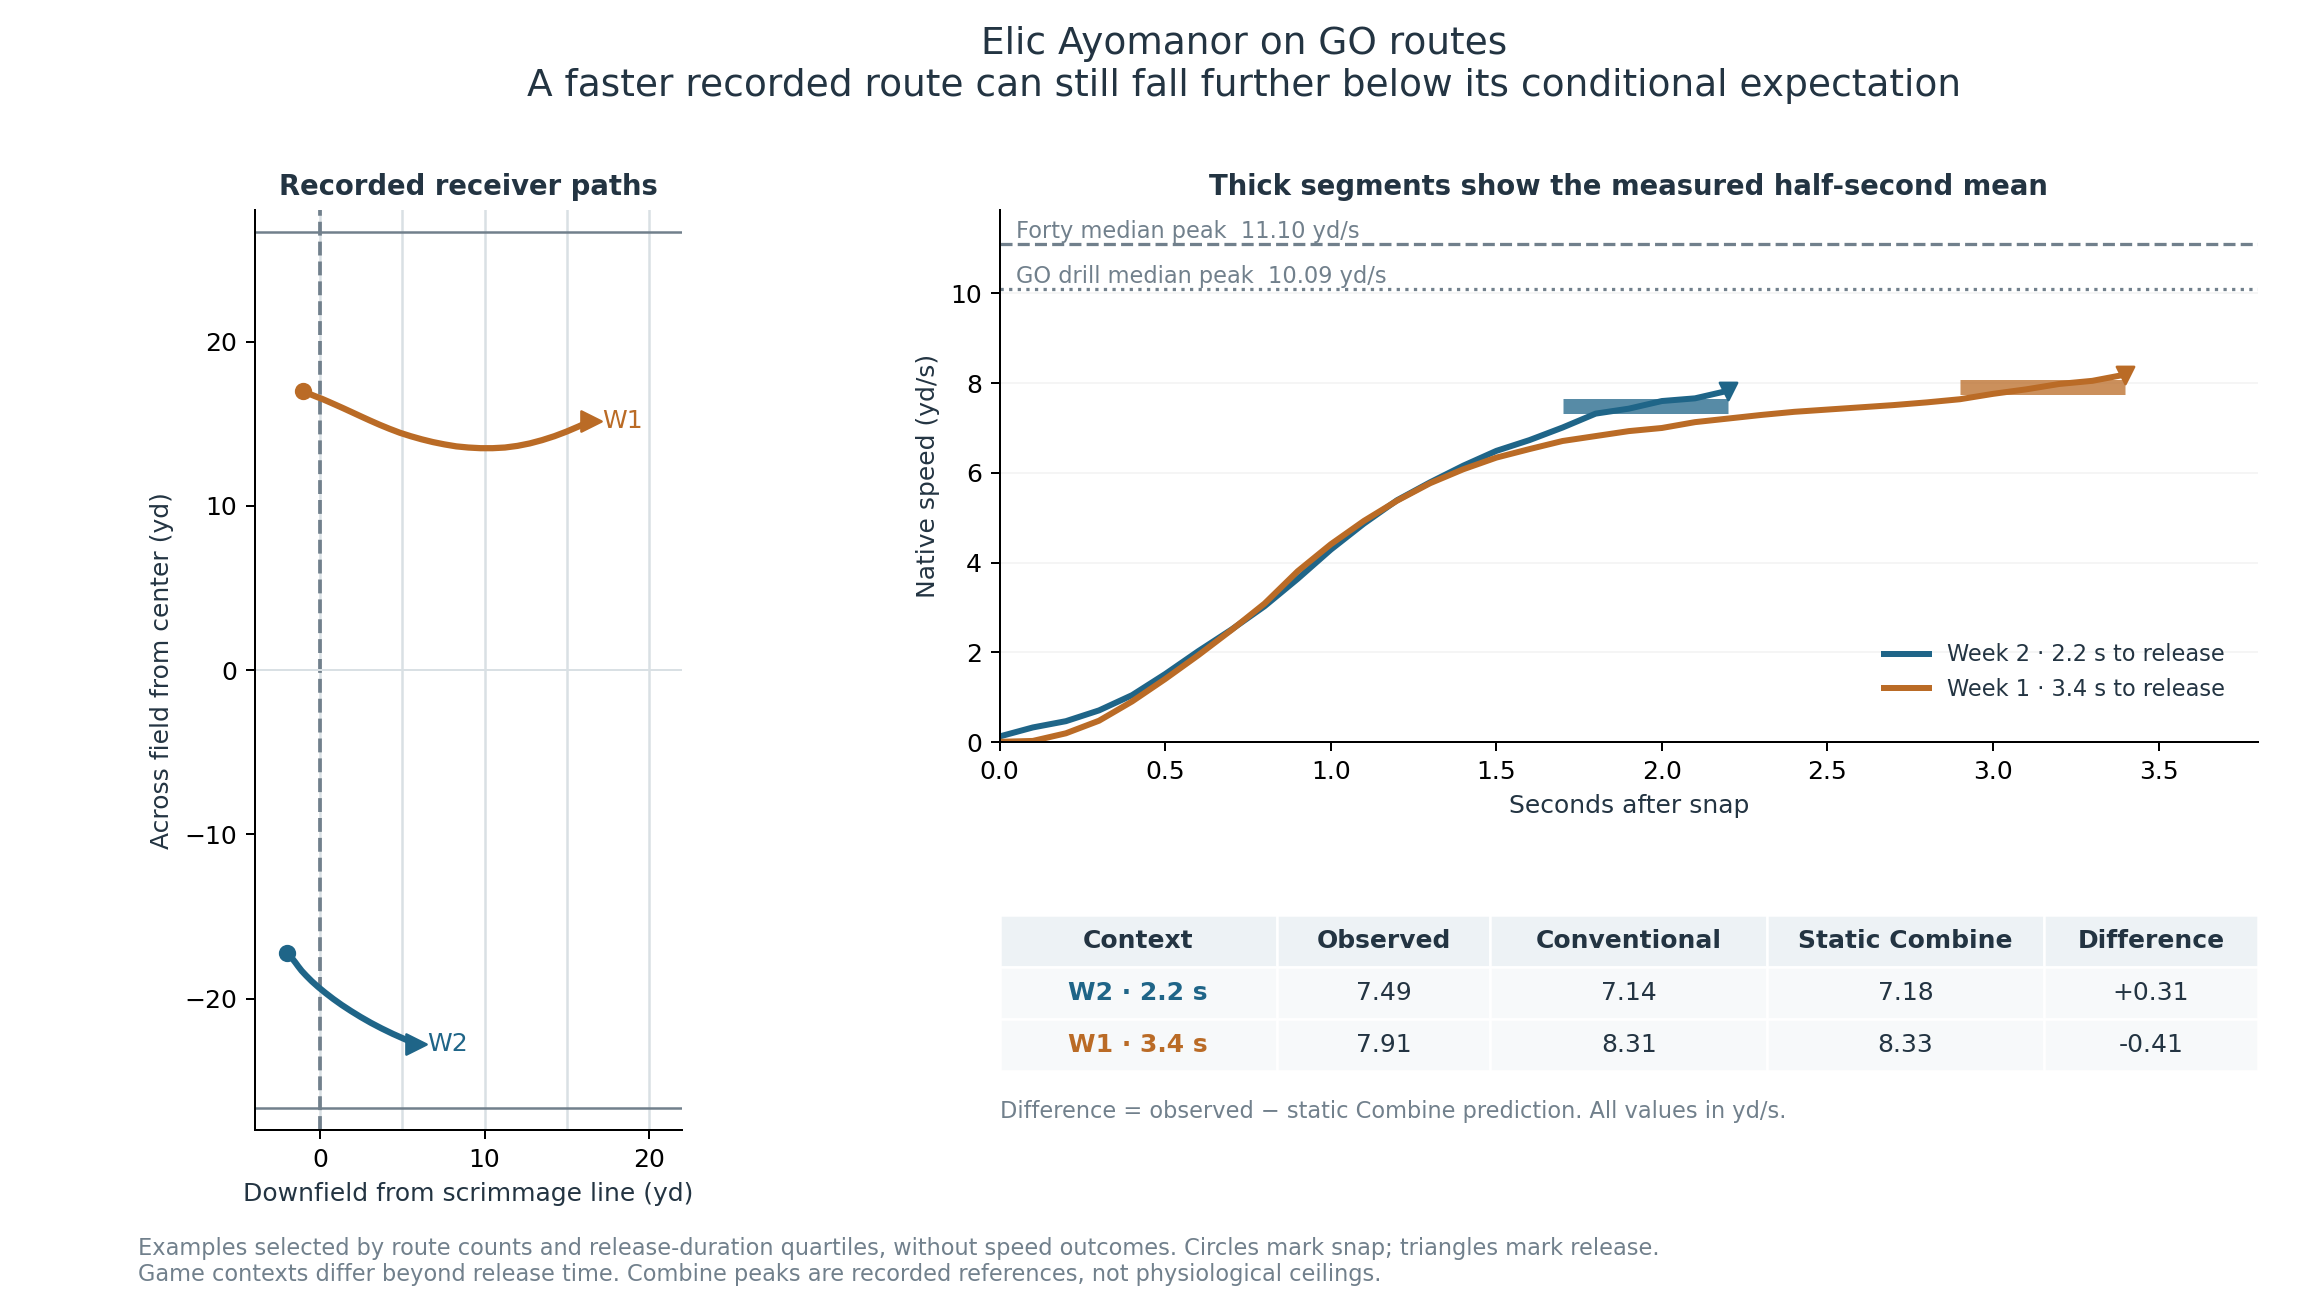

In [2]:
display(Image(filename=str(OUT / 'figures/route_examples.png')))

These plays differ beyond release time; their difference does not estimate the causal effect of more running time. Conventional predictions were already 7.14 and 8.31 yd/s, so Combine inputs provide a small refinement. Recorded drill peaks are references, not physiological ceilings that every route should reach.

## Separate predictive accuracy from the Combine increment

The conventional model includes official athletic tests, body measurements, draft information and college/athleticism scores. Football inputs include route, coverage, release duration, alignment, cushion, motion, down and distance, plus position and movement at the snap. The Combine model adds the two tracked peaks with nondecreasing constraints.

Five outer receiver folds and four inner folds keep each evaluated player out of population fitting and tuning. Inner validation selects histogram gradient boosting settings or an equal-weight ensemble of its three best candidates; the conventional pool also offers ridge models. Each receiver has equal evaluation weight. The conventional prediction supplies the fallback when both sensor measurements are unavailable.

For the weekly update, calculate each earlier qualifying game's mean observed-minus-static-predicted speed. Add their sum divided by their count plus a shrinkage strength. A game needs at least 10 supported routes to update history, and only **strictly earlier weeks in the same receiver-season** may contribute. All current-week outcomes remain excluded. Sparse games are still scored; gaps are not filled with zeros.

Within each outer training partition, select the strength from no update, 16, 8, 4, 2, 1 or 0 equivalent prior games using inner held-receiver forecasts. Both conventional and Combine pipelines receive this opportunity. Full-development inner predictions selected **2** for both final arms before calculating the new sequential 2025 results. Without qualifying history, predictions equal the static model exactly.

The static Combine gain is positive in all four partitions: **0.38%, 2.70%, 0.90% and 1.32%**. The additional weekly-update gains are **1.99%, 1.54%, 1.51% and 1.79%**. Losses are averaged within each receiver over repeats before averaging receivers; the sample remains 55 people. The update's aggregate MSE gain is **0.01554 yd²/s²**, with a descriptive fixed-prediction player-bootstrap interval of **[0.00814, 0.02384]**.

In the reused 2025 cohort, updating lowers Combine-model RMSE from **0.861 to 0.851 yd/s**, a **2.37% MSE reduction**. The improvement uses additional NFL observations and cannot be attributed solely to Combine tracking. Against the equally updated conventional pipeline, the Combine increment is **1.01%** in the development average and **1.49%** in 2025. It is uneven across partitions and history-coverage groups; the 2025 interval spans zero.

A separate chronological check makes every model and update choice from 2023 alone, then scores 27 different receivers on 4,503 routes in 2024. Updating reduces Combine-model MSE by **1.26%**; the Combine increment over the equally updated conventional model is **0.49%**, with an interval spanning zero. These receivers belong to the already analyzed development cohort, so this tests the time boundary without creating a new holdout.

## A stronger forecast can weaken the Combine claim

To test sensitivity to the small receiver sample, average **16 refits** with positive random weights assigned to entire training receivers. Conventional and Combine fits receive the same weights. Their selected settings, features and weekly shrinkage strengths stay fixed, and held receivers stay excluded. Ensemble size, weight draws and promotion rules were fixed before the new forecasts.

Averaging improves updated Combine accuracy in all four development partitions and both chronological checks: **1.14% lower MSE** in the development average and **2.44%** in 2025, where RMSE falls from **0.851 to 0.840 yd/s**. These are prediction gains from averaging, not additional sensor information.

Against the equally averaged conventional pipeline, however, the Combine increment is **0.26%** in development, **−0.51%** in the 2023-to-2024 check and **1.91%** in 2025. One development partition is also negative. Every corresponding aggregate/cohort descriptive interval includes zero. Thus the result does not support a stable, method-independent Combine benefit.

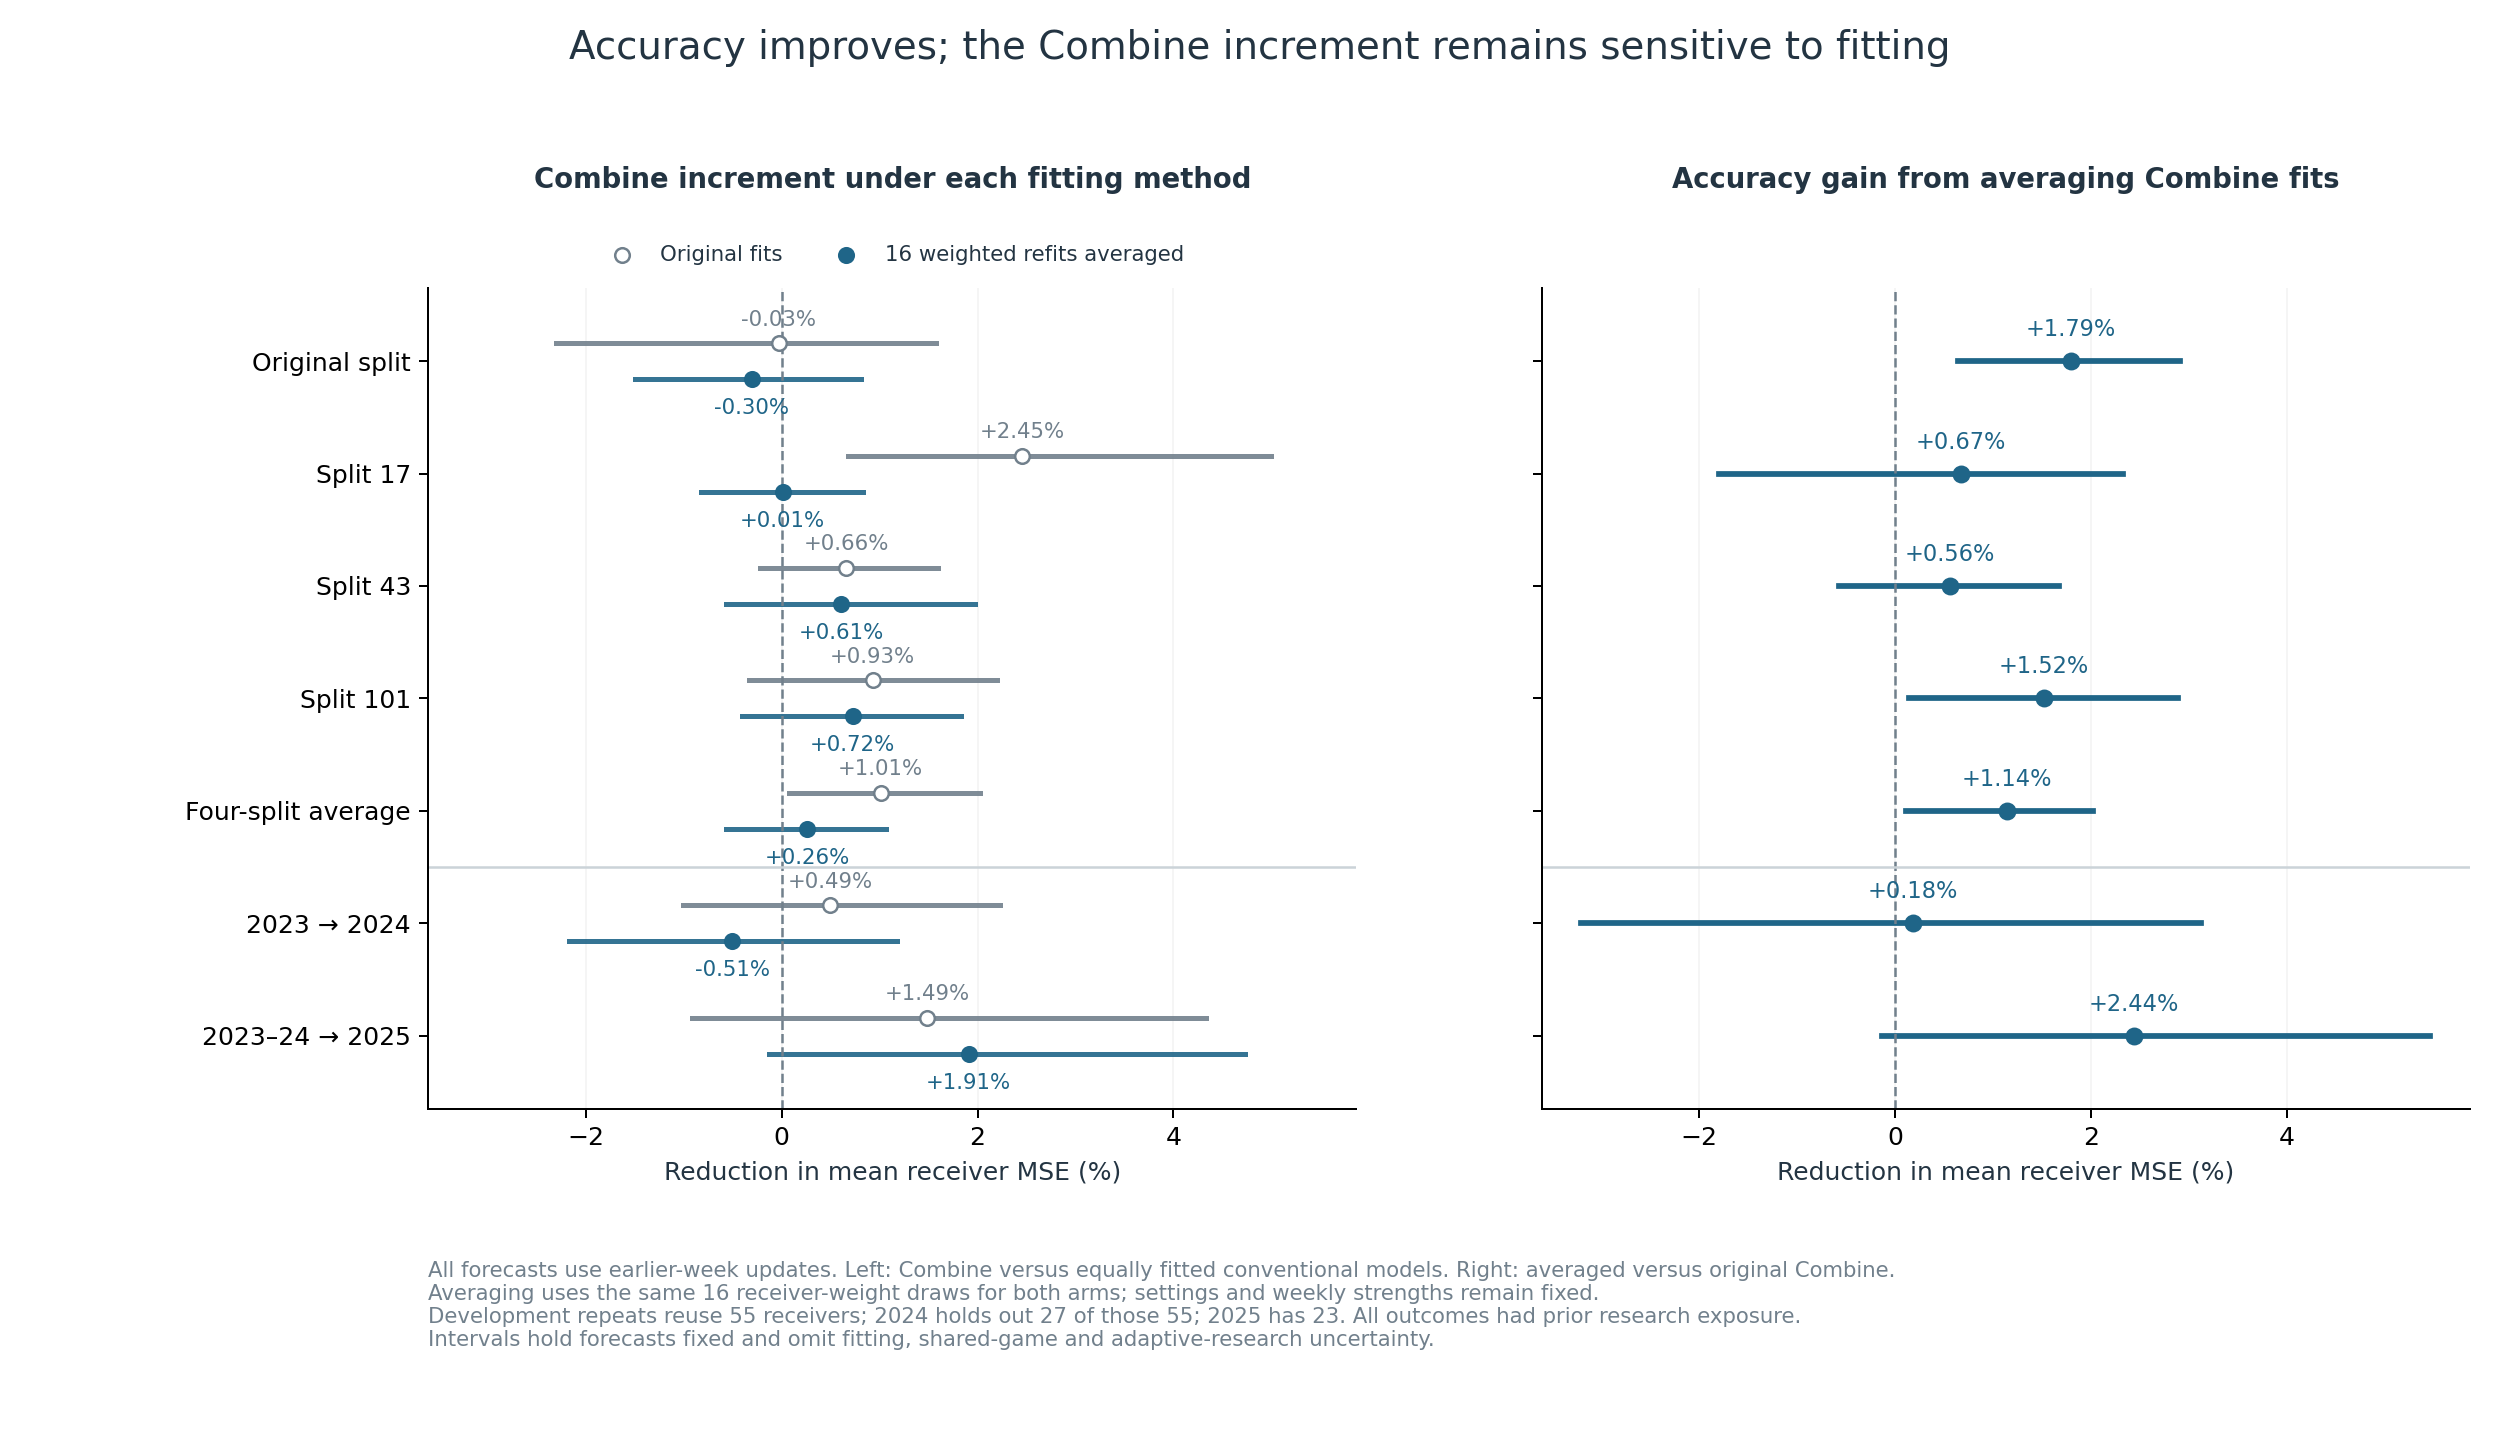

In [3]:
display(Image(filename=str(OUT / 'figures/combine_validation.png')))

The challenger failed the prespecified research-promotion requirement of a positive Combine increment in both chronological checks; it is retained with its accuracy improvement and negative result. The receiver examples below keep the original fixed model so their review changes remain attributable to earlier NFL history. This choice does not imply that the original model is the most accurate challenger.

## Preserve coverage and both expectations

For a receiver summary, average observed and predicted speeds within each qualifying game, then weight games equally. Require four qualifying games. Fifteen receivers have enough coverage, and eight remain explicitly sparse. Display them alphabetically rather than implying a talent ranking.

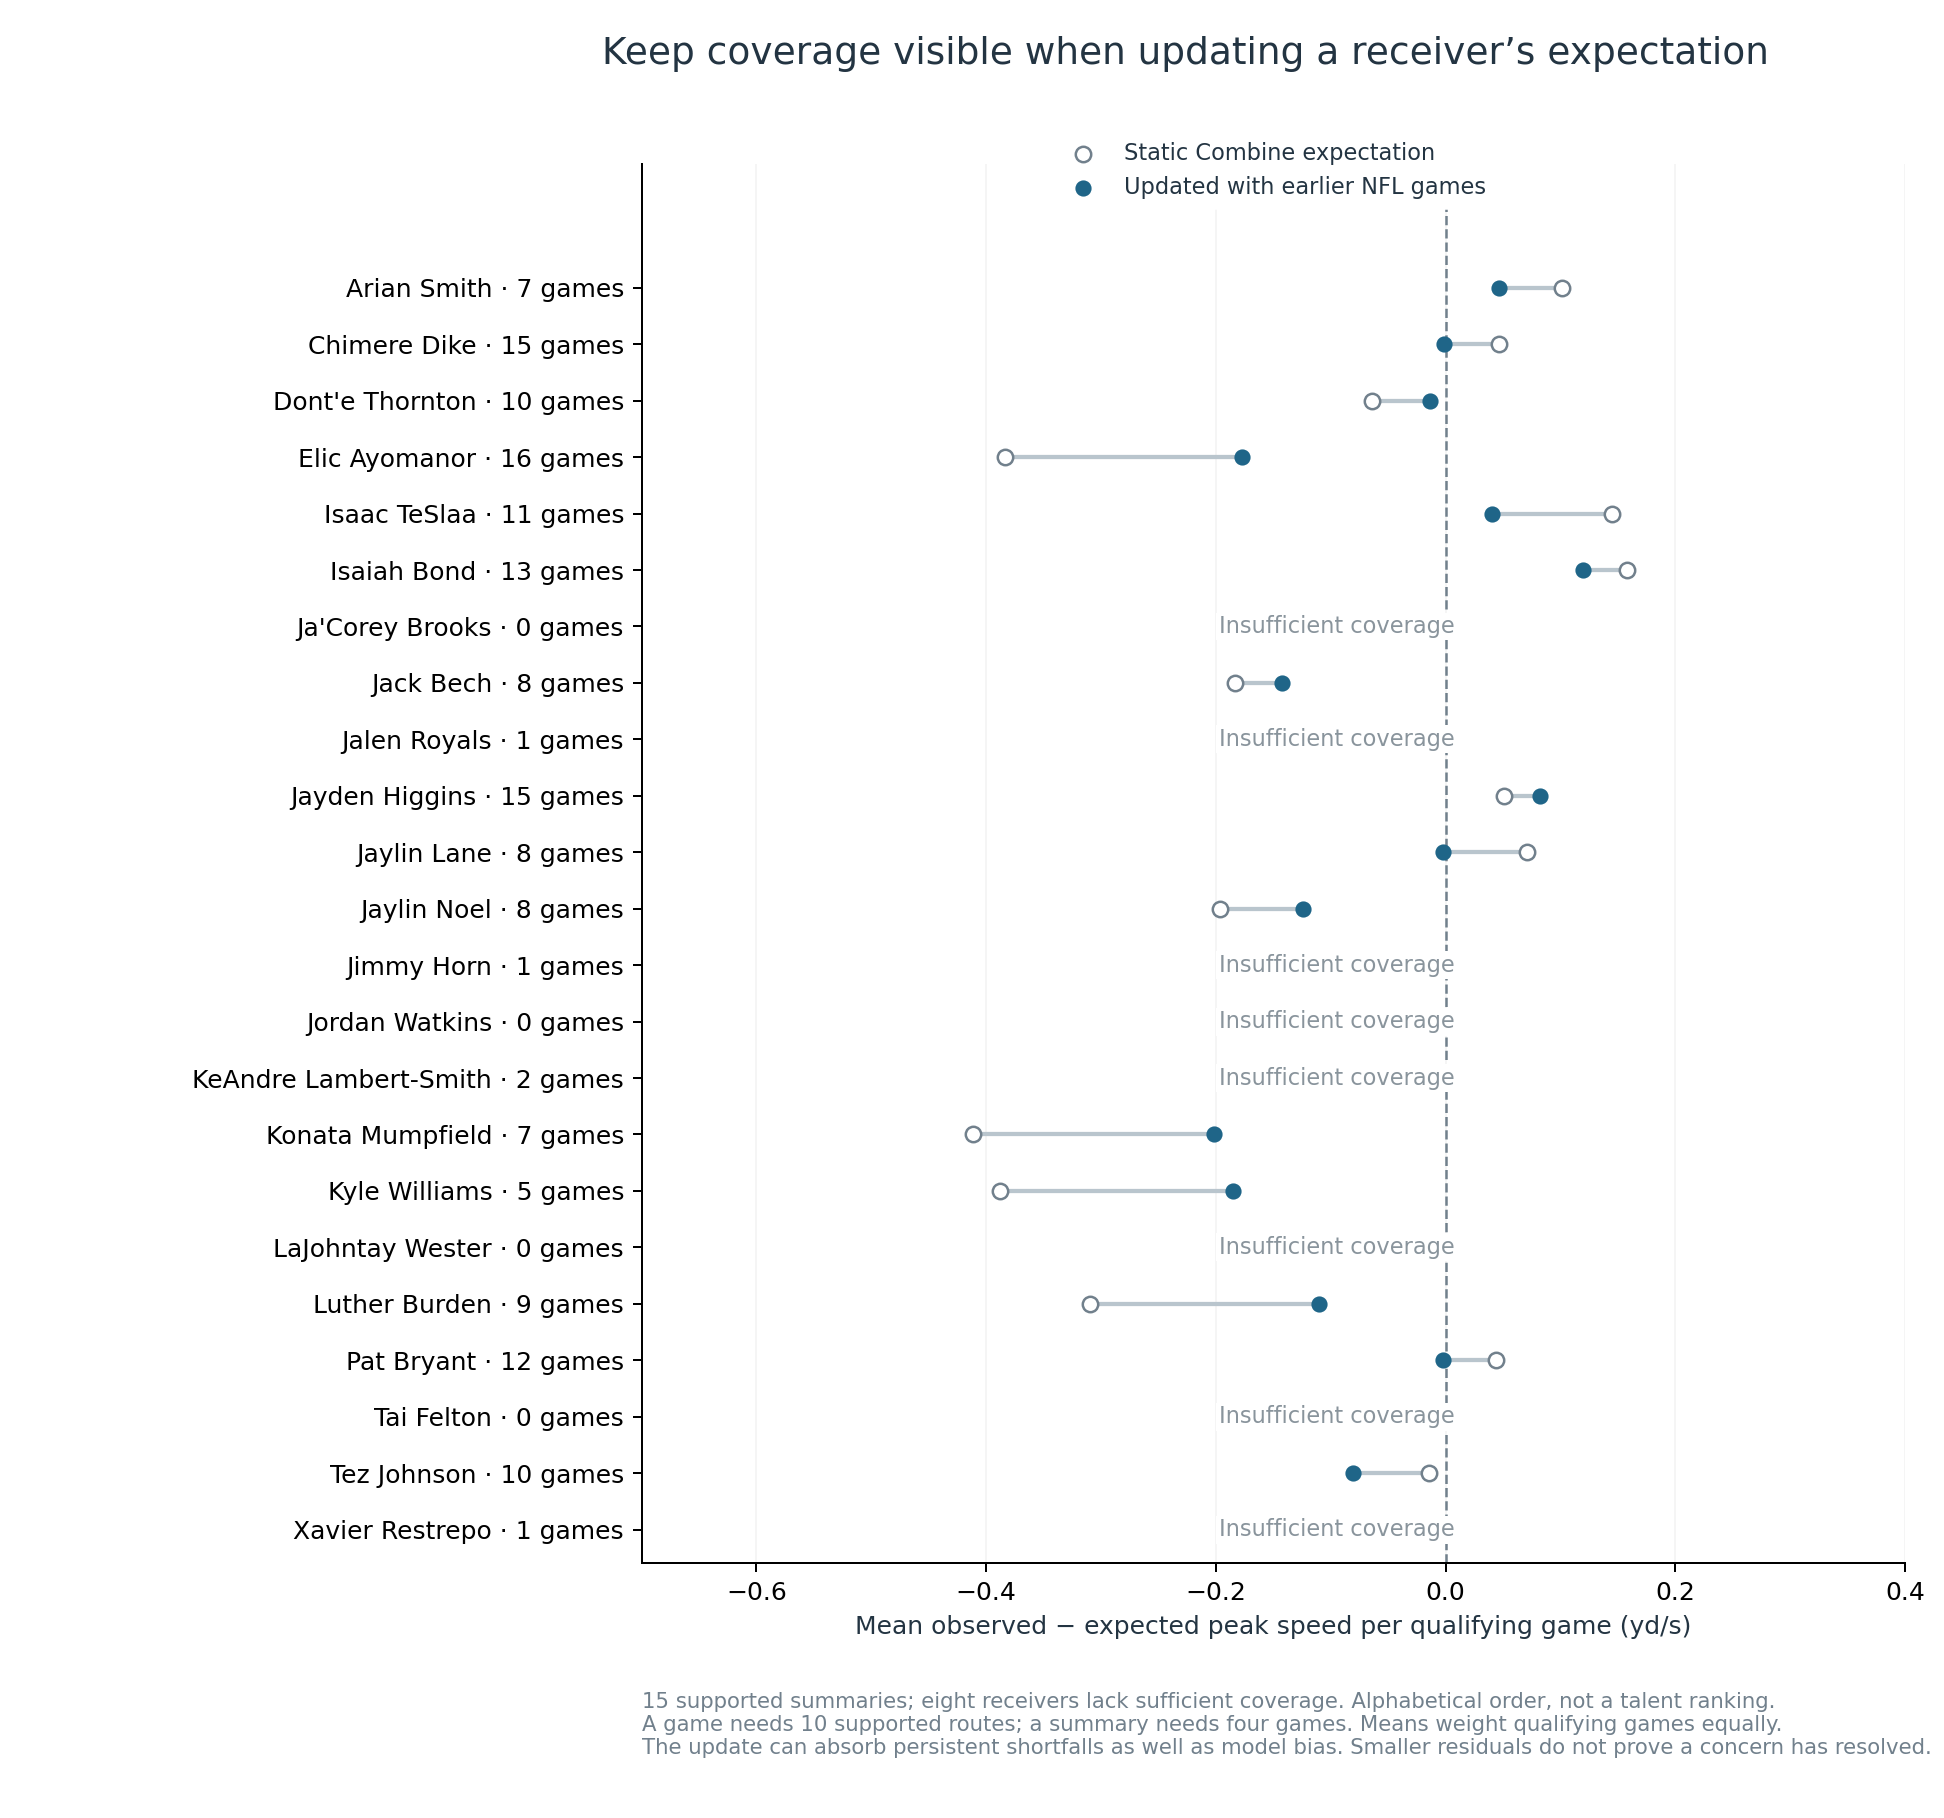

In [4]:
display(Image(filename=str(OUT / 'figures/receiver_review.png')))

The static view describes a receiver's persistent difference from the cohort model's contextual expectation. The updated view describes departure from an expectation informed by that receiver's earlier records. Updating can absorb persistent underperformance as well as model bias. A smaller residual does not prove that a concern has resolved.

## A changed expectation changes the review question

Apply the same illustrative rule to both views: examine the last three observed qualifying games; prompt review when their residuals all have the same sign and their mean magnitude reaches 0.5 yd/s. These can span calendar gaps. The threshold was fixed before this comparison and has not been validated as a detector of player quality.

Ayomanor's latest window covers weeks 16–18 and **73 routes**. Its static mean residual is **−0.66 yd/s**, meeting the below-expectation prompt. With the previous-week update, it is **−0.36 yd/s**, below that threshold's magnitude. The receiver and window were retained from the original example; they were not selected to make the update look favorable.

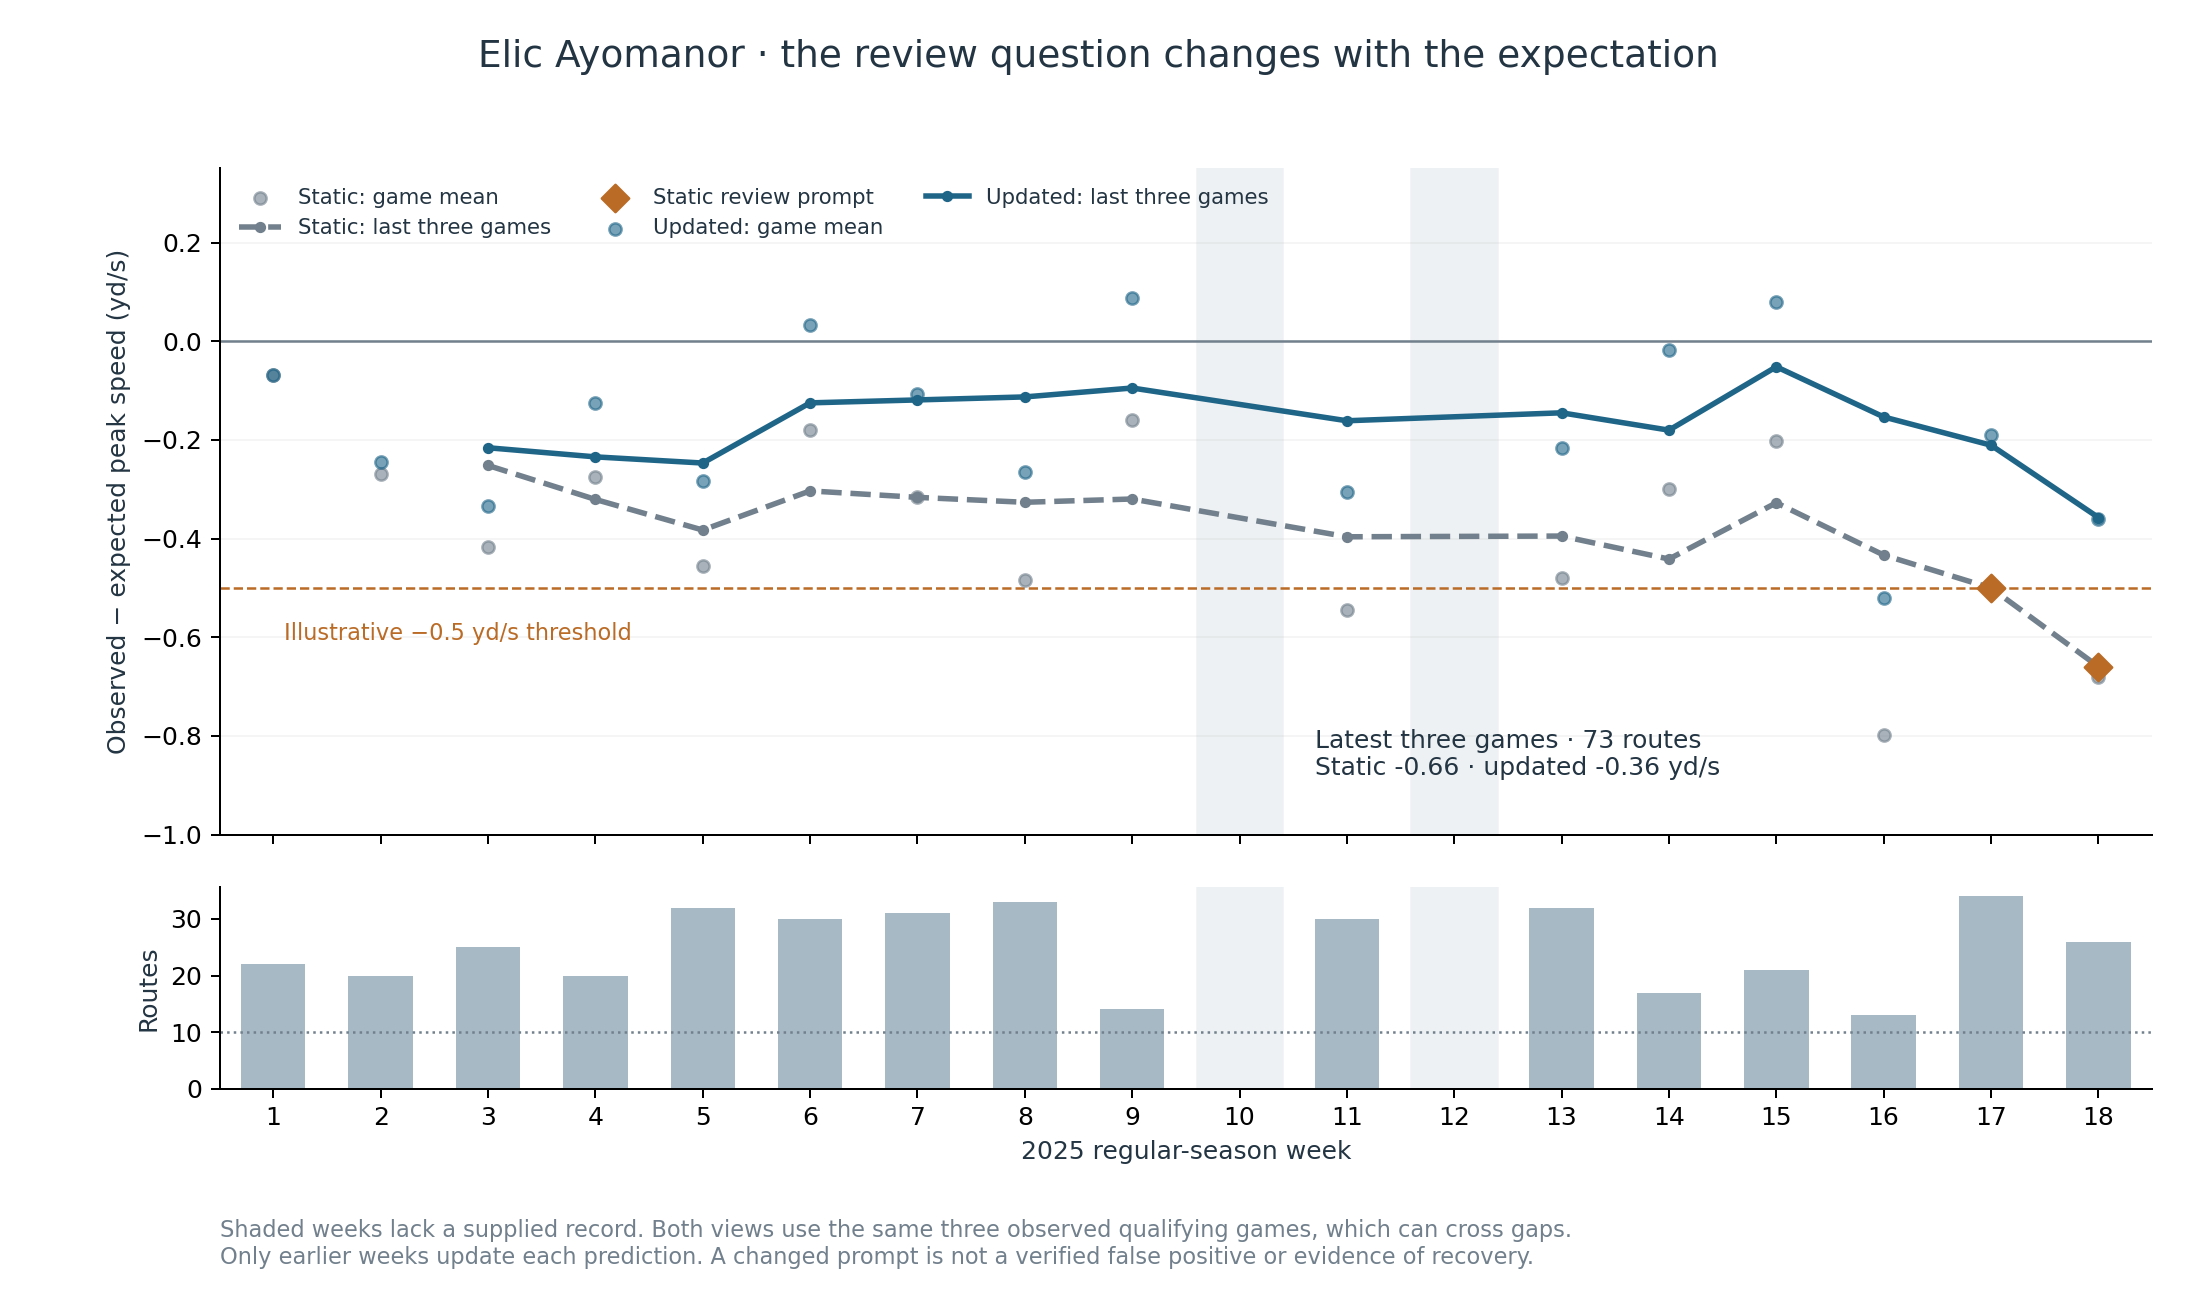

In [5]:
display(Image(filename=str(OUT / 'figures/weekly_review.png')))

Across all 23 latest windows, the static view has one below-expectation prompt, 14 mixed or smaller differences and eight with insufficient coverage. The updated view has 15 mixed or smaller differences and the same eight sparse cases. Across every eligible window, three prompts change and all other states remain unchanged. The complete latest comparison is retained in the appendix.

This is not evidence that the removed prompts were false positives. No independent film-review labels establish that. A coach can use the two views to distinguish a persistent mismatch with the cohort expectation from a newer departure from the receiver's recorded history, then inspect assignment, contact, release technique and tracking quality. Whether this improves decisions remains a question for prospective evaluation.

## What the evidence supports

The 2025 base models use only 2023–24 training players, and each weekly update uses only earlier weeks. Nevertheless, every cohort had prior research exposure. The development folds also use other receivers' later-season records, so they test held-receiver adaptation rather than reproduce real-time deployment. Bootstrap intervals hold predictions fixed and omit fitting, shared-game and adaptive-research uncertainty. Previous architecture and auxiliary-data experiments produced conflicting results; the primary-only base model was retained.

Charted route, coverage and pass-release duration make this a retrospective review. Draft information prevents a strictly pre-draft interpretation. Improved calibration and explicit coverage support further testing. The Combine increment is modest and sensitive to fitting; it does not establish overall talent, injury, causality or winning performance.

Data: [NFL Big Data Bowl 2027](https://www.kaggle.com/competitions/nfl-big-data-bowl-2027). The accompanying notebook reconstructs the official inputs, refits the fixed models and reproduces both review views. Publication and competition submission remain pending.

## Reproduction appendix

The notebook embeds extraction, training, calibration, validation and reporting source. It reads the attached official inputs, rebuilds both cohorts and refits the fixed final models. Current outcomes are excluded from static prediction; only strictly earlier weeks can inform each update.

The default run uses preserved aggregate validation results and fixed final choices. Set `REPEAT_VALIDATION = True` to rerun the original nested comparisons, full-development calibration selection and chronological comparison. Separately, `REPEAT_AVERAGING = True` refits all 22 averaging comparisons from reconstructed inputs using the published fixed configurations; it does not reselect them. Both options reproduce previously analyzed data. A first run may need Internet access for the pinned training environment.

The table retains all 23 modeled receivers, including sparse cases. Only source, aggregate results and four analysis figures are saved as notebook output files. Row-level features, forecasts and traces are removed with the temporary working directory after these displays.


In [6]:
print(f"Rebuilt {receipt['development_plays']:,} development routes and {receipt['assessment_plays']:,} assessment routes from official files.")
print('Fixed final models refitted:', receipt['final_models_refitted'])
print('Nested validation and final calibration selection repeated:', REPEAT_VALIDATION)
print('Fixed averaging comparisons refitted:', REPEAT_AVERAGING)
print('This reproduces previously analyzed data; it is not new validation evidence.')


Rebuilt 10,626 development routes and 3,690 assessment routes from official files.
Fixed final models refitted: True
Nested validation and final calibration selection repeated: False
Fixed averaging comparisons refitted: False
This reproduces previously analyzed data; it is not new validation evidence.


In [7]:
latest = pd.read_csv(OUT / 'latest_comparison.csv').sort_values('display_name')
assert len(latest) == 23
view = latest[['display_name','recorded_weeks','window_plays','static_residual','updated_residual','updated_prompt']].copy()
view.columns = ['Receiver','Weeks','Routes','Static gap (yd/s)','Updated gap (yd/s)','Updated review']
display(view.round({'Static gap (yd/s)':3,'Updated gap (yd/s)':3}).set_index('Receiver'))


,Weeks,Routes,Static gap (yd/s),Updated gap (yd/s),Updated review
Receiver,,,,,
Arian Smith,"[6, 7, 8]",54,0.082,0.004,mixed or smaller difference
Chimere Dike,"[16, 17, 18]",70,0.021,-0.018,mixed or smaller difference
Dont'e Thornton,"[11, 12, 17]",47,0.019,0.070,mixed or smaller difference
Elic Ayomanor,"[16, 17, 18]",73,-0.660,-0.357,mixed or smaller difference
Isaac TeSlaa,"[16, 17, 18]",76,0.116,-0.012,mixed or smaller difference
Isaiah Bond,"[15, 16, 18]",57,0.354,0.273,mixed or smaller difference
Ja'Corey Brooks,[],0,NaN,NaN,insufficient coverage
Jack Bech,"[15, 16, 18]",49,-0.276,-0.142,mixed or smaller difference
Jalen Royals,[18],22,NaN,NaN,insufficient coverage


In [8]:
assert receipt['review']['latest_prompt_counts']['updated'] == latest.updated_prompt.value_counts().to_dict()
assert receipt['review']['latest_prompt_counts']['static'] == latest.static_prompt.value_counts().to_dict()
PUBLIC = Path(os.environ.get('NFL_PUBLIC_OUTPUT_ROOT','/kaggle/working' if Path('/kaggle/working').exists() else '.')).resolve()
PUBLIC.mkdir(parents=True,exist_ok=True)
for name,text in SOURCE_FILES.items():
    destination = PUBLIC/'entry_source'/name
    destination.parent.mkdir(parents=True,exist_ok=True)
    destination.write_text(text)
(PUBLIC/'figures').mkdir(exist_ok=True)
for name in ['route_examples.png','combine_validation.png','receiver_review.png','weekly_review.png']:
    shutil.copy2(OUT/'figures'/name,PUBLIC/'figures'/name)
(PUBLIC/'RUN_SUMMARY.json').write_text(json.dumps(receipt,indent=2)+'\n')
temporary.cleanup()
assert not PRIVATE.exists()
print('Report complete. Retained files contain source, aggregate results and four analysis figures.')


Report complete. Retained files contain source, aggregate results and four analysis figures.
